Audio Evidence Authentication and Cross-Device Splicing Detection via Distance
Metric Learning on Unvoiced Speech Segments.

Implementation of a software prototype for audio evidence authentication through
cross-device splicing detection from unvoiced speech segments under controlled
acoustic conditions, based on a Siamese Neural Network distance metric learning model.


In [ ]:
# %% ─────────────────────────────────────────────────────────────────────────
# CELL 1 — Install dependencies not preinstalled in Colab
# ──────────────────────────────────────────────────────────────────────────
#
!pip install pytorch-metric-learning torcheval thop -q
!pip install joblib -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.8/127.8 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.2/179.2 kB 18.4 MB/s eta 0:00:00


In [ ]:
"""Audio Evidence Authentication and Cross-Device Splice Detection via Distance
Metric Learning on Unvoiced Speech Segments.
Implement a software prototype for audio evidence authentication through
cross-device splice detection from unvoiced speech segments under controlled
acoustic conditions, based on a distance metric learning model built on a
Siamese Neural Network.

"""
# %% ─────────────────────────────────────────────────────────────────────────
# CELL 2 — Mount Google Drive
# ──────────────────────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')#,force_remount=True)


# %% ─────────────────────────────────────────────────────────────────────────
# Load training.py and eer_evaluation.py
# ──────────────────────────────────────────────────────────────────────────
import sys
sys.path.append('/content/drive/MyDrive/AudioAuthentication')

#sys.path.append('/content')  # in case the loose .py files were uploaded to the files panel

Mounted at /content/drive


In [ ]:
# Libraries
import librosa

import os
import random
import numpy as np
import json
from IPython.display import Audio, display
import librosa.display
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import soundfile as sf
import seaborn as sns
import torch
import torchaudio
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn
from training import Trainer  # The Trainer class
from pytorch_metric_learning import losses, miners
from pytorch_metric_learning.samplers import MPerClassSampler
from pytorch_metric_learning.distances import LpDistance, CosineSimilarity, SNRDistance
import matplotlib.gridspec as gridspec
from datetime import datetime
from sklearn.manifold import TSNE
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, cross_val_predict,
    StratifiedGroupKFold,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from eer_evaluation import (      # The EER module
    evaluate_eer_complete, evaluate_noise_robustness, save_eer_results,
    save_complete_experiment, generate_simple_splicing, entropy_weighted_localization,
    _apply_median_filter, _local_distance_entropy, estimate_mahalanobis_vi, _pairwise_distance,
    evaluate_ia_splicing_complete,save_ia_splicing_results,calculate_eer, calculate_far_frr_at_threshold, LOCALIZATION_STRATEGY_KEYS,
)
from google.colab import files
import pickle
import hashlib
from pathlib import Path
import eer_evaluation as eer_evaluation_module
import math
from joblib import Parallel, delayed
import json
import gc
from thop import profile, clever_format
import pandas as pd
from collections import Counter


In [ ]:

# 1. Initialize a basic clone filtering the files so nothing downloads initially
!git clone --depth 1 --filter=blob:none --sparse https://github.com/DanielMorelos/BasededatosAutenticaciondeAudios.git /content/BasededatosAutenticaciondeAudios

# 2. Enter the repository folder, define the only folder we care about, and go back
%cd /content/BasededatosAutenticaciondeAudios
!git sparse-checkout set original_recordings ia_splicing_audio ia_pure_audio
%cd /content


Cloning into '/content/BasededatosAutenticaciondeAudios'...
remote: Enumerating objects: 373, done.
remote: Counting objects: 100% (373/373), done.
remote: Compressing objects: 100% (364/364), done.
remote: Total 373 (delta 10), reused 355 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (373/373), 227.69 KiB | 20.70 MiB/s, done.
Resolving deltas: 100% (10/10), done.
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 1 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (1/1), 76 bytes | 76.00 KiB/s, done.
/content/BasededatosAutenticaciondeAudios
remote: Enumerating objects: 6809, done.
remote: Counting objects: 100% (6809/6809), done.
remote: Compressing objects: 100% (6556/6556), done.
remote: Total 6809 (delta 294), reused 6751 (delta 253), pack-reused 0 (from 0)
Receiving objects: 100% (6809/6809), 6.92 GiB | 31.78 MiB/s, done.
Resolving deltas: 100% (294/294), done.
Updating files: 100% (6825/6825), d

In [ ]:
device_to_label = {
    "huawei_nova_9": 0,
    "huawei_nova_9_se": 1,
    "huawei_p30": 2,
    "iphone_12_mini": 3,
    "iphone_13": 4,
    "iphone_xs_max": 5,
    "moto_edge_20": 6,
    "moto_edge_30": 7,
    "moto_g9_power": 8,
    "oneplus_nord": 9,
    "poco_m4_pro": 10,
    "poco_x4_pro": 11,
    "realme_gt": 12,
    "redmagic": 13,
    "redmi_note_11": 14,
    "rog_phone_3": 15,
    "rog_phone_5": 16,
    "xiaomi_12": 17,
    "xiaomi_12_pro": 18,
    "xiaomi_12_x": 19,
}

In [ ]:

# Load and save paths
base_path = "/content/BasededatosAutenticaciondeAudios"
#normalized_16k_path = os.path.join(base_path, "normalized_data_16k")
original_recordings_path = os.path.join(base_path, "original_recordings")
# Separate path to SAVE results (trained model, PDFs). Since the data no
# longer lives on Drive, this is kept separate from base_path; use Drive if
# you mounted it in Cell 2b, or "/content" if you prefer to only download
# at the end.
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
os.makedirs(output_path, exist_ok=True)

unvoiced_fragment_cache_dir = os.path.join(output_path, "unvoiced_fragment_cache")
os.makedirs(unvoiced_fragment_cache_dir, exist_ok=True)
unvoiced_listening_samples_dir = os.path.join(output_path, "unvoiced_listening_samples")
os.makedirs(unvoiced_listening_samples_dir, exist_ok=True)
# Pure IA-generated segments (no splice) — audio-level genuine counterpart
# for the IA-splicing evaluation set.
ia_pure_set_source_path = os.path.join(base_path, "ia_pure_audio")
ia_pure_set_dataset_path = os.path.join(output_path, "ia_pure_set_dataset.pkl")

raw_split_path = os.path.join(output_path, "raw_split.pkl")
windowed_dataset_path = os.path.join(output_path, "final_training_dataset.pkl")
eval_windows_path = os.path.join(output_path, "eval_windows_knn.pkl")
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"  # change on every version you want to compare
eval_run_name = f"{run_name}_40_nm_medf3_entw10"
kfold_results_path = os.path.join(output_path, f"kfold_results_{run_name}.pkl")
final_history_path = os.path.join(output_path, f"final_model_history_{run_name}.pkl")
final_checkpoint_path = os.path.join(output_path, f"final_checkpoint_{run_name}.pt")
final_holdout_windows_path = os.path.join(output_path, f"final_holdout_windows_{run_name}.pkl")
final_best_checkpoint_path = os.path.join(output_path, f"final_best_checkpoint_{run_name}.pt")
tsne_png_path = os.path.join(output_path, f"tsne_{run_name}.png")
kfold_train_loss_stats_png_path = os.path.join(output_path, f"kfold_train_loss_stats_{run_name}.png")
kfold_knn_accuracy_stats_png_path = os.path.join(output_path, f"kfold_knn_accuracy_stats_{run_name}.png")
save_path = os.path.join(output_path, f"siamese_model_{run_name}.pth")
pdf_path = os.path.join(output_path, f"forensic_report_{run_name}.pdf")
filtering_comparison_png_path = os.path.join(output_path, f"filtering_comparison_{run_name}.png")
# Domain of the reference embeddings used to fit the k-NN and the Mahalanobis VI.
# True  -> full-audio windows of raw_train_audios (same domain as val/calibration/test)
# False -> unvoiced-fragment windows (same domain as the training set)
REFERENCE_EMBEDDINGS_USE_FULL_AUDIO = True
REFERENCE_DOMAIN_TAG = "fullaudio" if REFERENCE_EMBEDDINGS_USE_FULL_AUDIO else "unvoiced"

full_audio_train_windows_path = os.path.join(output_path, "full_audio_train_windows.pkl")
mahalanobis_vi_path = os.path.join(output_path, f"mahalanobis_vi_{REFERENCE_DOMAIN_TAG}_{run_name}.pkl")
lr_tippett_png_path = os.path.join(output_path, f"tippett_lr_{eval_run_name}.png")
lr_results_pkl_path = os.path.join(output_path, f"lr_results_{eval_run_name}.pkl")
bootstrap_results_path = os.path.join(output_path, f"bootstrap_ci_{eval_run_name}.pkl")
pairwise_calibration_png_path = os.path.join(output_path, f"pairwise_calibration_{eval_run_name}.png")

frequency_ablation_results_path = os.path.join(output_path, f"frequency_band_ablation_{run_name}.pkl")
frequency_ablation_png_path = os.path.join(output_path, f"frequency_band_ablation_{run_name}.png")
# Segment-type ablation
segment_category_cache_dir = os.path.join(output_path, "segment_category_cache")
os.makedirs(segment_category_cache_dir, exist_ok=True)
segment_ablation_results_path = os.path.join(output_path, f"segment_type_ablation_{run_name}.pkl")
segment_ablation_png_path = os.path.join(output_path, f"segment_type_ablation_{run_name}.png")
# IA-Splicing evaluation set
ia_splicing_source_path = os.path.join(base_path, "ia_splicing_audio")
ia_splicing_dataset_path = os.path.join(output_path, "ia_splicing_dataset.pkl")
ia_splicing_history_csv = "ia_splicing_history.csv"

test_unvoiced_windows_path = os.path.join(output_path, "eval_windows_unvoiced_test.pkl")
# Cross-corpus generalization set — devices never seen in train/val/test
unseen_devices_repo_path   = "/content/AudioDataset"
unseen_devices_dataset_path = os.path.join(output_path, "unseen_devices_dataset.pkl")
bootstrap_results_summary_path = os.path.join(output_path, f"bootstrap_summary_{eval_run_name}.json")
# devices to load
devices = list(device_to_label.keys())
audio_dataset = []
id_to_device = {v: k for k, v in device_to_label.items()}

h1_peak_diagnostic_png_path = os.path.join(output_path, f"h1_peak_transition_diagnostic_{eval_run_name}.png")
strategy_eer_results_path = os.path.join(output_path, f"audio_score_strategy_eer_{eval_run_name}.pkl")
strategy_eer_png_template = os.path.join(
    output_path, "audio_score_strategy_eer_{distance_metric}_" + eval_run_name + ".png"
)
strategy_eer_summary_csv_path = os.path.join(output_path, f"audio_score_strategy_eer_summary_{eval_run_name}.csv")

In [ ]:

# ══════════════════════════════════════════════════════════════
# GLOBAL CONFIGURATION — everything adjustable
# ══════════════════════════════════════════════════════════════

SR = 44100                    # sample rate of recordings
OUT_DIM = 64
EPOCHS = 60
EPOCHS_KFOLD = 8
LR = 0.001
N_SPLITS = 3
RANDOM_SEED = 42
KFOLD_STRATIFY_KEYS = ["device", "condition"]

# Windowing
WIN_LENGTH_SEC = 1.0
HOP_LENGTH_SEC_TRAIN = WIN_LENGTH_SEC   # no overlap: independent windows for metric learning
HOP_LENGTH_SEC_EVAL = 0.25              # with overlap: higher temporal resolution to locate the splice

# Spectral extraction (FFT)
N_FFT = 2048
HOP_LENGTH_FFT = 2048           # different from the windowing hop
STFT_WINDOW_TYPE = 'hann'       # analysis window applied to each STFT frame
LOG_POWER_EPSILON = 1e-10       # numerical floor to avoid log10(0)

# Splicing
TOP_DB = 30                    # sensitivity for detecting silence/speech

# Unvoiced-segment selection (restrict window generation to unvoiced, non-silent content)
# Unvoiced-fragment windowing (train/val only; test windows always use the full audio)
TRAIN_VAL_UNVOICED_FRAGMENTS_ENABLED = True   # master switch for fragment-based train/val windowing
# Minimum fragment duration required so that, after the two MaxPool2d(2) layers
# in Backbone (each floor-dividing the time axis by 2), at least 1 valid time
# frame survives at the pooling stage — i.e. STFT frame count T_stft >= 4, given
# T_stft = floor(n_samples / HOP_LENGTH_FFT) + 1 (librosa.stft, center=True).
# Below this, MaskedPooling's mask degenerates to all-zero and the resulting
# embedding carries no real signal even with the safety clamp in
# compute_backbone_output_time_length. Derived from HOP_LENGTH_FFT/SR instead
# of hardcoded, so it stays correct if either changes.
BACKBONE_POOL_CEIL_MODE = True
_MIN_BACKBONE_SURVIVABLE_STFT_FRAMES = 1 if BACKBONE_POOL_CEIL_MODE else 4
_MIN_STFT_CENTER_PAD_SAMPLES = N_FFT // 2 + 1   # librosa center=True reflect-pad requirement

UNVOICED_FRAGMENT_MIN_SEC = max(
    (_MIN_BACKBONE_SURVIVABLE_STFT_FRAMES - 1) * HOP_LENGTH_FFT,
    _MIN_STFT_CENTER_PAD_SAMPLES,
) / SR
UNVOICED_FRAGMENT_PAD_MODE = "reflect"        # np.pad mode for fragments shorter than WIN_LENGTH_SEC ("reflect" | "wrap")
UNVOICED_FRAGMENT_PAD_TO_WINDOW_ENABLED = False  # False = keep each fragment/chunk at its natural duration (no padding to WIN_LENGTH_SEC); True = restore the old pad-to-WIN_LENGTH_SEC behavior
UNVOICED_FMIN_HZ = librosa.note_to_hz('C2')   # lower bound of the f0 search range for voicing detection
UNVOICED_FMAX_HZ = librosa.note_to_hz('C6')   # upper bound of the f0 search range for voicing detection
UNVOICED_FRAME_LENGTH = 1024                 # pyin analysis frame length, in samples
UNVOICED_HOP_LENGTH = 128                     # pyin analysis hop length, in samples
UNVOICED_FRAGMENT_COLLATE_PAD_VALUE = 0.0

UNVOICED_ANALYSIS_SR = 16000  # pyin analysis SR; downsampled independently of SR to cut voicing-detection cost
UNVOICED_INCLUDE_SILENCE_NOISE_ENABLED = True   # True = also keep noise-only regions (below TOP_DB) that pyin flags as non-voiced; False = legacy behavior (unvoiced AND non-silent)
UNVOICED_DIGITAL_SILENCE_FILTER_ENABLED = True   # True = drop frames whose RMS is below the floor (digital zeros / near-zero padding) even when noise-only regions are included
UNVOICED_DIGITAL_SILENCE_FLOOR_DBFS = -80.0      # RMS floor in dBFS (full-scale = 0 dBFS); digital zero maps to about -200 dBFS, real mic noise floors sit well above this
TAKE_ALIGNMENT_MAX_LAG_SEC = 0.5   # search window for cross-device take-alignment diagnostic
UNVOICED_CACHE_WARMUP_N_JOBS = -1   # joblib n_jobs for unvoiced-fragment cache warm-up (-1 = all cores)
UNVOICED_SHARED_TAKE_REFERENCE_MODE = "first"   # "first" = use the first device encountered per take as the fragment-mask reference
# Concatenated unvoiced windowing: joins every unvoiced/background-noise fragment of an
# audio into one continuous signal, then cuts it into fixed-length training windows.
UNVOICED_CONCATENATION_ENABLED = True               # False = legacy per-fragment windowing
UNVOICED_CONCATENATED_KEEP_TRAILING_REMAINDER = False  # True = keep the last incomplete window if >= UNVOICED_FRAGMENT_MIN_SEC
UNVOICED_MERGE_SHORT_FRAGMENTS_ENABLED = False   # False = drop fragments shorter than UNVOICED_FRAGMENT_MIN_SEC instead of bridging the voiced gap between them
UNVOICED_VOICED_GUARD_MARGIN_SEC = 0.01          # safety margin (s) excluded around every voiced frame; absorbs pyin boundary jitter and small cross-device misalignment
UNVOICED_EXTRACTION_ALGORITHM_VERSION = 2        # bump whenever the fragment-extraction logic changes, to invalidate stale caches
UNVOICED_LISTENING_GAP_SEC = 0.05   # silence inserted between concatenated fragments, for audibility only

# Dataset per device
NUM_PER_DEVICE = None       # None = use all available
MIN_VIABLE = 3

# Train/val/test splits
TEST_SIZE = 0.3                # 70% train, 30% remainder
VAL_SIZE = 0.5                # of the remainder: 50% val / 50% test

FEATURE_DTYPE = np.float32   # dtype of the cached spectrograms
# Validation windowing mode. When True, validation windows are built from the
# full audio (same path as test), while training windows keep using unvoiced
# fragments. When False, validation mirrors the training windowing.
VALIDATION_USE_FULL_AUDIO = True
# Metric training
BATCH_SIZE = 128
TRIPLET_MARGIN = 0.2           # the one actually used (the old MARGIN=1.0 wasn't being used)
KNN_NEIGHBORS = 5
TRAIN_MINER_TYPE = "semihard"
EVAL_MINER_TYPE = "semihard"

DROPOUT_CONV = 0.1
DROPOUT_FC = 0.1
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0
LR_SCHEDULER_FACTOR = 0.5
LR_SCHEDULER_PATIENCE = 3
LR_SCHEDULER_THRESHOLD = 1e-4
LR_SCHEDULER_THRESHOLD_MODE = 'rel'   # 'rel' or 'abs'
LR_SCHEDULER_COOLDOWN = 0
LR_SCHEDULER_MIN_LR = 1e-6
EARLY_STOPPING_PATIENCE = 15
EARLY_STOPPING_MIN_DELTA = 1e-4
# Temporal/spatial pooling before the Neck
POOLING_TYPE = "gap"          # "gap" (baseline) | "statistical" (mean + std)
POOLING_STD_EPSILON = 1e-5            # numerical floor inside sqrt(var + eps); avoids NaN gradients when var -> 0
BACKBONE_OUT_CHANNELS = 256           # must match the last Conv2d of Backbone

# Final-model validation holdout (audio-level, stratified by KFOLD_STRATIFY_KEYS).
# Set to False to revert to training the final model on 100% of raw_train_audios.
FINAL_MODEL_USE_VALIDATION_HOLDOUT = True
FINAL_MODEL_VALIDATION_FRACTION = 0.15   # fraction of raw_train_audios (not of the full corpus)
# Training objective
TRAIN_LOSS_TYPE = "cosface"          # "triplet" | "arcface" | "cosface"

# CosFace (only used when TRAIN_LOSS_TYPE == "cosface")
COSFACE_MARGIN = 0.2                # margin in COSINE units (not degrees, unlike ArcFace)
COSFACE_SCALE = 30.0
COSFACE_LOSS_LR = LR * 10
COSFACE_LOSS_WEIGHT_DECAY = 0.0

# ArcFace (only used when TRAIN_LOSS_TYPE == "arcface")
ARCFACE_MARGIN_DEG = 28.6            # angular margin, in DEGREES (pytorch-metric-learning convention)
ARCFACE_SCALE = 64.0                 # logit scale (s)
ARCFACE_LOSS_LR = LR                 # LR for the learnable class prototypes
ARCFACE_LOSS_WEIGHT_DECAY = 0.0      # prototypes are usually not regularized

# Distance metric used for triplet mining and the triplet-margin loss.
# TRAIN_DISTANCE_P selects the Lp norm:
#   1 -> Manhattan / L1
#   2 -> Euclidean / L2
TRAIN_DISTANCE_P = 2
TRAIN_DISTANCE_NORMALIZE_EMBEDDINGS = True
# Distance/similarity metric used for triplet mining and the triplet-margin loss.
# TRAIN_DISTANCE_METRIC selects which distance object build_training_distance() returns:
#   "lp"     -> Lp norm distance (Manhattan/Euclidean, controlled by TRAIN_DISTANCE_P)
#   "cosine" -> cosine similarity (pytorch_metric_learning marks this as inverted
#               internally, so miners/losses already interpret "higher = closer" correctly)
#   "snr"    -> Signal-to-Noise Ratio distance (SNRDistance); also an inverted-similarity
#               style metric under pytorch_metric_learning's convention
TRAIN_DISTANCE_METRIC = "lp"   # "lp", "cosine", or "snr"

# EER / forensic evaluation
N_AUDIOS_TEST_EER = 200#100
N_PAIRS_ROBUSTNESS = 200
N_PAIRS_FILTERING_COMPARISON = 200   # never-seen test-set pairs sampled to compare localization strategies
N_PAIRS_PAIRWISE_CALIBRATION = 200   # window-pairs sampled for the logistic calibration back-end
THRESHOLD_DEFAULT = 0.05        # initial threshold before EER calibration
WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE = 3   # must be odd; 3 = smallest meaningful window
ENTROPY_LOCAL_WINDOW = 10   # local window size (in # of consecutive-distance samples) for entropy-based localization comparison
THRESHOLD_CALIBRATION_LEVEL = "audio"   # "audio" or "window" — EER level whose optimal

# Confusion matrices
CM_NORMALIZE = "true"          # None = raw counts, "true" = row-normalized (recall), "pred" = column-normalized
CM_CLASS_NAMES_DETECTION = ["Spliced (impostor)", "Authentic (genuine)"]  # fixed labels for the binary EER problem

# Random jitter for TRAIN windows (does not apply to eval/detection windows with overlap)
JITTER_MAX_SEC = 0.1          # maximum (+/-) offset in seconds applied to the start of each train window
APPLY_JITTER_TRAIN = True     # to enable/disable jitter without touching the function
APPLY_JITTER_EVAL = False     # validation/test windows must be deterministic (no random offset)
# MPerClassSampler
_n_classes = len(device_to_label)
M_PER_CLASS = next(m for m in range(math.ceil(BATCH_SIZE / _n_classes), BATCH_SIZE + 1)
                   if BATCH_SIZE % m == 0)
# Stratified K-Fold
N_SPLITS_CV_GAP = 5

# Frequency-band ablation (tests the "device fingerprint concentrates in
# low/high bands, mid band is near-homogeneous" hypothesis on unvoiced segments)
FREQ_BAND_ABLATION_ENABLED = True        # master switch; leave False for normal training/eval runs
FREQ_BAND_LOW_CUTOFF_HZ = 100             # upper edge of the "low" band
FREQ_BAND_HIGH_CUTOFF_HZ = 3000           # lower edge of the "high" band
FREQ_BAND_MID_ATTENUATION_DB = None       # None = hard zero-out of mid band; float (e.g. 12.0) = soft attenuation instead
FREQ_BAND_ABLATION_VARIANTS = ["full_spectrum", "low_high_only", "mid_only"]
FREQ_BAND_ABLATION_CV_SPLITS = N_SPLITS_CV_GAP   # reuse existing CV-gap fold count, no new magic number

# Segment-type ablation (voiced / unvoiced / silence / unvoiced+silence / full)
SEGMENT_ABLATION_ENABLED = True
SEGMENT_ABLATION_FULL_VARIANT = "full"
SEGMENT_CATEGORY_KEYS = ["voiced", "unvoiced", "silence", "unvoiced_plus_silence"]
SEGMENT_ABLATION_VARIANTS = [SEGMENT_ABLATION_FULL_VARIANT, *SEGMENT_CATEGORY_KEYS]
SEGMENT_ABLATION_MIN_SEC = 0.1             # fragments shorter than this are dropped (no gap bridging)
SEGMENT_ABLATION_USE_STD = False           # False: per-bin mean | True: per-bin mean + std
SEGMENT_ABLATION_BALANCE_WINDOWS = True    # subsample every variant to the same window count
SEGMENT_ABLATION_CV_SPLITS = N_SPLITS_CV_GAP
SEGMENT_ABLATION_N_JOBS = UNVOICED_CACHE_WARMUP_N_JOBS
SEGMENT_ABLATION_FEATURE_EPSILON = 1e-8    # numerical floor for per-window std normalization

# Frequency-band masking applied to the ACTUAL training/evaluation pipeline
# (independent of FREQ_BAND_ABLATION_ENABLED, which only benchmarks variants
# via k-NN and never touches the Siamese training/inference features).
TRAIN_FREQUENCY_MASKING_ENABLED = False           # master switch
TRAIN_FREQUENCY_MASK_VARIANT = "full_spectrum"   # "full_spectrum" | "low_high_only" | "mid_only"

# t-SNE
TSNE_N_ITER = 2000
TSNE_PERPLEXITY = 50
TSNE_N_COMPONENTS = 2

# Checkpointing / resume
SAVE_CHECKPOINT_EVERY_N_EPOCHS = 1     # how often to save (1 = every epoch)
RESUME_FROM_CHECKPOINT = True          # if True, tries to auto-resume

# IA-Splicing evaluation
IA_SPLICING_MARGIN_S = 0.5       # min. distance (s) from the splice zone to count a window as "genuine"
IA_SPLICING_TOLERANCE_S = 1.0    # tolerance (s) for correct localization vs ground truth

# Relaxed silence-splice search, used only for the unseen-device (cross-corpus)
# single-example forensic test, where TOP_DB is frequently not met.
UNSEEN_DEVICE_SPLICE_TOP_DB_FLOOR = 10          # never relax below this
UNSEEN_DEVICE_SPLICE_TOP_DB_STEP = 5            # relaxation step size
UNSEEN_DEVICE_SPLICE_CANDIDATE_PAIRS = 15       # candidate device pairs evaluated before picking the closest match

# Figure export settings
FIGURE_DPI = 400
plt.rcParams['savefig.dpi'] = FIGURE_DPI

# Bootstrap confidence intervals (post-hoc, CPU only, no model re-runs)
BOOTSTRAP_N_RESAMPLES = 1000
BOOTSTRAP_CONFIDENCE_LEVEL = 0.95
BOOTSTRAP_RANDOM_SEED = RANDOM_SEED
BOOTSTRAP_BASELINE_STRATEGY = "baseline"   # reference for paired strategy differences

# Audio-level score strategies (additional EER evaluation)
SCORE_STRATEGY_KEYS = ("baseline", "median", "median_entropy")
SCORE_STRATEGY_LABELS = {
    "baseline":       "Baseline (raw max distance)",
    "median":         "Median-filtered max distance",
    "median_entropy": "Median-filtered + entropy-weighted max score",
}
SCORE_STRATEGY_DISTANCE_METRICS = ("euclidean",)#, "mahalanobis", "manhattan", "snr")
SCORE_STRATEGY_ENTROPY_EPSILON = 1e-10   # numerical floor for the entropy-weighted ratio
SUMMARY_TABLE_DECIMALS = 4   # decimal places shown in the strategy summary table
# Cross-corpus domain-shift diagnostic
DOMAIN_SHIFT_LEVEL = "window"          # "window" or "audio" — detection level plotted
DOMAIN_SHIFT_HISTOGRAM_BINS = 20
freq_bins = N_FFT // 2 + 1
n_frames = int(WIN_LENGTH_SEC * SR) // HOP_LENGTH_FFT + 1

SKIP_IF_KFOLD_COMPLETE = True        # if True, doesn't repeat K-Fold if results are already saved
SKIP_IF_FINAL_MODEL_EXISTS = True    # if True, doesn't retrain the final model if siamese_model_<run>.pth already exists

SPECTRUM_DIAGNOSTIC_N_AUDIOS = N_AUDIOS_TEST_EER
SPECTRUM_DIAGNOSTIC_FLOOR_MARGIN_DB = 10.0   # a bin counts as "empty" if within this margin of the epsilon floor
SPECTRUM_DIAGNOSTIC_PNG_PATH = os.path.join(output_path, f"mean_spectrum_val_vs_unseen_{eval_run_name}.png")
BANDWIDTH_CHECK_FILES_PER_GROUP = 5   # files per (device, condition) used in the raw-spectrum check

DISTANCE_DIAGNOSTIC_PERCENTILES = (5, 50, 95)
DISTANCE_DIAGNOSTIC_N_AUDIOS = N_AUDIOS_TEST_EER
EMBEDDING_DIAGNOSTIC_N_WINDOWS = 500   # random windows sampled from the pool
LOWPASS_TEST_CUTOFF_HZ = 7900   # taken from the effective-bandwidth diagnostic
LOWPASS_TEST_ORDER = 8
# Speaker-duration audit
SPEAKER_DURATION_DECIMALS = 4            # decimals shown in the duration table
SPEAKER_DURATION_TOLERANCE_SEC = 0.01    # differences above this are flagged
DURATION_EXACT_DECIMALS = 6              # precision used to count distinct durations per speaker
LAG_AUDIT_REFERENCE_DEVICE = None        # None = first device alphabetically
LAG_AUDIT_MAX_LAG_SEC = TAKE_ALIGNMENT_MAX_LAG_SEC
LAG_AUDIT_TOLERANCE_SAMPLES = round(UNVOICED_VOICED_GUARD_MARGIN_SEC * SR)  # lag the voiced guard can absorb

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Global device: {device}")

_min_fragment_samples_check = round(UNVOICED_FRAGMENT_MIN_SEC * SR)
_min_stft_frames_check = _min_fragment_samples_check // HOP_LENGTH_FFT + 1

assert _min_stft_frames_check >= _MIN_BACKBONE_SURVIVABLE_STFT_FRAMES, (
    f"UNVOICED_FRAGMENT_MIN_SEC={UNVOICED_FRAGMENT_MIN_SEC:.4f}s yields only "
    f"{_min_stft_frames_check} STFT frames, below the {_MIN_BACKBONE_SURVIVABLE_STFT_FRAMES} "
    f"required to survive Backbone's two MaxPool2d(2) layers."
)
assert _min_fragment_samples_check >= _MIN_STFT_CENTER_PAD_SAMPLES, (
    f"Minimum fragment length of {_min_fragment_samples_check} samples is below the "
    f"{_MIN_STFT_CENTER_PAD_SAMPLES} samples required by the STFT center-padding "
    f"(N_FFT // 2 + 1)."
)


Global device: cuda


In [ ]:
# Also run with GPU
def set_all_seeds(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_all_seeds(RANDOM_SEED)


In [ ]:

# Check one file per device to confirm they all match
for current_device in devices:
    folder_path = os.path.join(original_recordings_path, current_device, "speech_noise")
    if os.path.exists(folder_path):
        wavs = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
        if wavs:
            info = sf.info(os.path.join(folder_path, wavs[0]))
            print(f"{current_device}: sr={info.samplerate} Hz | duration={info.duration:.4f}s | channels={info.channels}")


huawei_nova_9: sr=44100 Hz | duration=87.4513s | channels=1
huawei_nova_9_se: sr=44100 Hz | duration=87.4513s | channels=1
huawei_p30: sr=44100 Hz | duration=87.4513s | channels=1
iphone_12_mini: sr=44100 Hz | duration=87.4513s | channels=1
iphone_13: sr=44100 Hz | duration=87.4513s | channels=1
iphone_xs_max: sr=44100 Hz | duration=87.4513s | channels=1
moto_edge_20: sr=44100 Hz | duration=87.4513s | channels=1
moto_edge_30: sr=44100 Hz | duration=87.4513s | channels=1
moto_g9_power: sr=44100 Hz | duration=87.4513s | channels=1
oneplus_nord: sr=44100 Hz | duration=87.4513s | channels=1
poco_m4_pro: sr=44100 Hz | duration=87.4513s | channels=1
poco_x4_pro: sr=44100 Hz | duration=87.4513s | channels=1
realme_gt: sr=44100 Hz | duration=87.4513s | channels=1
redmagic: sr=44100 Hz | duration=87.4513s | channels=1
redmi_note_11: sr=44100 Hz | duration=87.4513s | channels=1
rog_phone_3: sr=44100 Hz | duration=87.4513s | channels=1
rog_phone_5: sr=44100 Hz | duration=87.4513s | channels=1
xia

In [ ]:
# Check one file per device to confirm they all match
for current_device in devices:
    folder_path = os.path.join(original_recordings_path, current_device, "speech_clean")
    if os.path.exists(folder_path):
        wavs = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
        if wavs:
            info = sf.info(os.path.join(folder_path, wavs[0]))
            print(f"{current_device}: sr={info.samplerate} Hz | duration={info.duration:.4f}s | channels={info.channels}")


huawei_nova_9: sr=44100 Hz | duration=87.4513s | channels=1
huawei_nova_9_se: sr=44100 Hz | duration=87.4513s | channels=1
huawei_p30: sr=44100 Hz | duration=87.4513s | channels=1
iphone_12_mini: sr=44100 Hz | duration=87.4513s | channels=1
iphone_13: sr=44100 Hz | duration=87.4513s | channels=1
iphone_xs_max: sr=44100 Hz | duration=87.4513s | channels=1
moto_edge_20: sr=44100 Hz | duration=87.4513s | channels=1
moto_edge_30: sr=44100 Hz | duration=87.4513s | channels=1
moto_g9_power: sr=44100 Hz | duration=87.4513s | channels=1
oneplus_nord: sr=44100 Hz | duration=87.4513s | channels=1
poco_m4_pro: sr=44100 Hz | duration=87.4513s | channels=1
poco_x4_pro: sr=44100 Hz | duration=87.4513s | channels=1
realme_gt: sr=44100 Hz | duration=87.4513s | channels=1
redmagic: sr=44100 Hz | duration=87.4513s | channels=1
redmi_note_11: sr=44100 Hz | duration=87.4513s | channels=1
rog_phone_3: sr=44100 Hz | duration=87.4513s | channels=1
rog_phone_5: sr=44100 Hz | duration=87.4513s | channels=1
xia

In [ ]:

####################################
"""Load From The Database"""
####################################

for current_device in devices:
    for condition in ["speech_clean", "speech_noise"]:
      folder_path = os.path.join(original_recordings_path, current_device, condition)  # join the path for each device
      # Verify the folder exists to avoid errors
      if os.path.exists(folder_path):
          print(f"Loading audio from: {current_device}...")

          for filename in os.listdir(folder_path):
              if filename.endswith(".wav"):
                  file_full_path = os.path.join(folder_path, filename)

                  # Load the audio
                  audio, sr = librosa.load(file_full_path, sr=None)

                  audio_dataset.append({
                      "audio": audio,
                      "sr": sr,
                      "filename": filename,
                      "device": current_device,
                      "label": device_to_label[current_device],   # numeric label
                      "condition": condition,  # with or without noise
                  })
      else:
          print(f"Folder not found for {current_device}")

print(f"\n Total audio files loaded: {len(audio_dataset)}")



Loading audio from: huawei_nova_9...
Loading audio from: huawei_nova_9...
Loading audio from: huawei_nova_9_se...
Loading audio from: huawei_nova_9_se...
Loading audio from: huawei_p30...
Loading audio from: huawei_p30...
Loading audio from: iphone_12_mini...
Loading audio from: iphone_12_mini...
Loading audio from: iphone_13...
Loading audio from: iphone_13...
Loading audio from: iphone_xs_max...
Loading audio from: iphone_xs_max...
Loading audio from: moto_edge_20...
Loading audio from: moto_edge_20...
Loading audio from: moto_edge_30...
Loading audio from: moto_edge_30...
Loading audio from: moto_g9_power...
Loading audio from: moto_g9_power...
Loading audio from: oneplus_nord...
Loading audio from: oneplus_nord...
Loading audio from: poco_m4_pro...
Loading audio from: poco_m4_pro...
Loading audio from: poco_x4_pro...
Loading audio from: poco_x4_pro...
Loading audio from: realme_gt...
Loading audio from: realme_gt...
Loading audio from: redmagic...
Loading audio from: redmagic...
Lo

In [ ]:
###########################################
"""IA-Splicing Dataset Loader"""
###########################################
def load_ia_splicing_dataset(ia_splicing_path=ia_splicing_source_path,
                              conditions=("speech_clean", "speech_noise")):
    """
    Loads pre-spliced AI-generated audio files (TTS-based splicing) along
    with their ground-truth splice metadata. Directory structure expected:
    ia_splicing_audio/<device>/<condition>/<speaker>/Splicing_IA.wav (+ metadata.json)
    """
    ia_dataset = []
    for device_folder in os.listdir(ia_splicing_path):
        device_path = os.path.join(ia_splicing_path, device_folder)
        if not os.path.isdir(device_path):
            continue
        for condition in conditions:
            condition_path = os.path.join(device_path, condition)
            if not os.path.exists(condition_path):
                continue
            for speaker_folder in os.listdir(condition_path):
                speaker_path = os.path.join(condition_path, speaker_folder)
                wav_path = os.path.join(speaker_path, "Splicing_IA.wav")
                meta_path = os.path.join(speaker_path, "metadata.json")
                if not (os.path.exists(wav_path) and os.path.exists(meta_path)):
                    print(f"WARNING: missing files in {speaker_path}")
                    continue

                with open(meta_path, "r") as f:
                    metadata = json.load(f)

                audio, sr = librosa.load(wav_path, sr=None)
                splice_info = metadata["splice"]["splice_info"]

                ia_dataset.append({
                    "audio": audio,
                    "sr": sr,
                    "filename": os.path.basename(wav_path),
                    "device": device_folder,
                    "condition": condition,
                    "speaker": speaker_folder,
                    "metadata": metadata,
                    "true_insert_start_s": splice_info["insert_start_s"],
                    "true_insert_end_s": splice_info["insert_end_s"],
                })

    print(f"Total IA-splicing audio files loaded: {len(ia_dataset)}")
    return ia_dataset

In [ ]:
###########################################
"""Pure IA-Segment Dataset Loader (audio-level genuine pool, no splice)"""
###########################################
def load_ia_pure_set(ia_pure_set_path=ia_pure_set_source_path,
                      conditions=("speech_clean", "speech_noise")):
    """
    Loads pure, non-spliced TTS-generated audio segments used as the
    audio-level GENUINE population for the IA-splicing EER evaluation.
    Directory structure expected: audio_pure_set/<condition>/*.wav —
    flat per condition, filenames may be non-contiguous (e.g. ia_segment_1,
    ia_segment_10, ...); no metadata.json is required since there is no
    splice to localize.
    """
    pure_dataset = []
    for condition in conditions:
        condition_path = os.path.join(ia_pure_set_path, condition)
        if not os.path.exists(condition_path):
            print(f"Folder not found for condition: {condition}")
            continue
        for filename in os.listdir(condition_path):
            if not filename.endswith(".wav"):
                continue
            file_full_path = os.path.join(condition_path, filename)
            audio, sr = librosa.load(file_full_path, sr=None)
            pure_dataset.append({
                "audio": audio,
                "sr": sr,
                "filename": filename,
                "condition": condition,
            })

    print(f"Total pure IA-segment audio files loaded: {len(pure_dataset)}")
    return pure_dataset

In [ ]:

###########################################
"""Load IA-Splicing Evaluation Dataset"""
###########################################

if os.path.exists(ia_splicing_dataset_path):
    print(f"ia_splicing_dataset already exists, loading from {ia_splicing_dataset_path}")
    with open(ia_splicing_dataset_path, "rb") as f:
        ia_splicing_dataset = pickle.load(f)
else:
    ia_splicing_dataset = load_ia_splicing_dataset()
    with open(ia_splicing_dataset_path, "wb") as f:
        pickle.dump(ia_splicing_dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"ia_splicing_dataset saved to {ia_splicing_dataset_path}")

Total IA-splicing audio files loaded: 162
ia_splicing_dataset saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_dataset.pkl


In [ ]:
###########################################
"""Load Pure IA-Segment Dataset (audio-level genuine pool)"""
###########################################
if os.path.exists(ia_pure_set_dataset_path):
    print(f"ia_pure_set_dataset already exists, loading from {ia_pure_set_dataset_path}")
    with open(ia_pure_set_dataset_path, "rb") as f:
        ia_pure_set_dataset = pickle.load(f)
else:
    ia_pure_set_dataset = load_ia_pure_set()
    with open(ia_pure_set_dataset_path, "wb") as f:
        pickle.dump(ia_pure_set_dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"ia_pure_set_dataset saved to {ia_pure_set_dataset_path}")

Total pure IA-segment audio files loaded: 171
ia_pure_set_dataset saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_pure_set_dataset.pkl


In [ ]:
# %% ─────────────────────────────────────────────────────────────────────────
# CELL — Clone external cross-corpus dataset (unseen devices)
# ──────────────────────────────────────────────────────────────────────────
!git clone --depth 1 https://github.com/liweigithub128/AudioDataset.git {unseen_devices_repo_path}

Cloning into '/content/AudioDataset'...
remote: Enumerating objects: 527, done.
remote: Counting objects: 100% (527/527), done.
remote: Compressing objects: 100% (527/527), done.
remote: Total 527 (delta 0), reused 527 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (527/527), 434.74 MiB | 31.59 MiB/s, done.
Updating files: 100% (504/504), done.


In [ ]:
###########################################
"""Cross-Corpus Generalization — Unseen-Device Dataset Loader"""
###########################################

def load_unseen_devices_dataset(dataset_path=unseen_devices_repo_path, target_sr=SR):
    """
    Loads the external cross-corpus dataset (devices never present in
    device_to_label, hence never seen during training/validation/calibration).
    Audio is resampled to `target_sr` on load so the windowing and spectral
    extraction (win_sec/hop_sec expressed in samples via SR) stay consistent
    with the model's training conditions. Directory structure expected:
    <device_name>/<speaker_file>.wav — flat, single recording condition.
    """
    unseen_dataset = []
    for device_folder in sorted(os.listdir(dataset_path)):
        device_path = os.path.join(dataset_path, device_folder)
        if not os.path.isdir(device_path) or device_folder.startswith("."):
            continue
        for filename in sorted(os.listdir(device_path)):
            if not filename.endswith(".wav"):
                continue
            file_full_path = os.path.join(device_path, filename)
            audio, sr = librosa.load(file_full_path, sr=target_sr)
            unseen_dataset.append({
                "audio": audio,
                "sr": sr,
                "filename": filename,
                "device": device_folder,
                "condition": "unseen_corpus",
            })
    print(f"Total unseen-device audio files loaded: {len(unseen_dataset)}")
    return unseen_dataset


if os.path.exists(unseen_devices_dataset_path):
    print(f"unseen_devices_dataset already exists, loading from {unseen_devices_dataset_path}")
    with open(unseen_devices_dataset_path, "rb") as f:
        unseen_devices_dataset = pickle.load(f)
else:
    unseen_devices_dataset = load_unseen_devices_dataset()
    with open(unseen_devices_dataset_path, "wb") as f:
        pickle.dump(unseen_devices_dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"unseen_devices_dataset saved to {unseen_devices_dataset_path}")

Total unseen-device audio files loaded: 504
unseen_devices_dataset saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/unseen_devices_dataset.pkl


In [ ]:

#################################
"""Splicing Function"""
#################################
# Also run with GPU for kNN evaluation

def generate_splicing_pair(audio_info_a, audio_info_b, top_db=TOP_DB):
    audio_a_signal = audio_info_a['audio']
    audio_b_signal = audio_info_b['audio']
    sr = audio_info_a['sr']

    spliced_audio, cut_point = generate_simple_splicing(audio_a_signal, audio_b_signal, top_db=top_db)
    if spliced_audio is None:
        return None

    return {
        "audio": spliced_audio,
        "label": 0,
        "source_a": audio_info_a['device'],
        "source_b": audio_info_b['device'],
        "cut_point": cut_point,
        "cut_time": cut_point / sr
    }


In [ ]:

#####################################
"""splicing example"""
#####################################

# Select two random audio files
#audio_a = audio_dataset[0]  # A Huawei
#audio_b = audio_dataset[50]  # A Poco M4
audio_a = random.choice(audio_dataset)
audio_b = random.choice([a for a in audio_dataset if a['device'] != audio_a['device']])
# Create the corrupted audio
result = generate_splicing_pair(audio_a, audio_b)

if result:
    corrupted_audio = result['audio']
    cut_point = result['cut_point']

    # Extract the two segments the Siamese Network will compare
    # 8000 samples equal 0.5 seconds (if sr=16000)
    segment_before = corrupted_audio[cut_point - int(SR * 0.5): cut_point]
    segment_after = corrupted_audio[cut_point: cut_point + int(SR * 0.5)]

    # These two segments are the ones fed into the Neural Network


In [ ]:

###########################################
"""Save raw split (raw_train_audios / test_audios)"""
###########################################

if os.path.exists(raw_split_path):
    print(f"raw_split.pkl already exists, loading from {raw_split_path}")
    with open(raw_split_path, "rb") as f:
        split = pickle.load(f)
        raw_train_audios = split["raw_train_audios"]
        val_audios = split["val_audios"]
        test_audios = split["test_audios"]
else:
    val_audios = []
    test_audios = []
    raw_train_audios = []

    for current_device in devices:
      for condition in ["speech_clean", "speech_noise"]:
          device_condition_audios = [a for a in audio_dataset if a['device'] == current_device and a['condition'] == condition]
          # First split off train (70%) from the remainder (30%)
          train_subset, remaining_subset = train_test_split(device_condition_audios, test_size=TEST_SIZE, random_state=RANDOM_SEED)

          # Then split the remainder into val (15%) and test (15%)
          val_subset, test_subset = train_test_split(remaining_subset, test_size=VAL_SIZE, random_state=RANDOM_SEED)
          #train_subset, test_subset = train_test_split(device_condition_audios, test_size=0.1, random_state=42)
          raw_train_audios.extend(train_subset)
          val_audios.extend(val_subset)
          test_audios.extend(test_subset)

    with open(raw_split_path, "wb") as f:
        pickle.dump({
            "raw_train_audios": raw_train_audios,
            "val_audios": val_audios,
            "test_audios": test_audios,
        }, f, protocol=pickle.HIGHEST_PROTOCOL)

    print(f"Raw split saved to {raw_split_path}")

Raw split saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/raw_split.pkl


In [ ]:
###########################################
"""Split Consistency Validation — same take must land in the same split across devices"""
###########################################

def validate_take_split_consistency(audio_dataset, raw_train_audios, val_audios, test_audios):
    """
    Verifies that every (condition, filename) take is assigned to the SAME
    split (train/val/test) across ALL devices that share it. A take split
    inconsistently across devices breaks the shared-unvoiced-fragment
    assumption (build_shared_unvoiced_fragments) and can leak train-adjacent
    content into val/test via near-identical fragment boundaries.
    """
    split_name_by_audio_id = {}
    for split_name, split_audios in (("train", raw_train_audios),
                                      ("val", val_audios),
                                      ("test", test_audios)):
        for audio_info in split_audios:
            audio_id = (audio_info["device"], audio_info["condition"], audio_info["filename"])
            split_name_by_audio_id[audio_id] = split_name

    split_names_by_take = {}
    for audio_info in audio_dataset:
        take_key = (audio_info["condition"], audio_info["filename"])
        audio_id = (audio_info["device"], audio_info["condition"], audio_info["filename"])
        split_name = split_name_by_audio_id.get(audio_id)
        split_names_by_take.setdefault(take_key, set()).add(split_name)

    inconsistent_takes = {take_key: split_names for take_key, split_names in split_names_by_take.items()
                          if len(split_names) > 1}

    print(f"Total shared takes checked: {len(split_names_by_take)}")
    if inconsistent_takes:
        print(f"WARNING: {len(inconsistent_takes)} take(s) span multiple splits:")
        for take_key, split_names in list(inconsistent_takes.items())[:20]:
            print(f"  {take_key}: {split_names}")
        if len(inconsistent_takes) > 20:
            print(f"  ... and {len(inconsistent_takes) - 20} more")
    else:
        print("All shared takes are consistently assigned to a single split.")

    return inconsistent_takes


inconsistent_takes = validate_take_split_consistency(audio_dataset, raw_train_audios, val_audios, test_audios)
if inconsistent_takes:
    raise RuntimeError(
        f"{len(inconsistent_takes)} take(s) are split inconsistently across devices — "
        f"the shared-unvoiced-fragment assumption does not hold for the current raw_split.pkl. "
        f"Regenerate the split with a filename-order-independent strategy before proceeding."
    )

Total shared takes checked: 60
All shared takes are consistently assigned to a single split.


In [ ]:
# Also run with GPU
def extract_stft_power_spectrogram_db(y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH_FFT,
                                       window=STFT_WINDOW_TYPE, epsilon=LOG_POWER_EPSILON,
                                       freq_mask=None):
    """
    Computes the STFT power spectrogram of a waveform and converts it to
    decibels (log-power scale).

    Pipeline: STFT -> |X|^2 (power) -> optional per-bin frequency mask -> 10*log10(power + epsilon)

    Returns
    np.ndarray of shape (n_fft // 2 + 1, n_frames), dtype FEATURE_DTYPE.
    """
    stft_matrix = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, window=window)
    power_spectrogram = np.abs(stft_matrix) ** 2
    if freq_mask is not None:
        power_spectrogram = power_spectrogram * freq_mask[:, None]
    power_spectrogram_db = 10 * np.log10(power_spectrogram + epsilon)
    return power_spectrogram_db.astype(FEATURE_DTYPE)

In [ ]:
def compute_energy_sample_mask(audio, sr=SR,
                                frame_length=UNVOICED_FRAME_LENGTH, hop_length=UNVOICED_HOP_LENGTH,
                                floor_dbfs=UNVOICED_DIGITAL_SILENCE_FLOOR_DBFS,
                                epsilon=LOG_POWER_EPSILON):
    """
    Sample-level mask that is True wherever the short-time RMS level is at or
    above `floor_dbfs`. Removes digitally silent regions (exact zeros or
    near-zero padding), whose spectrograms are constant and collapse to an
    all-zero tensor after per-window normalization. Real background noise
    (well above the floor) is preserved.
    """
    rms_frames = librosa.feature.rms(y=audio, frame_length=frame_length,
                                     hop_length=hop_length, center=False)[0]
    rms_dbfs = librosa.amplitude_to_db(rms_frames, ref=1.0, amin=epsilon, top_db=None)

    energy_sample_mask = np.zeros(len(audio), dtype=bool)
    for frame_index in np.flatnonzero(rms_dbfs >= floor_dbfs):
        frame_start = frame_index * hop_length
        energy_sample_mask[frame_start:min(frame_start + frame_length, len(audio))] = True
    return energy_sample_mask

In [ ]:
###########################################
"""Unvoiced-Segment Detection (voiced / unvoiced / silence classification)"""
###########################################

def compute_unvoiced_sample_mask(audio, sr=SR, top_db=TOP_DB,
                                  fmin=UNVOICED_FMIN_HZ, fmax=UNVOICED_FMAX_HZ,
                                  frame_length=UNVOICED_FRAME_LENGTH, hop_length=UNVOICED_HOP_LENGTH,
                                  analysis_sr=UNVOICED_ANALYSIS_SR,
                                  include_silence_noise=UNVOICED_INCLUDE_SILENCE_NOISE_ENABLED,
                                  digital_silence_filter_enabled=UNVOICED_DIGITAL_SILENCE_FILTER_ENABLED,
                                  digital_silence_floor_dbfs=UNVOICED_DIGITAL_SILENCE_FLOOR_DBFS,
                                  voiced_guard_margin_sec=UNVOICED_VOICED_GUARD_MARGIN_SEC):
    """
    Sample-level mask that is True only where NO voiced pyin frame (plus a guard
    margin) overlaps the sample. Frame centering follows librosa.pyin(center=True).
    """
    scale = analysis_sr / sr if analysis_sr < sr else 1.0
    pitch_audio = librosa.resample(audio, orig_sr=sr, target_sr=analysis_sr) if scale < 1.0 else audio
    pitch_sr = analysis_sr if scale < 1.0 else sr
    pitch_frame_length = max(int(round(frame_length * scale)), 32)
    pitch_hop_length = max(int(round(hop_length * scale)), 8)

    _, voiced_flag, _ = librosa.pyin(
        pitch_audio, fmin=fmin, fmax=fmax, sr=pitch_sr,
        frame_length=pitch_frame_length, hop_length=pitch_hop_length,
    )
    voiced_flag = np.nan_to_num(voiced_flag, nan=0.0).astype(bool)

    # pyin (center=True) centers frame i at i * pitch_hop_length; convert to original-SR samples
    frame_centers = np.round(np.arange(len(voiced_flag)) * pitch_hop_length * sr / pitch_sr).astype(np.int64)
    half_frame_span = int(round(pitch_frame_length / 2 * sr / pitch_sr))
    guard_margin_samples = int(round(voiced_guard_margin_sec * sr))
    voiced_half_span = half_frame_span + guard_margin_samples

    voiced_sample_mask = np.zeros(len(audio), dtype=bool)
    for frame_center in frame_centers[voiced_flag]:
        voiced_sample_mask[max(frame_center - voiced_half_span, 0):
                           min(frame_center + voiced_half_span, len(audio))] = True
    unvoiced_sample_mask = ~voiced_sample_mask

    if include_silence_noise:
        if digital_silence_filter_enabled:
            energy_sample_mask = compute_energy_sample_mask(
                audio, sr=sr, frame_length=frame_length, hop_length=hop_length,
                floor_dbfs=digital_silence_floor_dbfs,
            )
            return unvoiced_sample_mask & energy_sample_mask
        return unvoiced_sample_mask

    non_silent_sample_mask = np.zeros(len(audio), dtype=bool)
    for interval_start, interval_end in librosa.effects.split(audio, top_db=top_db):
        non_silent_sample_mask[interval_start:interval_end] = True
    return unvoiced_sample_mask & non_silent_sample_mask

In [ ]:

###########################################
"""generate splicing+original windowed dataset"""
###########################################
# Also run with GPU for the kNN evaluation
def generate_splicing_windows_streaming(audio_dataset, num_per_device=NUM_PER_DEVICE, min_viable=MIN_VIABLE,
                                         win_length_sec=WIN_LENGTH_SEC, hop_length_sec=HOP_LENGTH_SEC_TRAIN, sr=SR,
                                         jitter_max_sec=JITTER_MAX_SEC, apply_jitter=APPLY_JITTER_TRAIN):
    """
    Merges prepare_complete_splicing_dataset + segment_into_windows.
    Generates each audio (spliced or genuine) and windows it on the fly,
    without keeping full raw-audio lists in memory.
    """
    win_length = int(win_length_sec * sr)
    hop_length = int(hop_length_sec * sr)
    windowed_dataset = []

    local_devices = sorted(set([a['device'] for a in audio_dataset]))
    audios_by_device = {dev: [a for a in audio_dataset if a['device'] == dev] for dev in local_devices}

    jitter_max_samples = int(jitter_max_sec * sr)

    def _window_item(audio, label, device_a, device_b, cut_point, audio_id=None):
        for nominal_start in range(0, len(audio) - win_length, hop_length):
            if apply_jitter and jitter_max_samples > 0:
                offset = random.randint(-jitter_max_samples, jitter_max_samples)
                start = min(max(nominal_start + offset, 0), len(audio) - win_length)
            else:
                start = nominal_start
            end = start + win_length

            window = audio[start:end]
            feature = extract_stft_power_spectrogram_db(window, sr, freq_mask=TRAIN_FREQUENCY_MASK)
            normalized_feature = (feature - np.mean(feature)) / (np.std(feature) + 1e-8)
            is_transition_window = cut_point is not None and start <= cut_point < end

            windowed_dataset.append({
                "spectral_feature": normalized_feature,
                "audio_id": audio_id,
                "label_spliced": label,
                "is_transition_window": is_transition_window,
                "device_a": device_a,
                "device_b": device_b,
                "timestamp_sec": start / sr,
            })

    for device_a in local_devices:
        available_audios = len(audios_by_device[device_a])
        if available_audios < min_viable:
            print(f"WARNING: {device_a} only has {available_audios} audio files (minimum: {min_viable}).")
            if available_audios == 0:
                continue

        target_count = available_audios if num_per_device is None else num_per_device
        n = min(target_count, available_audios)

        for audio_info in random.sample(audios_by_device[device_a], n):
            _window_item(
                audio_info['audio'], 1, audio_info['device'], audio_info['device'], None,
                audio_id=f"{audio_info['device']}/{audio_info['condition']}/{audio_info['filename']}"
            )

    random.shuffle(windowed_dataset)
    return windowed_dataset



# # Test with the first one
# play_full_audio(full_audio_dataset, 0)
# print(len(full_audio_dataset))

In [ ]:
#Also run with GPU
def build_shared_unvoiced_fragments(audio_dataset, sr=SR, min_fragment_sec=UNVOICED_FRAGMENT_MIN_SEC):
    """
    Computes extract_unvoiced_fragments ONCE per (condition, filename) take,
    using one representative device's audio as the reference, and reuses
    the result across every device sharing that take. Valid only when takes
    are sample-aligned across devices (validated via check_take_alignment).
    """
    fragments_by_take = {}
    for audio_info in audio_dataset:
        take_key = (audio_info['condition'], audio_info['filename'])
        if take_key in fragments_by_take:
            continue
        take_audio_id = f"take/{take_key[0]}/{take_key[1]}"
        fragments_by_take[take_key] = extract_unvoiced_fragments(
            audio_info['audio'], sr=sr, min_fragment_sec=min_fragment_sec, audio_id=take_audio_id
        )
    return fragments_by_take

def merge_short_unvoiced_fragments(candidate_fragments, min_merged_fragment_samples):
    """
    Merges consecutive unvoiced fragments — bridging the intervening
    voiced/silent gap — until each merged fragment reaches at least
    min_merged_fragment_samples, instead of discarding short fragments
    outright. Prevents windows whose STFT frame count falls below the
    minimum survivable by Backbone's two MaxPool2d(2) layers, while
    retaining audio content that would otherwise be dropped.
    """
    if not candidate_fragments:
        return candidate_fragments

    merged_fragments = []
    pending_start, pending_end = candidate_fragments[0]

    for fragment_start, fragment_end in candidate_fragments[1:]:
        if (pending_end - pending_start) >= min_merged_fragment_samples:
            merged_fragments.append((pending_start, pending_end))
            pending_start, pending_end = fragment_start, fragment_end
        else:
            pending_end = fragment_end  # bridge the gap, extend the pending span

    merged_fragments.append((pending_start, pending_end))
    return merged_fragments

def extract_unvoiced_fragments(audio, sr=SR, min_fragment_sec=UNVOICED_FRAGMENT_MIN_SEC,
                                fmin=UNVOICED_FMIN_HZ, fmax=UNVOICED_FMAX_HZ,
                                frame_length=UNVOICED_FRAME_LENGTH, hop_length=UNVOICED_HOP_LENGTH,
                                audio_id=None, cache_dir=unvoiced_fragment_cache_dir):
    cache_path = None
    if audio_id is not None:
        cache_key = hashlib.sha1(
            f"{audio_id}|{sr}|{min_fragment_sec}|{fmin}|{fmax}|{frame_length}|{hop_length}"
            f"|{UNVOICED_ANALYSIS_SR}|{UNVOICED_INCLUDE_SILENCE_NOISE_ENABLED}"
            f"|{UNVOICED_DIGITAL_SILENCE_FILTER_ENABLED}|{UNVOICED_DIGITAL_SILENCE_FLOOR_DBFS}"
            f"|{UNVOICED_VOICED_GUARD_MARGIN_SEC}|{UNVOICED_MERGE_SHORT_FRAGMENTS_ENABLED}"
            f"|{UNVOICED_EXTRACTION_ALGORITHM_VERSION}".encode()
        ).hexdigest()
        cache_path = os.path.join(cache_dir, f"{cache_key}.pkl")
        if os.path.exists(cache_path):
            with open(cache_path, "rb") as f:
                return pickle.load(f)

    unvoiced_sample_mask = compute_unvoiced_sample_mask(audio, sr=sr, fmin=fmin, fmax=fmax,
                                                        frame_length=frame_length, hop_length=hop_length)
    mask_edges = np.diff(np.concatenate([[0], unvoiced_sample_mask.astype(np.int8), [0]]))
    fragment_starts = np.flatnonzero(mask_edges == 1)
    fragment_ends = np.flatnonzero(mask_edges == -1)
    min_fragment_samples = round(min_fragment_sec * sr)

    raw_fragments = [(start, end) for start, end in zip(fragment_starts, fragment_ends)
                      if (end - start) > 0]
    if UNVOICED_MERGE_SHORT_FRAGMENTS_ENABLED:
        candidate_fragments = merge_short_unvoiced_fragments(raw_fragments, min_fragment_samples)
    else:
        candidate_fragments = raw_fragments   # never bridge across voiced gaps
    fragments = [(start, end) for start, end in candidate_fragments
                 if (end - start) >= min_fragment_samples]

    if cache_path is not None:
        with open(cache_path, "wb") as f:
            pickle.dump(fragments, f, protocol=pickle.HIGHEST_PROTOCOL)
    return fragments

def generate_concatenated_unvoiced_windows(audio_dataset, win_length_sec=WIN_LENGTH_SEC,
                                           hop_length_sec=HOP_LENGTH_SEC_TRAIN, sr=SR,
                                           min_fragment_sec=UNVOICED_FRAGMENT_MIN_SEC,
                                           keep_trailing_remainder=UNVOICED_CONCATENATED_KEEP_TRAILING_REMAINDER,
                                           shared_fragments_by_take=None):
    """
    Builds training windows from the concatenation of ALL unvoiced / background-noise
    fragments of each audio. Fragments are joined in temporal order into a single
    continuous signal, which is then segmented into windows of `win_length_sec`.
    Output schema matches generate_unvoiced_fragment_windows.

    Note: `timestamp_sec` refers to the position within the concatenated signal,
    not to the original audio timeline.
    """
    win_length = int(win_length_sec * sr)
    hop_length = int(hop_length_sec * sr)
    min_fragment_samples = round(min_fragment_sec * sr)
    windowed_dataset = []

    for audio_info in audio_dataset:
        audio = audio_info['audio']
        audio_id = f"{audio_info['device']}/{audio_info['condition']}/{audio_info['filename']}"
        if shared_fragments_by_take is not None:
            take_key = (audio_info['condition'], audio_info['filename'])
            fragments = shared_fragments_by_take.get(take_key)
        else:
            fragments = extract_unvoiced_fragments(audio, sr=sr, min_fragment_sec=min_fragment_sec, audio_id=audio_id)
        if not fragments:
            print(f"WARNING: audio_id={audio_id} has no unvoiced fragments; skipped.")
            continue

        concatenated_signal = np.concatenate([audio[start:min(end, len(audio))] for start, end in fragments])

        for window_start in range(0, len(concatenated_signal), hop_length):
            segment = concatenated_signal[window_start:window_start + win_length]
            is_incomplete_window = len(segment) < win_length
            if is_incomplete_window and not (keep_trailing_remainder and len(segment) >= min_fragment_samples):
                break

            feature = extract_stft_power_spectrogram_db(segment, sr, freq_mask=TRAIN_FREQUENCY_MASK)
            normalized_feature = (feature - np.mean(feature)) / (np.std(feature) + 1e-8)

            windowed_dataset.append({
                "spectral_feature": normalized_feature,
                "audio_id": audio_id,
                "label_spliced": 1,
                "is_transition_window": False,
                "device_a": audio_info['device'],
                "device_b": audio_info['device'],
                "timestamp_sec": window_start / sr,
            })
            if is_incomplete_window:
                break

    if len(windowed_dataset) == 0:
        raise RuntimeError("No concatenated unvoiced windows were generated. "
                           "Check compute_unvoiced_sample_mask / UNVOICED_FRAGMENT_MIN_SEC.")
    random.shuffle(windowed_dataset)
    return windowed_dataset
def generate_unvoiced_fragment_windows(audio_dataset, win_length_sec=WIN_LENGTH_SEC,
                                       hop_length_sec=HOP_LENGTH_SEC_TRAIN, sr=SR,
                                       min_fragment_sec=UNVOICED_FRAGMENT_MIN_SEC,
                                       pad_mode=UNVOICED_FRAGMENT_PAD_MODE,
                                       pad_to_window_enabled=UNVOICED_FRAGMENT_PAD_TO_WINDOW_ENABLED,
                                       shared_fragments_by_take=None):
    """
    Builds windows exclusively from unvoiced fragments, one fragment at a time
    (no concatenation across fragments). Fragments shorter than the window are
    padded to `win_length_sec`; longer ones are split into consecutive windows.
    Output schema matches generate_splicing_windows_streaming.
    """
    win_length = int(win_length_sec * sr)
    hop_length = int(hop_length_sec * sr)
    min_fragment_samples = round(min_fragment_sec * sr)
    windowed_dataset = []

    for audio_info in audio_dataset:
        audio = audio_info['audio']
        audio_id = f"{audio_info['device']}/{audio_info['condition']}/{audio_info['filename']}"
        if shared_fragments_by_take is not None:
            take_key = (audio_info['condition'], audio_info['filename'])
            fragments = shared_fragments_by_take.get(take_key)
        else:
            fragments = extract_unvoiced_fragments(audio, sr=sr, min_fragment_sec=min_fragment_sec, audio_id=audio_id)
        if not fragments:
            print(f"WARNING: audio_id={audio_id} has no unvoiced fragments; skipped.")
            continue

        for fragment_start, fragment_end in fragments:
            for window_start in range(fragment_start, fragment_end, hop_length):
                segment = audio[window_start:min(window_start + win_length, fragment_end)]
                is_trailing_chunk = window_start > fragment_start
                if is_trailing_chunk and len(segment) < min_fragment_samples:
                    continue
                if pad_to_window_enabled and len(segment) < win_length:
                    segment = np.pad(segment, (0, win_length - len(segment)), mode=pad_mode)

                feature = extract_stft_power_spectrogram_db(segment, sr, freq_mask=TRAIN_FREQUENCY_MASK)
                normalized_feature = (feature - np.mean(feature)) / (np.std(feature) + 1e-8)

                windowed_dataset.append({
                    "spectral_feature": normalized_feature,
                    "audio_id": audio_id,
                    "label_spliced": 1,
                    "is_transition_window": False,
                    "device_a": audio_info['device'],
                    "device_b": audio_info['device'],
                    "timestamp_sec": window_start / sr,
                })

    if len(windowed_dataset) == 0:
        raise RuntimeError("No unvoiced-fragment windows were generated. "
                           "Check compute_unvoiced_sample_mask / UNVOICED_FRAGMENT_MIN_SEC.")
    random.shuffle(windowed_dataset)
    return windowed_dataset


def generate_train_val_windows(audio_items, apply_jitter, is_validation=False):
    """Dispatches windowing between unvoiced fragments (per-fragment or concatenated) and the full-audio path."""
    use_unvoiced_fragments = (
        TRAIN_VAL_UNVOICED_FRAGMENTS_ENABLED
        and not (is_validation and VALIDATION_USE_FULL_AUDIO)
    )
    if use_unvoiced_fragments:
        unvoiced_window_builder = (generate_concatenated_unvoiced_windows
                                   if UNVOICED_CONCATENATION_ENABLED
                                   else generate_unvoiced_fragment_windows)
        return unvoiced_window_builder(audio_items, shared_fragments_by_take=shared_unvoiced_fragments)
    return generate_splicing_windows_streaming(
        audio_items, num_per_device=None, sr=SR, apply_jitter=apply_jitter
    )


Device A: iphone_12_mini | Device B: huawei_nova_9
Cut point: sample 1586176 -> 35.9677 seconds


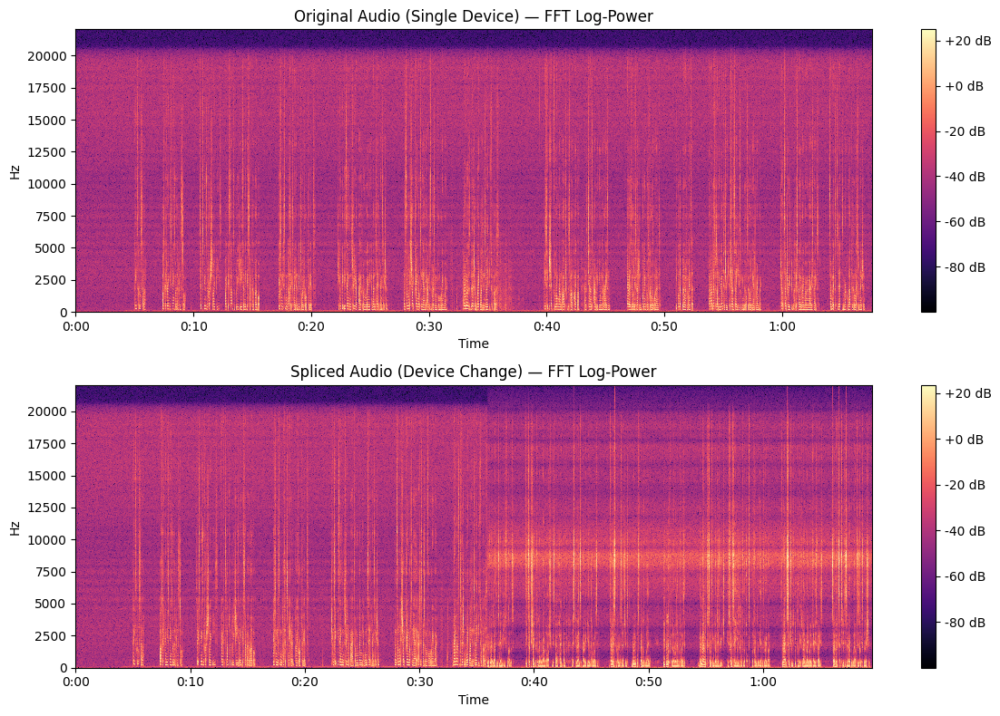

In [ ]:

#####################################
"""Visualize new dataset with FFT"""
#####################################

# print(full_audio_dataset[0])
# print(full_audio_dataset[1])
if 'audio_a' not in dir() or 'result' not in dir() or result is None:
    audio_a = random.choice(audio_dataset)
    audio_b = random.choice([a for a in audio_dataset if a['device'] != audio_a['device']])
    result = generate_splicing_pair(audio_a, audio_b)
print(f"Device A: {result['source_a']} | Device B: {result['source_b']}")
print(f"Cut point: sample {result['cut_point']} -> {result['cut_time']:.4f} seconds")
def visualize_splicing(original_audio, spliced_audio, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH_FFT):
    plt.figure(figsize=(12, 8))

    # FFT (Log-Power) spectrogram of the Original
    plt.subplot(2, 1, 1)
    orig_stft = librosa.stft(original_audio, n_fft=n_fft, hop_length=hop_length, window='hann')
    orig_db = 10 * np.log10(np.abs(orig_stft)**2 + 1e-10)
    librosa.display.specshow(orig_db, sr=sr, hop_length=hop_length,
                              x_axis='time', y_axis='linear')
    plt.title('Original Audio (Single Device) — FFT Log-Power')
    plt.colorbar(format='%+2.0f dB')

    # FFT (Log-Power) spectrogram of the Spliced (Corrupted) audio
    plt.subplot(2, 1, 2)
    splice_stft = librosa.stft(spliced_audio, n_fft=n_fft, hop_length=hop_length, window='hann')
    splice_db = 10 * np.log10(np.abs(splice_stft)**2 + 1e-10)
    librosa.display.specshow(splice_db, sr=sr, hop_length=hop_length,
                              x_axis='time', y_axis='linear')
    plt.title('Spliced Audio (Device Change) — FFT Log-Power')
    plt.colorbar(format='%+2.0f dB')

    plt.tight_layout()
    plt.show()


visualize_splicing(audio_a['audio'], result['audio'])

In [ ]:

###########################################
"""Save example audio"""
###########################################

# 1. Save the array as a .wav file (stays in /content of the Colab runtime)
file_name = "corrupted_test_audio.wav"
sf.write(file_name, result['audio'], SR)

# 2. Download it to your pc (uncomment if you want to download it locally)
# files.download(file_name)


In [ ]:
###########################################
"""Frequency-Band Ablation — Device-Discriminability Test (unvoiced hypothesis)"""
###########################################
# Also run with GPU

def build_stratification_labels(audio_items, stratify_keys=KFOLD_STRATIFY_KEYS):
    """
    Builds a composite stratification label per audio item by concatenating
    the values of the given metadata keys (e.g. device, condition). Passed
    to StratifiedKFold so every fold keeps a proportional representation
    across all specified dimensions.
    """
    return ["_".join(str(item[key]) for key in stratify_keys) for item in audio_items]

def build_frequency_band_mask(variant, sr=SR, n_fft=N_FFT,
                               low_cutoff_hz=FREQ_BAND_LOW_CUTOFF_HZ,
                               high_cutoff_hz=FREQ_BAND_HIGH_CUTOFF_HZ,
                               mid_attenuation_db=FREQ_BAND_MID_ATTENUATION_DB):
    """
    Builds a per-frequency-bin multiplicative mask (linear power domain).
    variant: "full_spectrum" | "low_high_only" | "mid_only"
    """
    freq_axis_hz = np.fft.rfftfreq(n_fft, d=1.0 / sr)
    is_mid_band = (freq_axis_hz >= low_cutoff_hz) & (freq_axis_hz <= high_cutoff_hz)

    mask = np.ones_like(freq_axis_hz, dtype=FEATURE_DTYPE)
    if variant == "full_spectrum":
        return mask
    elif variant == "low_high_only":
        mask[is_mid_band] = 0.0 if mid_attenuation_db is None else 10 ** (-mid_attenuation_db / 10.0)
    elif variant == "mid_only":
        mask[~is_mid_band] = 0.0
    else:
        raise ValueError(f"Unsupported frequency-band ablation variant: {variant}")
    return mask

# Global mask reused by training windowing and by every inference-time
# feature-extraction call, so train and eval stay on the same frequency
# support. None disables masking entirely (equivalent to "full_spectrum").
TRAIN_FREQUENCY_MASK = (
    build_frequency_band_mask(TRAIN_FREQUENCY_MASK_VARIANT)
    if TRAIN_FREQUENCY_MASKING_ENABLED else None
)

def run_frequency_band_ablation(audio_pool, device_to_label, variants=FREQ_BAND_ABLATION_VARIANTS,
                                 sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
                                 win_length_sec=WIN_LENGTH_SEC, hop_length_sec=HOP_LENGTH_SEC_TRAIN,
                                 low_cutoff_hz=FREQ_BAND_LOW_CUTOFF_HZ, high_cutoff_hz=FREQ_BAND_HIGH_CUTOFF_HZ,
                                 mid_attenuation_db=FREQ_BAND_MID_ATTENUATION_DB,
                                 knn_neighbors=KNN_NEIGHBORS, cv_splits=FREQ_BAND_ABLATION_CV_SPLITS,
                                 random_seed=RANDOM_SEED,stratify_keys=KFOLD_STRATIFY_KEYS):
    """
    For each frequency-masking variant, extracts flattened log-power spectra
    (no Siamese embedding involved) and measures device-classification
    separability via k-NN stratified CV. A variant matching or beating
    "full_spectrum" supports masking that band before retraining the model.
    """
    win_length = int(win_length_sec * sr)
    hop_length = int(hop_length_sec * sr)
    results = {}
    audio_stratification_labels = build_stratification_labels(audio_pool, stratify_keys)

    for variant in variants:
        freq_mask = build_frequency_band_mask(
            variant, sr=sr, n_fft=n_fft,
            low_cutoff_hz=low_cutoff_hz, high_cutoff_hz=high_cutoff_hz,
            mid_attenuation_db=mid_attenuation_db,
        )

        features, labels, audio_group_ids, window_stratification_labels = [], [], [], []
        for audio_index, audio_info in enumerate(audio_pool):
            audio_signal = audio_info['audio']
            for start in range(0, len(audio_signal) - win_length, hop_length):
                window = audio_signal[start:start + win_length]
                feature_2d = extract_stft_power_spectrogram_db(window, sr=sr, n_fft=n_fft,
                                                    hop_length=hop_length_fft, freq_mask=freq_mask)
                normalized_feature = (feature_2d - np.mean(feature_2d)) / (np.std(feature_2d) + 1e-8)
                features.append(normalized_feature.flatten())
                labels.append(device_to_label[audio_info['device']])
                audio_group_ids.append(audio_index)
                window_stratification_labels.append(audio_stratification_labels[audio_index])

        features = np.stack(features, axis=0)
        labels = np.asarray(labels)
        audio_group_ids = np.asarray(audio_group_ids)
        window_stratification_labels = np.asarray(window_stratification_labels)

        knn_model = KNeighborsClassifier(n_neighbors=knn_neighbors, metric="euclidean")
        cv_splitter = StratifiedGroupKFold(n_splits=cv_splits, shuffle=True, random_state=random_seed)
        audio_level_splits = list(cv_splitter.split(features, window_stratification_labels, groups=audio_group_ids))
        cv_accuracy = cross_val_score(knn_model, features, labels, cv=audio_level_splits, scoring='accuracy')

        results[variant] = {
            "mean_accuracy": float(cv_accuracy.mean()),
            "std_accuracy": float(cv_accuracy.std()),
            "n_windows": len(labels),
        }
        print(f"[{variant}] k-NN device-CV accuracy: {cv_accuracy.mean():.4%} ± {cv_accuracy.std():.4%} "
              f"(n={len(labels)})")

        del features, labels
        gc.collect()

    return results


def plot_frequency_band_ablation(results, output_path=frequency_ablation_png_path, dpi=FIGURE_DPI):
    variant_names = list(results.keys())
    mean_accuracies = [results[v]["mean_accuracy"] for v in variant_names]
    std_accuracies = [results[v]["std_accuracy"] for v in variant_names]

    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(variant_names, mean_accuracies, yerr=std_accuracies, color='steelblue', alpha=0.85, capsize=8)
    for bar, value in zip(bars, mean_accuracies):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f'{value:.4%}',
                ha='center', fontweight='bold')
    ax.set_ylabel('k-NN Device-Classification Accuracy (CV)')
    ax.set_ylim(0, 1.05)
    ax.set_title('Frequency-Band Ablation — Device Discriminability\n(unvoiced-segment fingerprint hypothesis)',
                 fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Frequency-band ablation plot saved to {output_path}")



def validate_fold_composition(fold_index, fold_train_audios, fold_val_audios,
                               stratify_keys=KFOLD_STRATIFY_KEYS, min_count=MIN_VIABLE):
    """
    Logs the per-(device, condition) audio count in a fold's train and val
    splits, and warns if any stratification group falls below min_count.
    Run before windowing so imbalance is caught early, without spending
    time on feature extraction for a fold that will need re-splitting.
    """
    def _count_by_group(audio_items):
        group_labels = build_stratification_labels(audio_items, stratify_keys)
        values, counts = np.unique(group_labels, return_counts=True)
        return dict(zip(values.tolist(), counts.tolist()))

    train_counts = _count_by_group(fold_train_audios)
    val_counts = _count_by_group(fold_val_audios)
    all_groups = sorted(set(train_counts) | set(val_counts))

    print(f"\n--- Fold {fold_index + 1} composition ({'/'.join(stratify_keys)}) ---")
    print(f"{'Group':<30}{'Train':>10}{'Val':>10}")
    print("-" * 50)

    underrepresented_groups = []
    for group in all_groups:
        train_count = train_counts.get(group, 0)
        val_count = val_counts.get(group, 0)
        flag = ""
        if train_count < min_count or val_count == 0:
            flag = "  <-- LOW"
            underrepresented_groups.append(group)
        print(f"{group:<30}{train_count:>10}{val_count:>10}{flag}")

    if underrepresented_groups:
        print(f"WARNING: Fold {fold_index + 1} has underrepresented groups: {underrepresented_groups}")
    else:
        print(f"Fold {fold_index + 1}: all groups sufficiently represented.")

In [ ]:
def find_shared_filename(audio_dataset, device_a, device_b, condition):
    """
    Finds a filename present for both devices under the given condition,
    so check_take_alignment() has a valid (device, condition, filename)
    combination to compare.
    """
    files_a = {a['filename'] for a in audio_dataset if a['device'] == device_a and a['condition'] == condition}
    files_b = {a['filename'] for a in audio_dataset if a['device'] == device_b and a['condition'] == condition}
    shared = files_a & files_b
    if not shared:
        raise ValueError(f"No shared filenames between {device_a} and {device_b} for condition={condition}")
    return sorted(shared)[0]

In [ ]:
def check_take_alignment(audio_dataset, device_a, device_b, condition, filename,
                          sr=SR, max_lag_sec=TAKE_ALIGNMENT_MAX_LAG_SEC):
    """
    Diagnostic only: estimates the sample-level offset between two
    devices' recordings of the same take (condition + filename), via
    cross-correlation. Run before enabling shared-fragment reuse across
    devices — a small, stable lag across multiple (device_pair, filename)
    combinations supports treating unvoiced fragments as shared per take.
    """
    audio_a = next(a for a in audio_dataset if a['device'] == device_a
                   and a['condition'] == condition and a['filename'] == filename)
    audio_b = next(a for a in audio_dataset if a['device'] == device_b
                   and a['condition'] == condition and a['filename'] == filename)

    print(f"len {device_a}={len(audio_a['audio'])} | len {device_b}={len(audio_b['audio'])}")

    n = min(len(audio_a['audio']), len(audio_b['audio']))
    signal_a = audio_a['audio'][:n] - audio_a['audio'][:n].mean()
    signal_b = audio_b['audio'][:n] - audio_b['audio'][:n].mean()

    correlation = np.correlate(signal_a, signal_b, mode='full')
    lag_samples = int(np.argmax(correlation)) - (n - 1)

    print(f"Estimated lag: {lag_samples} samples ({lag_samples / sr * 1000:.4f} ms)")
    return lag_samples
shared_filename = find_shared_filename(audio_dataset, "iphone_13", "huawei_p30", "speech_clean")
print(f"Using filename: {shared_filename}")
check_take_alignment(audio_dataset, "iphone_13", "huawei_p30", "speech_clean", shared_filename)

Using filename: speaker_1.wav
len iphone_13=3002026 | len huawei_p30=3002026
Estimated lag: 26 samples (0.5896 ms)


26

In [ ]:
shared_unvoiced_fragments = build_shared_unvoiced_fragments(raw_train_audios)

/tmp/ipykernel_4667/1764657927.py:23: UserWarning: With fmin=65.406, sr=16000 and frame_length=372, less than two periods of fmin fit into the frame, which can cause inaccurate pitch detection. Consider increasing to fmin=86.022 or frame_length=491.
  _, voiced_flag, _ = librosa.pyin(
/tmp/ipykernel_4667/1764657927.py:23: UserWarning: With fmin=65.406, sr=16000 and frame_length=372, less than two periods of fmin fit into the frame, which can cause inaccurate pitch detection. Consider increasing to fmin=86.022 or frame_length=491.
  _, voiced_flag, _ = librosa.pyin(


In [ ]:
###########################################
"""Unvoiced-Fragment Extraction Summary — One Representative Take per Condition"""
###########################################

def summarize_unvoiced_fragments_for_condition(fragments_by_take, condition, sr=SR):
    """
    Reports the fragment count and per-fragment duration for one
    representative take of the given condition, drawn from the
    already-computed shared_unvoiced_fragments dict. Since fragments are
    computed once per (condition, filename) take and reused across every
    device (see build_shared_unvoiced_fragments), inspecting a single take
    per condition is representative of the whole condition.
    """
    representative_take_key = next(
        take_key for take_key in fragments_by_take if take_key[0] == condition
    )
    fragments = fragments_by_take[representative_take_key]
    fragment_durations_sec = [(end - start) / sr for start, end in fragments]

    print(f"\n--- Unvoiced fragments — condition: {condition} ---")
    print(f"Representative take: {representative_take_key}")
    print(f"Total fragments extracted: {len(fragments)}")
    for fragment_index, duration_sec in enumerate(fragment_durations_sec, start=1):
        print(f"  Fragment {fragment_index}: {duration_sec:.4f}s")
    if fragment_durations_sec:
        print(f"Mean fragment duration: {np.mean(fragment_durations_sec):.4f}s "
              f"± {np.std(fragment_durations_sec):.4f}s")
        print(f"Total unvoiced duration in this take: {np.sum(fragment_durations_sec):.4f}s")

    return representative_take_key, fragment_durations_sec


unvoiced_fragment_summary_clean = summarize_unvoiced_fragments_for_condition(
    shared_unvoiced_fragments, "speech_clean"
)
unvoiced_fragment_summary_noise = summarize_unvoiced_fragments_for_condition(
    shared_unvoiced_fragments, "speech_noise"
)


--- Unvoiced fragments — condition: speech_clean ---
Representative take: ('speech_clean', 'speaker_13.wav')
Total fragments extracted: 153
  Fragment 1: 0.1235s
  Fragment 2: 0.0717s
  Fragment 3: 0.2729s
  Fragment 4: 0.2040s
  Fragment 5: 0.2380s
  Fragment 6: 0.1586s
  Fragment 7: 0.1407s
  Fragment 8: 0.0545s
  Fragment 9: 0.0976s
  Fragment 10: 0.2356s
  Fragment 11: 0.0950s
  Fragment 12: 0.1147s
  Fragment 13: 0.1695s
  Fragment 14: 0.5214s
  Fragment 15: 0.2027s
  Fragment 16: 1.1901s
  Fragment 17: 0.1436s
  Fragment 18: 0.1407s
  Fragment 19: 0.3477s
  Fragment 20: 0.1781s
  Fragment 21: 0.5519s
  Fragment 22: 0.1465s
  Fragment 23: 0.1034s
  Fragment 24: 0.1177s
  Fragment 25: 0.1925s
  Fragment 26: 0.0947s
  Fragment 27: 0.1091s
  Fragment 28: 0.4599s
  Fragment 29: 0.1034s
  Fragment 30: 1.0924s
  Fragment 31: 0.5978s
  Fragment 32: 0.1206s
  Fragment 33: 0.7502s
  Fragment 34: 0.4599s
  Fragment 35: 0.3506s
  Fragment 36: 0.1292s
  Fragment 37: 0.4512s
  Fragment 38: 0.

In [ ]:
###########################################
"""Listen to Extracted Unvoiced Fragments — Auditory Verification"""
###########################################

def listen_to_unvoiced_fragments(audio_info, sr=SR, min_fragment_sec=UNVOICED_FRAGMENT_MIN_SEC,
                                  gap_sec=UNVOICED_LISTENING_GAP_SEC, save_wav=True,
                                  output_dir=unvoiced_listening_samples_dir):
    """
    Extracts the unvoiced fragments of a single audio using the pipeline's
    existing extract_unvoiced_fragments(), concatenates them with a short
    silence gap for audibility, and renders both the original and the
    unvoiced-only reconstruction for inline playback.

    Parameters
    ----------
    audio_info : dict
        An element of audio_dataset (must contain 'audio', 'sr', 'device',
        'condition', 'filename').
    gap_sec : float
        Silence inserted between consecutive fragments, purely for
        listening purposes — does not affect the training/eval pipeline.
    save_wav : bool
        If True, saves the unvoiced-only reconstruction to output_dir.

    Returns
    -------
    dict with: concatenated_audio, fragments, fragment_durations_sec,
    total_original_duration_sec, total_unvoiced_duration_sec, wav_path
    (wav_path is None when save_wav=False).
    """
    audio = audio_info['audio']
    audio_id = f"{audio_info['device']}/{audio_info['condition']}/{audio_info['filename']}"

    fragments = extract_unvoiced_fragments(audio, sr=sr, min_fragment_sec=min_fragment_sec, audio_id=audio_id)

    if not fragments:
        print(f"WARNING: no unvoiced fragments found for {audio_id}")
        return None

    gap_samples = int(gap_sec * sr)
    gap_silence = np.zeros(gap_samples, dtype=audio.dtype)

    pieces = []
    for fragment_start, fragment_end in fragments:
        pieces.append(audio[fragment_start:fragment_end])
        pieces.append(gap_silence)

    concatenated_audio = np.concatenate(pieces)
    fragment_durations_sec = [(fragment_end - fragment_start) / sr for fragment_start, fragment_end in fragments]
    total_unvoiced_duration_sec = float(np.sum(fragment_durations_sec))
    total_original_duration_sec = len(audio) / sr

    print(f"\n--- {audio_id} ---")
    print(f"Original duration: {total_original_duration_sec:.4f}s")
    print(f"Fragments extracted: {len(fragments)}")
    print(f"Total unvoiced duration: {total_unvoiced_duration_sec:.4f}s "
          f"({100 * total_unvoiced_duration_sec / total_original_duration_sec:.4f}% of original)")
    print(f"Mean fragment duration: {np.mean(fragment_durations_sec):.4f}s "
          f"± {np.std(fragment_durations_sec):.4f}s")

    print("\n>>> ORIGINAL audio (reference):")
    display(Audio(audio, rate=sr))

    print(">>> UNVOICED-ONLY fragments (concatenated):")
    display(Audio(concatenated_audio, rate=sr))

    wav_path = None
    if save_wav:
        wav_filename = f"unvoiced_only_{audio_info['device']}_{audio_info['condition']}_{audio_info['filename']}"
        wav_path = os.path.join(output_dir, wav_filename)
        sf.write(wav_path, concatenated_audio, sr)
        print(f"Saved to: {wav_path}")

    return {
        "concatenated_audio": concatenated_audio,
        "fragments": fragments,
        "fragment_durations_sec": fragment_durations_sec,
        "total_original_duration_sec": total_original_duration_sec,
        "total_unvoiced_duration_sec": total_unvoiced_duration_sec,
        "wav_path": wav_path,
    }

In [ ]:
sample_device = random.choice(devices)

audio_clean_example = random.choice(
    [a for a in audio_dataset if a['device'] == sample_device and a['condition'] == 'speech_clean']
)
audio_noise_example = random.choice(
    [a for a in audio_dataset if a['device'] == sample_device and a['condition'] == 'speech_noise']
)

print(f"=== Device: {sample_device} ===")
unvoiced_listening_result_clean = listen_to_unvoiced_fragments(audio_clean_example)
unvoiced_listening_result_noise = listen_to_unvoiced_fragments(audio_noise_example)

=== Device: moto_edge_30 ===


/tmp/ipykernel_4667/1764657927.py:23: UserWarning: With fmin=65.406, sr=16000 and frame_length=372, less than two periods of fmin fit into the frame, which can cause inaccurate pitch detection. Consider increasing to fmin=86.022 or frame_length=491.
  _, voiced_flag, _ = librosa.pyin(



--- moto_edge_30/speech_clean/speaker_17.wav ---
Original duration: 86.9560s
Fragments extracted: 248
Total unvoiced duration: 31.4491s (36.1667% of original)
Mean fragment duration: 0.1268s ± 0.1198s

>>> ORIGINAL audio (reference):


>>> UNVOICED-ONLY fragments (concatenated):


Saved to: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/unvoiced_listening_samples/unvoiced_only_moto_edge_30_speech_clean_speaker_17.wav

--- moto_edge_30/speech_noise/speaker_22.wav ---
Original duration: 88.8110s
Fragments extracted: 126
Total unvoiced duration: 48.9050s (55.0664% of original)
Mean fragment duration: 0.3881s ± 0.8419s

>>> ORIGINAL audio (reference):


>>> UNVOICED-ONLY fragments (concatenated):


Saved to: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/unvoiced_listening_samples/unvoiced_only_moto_edge_30_speech_noise_speaker_22.wav


In [ ]:

def cache_stratified_folds(raw_train_audios, n_splits=N_SPLITS, seed=RANDOM_SEED,
                            stratify_keys=KFOLD_STRATIFY_KEYS, output_dir=output_path):
    """
    Splits raw_train_audios into stratified folds and caches each fold's
    train/val windows to disk. Stratification ensures every fold contains
    a balanced number of audios per device (and, by default, per recording
    condition).
    """
    stratification_labels = build_stratification_labels(raw_train_audios, stratify_keys)
    kfold_splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    indices = np.arange(len(raw_train_audios))

    for fold_index, (train_idx, val_idx) in enumerate(kfold_splitter.split(indices, stratification_labels)):
        fold_path = os.path.join(output_dir, f"fold_{fold_index + 1}.pkl")

        # If it already exists, skip (resume where it left off)
        if os.path.exists(fold_path):
            print(f"Fold {fold_index + 1} already exists at {fold_path}, skipping.")
            continue

        random.seed(seed + fold_index)  # reproducible per fold

        fold_train_audios = [raw_train_audios[i] for i in train_idx]
        fold_val_audios = [raw_train_audios[i] for i in val_idx]

        validate_fold_composition(fold_index, fold_train_audios, fold_val_audios,   #BORRAR DESPUES DE REVISAR Q SI ESTE BIEN JUNTO CON LO DE ARRIBA
                                   stratify_keys=stratify_keys, min_count=MIN_VIABLE)

        train_windows = generate_train_val_windows(fold_train_audios, apply_jitter=APPLY_JITTER_TRAIN)
        val_windows = generate_train_val_windows(
            fold_val_audios, apply_jitter=APPLY_JITTER_EVAL, is_validation=True
        )

        with open(fold_path, "wb") as f:
            pickle.dump({"train": train_windows, "val": val_windows}, f,
                        protocol=pickle.HIGHEST_PROTOCOL)
        print(f"Fold {fold_index + 1} cached at {fold_path}")

        del train_windows, val_windows, fold_train_audios, fold_val_audios
        gc.collect()


cache_stratified_folds(raw_train_audios, n_splits=N_SPLITS)


--- Fold 1 composition (device/condition) ---
Group                              Train       Val
--------------------------------------------------
huawei_nova_9_se_speech_clean         14         7
huawei_nova_9_se_speech_noise         14         7
huawei_nova_9_speech_clean            14         7
huawei_nova_9_speech_noise            14         7
huawei_p30_speech_clean               14         7
huawei_p30_speech_noise               14         7
iphone_12_mini_speech_clean           14         7
iphone_12_mini_speech_noise           14         7
iphone_13_speech_clean                14         7
iphone_13_speech_noise                14         7
iphone_xs_max_speech_clean            14         7
iphone_xs_max_speech_noise            14         7
moto_edge_20_speech_clean             14         7
moto_edge_20_speech_noise             14         7
moto_edge_30_speech_clean             14         7
moto_edge_30_speech_noise             14         7
moto_g9_power_speech_clean         

In [ ]:
rms_dbfs = librosa.amplitude_to_db(
    librosa.feature.rms(y=audio_clean_example['audio'], frame_length=UNVOICED_FRAME_LENGTH,
                        hop_length=UNVOICED_HOP_LENGTH, center=False)[0],
    ref=1.0, amin=LOG_POWER_EPSILON, top_db=None)
print(np.percentile(rms_dbfs, [1, 5, 25, 50, 75]))

[-89.15393829 -87.06947327 -79.44585228 -50.72524643 -41.83528805]


[full_spectrum] k-NN device-CV accuracy: 17.0699% ± 1.6657% (n=63840)
[low_high_only] k-NN device-CV accuracy: 19.3257% ± 2.2236% (n=63840)
[mid_only] k-NN device-CV accuracy: 3.7171% ± 0.4873% (n=63840)


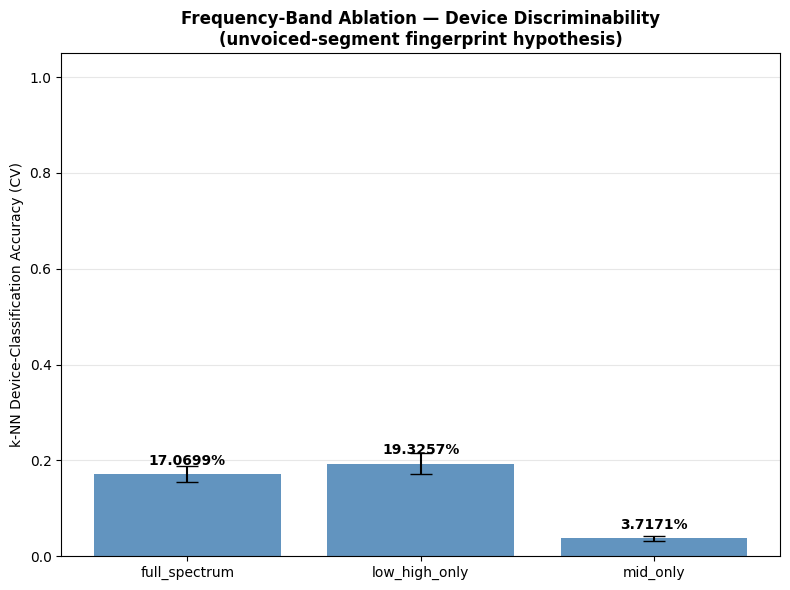

Frequency-band ablation plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/frequency_band_ablation_euclidean_uv_epochs510_val15_win1_evlminhard_outdim64.png


In [ ]:
if FREQ_BAND_ABLATION_ENABLED:
    frequency_ablation_results = run_frequency_band_ablation(raw_train_audios, device_to_label)
    plot_frequency_band_ablation(frequency_ablation_results)
    with open(frequency_ablation_results_path, "wb") as f:
        pickle.dump(frequency_ablation_results, f, protocol=pickle.HIGHEST_PROTOCOL)

Computing segment categories for 42 takes...
[full] windows=63840 | duration=1064.0 min
[voiced] windows=98480 | duration=411.9 min
[unvoiced] windows=50840 | duration=209.9 min
[silence] windows=30400 | duration=317.0 min
[unvoiced_plus_silence] windows=76640 | duration=584.0 min
Balancing all variants to 30400 windows each.
[full] k-NN device-CV accuracy: 93.8164% ± 1.3518% (n=30400)
[voiced] k-NN device-CV accuracy: 75.3178% ± 1.7268% (n=30400)
[unvoiced] k-NN device-CV accuracy: 77.0644% ± 1.6328% (n=30400)
[silence] k-NN device-CV accuracy: 98.4876% ± 0.4229% (n=30400)
[unvoiced_plus_silence] k-NN device-CV accuracy: 89.6454% ± 1.2700% (n=30400)


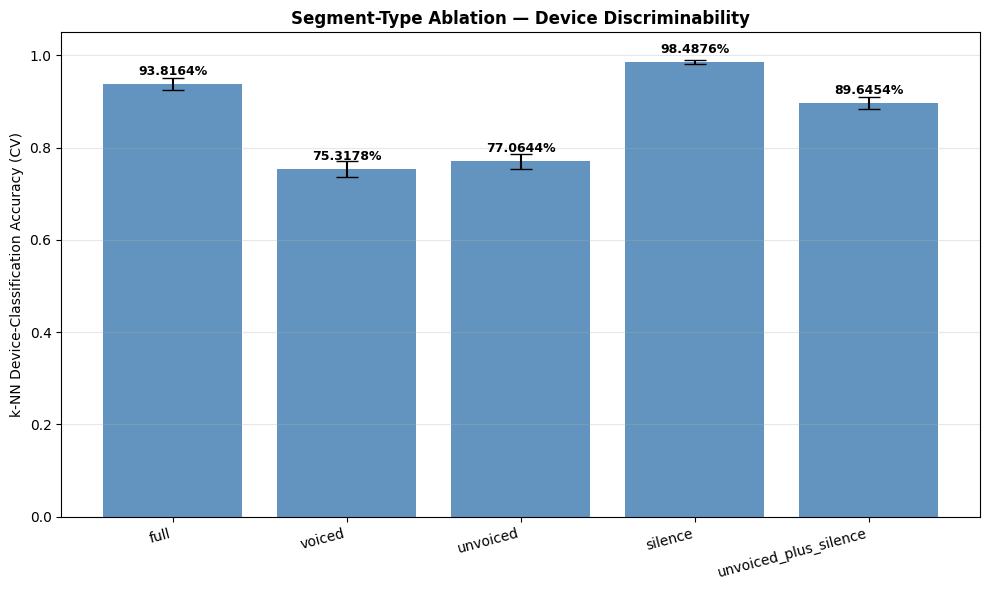

Segment-type ablation plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/segment_type_ablation_euclidean_uv_epochs510_val15_win1_evlminhard_outdim64.png
Segment-type ablation results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/segment_type_ablation_euclidean_uv_epochs510_val15_win1_evlminhard_outdim64.pkl


In [ ]:
###########################################
"""Segment-Type Ablation — Voiced / Unvoiced / Silence / Unvoiced+Silence / Full"""
###########################################
# Segment partition (per audio, within energy-valid samples):
#   silence               = ~non_silent(TOP_DB)
#   unvoiced              =  unvoiced(pyin) & non_silent
#   voiced                = ~unvoiced(pyin) & non_silent
#   unvoiced_plus_silence = unvoiced | silence
#   full                  = fixed-length windows over the entire audio

def _mask_to_intervals(mask):
    """Converts a boolean sample mask into a list of (start, end) sample intervals."""
    edges = np.diff(np.concatenate([[0], mask.astype(np.int8), [0]]))
    return [(int(start), int(end))
            for start, end in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1))]


def compute_segment_category_intervals(audio, sr=SR, top_db=TOP_DB):
    """
    Partitions one audio into voiced / unvoiced / silence / unvoiced+silence
    sample intervals. Voicing detection is delegated to compute_unvoiced_sample_mask()
    so the categories stay consistent with the training pipeline.
    """
    unvoiced_energy_mask = compute_unvoiced_sample_mask(
        audio, sr=sr, top_db=top_db,
        include_silence_noise=True, digital_silence_filter_enabled=True,
    )
    energy_mask = compute_energy_sample_mask(audio, sr=sr)

    non_silent_mask = np.zeros(len(audio), dtype=bool)
    for interval_start, interval_end in librosa.effects.split(audio, top_db=top_db):
        non_silent_mask[interval_start:interval_end] = True

    unvoiced_mask = unvoiced_energy_mask & non_silent_mask
    voiced_mask = energy_mask & non_silent_mask & ~unvoiced_energy_mask
    silence_mask = energy_mask & ~non_silent_mask

    # Order must match SEGMENT_CATEGORY_KEYS
    category_masks = (voiced_mask, unvoiced_mask, silence_mask, unvoiced_mask | silence_mask)
    return {key: _mask_to_intervals(mask) for key, mask in zip(SEGMENT_CATEGORY_KEYS, category_masks)}


def build_segment_category_intervals_by_take(audio_pool, sr=SR, n_jobs=SEGMENT_ABLATION_N_JOBS,
                                              cache_dir=segment_category_cache_dir):
    """
    Runs the (expensive) voicing detection once per (condition, filename) take and
    reuses it across devices, valid because takes are sample-aligned across devices.
    Results are cached to disk.
    """
    reference_audio_by_take = {}
    for audio_info in audio_pool:
        reference_audio_by_take.setdefault((audio_info['condition'], audio_info['filename']), audio_info)
    take_keys = sorted(reference_audio_by_take)

    cache_signature = hashlib.sha1(
        f"{take_keys}|{sr}|{TOP_DB}|{UNVOICED_ANALYSIS_SR}|{UNVOICED_FRAME_LENGTH}|{UNVOICED_HOP_LENGTH}"
        f"|{UNVOICED_FMIN_HZ}|{UNVOICED_FMAX_HZ}|{UNVOICED_DIGITAL_SILENCE_FLOOR_DBFS}"
        f"|{UNVOICED_VOICED_GUARD_MARGIN_SEC}|{UNVOICED_EXTRACTION_ALGORITHM_VERSION}".encode()
    ).hexdigest()
    cache_path = os.path.join(cache_dir, f"segment_category_intervals_{cache_signature}.pkl")
    if os.path.exists(cache_path):
        print(f"Segment-category intervals cache found: {cache_path}")
        with open(cache_path, "rb") as f:
            return pickle.load(f)

    print(f"Computing segment categories for {len(take_keys)} takes...")
    intervals_per_take = Parallel(n_jobs=n_jobs)(
        delayed(compute_segment_category_intervals)(reference_audio_by_take[take_key]['audio'], sr)
        for take_key in take_keys
    )
    intervals_by_take = dict(zip(take_keys, intervals_per_take))
    with open(cache_path, "wb") as f:
        pickle.dump(intervals_by_take, f, protocol=pickle.HIGHEST_PROTOCOL)
    return intervals_by_take


def _iter_full_windows(audio, sr, win_length_sec, hop_length_sec):
    win_length, hop_length = int(win_length_sec * sr), int(hop_length_sec * sr)
    for start in range(0, len(audio) - win_length, hop_length):
        yield audio[start:start + win_length]


def _iter_category_segments(audio, intervals, sr, win_length_sec, min_segment_sec):
    """One fragment at a time (no concatenation); long fragments are split into chunks <= win_length_sec."""
    win_length, min_samples = int(win_length_sec * sr), round(min_segment_sec * sr)
    for interval_start, interval_end in intervals:
        interval_end = min(interval_end, len(audio))
        for window_start in range(interval_start, interval_end, win_length):
            segment = audio[window_start:min(window_start + win_length, interval_end)]
            if len(segment) >= min_samples:
                yield segment


def _pooled_spectral_descriptor(segment, sr, n_fft, hop_length_fft, use_std,
                                epsilon=SEGMENT_ABLATION_FEATURE_EPSILON):
    """
    Collapses the time axis into a fixed-length vector so variable-duration segments
    are comparable. Same per-window normalization as the rest of the pipeline.
    """
    feature = extract_stft_power_spectrogram_db(segment, sr=sr, n_fft=n_fft, hop_length=hop_length_fft)
    normalized_feature = (feature - np.mean(feature)) / (np.std(feature) + epsilon)
    descriptor = normalized_feature.mean(axis=1)
    if use_std:
        descriptor = np.concatenate([descriptor, normalized_feature.std(axis=1)])
    return descriptor


def run_segment_type_ablation(audio_pool, device_to_label, variants=SEGMENT_ABLATION_VARIANTS,
                               sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
                               win_length_sec=WIN_LENGTH_SEC, hop_length_sec=HOP_LENGTH_SEC_TRAIN,
                               min_segment_sec=SEGMENT_ABLATION_MIN_SEC, use_std=SEGMENT_ABLATION_USE_STD,
                               balance_windows=SEGMENT_ABLATION_BALANCE_WINDOWS,
                               knn_neighbors=KNN_NEIGHBORS, cv_splits=SEGMENT_ABLATION_CV_SPLITS,
                               random_seed=RANDOM_SEED, stratify_keys=KFOLD_STRATIFY_KEYS):
    """
    For each segment type, measures device separability (k-NN, audio-grouped stratified CV)
    on pooled log-power descriptors. No Siamese embedding involved.
    """
    intervals_by_take = None
    if any(variant != SEGMENT_ABLATION_FULL_VARIANT for variant in variants):
        intervals_by_take = build_segment_category_intervals_by_take(audio_pool, sr=sr)

    audio_stratification_labels = build_stratification_labels(audio_pool, stratify_keys)
    collected_by_variant = {}

    for variant in variants:
        features, labels, group_ids, stratification_labels, total_samples = [], [], [], [], 0
        for audio_index, audio_info in enumerate(audio_pool):
            audio_signal = audio_info['audio']
            if variant == SEGMENT_ABLATION_FULL_VARIANT:
                segments = _iter_full_windows(audio_signal, sr, win_length_sec, hop_length_sec)
            else:
                take_key = (audio_info['condition'], audio_info['filename'])
                segments = _iter_category_segments(
                    audio_signal, intervals_by_take[take_key][variant], sr, win_length_sec, min_segment_sec
                )
            for segment in segments:
                features.append(_pooled_spectral_descriptor(segment, sr, n_fft, hop_length_fft, use_std))
                labels.append(device_to_label[audio_info['device']])
                group_ids.append(audio_index)
                stratification_labels.append(audio_stratification_labels[audio_index])
                total_samples += len(segment)

        if not features:
            print(f"[{variant}] no segments found, skipped.")
            continue
        collected_by_variant[variant] = {
            "features": np.stack(features, axis=0),
            "labels": np.asarray(labels),
            "groups": np.asarray(group_ids),
            "stratification": np.asarray(stratification_labels),
            "n_windows_before_balancing": len(labels),
            "total_duration_sec": total_samples / sr,
        }
        print(f"[{variant}] windows={len(labels)} | duration={total_samples / sr / 60:.1f} min")

    if balance_windows and collected_by_variant:
        min_window_count = min(len(v["labels"]) for v in collected_by_variant.values())
        rng = np.random.default_rng(random_seed)
        print(f"Balancing all variants to {min_window_count} windows each.")
        for v in collected_by_variant.values():
            if len(v["labels"]) > min_window_count:
                keep_indices = np.sort(rng.choice(len(v["labels"]), size=min_window_count, replace=False))
                for key in ("features", "labels", "groups", "stratification"):
                    v[key] = v[key][keep_indices]

    results = {}
    for variant, v in collected_by_variant.items():
        knn_model = KNeighborsClassifier(n_neighbors=knn_neighbors, metric="euclidean")
        cv_splitter = StratifiedGroupKFold(n_splits=cv_splits, shuffle=True, random_state=random_seed)
        audio_level_splits = list(cv_splitter.split(v["features"], v["stratification"], groups=v["groups"]))
        cv_accuracy = cross_val_score(knn_model, v["features"], v["labels"], cv=audio_level_splits, scoring='accuracy')

        results[variant] = {
            "mean_accuracy": float(cv_accuracy.mean()),
            "std_accuracy": float(cv_accuracy.std()),
            "n_windows": int(len(v["labels"])),
            "n_windows_before_balancing": int(v["n_windows_before_balancing"]),
            "n_audios_with_data": int(len(np.unique(v["groups"]))),
            "total_duration_sec_before_balancing": float(v["total_duration_sec"]),
        }
        print(f"[{variant}] k-NN device-CV accuracy: {cv_accuracy.mean():.4%} ± {cv_accuracy.std():.4%} "
              f"(n={len(v['labels'])})")

    del collected_by_variant
    gc.collect()
    return results


def plot_segment_type_ablation(results, output_path=segment_ablation_png_path, dpi=FIGURE_DPI):
    variant_names = list(results.keys())
    mean_accuracies = [results[v]["mean_accuracy"] for v in variant_names]
    std_accuracies = [results[v]["std_accuracy"] for v in variant_names]

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(variant_names, mean_accuracies, yerr=std_accuracies, color='steelblue', alpha=0.85, capsize=8)
    for bar, value in zip(bars, mean_accuracies):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f'{value:.4%}',
                ha='center', fontweight='bold', fontsize=9)
    ax.set_ylabel('k-NN Device-Classification Accuracy (CV)')
    ax.set_ylim(0, 1.05)
    ax.set_xticks(range(len(variant_names)))
    ax.set_xticklabels(variant_names, rotation=15, ha='right')
    ax.set_title('Segment-Type Ablation — Device Discriminability', fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Segment-type ablation plot saved to {output_path}")


if SEGMENT_ABLATION_ENABLED:
    segment_ablation_results = run_segment_type_ablation(raw_train_audios, device_to_label)
    plot_segment_type_ablation(segment_ablation_results)
    with open(segment_ablation_results_path, "wb") as f:
        pickle.dump(segment_ablation_results, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Segment-type ablation results saved to {segment_ablation_results_path}")

In [ ]:

###########################################
"""Save final windowed dataset (features already extracted)"""
###########################################

if os.path.exists(windowed_dataset_path):
    print(f"final_training_dataset.pkl already exists, loading from {windowed_dataset_path}")
    with open(windowed_dataset_path, "rb") as f:
        final_training_dataset = pickle.load(f)
else:
    final_training_dataset = generate_train_val_windows(raw_train_audios, apply_jitter=APPLY_JITTER_TRAIN)
    dataset_to_save = [
        {k: v for k, v in item.items() if k != "audio_window"}
        for item in final_training_dataset
    ]
    with open(windowed_dataset_path, "wb") as f:
        pickle.dump(dataset_to_save, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Windowed dataset: {len(final_training_dataset)} windows")


if os.path.exists(eval_windows_path):
    print(f"Evaluation windows already exist, loading from {eval_windows_path}")
    with open(eval_windows_path, "rb") as f:
        final_test_windows = pickle.load(f)["test"]
else:
    final_test_windows = generate_splicing_windows_streaming(
      test_audios, sr=SR, apply_jitter=APPLY_JITTER_EVAL
    )
    with open(eval_windows_path, "wb") as f:
        pickle.dump({"test": final_test_windows}, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Evaluation (test) windows saved to {eval_windows_path}")


print(final_training_dataset[0]['spectral_feature'].shape)
if os.path.exists(eval_windows_path):
    with open(eval_windows_path, "rb") as f:
        final_test_windows = pickle.load(f)["test"]
    if final_test_windows and "audio_id" not in final_test_windows[0]:
        print(f"Cached windows at {eval_windows_path} are missing 'audio_id' — regenerating.")
        final_test_windows = None

if final_test_windows is None:
    final_test_windows = generate_splicing_windows_streaming(
        test_audios, sr=SR, apply_jitter=APPLY_JITTER_EVAL
    )
    with open(eval_windows_path, "wb") as f:
        pickle.dump({"test": final_test_windows}, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Evaluation (test) windows saved to {eval_windows_path}")
assert len(final_test_windows) > 0, "final_test_windows is empty — check generate_splicing_windows_streaming."

Windowed dataset: 35220 windows
Evaluation (test) windows saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eval_windows_knn.pkl
(1025, 22)



# From here on, training with GPU

In [ ]:

if os.path.exists(eval_windows_path):
    with open(eval_windows_path, "rb") as f:
        final_test_windows = pickle.load(f)["test"]
    if final_test_windows and "audio_id" not in final_test_windows[0]:
        print(f"Cached windows at {eval_windows_path} are missing 'audio_id' — regenerating.")
        final_test_windows = None

if final_test_windows is None:
    final_test_windows = generate_splicing_windows_streaming(
        test_audios, sr=SR, apply_jitter=APPLY_JITTER_EVAL
    )
    with open(eval_windows_path, "wb") as f:
        pickle.dump({"test": final_test_windows}, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Evaluation (test) windows saved to {eval_windows_path}")

# Ensure final_training_dataset is available regardless of execution order
if 'final_training_dataset' not in dir():
    print(f"final_training_dataset not in memory, loading from {windowed_dataset_path}")
    with open(windowed_dataset_path, "rb") as f:
        final_training_dataset = pickle.load(f)

with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    split = pickle.load(f)
    raw_train_audios = split["raw_train_audios"]
    val_audios = split["val_audios"]
    test_audios = split["test_audios"]

print(f"Windows loaded: {len(final_training_dataset)}")


final_training_dataset not in memory, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/final_training_dataset.pkl
Windows loaded: 35220


In [ ]:
shared_unvoiced_fragments = build_shared_unvoiced_fragments(raw_train_audios)

In [ ]:
TRAIN_FREQUENCY_MASK = (
    build_frequency_band_mask(TRAIN_FREQUENCY_MASK_VARIANT)
    if TRAIN_FREQUENCY_MASKING_ENABLED else None
)

In [ ]:

def build_training_distance(metric: str = TRAIN_DISTANCE_METRIC,
                             p: int = TRAIN_DISTANCE_P,
                             normalize_embeddings: bool = TRAIN_DISTANCE_NORMALIZE_EMBEDDINGS):
    """Factory for the miner/loss distance object, so the metric used
    for training can be swapped (L1, L2, cosine, SNR, etc.) from a single config
    variable without touching train_with_kfold / train_final_model."""
    if metric == "cosine":
        return CosineSimilarity()
    elif metric == "lp":
        return LpDistance(p=p, normalize_embeddings=normalize_embeddings)
    elif metric == "snr":
        return SNRDistance(normalize_embeddings=normalize_embeddings)
    else:
        raise ValueError(f"Unsupported TRAIN_DISTANCE_METRIC: {metric}")

def build_metric_learning_components(model, lr=LR, loss_type=TRAIN_LOSS_TYPE,
                                     num_classes=len(device_to_label), out_dim=OUT_DIM,
                                     device=device):
    """
    Builds the optimizer, loss function and pytorch-metric-learning adapter
    for the selected training objective.

    - "triplet": TripletMarginLoss + TripletMarginMiner (parameter-free loss).
    - "arcface": ArcFaceLoss. Owns learnable class prototypes
                 W in R^{num_classes x out_dim}, so its parameters MUST be
                 optimized jointly with the backbone. No miner is required
                 (classification-based loss).
    - "cosface": CosFaceLoss. Same prototype-based scheme as ArcFace, with an
                 additive margin applied in cosine space.

    Returns
    -------
    optimizer, loss_fn, adapter
    """
    if loss_type == "triplet":
        train_miner = miners.TripletMarginMiner(margin=TRIPLET_MARGIN, type_of_triplets=TRAIN_MINER_TYPE,
                                                distance=build_training_distance())
        eval_miner = miners.TripletMarginMiner(margin=TRIPLET_MARGIN, type_of_triplets=EVAL_MINER_TYPE,
                                               distance=build_training_distance())
        loss_fn = losses.TripletMarginLoss(margin=TRIPLET_MARGIN, distance=build_training_distance())
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)

        def adapter(model, batch, func):
            if len(batch) == 3:
                specs, labels, valid_time_lengths = batch
                valid_time_lengths = valid_time_lengths.to(specs.device)
            else:
                specs, labels = batch
                valid_time_lengths = None
            embeddings = model(specs, valid_time_lengths)
            active_miner = train_miner if model.training else eval_miner
            return func(embeddings, labels, active_miner(embeddings, labels))

    elif loss_type == "arcface":
        loss_fn = losses.ArcFaceLoss(num_classes=num_classes, embedding_size=out_dim,
                                     margin=ARCFACE_MARGIN_DEG, scale=ARCFACE_SCALE).to(device)
        optimizer = torch.optim.AdamW([
            {"params": model.parameters(),   "lr": lr,              "weight_decay": WEIGHT_DECAY},
            {"params": loss_fn.parameters(), "lr": ARCFACE_LOSS_LR, "weight_decay": ARCFACE_LOSS_WEIGHT_DECAY},
        ])

        def adapter(model, batch, func):
            if len(batch) == 3:
                specs, labels, valid_time_lengths = batch
                valid_time_lengths = valid_time_lengths.to(specs.device)
            else:
                specs, labels = batch
                valid_time_lengths = None
            embeddings = model(specs, valid_time_lengths)
            return func(embeddings, labels)

    elif loss_type == "cosface":
        loss_fn = losses.CosFaceLoss(num_classes=num_classes, embedding_size=out_dim,
                                     margin=COSFACE_MARGIN, scale=COSFACE_SCALE).to(device)
        optimizer = torch.optim.AdamW([
            {"params": model.parameters(),   "lr": lr,              "weight_decay": WEIGHT_DECAY},
            {"params": loss_fn.parameters(), "lr": COSFACE_LOSS_LR, "weight_decay": COSFACE_LOSS_WEIGHT_DECAY},
        ])

        def adapter(model, batch, func):
            if len(batch) == 3:
                specs, labels, valid_time_lengths = batch
                valid_time_lengths = valid_time_lengths.to(specs.device)
            else:
                specs, labels = batch
                valid_time_lengths = None
            embeddings = model(specs, valid_time_lengths)
            return func(embeddings, labels)

    else:
        raise ValueError(f"Unsupported TRAIN_LOSS_TYPE: {loss_type}")

    return optimizer, loss_fn, adapter


def get_active_loss_config(loss_type: str = TRAIN_LOSS_TYPE) -> dict:
    """
    Returns only the hyperparameters relevant to the active training objective,
    so saved experiment configs never mix (or omit) loss-specific settings.
    """
    if loss_type == "triplet":
        return {
            "TRAIN_LOSS_TYPE": loss_type,
            "TRIPLET_MARGIN": TRIPLET_MARGIN,
            "TRAIN_MINER_TYPE": TRAIN_MINER_TYPE,
            "EVAL_MINER_TYPE": EVAL_MINER_TYPE,
            "TRAIN_DISTANCE_METRIC": TRAIN_DISTANCE_METRIC,
            "TRAIN_DISTANCE_P": TRAIN_DISTANCE_P,
        }
    if loss_type == "arcface":
        return {
            "TRAIN_LOSS_TYPE": loss_type,
            "ARCFACE_MARGIN_DEG": ARCFACE_MARGIN_DEG,
            "ARCFACE_SCALE": ARCFACE_SCALE,
        }
    if loss_type == "cosface":
        return {
            "TRAIN_LOSS_TYPE": loss_type,
            "COSFACE_MARGIN": COSFACE_MARGIN,
            "COSFACE_SCALE": COSFACE_SCALE,
        }
    raise ValueError(f"Unsupported TRAIN_LOSS_TYPE: {loss_type}")

In [ ]:
###
"""Embedding Extraction Dataset"""
###
# Auxiliary loader only for extracting embeddings with device label

class EmbeddingExtractionDataset(Dataset):
    def __init__(self, window_list, device_to_label, global_mean=None, global_std=None):
        self.data = window_list
        self.device_to_label = device_to_label
        #self.global_mean = global_mean
        #self.global_std = global_std

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        spec = torch.tensor(item['spectral_feature'], dtype=torch.float32).unsqueeze(0)

        #if self.global_mean is not None and self.global_std is not None:
        #    spec = (spec - self.global_mean) / (self.global_std + 1e-8)

        label = self.device_to_label[item['device_b']]
        return spec, torch.tensor(label, dtype=torch.long)

def collate_variable_length_spectrograms(batch, pad_value=UNVOICED_FRAGMENT_COLLATE_PAD_VALUE):
    """
    Required collate_fn when TRAIN_VAL_UNVOICED_FRAGMENTS_ENABLED=True and
    UNVOICED_FRAGMENT_PAD_TO_WINDOW_ENABLED=False: unvoiced-fragment windows keep
    their natural duration, so time-frame count varies per sample. Pads every
    spectrogram to the batch's max time-frame count for stacking, and returns the
    pre-padding valid length per sample so EmbeddingNet.forward can mask the padding
    out at pooling time instead of treating it as real signal.
    """
    specs, labels = zip(*batch)
    valid_time_lengths = torch.tensor([spec.shape[-1] for spec in specs], dtype=torch.long)
    max_time_frames = int(valid_time_lengths.max().item())
    padded_specs = [
        F.pad(spec, (0, max_time_frames - spec.shape[-1]), mode="constant", value=pad_value)
        for spec in specs
    ]
    return torch.stack(padded_specs, dim=0), torch.stack(labels, dim=0), valid_time_lengths

def extract_embeddings(model, loader, device):
    model.eval()
    embeddings = []
    labels = []
    with torch.no_grad():
        for batch in loader:
            if len(batch) == 3:
                specs, target_labels, valid_time_lengths = batch
                valid_time_lengths = valid_time_lengths.to(device)
            else:
                specs, target_labels = batch
                valid_time_lengths = None

            specs = specs.to(device)
            output = model(specs, valid_time_lengths)

            embeddings.append(output.cpu())
            labels.append(target_labels)

    return torch.cat(embeddings), torch.cat(labels)

In [ ]:

###########################################
"""Prepare Pairs"""
###########################################
# final_training_dataset is the list created with the segmentation function
ds = EmbeddingExtractionDataset(final_training_dataset, device_to_label)
train_loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True,
                           collate_fn=collate_variable_length_spectrograms)


In [ ]:

###########################################
"""Print pairs"""
###########################################

specs, labels, _ = next(iter(train_loader))

print(f"Spectrogram batch shape: {specs.shape}")
# Should be:   batch size, chanel, bins of frequency, temporal frames

print(f"Batch labels: {labels}")
# Should be a tensor of numbers between 0 and 2

Spectrogram batch shape: torch.Size([128, 1, 1025, 22])
Batch labels: tensor([13,  4,  9, 16, 10,  7, 12,  6,  0, 18,  9,  2,  1,  0, 12, 12, 19, 13,
         4,  2,  1,  4,  9,  8, 10,  6, 18, 13,  2, 17,  9,  5, 18, 11,  5,  7,
         4, 12,  9,  6,  3,  5, 17, 12,  2, 17, 10,  4,  4,  6, 10,  6,  0, 18,
         1,  8, 12, 14, 17,  4,  1, 16,  3, 15, 13, 15,  6, 12, 17, 16, 10,  9,
        14, 12,  3, 14, 10,  5, 14, 13, 19, 15, 10, 16,  1, 11, 16, 14, 17, 15,
         3, 16,  4,  5,  7,  9, 19, 10, 11, 10, 15,  3,  3,  7, 17,  2,  6, 13,
         7, 14, 14,  2, 18,  6,  0, 13, 17,  5,  3,  0,  1, 12,  8,  9, 18,  8,
        19, 14])


In [ ]:
class EfficientChannelAttention(nn.Module):
    """
    ECA-Net channel attention (Wang et al., 2020). Applies a lightweight
    1D convolution over channel-wise global average pooled features to
    model local cross-channel interaction, avoiding the dimensionality
    reduction used in Squeeze-and-Excitation blocks.
    """
    def __init__(self, num_channels: int, gamma: int = 2, beta: int = 1):
        super().__init__()
        kernel_size = int(abs((torch.log2(torch.tensor(float(num_channels))) + beta) / gamma))
        kernel_size = kernel_size if kernel_size % 2 else kernel_size + 1
        kernel_size = max(kernel_size, 3)

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.channel_conv = nn.Conv1d(
            in_channels=1, out_channels=1, kernel_size=kernel_size,
            padding=(kernel_size - 1) // 2, bias=False
        )
        self.gate = nn.Sigmoid()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        channel_descriptor = self.global_pool(x)                       # [B, C, 1, 1]
        channel_descriptor = channel_descriptor.squeeze(-1).transpose(-1, -2)  # [B, 1, C]
        channel_attention = self.channel_conv(channel_descriptor)      # [B, 1, C]
        channel_attention = channel_attention.transpose(-1, -2).unsqueeze(-1)  # [B, C, 1, 1]
        return x * self.gate(channel_attention)

In [ ]:

###########################################
"""EmbeddingNet Backbone+Neck+EmbeddingNet"""
###########################################
class Backbone(nn.Sequential):
    def __init__(self, dropout_conv=0.1):
        super().__init__(
            # Input: [1, F, T]  (F=freq bins, T=temporal frames)
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=BACKBONE_POOL_CEIL_MODE),
            nn.Dropout2d(dropout_conv),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=BACKBONE_POOL_CEIL_MODE),
            nn.Dropout2d(dropout_conv),

            nn.Conv2d(128, BACKBONE_OUT_CHANNELS, kernel_size=3, padding=1),
            nn.BatchNorm2d(BACKBONE_OUT_CHANNELS),
            nn.ReLU(),
            #EfficientChannelAttention(num_channels=256),  # ECA block
            #nn.MaxPool2d(2),
            nn.Dropout2d(dropout_conv),
        )
class StatisticsPooling(nn.Module):
    """
    Statistical pooling (x-vector / ECAPA-TDNN style). Concatenates the mean and
    standard deviation of each channel computed over all spatial positions
    (frequency x time), so the descriptor captures variability, not only the average.

    Input : [B, C, H, W]
    Output: [B, 2 * C]
    """
    def __init__(self, epsilon: float = POOLING_STD_EPSILON):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        flattened = x.flatten(start_dim=2)                                   # [B, C, H*W]
        channel_mean = flattened.mean(dim=-1)                                # [B, C]
        channel_var = flattened.var(dim=-1, unbiased=False)                  # [B, C]
        channel_std = torch.sqrt(channel_var + self.epsilon)                 # [B, C]
        return torch.cat([channel_mean, channel_std], dim=1)                 # [B, 2C]

class MaskedPooling(nn.Module):
    """
    Masked global pooling over (frequency, time). Ignores time frames beyond each
    sample's valid (unpadded) length, so zero-padding introduced when batching
    variable-length unvoiced-fragment windows (UNVOICED_FRAGMENT_PAD_TO_WINDOW_ENABLED=False)
    never contributes to the pooled embedding.
    """
    def __init__(self, pooling_type=POOLING_TYPE, epsilon=POOLING_STD_EPSILON):
        super().__init__()
        self.pooling_type = pooling_type
        self.epsilon = epsilon

    def forward(self, x: torch.Tensor, valid_time_lengths: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W] ; valid_time_lengths: [B] (valid W, in backbone-output resolution)
        batch_size, num_channels, freq_bins, time_frames = x.shape
        time_index = torch.arange(time_frames, device=x.device).unsqueeze(0)              # [1, W]
        time_mask = (time_index < valid_time_lengths.unsqueeze(1)).to(x.dtype)            # [B, W]
        spatial_mask = time_mask.view(batch_size, 1, 1, time_frames)                      # [B,1,1,W]
        valid_element_count = (spatial_mask.sum(dim=-1) * freq_bins).clamp(min=1.0)       # [B,1,1]

        masked_x = x * spatial_mask
        channel_mean = masked_x.flatten(start_dim=2).sum(dim=-1) / valid_element_count.squeeze(-1)

        if self.pooling_type == "gap":
            return channel_mean  # [B, C]

        squared_deviation = ((x - channel_mean.unsqueeze(-1).unsqueeze(-1)) ** 2) * spatial_mask
        channel_var = squared_deviation.flatten(start_dim=2).sum(dim=-1) / valid_element_count.squeeze(-1)
        channel_std = torch.sqrt(channel_var + self.epsilon)
        return torch.cat([channel_mean, channel_std], dim=1)  # [B, 2C]

class Neck(nn.Sequential):
    def __init__(self, out_dim, dropout_fc=0.4, in_channels=BACKBONE_OUT_CHANNELS,
                 pooling_type=POOLING_TYPE):
        if pooling_type == "gap":
            pooling_layers = [nn.AdaptiveAvgPool2d(1), nn.Flatten()]
            fc_in_features = in_channels
        elif pooling_type == "statistical":
            pooling_layers = [StatisticsPooling(), nn.Identity()]
            fc_in_features = 2 * in_channels
        else:
            raise ValueError(f"Unsupported POOLING_TYPE: {pooling_type}")

        super().__init__(
            *pooling_layers,
            nn.Linear(fc_in_features, 1024),
            nn.ReLU(),
            nn.Dropout(dropout_fc),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(dropout_fc),
            nn.Linear(256, out_dim),
        )

def compute_backbone_output_time_length(input_time_lengths: torch.Tensor) -> torch.Tensor:
    """
    Replicates, in tensor form, the exact time-axis downsampling performed by
    the Backbone's two nn.MaxPool2d(2, ceil_mode=BACKBONE_POOL_CEIL_MODE)
    layers, matching ceil/floor rounding to BACKBONE_POOL_CEIL_MODE so the
    mask length never diverges from the Backbone's actual output length.
    Clamped to a minimum of 1 valid frame as a safety net.
    """
    time_lengths = input_time_lengths
    for _ in range(2):
        if BACKBONE_POOL_CEIL_MODE:
            time_lengths = torch.div(time_lengths + 1, 2, rounding_mode="floor")
        else:
            time_lengths = torch.div(time_lengths, 2, rounding_mode="floor")
    return time_lengths.clamp(min=1)

class EmbeddingNet(nn.Module):
    def __init__(self, out_dim, dropout_conv=0.1, dropout_fc=0.1, normalize=True,
                 pooling_type=POOLING_TYPE):
        super().__init__()
        self.backbone = Backbone(dropout_conv=dropout_conv)
        self.neck = Neck(out_dim, dropout_fc=dropout_fc, pooling_type=pooling_type)
        self.normalize = normalize
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.GroupNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, valid_input_time_lengths=None):
        x = self.neck(self.backbone(x))
        if self.normalize:
            x = F.normalize(x, p=2, dim=1)
        return x



In [ ]:

# To load the model if it was already trained before
def load_model_and_state(output_path, run_name, device,
                          out_dim=OUT_DIM, dropout_conv=DROPOUT_CONV, dropout_fc=DROPOUT_FC,
                          needs_history=True):
    """
    Ensures that 'model', 'global_mean', 'global_std' and (optionally)
    'history' exist in the global namespace, regardless of the order in
    which the notebook cells were executed.
    - If they already exist in globals(), reuse them (no retraining or
      reloading from disk).
    - If they don't exist, load them from the files the notebook already
      saves.
    - Always puts the model on the correct device before returning it.
    """
    globals_dict = globals()

    if 'model' not in globals_dict:
        model_path = os.path.join(output_path, f"siamese_model_{run_name}.pth")
        if not os.path.exists(model_path):
            raise FileNotFoundError(f"Model not found at {model_path}")
        checkpoint = torch.load(model_path, map_location='cpu')
        local_model = EmbeddingNet(out_dim=out_dim, dropout_conv=dropout_conv, dropout_fc=dropout_fc)
        local_model.load_state_dict(checkpoint['model_state_dict'])
    else:
        local_model = globals_dict['model']

    local_model.to(device)

    local_history = globals_dict.get('history')
    if needs_history and local_history is None:
        if os.path.exists(final_history_path):
            with open(final_history_path, "rb") as f:
                local_history = pickle.load(f)
        else:
            print(f"Notice: history not found at {final_history_path}, returning None")

    return local_model, local_history

def ensure_device(model, device):
    if next(model.parameters()).device != device:
        model.to(device)
    return model

In [ ]:

###########################################
"""Diagnostic of the MPerClassSampler"""
###########################################

def verify_batch_sampler(train_loader, id_to_device=None, expected_m=M_PER_CLASS):
    """
    Verifies that each batch has at least 'expected_m' samples per class,
    a necessary condition for the miner to find complete positive pairs.
    """
    #specs, labels = next(iter(train_loader))
    batch = next(iter(train_loader))
    specs, labels = batch[0], batch[1]
    labels_np = labels.cpu().numpy()

    values, counts = np.unique(labels_np, return_counts=True)

    print(f"Total batch size: {len(labels_np)}")
    print(f"Distinct classes in the batch: {len(values)}")
    print(f"{'Class':<10}{'Name':<20}{'# Samples':>12}")
    print("-" * 42)

    has_problem = False
    for v, c in zip(values, counts):
        name = id_to_device[v] if id_to_device else str(v)
        flag = "  <-- insufficient" if c < expected_m else ""
        if c < expected_m:
            has_problem = True
        print(f"{v:<10}{name:<20}{c:>12}{flag}")

    if has_problem:
        print(f"\n There are classes with fewer than {expected_m} samples: "
              f"the miner won't be able to form complete positive pairs for them.")
    else:
        print(f"\n All classes have at least {expected_m} samples per batch.")

    return dict(zip(values.tolist(), counts.tolist()))

# Usage:
#batch_counts = verify_batch_sampler(train_loader, id_to_device)  # inside train_with_kfold, after fold_train_loader


In [ ]:

###########################################
"""K-Fold Training FROM CACHE (GPU only)"""
###########################################

def train_with_kfold(device_to_label, output_path, device,
                      n_splits=N_SPLITS, out_dim=OUT_DIM, epochs=EPOCHS, lr=LR):
    """
    Version of K-Fold that does NOT recompute mel-spectrograms.
    Loads each fold already processed (fold_1.pkl, fold_2.pkl, ...) generated
    previously in the CPU notebook with cache_folds().
    """

    fold_histories = []
    fold_metrics = []
    set_all_seeds(RANDOM_SEED)
    for fold in range(n_splits):
        print(f"\n{'='*50}")
        print(f"  FOLD {fold+1}/{n_splits}")
        print(f"{'='*50}")

        fold_path = os.path.join(output_path, f"fold_{fold+1}.pkl")
        with open(fold_path, "rb") as f:
            fold_data = pickle.load(f)
        train_windows, val_windows = fold_data["train"], fold_data["val"]

        # Normalization computed only over this fold's train set
        # sum_value, sum_squares, total_count = 0.0, 0.0, 0
        # for v in train_windows:
        #     feature = v['spectral_feature']
        #     sum_value += feature.sum()
        #     sum_squares += (feature.astype(np.float64) ** 2).sum()
        #     total_count += feature.size

        # fold_mean = float(sum_value / total_count)
        # fold_std = float(np.sqrt(max(sum_squares / total_count - fold_mean**2, 0.0)))

        # Datasets and Loaders

        train_dataset = EmbeddingExtractionDataset(train_windows, device_to_label)#, fold_mean, fold_std)
        val_dataset = EmbeddingExtractionDataset(val_windows, device_to_label)#, fold_mean, fold_std)

        fold_train_labels = [device_to_label[v['device_b']] for v in train_windows]
        fold_sampler = MPerClassSampler(fold_train_labels, m=M_PER_CLASS, batch_size=BATCH_SIZE,
                                         length_before_new_iter=len(fold_train_labels))

        fold_train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=fold_sampler, collate_fn=collate_variable_length_spectrograms)
        fold_val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_variable_length_spectrograms)
        batch_counts = verify_batch_sampler(fold_train_loader, id_to_device)  # inside train_with_kfold, after fold_train_loader (test once and remove)
        # Fresh model per fold
        fold_model = EmbeddingNet(out_dim=out_dim, dropout_conv=DROPOUT_CONV, dropout_fc=DROPOUT_FC)

        fold_optimizer, fold_loss_fn, pml_adapter = build_metric_learning_components(
            fold_model, lr=lr, out_dim=out_dim, device=device
        )
        fold_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            fold_optimizer, mode='min', factor=LR_SCHEDULER_FACTOR, patience=LR_SCHEDULER_PATIENCE,
            threshold=LR_SCHEDULER_THRESHOLD, threshold_mode=LR_SCHEDULER_THRESHOLD_MODE,
            cooldown=LR_SCHEDULER_COOLDOWN, min_lr=LR_SCHEDULER_MIN_LR
        )
        fold_trainer = Trainer()
        fold_trainer.set_adapter(pml_adapter)
        fold_checkpoint_path = os.path.join(output_path, f"checkpoint_fold_{fold+1}_{run_name}.pt")
        fold_best_checkpoint_path = os.path.join(output_path, f"best_fold_{fold+1}_{run_name}.pt")
        if not RESUME_FROM_CHECKPOINT and os.path.exists(fold_checkpoint_path):
          os.remove(fold_checkpoint_path)
        history = fold_trainer.fit(
            model=fold_model,
            loader=fold_train_loader,
            valid_loader=fold_val_loader,
            loss_fn=fold_loss_fn,
            optimizer=fold_optimizer,
            epochs=epochs,
            scheduler=fold_scheduler,
            early_stopping_patience=EARLY_STOPPING_PATIENCE,
            early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
            grad_clip_norm=GRAD_CLIP_NORM, checkpoint_path=fold_checkpoint_path,
            best_checkpoint_path=fold_best_checkpoint_path,
            checkpoint_every=SAVE_CHECKPOINT_EVERY_N_EPOCHS,
        )
        # k-NN evaluation
        #device = fold_trainer._device
        fold_model.to(device)
        if os.path.exists(fold_best_checkpoint_path):
            best_checkpoint = torch.load(fold_best_checkpoint_path, map_location=device)
            fold_model.load_state_dict(best_checkpoint['model_state_dict'])
            print(f"Fold {fold+1}: using best checkpoint "
                  f"(epoch {best_checkpoint['epoch']+1}, valid_loss={best_checkpoint['valid_loss']:.4f})")
        train_embedding_loader = DataLoader(
            EmbeddingExtractionDataset(train_windows, device_to_label),#, fold_mean, fold_std),
            batch_size=BATCH_SIZE, collate_fn=collate_variable_length_spectrograms
        )
        val_embedding_loader = DataLoader(
            EmbeddingExtractionDataset(val_windows, device_to_label),#, fold_mean, fold_std),
            batch_size=BATCH_SIZE, collate_fn=collate_variable_length_spectrograms
        )

        train_embeddings, train_labels = extract_embeddings(fold_model, train_embedding_loader, device)
        val_embeddings, val_labels = extract_embeddings(fold_model, val_embedding_loader, device)

        print(f"train embeddings: {len(train_embeddings)}")
        print(f"val_embeddings: {len(val_embeddings)}")
        knn_model = KNeighborsClassifier(n_neighbors=KNN_NEIGHBORS, metric="euclidean")
        knn_model.fit(train_embeddings.numpy(), train_labels.numpy())
        #knn_model.fit(reference_embeddings.numpy(), reference_labels.numpy())
        predictions = knn_model.predict(val_embeddings.numpy())
        knn_accuracy = accuracy_score(val_labels.numpy(), predictions)

        plot_knn_confusion_matrix(
        val_labels.numpy(), predictions, id_to_device,
        title=f"kNN Confusion Matrix — Fold {fold+1}",
        file_name=f"cm_knn_fold_{fold+1}.png"
        )
        print(f"Fold {fold+1} — kNN Accuracy: {knn_accuracy:.4%}")

        fold_histories.append(history)
        fold_metrics.append({
            'fold': fold + 1,
            'knn_accuracy': knn_accuracy,
            'final_val_loss': history['valid_loss'][-1] if history['valid_loss'] else best_checkpoint['valid_loss'],
            #'fold_mean': fold_mean,
            #'fold_std': fold_std,
        })

        del train_windows, val_windows
        del train_dataset, val_dataset, fold_train_loader, fold_val_loader
        del fold_model, fold_optimizer, fold_scheduler, fold_loss_fn, fold_trainer, pml_adapter  #For ArcFace and CosFace loss executions
        del train_embeddings, train_labels, val_embeddings, val_labels, train_embedding_loader, val_embedding_loader
        torch.cuda.empty_cache()
        gc.collect()
    return fold_histories, fold_metrics

In [ ]:
def build_final_model_holdout_windows(audio_items,
                                      validation_fraction=FINAL_MODEL_VALIDATION_FRACTION,
                                      stratify_keys=KFOLD_STRATIFY_KEYS,
                                      seed=RANDOM_SEED,
                                      cache_path=final_holdout_windows_path):
    """
    Splits raw training audios into train/validation subsets at AUDIO level
    (stratified by device/condition) and windows each subset independently,
    preventing window-level leakage between the two. Validation windows are
    generated without jitter. Result is cached to disk.
    """
    if os.path.exists(cache_path):
        print(f"Final-model holdout windows already exist, loading from {cache_path}")
        with open(cache_path, "rb") as f:
            cached = pickle.load(f)
        return cached["train"], cached["validation"]

    stratification_labels = build_stratification_labels(audio_items, stratify_keys)
    train_audios, validation_audios = train_test_split(
        audio_items, test_size=validation_fraction,
        stratify=stratification_labels, random_state=seed,
    )
    validate_fold_composition(-1, train_audios, validation_audios,
                              stratify_keys=stratify_keys, min_count=MIN_VIABLE)

    random.seed(seed)
    train_windows = generate_train_val_windows(train_audios, apply_jitter=APPLY_JITTER_TRAIN)
    validation_windows = generate_train_val_windows(
        validation_audios, apply_jitter=APPLY_JITTER_EVAL, is_validation=True
    )

    with open(cache_path, "wb") as f:
        pickle.dump({"train": train_windows, "validation": validation_windows}, f,
                    protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Final-model holdout windows saved to {cache_path}")
    return train_windows, validation_windows

In [ ]:

###########################################
"""Final Model — trained with ALL data FROM CACHE (GPU only)"""
###########################################
# After K-Fold, train the definitive model with all of raw_train_audios.
# Hyperparameters were already validated by K-Fold, there is no val set here.


def train_final_model(output_path, device_to_label,
                       out_dim=OUT_DIM, epochs=EPOCHS, lr=LR):
    """
    Trains the definitive model using ALL training audio files.
    Loads the already-windowed dataset (features already extracted on CPU)
    instead of recomputing it, so this step only uses GPU.
    """
    # Load already processed dataset (generated in the CPU notebook)

    # Global normalization (saved for inference)
    # Global normalization (without duplicating the dataset in memory)
    # sum_value = 0.0
    # sum_squares = 0.0
    # total_count = 0
    # for v in final_training_dataset:
    #     feature = v['spectral_feature']
    #     sum_value += feature.sum()
    #     sum_squares += (feature.astype(np.float64) ** 2).sum()
    #     total_count += feature.size

    # global_mean = float(sum_value / total_count)
    # global_variance = float(sum_squares / total_count - global_mean ** 2)
    # global_std = float(np.sqrt(max(global_variance, 0.0)))
    # print(f"Global mean: {global_mean:.4f} | Global std: {global_std:.4f}")

    if FINAL_MODEL_USE_VALIDATION_HOLDOUT:
        train_windows, validation_windows = build_final_model_holdout_windows(raw_train_audios)
    else:
        train_windows, validation_windows = final_training_dataset, None

    train_dataset = EmbeddingExtractionDataset(train_windows, device_to_label)
    final_train_labels = [device_to_label[v['device_b']] for v in train_windows]
    final_sampler = MPerClassSampler(final_train_labels, m=M_PER_CLASS, batch_size=BATCH_SIZE,
                                      length_before_new_iter=len(final_train_labels))
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=final_sampler, collate_fn=collate_variable_length_spectrograms)

    valid_loader = None
    if validation_windows is not None:
        valid_loader = DataLoader(
            EmbeddingExtractionDataset(validation_windows, device_to_label),
            batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_variable_length_spectrograms
        )

    set_all_seeds(RANDOM_SEED)
    model = EmbeddingNet(out_dim=out_dim, dropout_conv=DROPOUT_CONV, dropout_fc=DROPOUT_FC)

    optimizer, loss_fn, pml_adapter = build_metric_learning_components(
        model, lr=lr, out_dim=out_dim, device=device
    )

    trainer = Trainer()
    trainer.set_adapter(pml_adapter)

    fit_kwargs = dict(
        model=model,
        loader=train_loader,
        valid_loader=valid_loader,
        loss_fn=loss_fn,
        optimizer=optimizer,
        epochs=epochs,
        grad_clip_norm=GRAD_CLIP_NORM,
        checkpoint_path=final_checkpoint_path,
        checkpoint_every=SAVE_CHECKPOINT_EVERY_N_EPOCHS,
    )
    if valid_loader is not None:
        fit_kwargs.update(
            scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode='min', factor=LR_SCHEDULER_FACTOR, patience=LR_SCHEDULER_PATIENCE,
                threshold=LR_SCHEDULER_THRESHOLD, threshold_mode=LR_SCHEDULER_THRESHOLD_MODE,
                cooldown=LR_SCHEDULER_COOLDOWN, min_lr=LR_SCHEDULER_MIN_LR
            ),
            early_stopping_patience=EARLY_STOPPING_PATIENCE,
            early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
            best_checkpoint_path=final_best_checkpoint_path,
        )

    history = trainer.fit(**fit_kwargs)

    # Restore the best-validation weights (same behavior as the K-Fold loop)
    if valid_loader is not None and os.path.exists(final_best_checkpoint_path):
        best_checkpoint = torch.load(final_best_checkpoint_path, map_location=device)
        model.load_state_dict(best_checkpoint['model_state_dict'])
        print(f"Final model: using best checkpoint "
              f"(epoch {best_checkpoint['epoch'] + 1}, valid_loss={best_checkpoint['valid_loss']:.4f})")

    return model, history, trainer._device

In [ ]:

####
"""K-Fold visualization"""
####
def visualize_kfold_results(fold_histories, fold_metrics):
    num_folds = len(fold_metrics)
    accuracies = [m['knn_accuracy'] for m in fold_metrics]
    losses = [m['final_val_loss'] for m in fold_metrics]

    print("\n===== K-FOLD SUMMARY =====")
    for m in fold_metrics:
        print(f"Fold {m['fold']}: kNN={m['knn_accuracy']:.4%} | val_loss={m['final_val_loss']:.4f}")
    print(f"\nkNN Accuracy: {np.mean(accuracies):.4%} ± {np.std(accuracies):.4%}")
    print(f"Val Loss:     {np.mean(losses):.4f} ± {np.std(losses):.4f}")

    # Loss plot per fold
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for i, history in enumerate(fold_histories):
        axes[0].plot(history['train_loss'], label=f'Fold {i+1}', alpha=0.7)
    axes[0].set_title('Train Loss per Fold')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].bar(range(1, num_folds + 1), accuracies, color='steelblue', alpha=0.7)
    axes[1].axhline(np.mean(accuracies), color='red', linestyle='--',
                     label=f'Mean: {np.mean(accuracies):.4%}')
    axes[1].set_title('kNN Accuracy per Fold')
    axes[1].set_xlabel('Fold')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:

def plot_knn_confusion_matrix(y_true, y_pred, id_to_device, title, file_name,
                               output_path=output_path, normalize=CM_NORMALIZE):
    present_classes = sorted(set(y_true) | set(y_pred))
    class_names_list = [id_to_device[c] for c in present_classes]

    confusion_mat = confusion_matrix(y_true, y_pred, labels=present_classes, normalize=normalize)

    fig, ax = plt.subplots(figsize=(max(8, len(class_names_list)*0.6), max(6, len(class_names_list)*0.5)))
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_mat, display_labels=class_names_list)
    disp.plot(ax=ax, xticks_rotation=90, values_format=".2f" if normalize else "d", colorbar=True)
    ax.set_title(title, fontweight='bold')
    plt.tight_layout()

    output_file_path = os.path.join(output_path, file_name)
    plt.savefig(output_file_path, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
    print(f"Confusion matrix saved to {output_file_path}")
    return confusion_mat, output_file_path


  FOLD 1/3
Total batch size: 128
Distinct classes in the batch: 16
Class     Name                   # Samples
------------------------------------------
0         huawei_nova_9                  8
1         huawei_nova_9_se               8
2         huawei_p30                     8
3         iphone_12_mini                 8
4         iphone_13                      8
6         moto_edge_20                   8
7         moto_edge_30                   8
8         moto_g9_power                  8
9         oneplus_nord                   8
10        poco_m4_pro                    8
11        poco_x4_pro                    8
12        realme_gt                      8
14        redmi_note_11                  8
15        rog_phone_3                    8
16        rog_phone_5                    8
18        xiaomi_12_pro                  8

 All classes have at least 8 samples per batch.
===== Training on cuda device =====


Epoch  8/8: 100%|██████████| 184/184 [01:11<00:00,  2.56it/s, train_loss=5.1630, valid_loss=5.1272]


Fold 1: using best checkpoint (epoch 8, valid_loss=5.1272)
train embeddings: 23651
val_embeddings: 21025


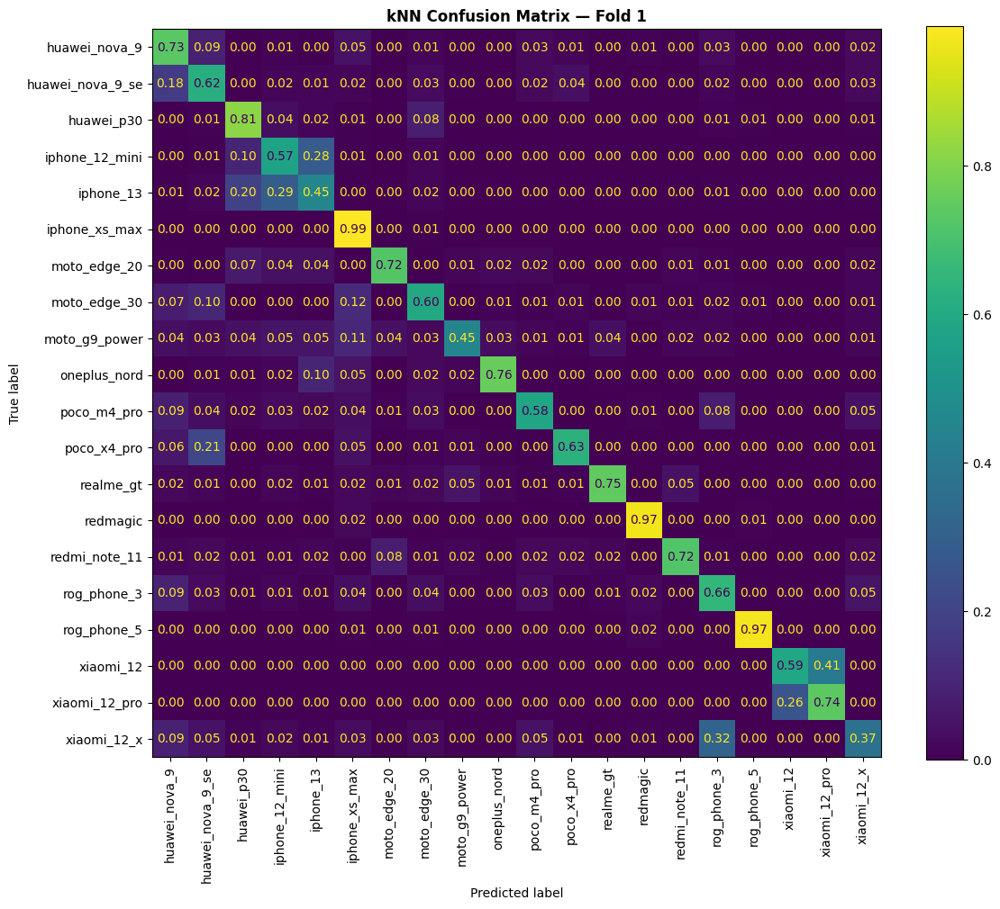

Confusion matrix saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/cm_knn_fold_1.png
Fold 1 — kNN Accuracy: 68.4851%

  FOLD 2/3
Total batch size: 128
Distinct classes in the batch: 16
Class     Name                   # Samples
------------------------------------------
0         huawei_nova_9                  8
2         huawei_p30                     8
3         iphone_12_mini                 8
4         iphone_13                      8
5         iphone_xs_max                  8
6         moto_edge_20                   8
7         moto_edge_30                   8
8         moto_g9_power                  8
9         oneplus_nord                   8
11        poco_x4_pro                    8
12        realme_gt                      8
13        redmagic                       8
14        redmi_note_11                  8
15        rog_phone_3                    8
17        xiaomi_12                      8
18        xiaomi_12_pro                  8

 Al

Epoch  8/8: 100%|██████████| 183/183 [01:11<00:00,  2.55it/s, train_loss=5.2207, valid_loss=5.0780]


Fold 2: using best checkpoint (epoch 8, valid_loss=5.0780)
train embeddings: 23512
val_embeddings: 21312


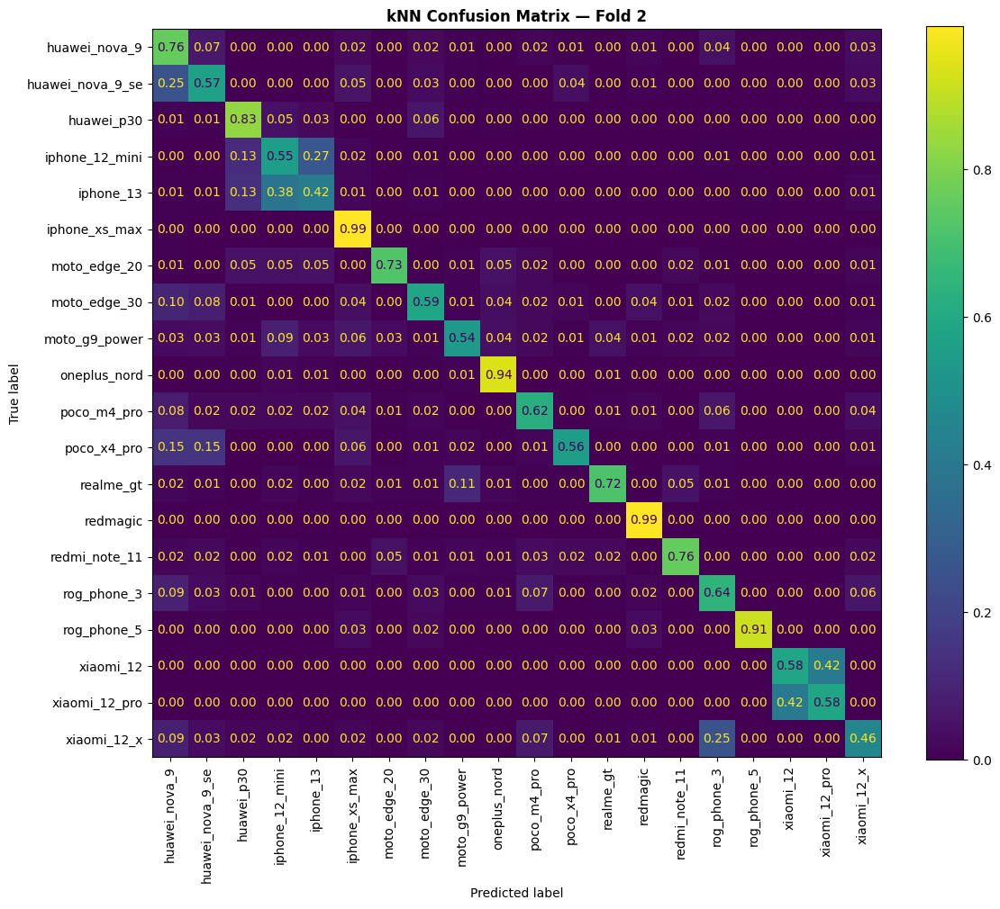

Confusion matrix saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/cm_knn_fold_2.png
Fold 2 — kNN Accuracy: 68.6937%

  FOLD 3/3
Total batch size: 128
Distinct classes in the batch: 16
Class     Name                   # Samples
------------------------------------------
0         huawei_nova_9                  8
2         huawei_p30                     8
3         iphone_12_mini                 8
4         iphone_13                      8
5         iphone_xs_max                  8
6         moto_edge_20                   8
7         moto_edge_30                   8
8         moto_g9_power                  8
9         oneplus_nord                   8
10        poco_m4_pro                    8
14        redmi_note_11                  8
15        rog_phone_3                    8
16        rog_phone_5                    8
17        xiaomi_12                      8
18        xiaomi_12_pro                  8
19        xiaomi_12_x                    8

 Al

Epoch  8/8: 100%|██████████| 181/181 [01:11<00:00,  2.53it/s, train_loss=5.1743, valid_loss=5.5026]


Fold 3: using best checkpoint (epoch 7, valid_loss=5.3787)
train embeddings: 23277
val_embeddings: 21503


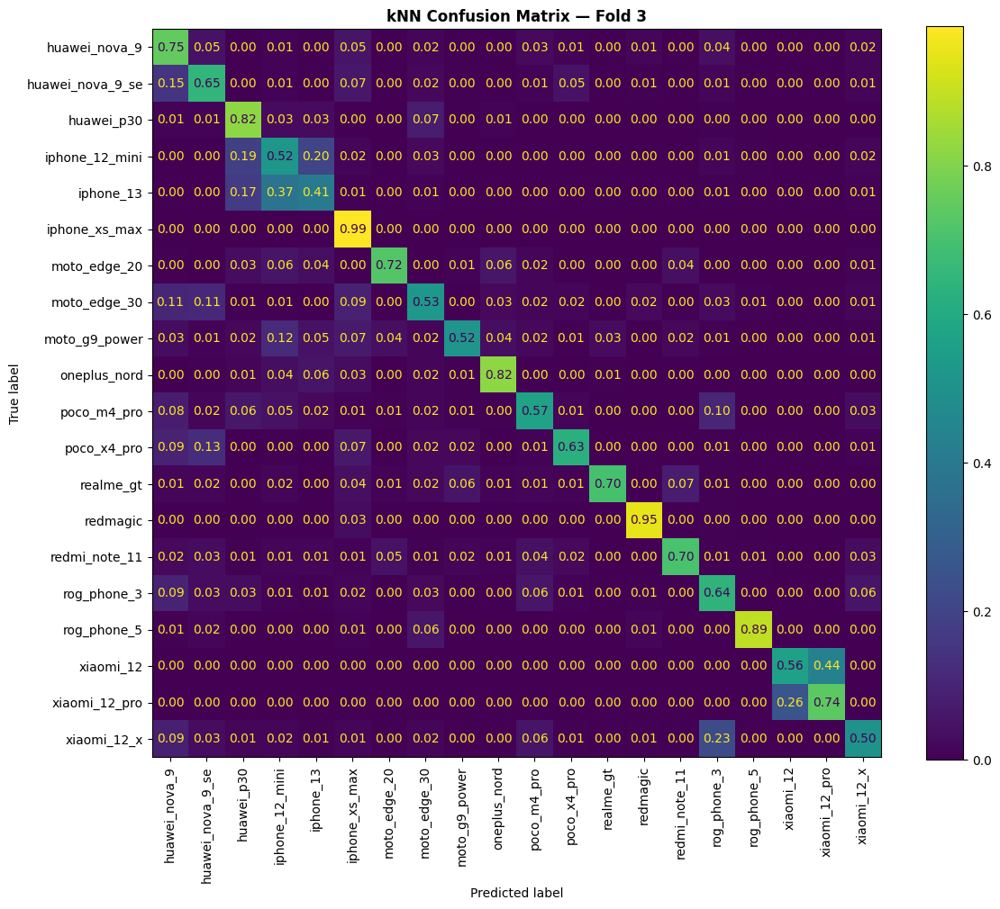

Confusion matrix saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/cm_knn_fold_3.png
Fold 3 — kNN Accuracy: 68.1672%

===== K-FOLD SUMMARY =====
Fold 1: kNN=68.4851% | val_loss=5.1272
Fold 2: kNN=68.6937% | val_loss=5.0780
Fold 3: kNN=68.1672% | val_loss=5.5026

kNN Accuracy: 68.4487% ± 0.2165%
Val Loss:     5.2359 ± 0.1897


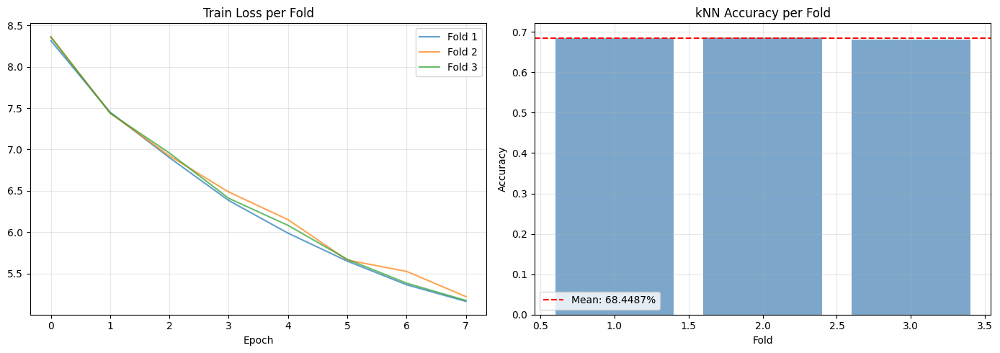

In [ ]:

###########################################
"""K-Fold execution"""
###########################################

# K-Fold to validate that the model generalizes
# Execution
if SKIP_IF_KFOLD_COMPLETE and os.path.exists(kfold_results_path):
    print(f"K-Fold already executed, loading from {kfold_results_path}")
    with open(kfold_results_path, "rb") as f:
        kfold_data = pickle.load(f)
    fold_histories, fold_metrics = kfold_data["fold_histories"], kfold_data["fold_metrics"]
else:
    fold_histories, fold_metrics = train_with_kfold(
        device_to_label, output_path, device, n_splits=N_SPLITS, out_dim=OUT_DIM, epochs=EPOCHS_KFOLD, lr=LR
    )
    with open(kfold_results_path, "wb") as f:
        pickle.dump({"fold_histories": fold_histories, "fold_metrics": fold_metrics}, f,
                    protocol=pickle.HIGHEST_PROTOCOL)
visualize_kfold_results(fold_histories, fold_metrics)

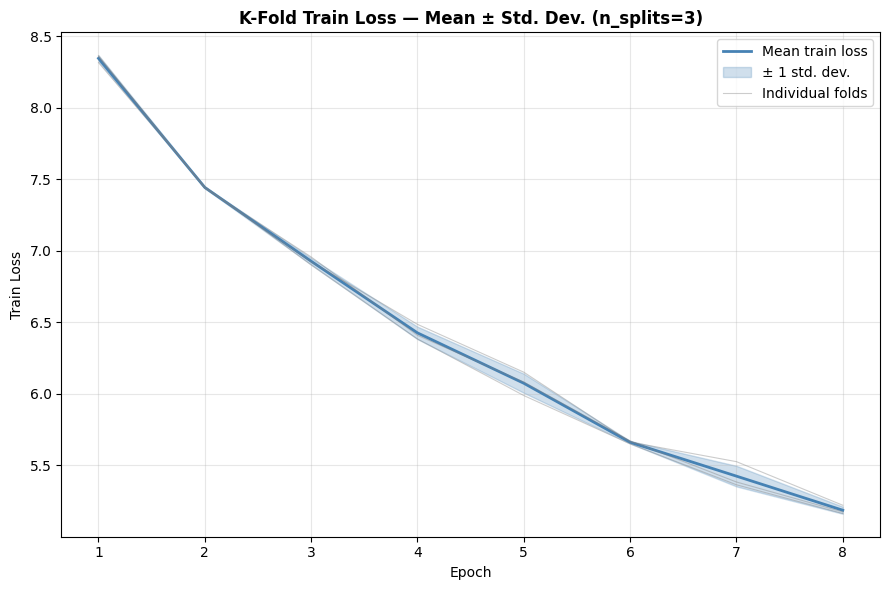

K-Fold train loss mean/std plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/kfold_train_loss_stats_euclidean_uv_epochs840_val15_win1_cosface_outdim64.png


In [ ]:
###########################################
"""K-Fold Train Loss — Mean and Standard Deviation Across Folds"""
###########################################

def plot_kfold_train_loss_mean_std(fold_histories, output_path=kfold_train_loss_stats_png_path):
    """
    Aggregates the per-epoch train loss across all folds and plots the
    mean curve with a shaded +/- 1 standard deviation band. Folds are
    aligned by epoch index; if folds stopped early (early stopping) at
    different epochs, the curve is truncated to the shortest fold so the
    mean/std at every epoch is computed over the same number of folds.
    """
    train_loss_per_fold = [np.asarray(history['train_loss'], dtype=np.float64) for history in fold_histories]
    min_common_epochs = min(len(loss_curve) for loss_curve in train_loss_per_fold)

    if min_common_epochs < max(len(loss_curve) for loss_curve in train_loss_per_fold):
        print(f"Note: folds have different lengths due to early stopping; "
              f"truncating to the shortest common length ({min_common_epochs} epochs).")

    train_loss_matrix = np.stack([loss_curve[:min_common_epochs] for loss_curve in train_loss_per_fold], axis=0)
    epoch_mean = train_loss_matrix.mean(axis=0)
    epoch_std = train_loss_matrix.std(axis=0)
    epochs_range = np.arange(1, min_common_epochs + 1)

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(epochs_range, epoch_mean, color='steelblue', linewidth=2, label='Mean train loss')
    ax.fill_between(epochs_range, epoch_mean - epoch_std, epoch_mean + epoch_std,
                     color='steelblue', alpha=0.25, label='± 1 std. dev.')

    for fold_index, loss_curve in enumerate(train_loss_per_fold):
        ax.plot(np.arange(1, len(loss_curve) + 1), loss_curve, color='gray',
                 linewidth=0.8, alpha=0.4, label='Individual folds' if fold_index == 0 else None)

    ax.set_title(f'K-Fold Train Loss — Mean ± Std. Dev. (n_splits={len(fold_histories)})', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Train Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_path, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
    print(f"K-Fold train loss mean/std plot saved to {output_path}")

    return epoch_mean, epoch_std

kfold_train_loss_mean, kfold_train_loss_std = plot_kfold_train_loss_mean_std(fold_histories)

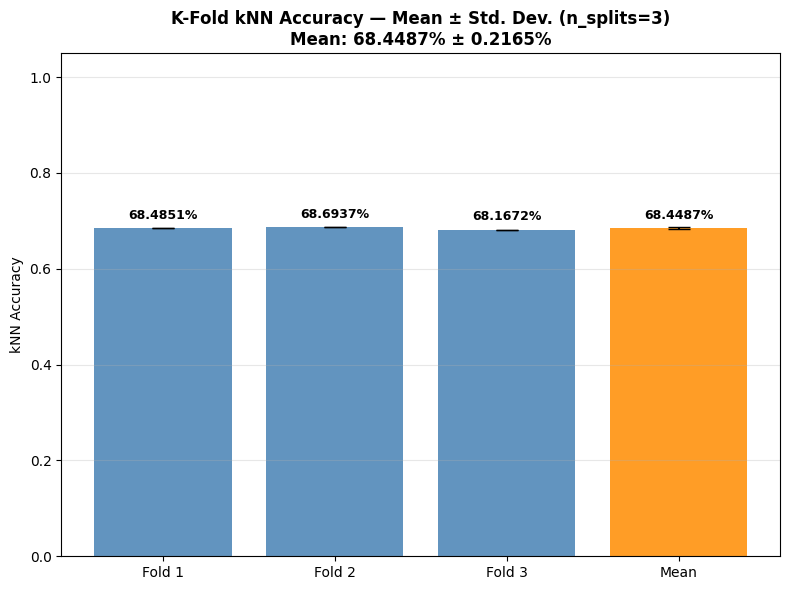

K-Fold kNN accuracy mean/std plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/kfold_knn_accuracy_stats_euclidean_uv_epochs840_val15_win1_cosface_outdim64.png


In [ ]:
###########################################
"""K-Fold kNN Accuracy — Mean and Standard Deviation Across Folds"""
###########################################

def plot_kfold_knn_accuracy_mean_std(fold_metrics, output_path=kfold_knn_accuracy_stats_png_path):
    """
    Summarizes the per-fold kNN validation accuracy with a bar chart:
    one bar per fold plus a reference bar for the aggregate mean, with
    the standard deviation shown as an error bar on the mean.
    """
    fold_labels = [f"Fold {m['fold']}" for m in fold_metrics]
    fold_accuracies = np.array([m['knn_accuracy'] for m in fold_metrics], dtype=np.float64)

    accuracy_mean = fold_accuracies.mean()
    accuracy_std = fold_accuracies.std()

    bar_labels = fold_labels + ['Mean']
    bar_values = np.append(fold_accuracies, accuracy_mean)
    bar_errors = np.append(np.zeros_like(fold_accuracies), accuracy_std)
    bar_colors = ['steelblue'] * len(fold_accuracies) + ['darkorange']

    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(bar_labels, bar_values, yerr=bar_errors, color=bar_colors, alpha=0.85, capsize=8)

    for bar, value in zip(bars, bar_values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f'{value:.4%}',
                ha='center', fontweight='bold', fontsize=9)

    ax.set_ylabel('kNN Accuracy')
    ax.set_ylim(0, 1.05)
    ax.set_title(f'K-Fold kNN Accuracy — Mean ± Std. Dev. (n_splits={len(fold_metrics)})\n'
                 f'Mean: {accuracy_mean:.4%} ± {accuracy_std:.4%}', fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_path, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
    print(f"K-Fold kNN accuracy mean/std plot saved to {output_path}")

    return accuracy_mean, accuracy_std

kfold_knn_accuracy_mean, kfold_knn_accuracy_std = plot_kfold_knn_accuracy_mean_std(fold_metrics)

In [ ]:

###########################################
"""Final model execution"""
###########################################
torch.cuda.empty_cache()
#del final_training_dataset
gc.collect()

# Step 2: Final model with all training data

if SKIP_IF_FINAL_MODEL_EXISTS and os.path.exists(os.path.join(output_path, f"siamese_model_{run_name}.pth")):
    #model, global_mean, global_std, history = load_model_and_state(output_path, run_name, device)
    model, history = load_model_and_state(output_path, run_name, device)
else:
    model, history, _ = train_final_model(output_path, device_to_label, out_dim=OUT_DIM, epochs=EPOCHS, lr=LR) # global_mean, global_std, _ = train_final_model(output_path, device_to_label, out_dim=OUT_DIM, epochs=EPOCHS, lr=LR)
    model.to(device)
    with open(os.path.join(output_path, f"final_model_history_{run_name}.pkl"), "wb") as f:
        pickle.dump(history, f, protocol=pickle.HIGHEST_PROTOCOL)

Final-model holdout windows already exist, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/final_holdout_windows_euclidean_uv_epochs840_val15_win1_cosface_outdim64.pkl
===== Training on cuda device =====
Resuming training from epoch 55 (checkpoint: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/final_checkpoint_euclidean_uv_epochs840_val15_win1_cosface_outdim64.pt)


Epoch 60/60: 100%|██████████| 234/234 [01:18<00:00,  2.98it/s, train_loss=0.3340, valid_loss=1.0843]

Final model: using best checkpoint (epoch 50, valid_loss=1.0739)


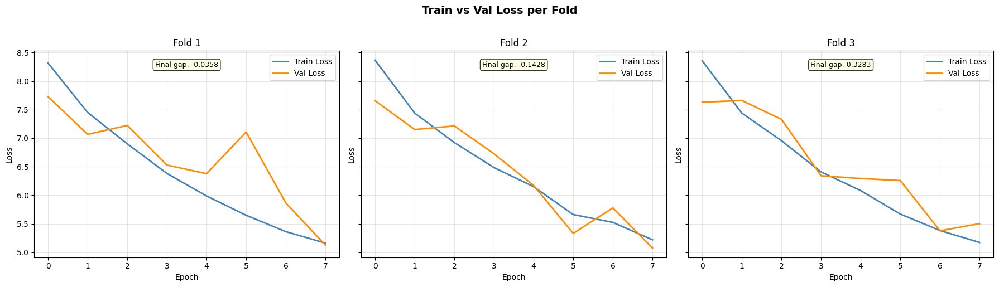

Plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/train_vs_val_loss_kfold.png


In [ ]:

###########################################
"""Train vs Val loss comparison per fold"""
###########################################

def plot_train_vs_val_loss_kfold(fold_histories, output_path=output_path):
    num_folds = len(fold_histories)
    fig, axes = plt.subplots(1, num_folds, figsize=(6*num_folds, 5), sharey=True)
    if num_folds == 1:
        axes = [axes]

    for i, history in enumerate(fold_histories):
        axes[i].plot(history['train_loss'], label='Train Loss', color='steelblue', linewidth=2)
        axes[i].plot(history['valid_loss'], label='Val Loss', color='darkorange', linewidth=2)
        axes[i].set_title(f'Fold {i+1}')
        axes[i].set_xlabel('Epoch')
        axes[i].set_ylabel('Loss')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)

        final_gap = history['valid_loss'][-1] - history['train_loss'][-1]
        axes[i].text(0.5, 0.95, f'Final gap: {final_gap:.4f}',
                     transform=axes[i].transAxes, ha='center', va='top', fontsize=9,
                     bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    plt.suptitle('Train vs Val Loss per Fold', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()

    output_file_path = os.path.join(output_path, "train_vs_val_loss_kfold.png")
    plt.savefig(output_file_path, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
    print(f"Plot saved to {output_file_path}")

plot_train_vs_val_loss_kfold(fold_histories)

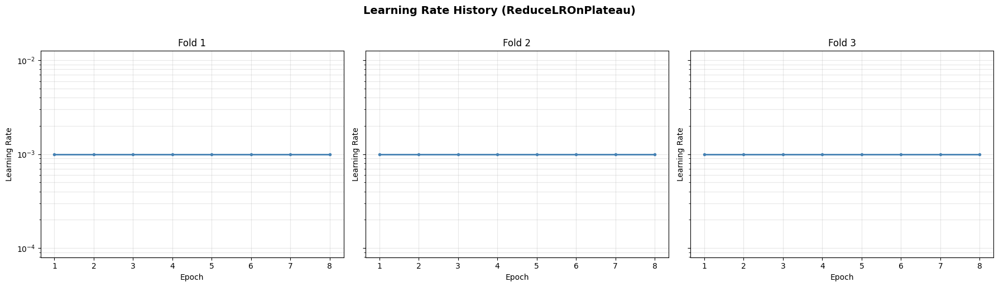

LR plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/lr_history.png


In [ ]:

###########################################
"""Learning Rate History (ReduceLROnPlateau verification)"""
###########################################

def plot_lr_history(fold_histories, final_history=None, output_path=output_path):
    num_folds = len(fold_histories)
    num_panels = num_folds + (1 if final_history is not None else 0)

    fig, axes = plt.subplots(1, num_panels, figsize=(6*num_panels, 5), sharey=True)
    if num_panels == 1:
        axes = [axes]

    def _plot_lr(ax, lr_history, title):
        epochs_range = range(1, len(lr_history) + 1)
        ax.plot(epochs_range, lr_history, color='steelblue', linewidth=2, marker='o', markersize=3)

        # Mark the epochs where the LR changed (that's where the scheduler acted)
        for i in range(1, len(lr_history)):
            if lr_history[i] != lr_history[i - 1]:
                ax.axvline(x=i + 1, color='red', linestyle='--', alpha=0.6)
                ax.scatter([i + 1], [lr_history[i]], color='red', s=60, zorder=5)

        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Learning Rate')
        ax.set_yscale('log')
        ax.grid(True, alpha=0.3, which='both')

    for i, history in enumerate(fold_histories):
        _plot_lr(axes[i], history['lr'], f'Fold {i+1}')

    if final_history is not None:
        _plot_lr(axes[-1], final_history['lr'], 'Final Model')

    plt.suptitle('Learning Rate History (ReduceLROnPlateau)', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()

    output_file_path = os.path.join(output_path, "lr_history.png")
    plt.savefig(output_file_path, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()
    print(f"LR plot saved to {output_file_path}")
plot_lr_history(fold_histories)

Full-audio train windows already exist, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/full_audio_train_windows.pkl


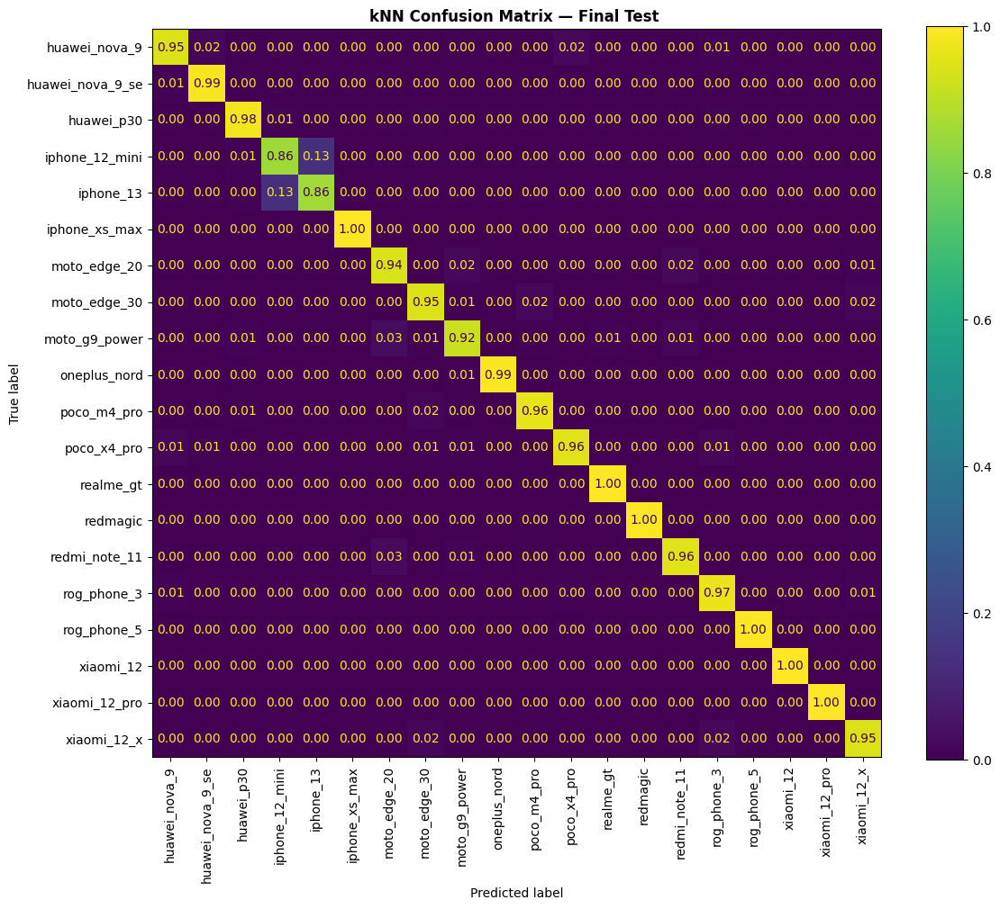

Confusion matrix saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/cm_knn_test_euclidean_uv_epochs840_val15_win1_cosface_outdim64.png
 k-NN precision (final model vs test set): 96.1945%
Final model saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/siamese_model_euclidean_uv_epochs840_val15_win1_cosface_outdim64.pth


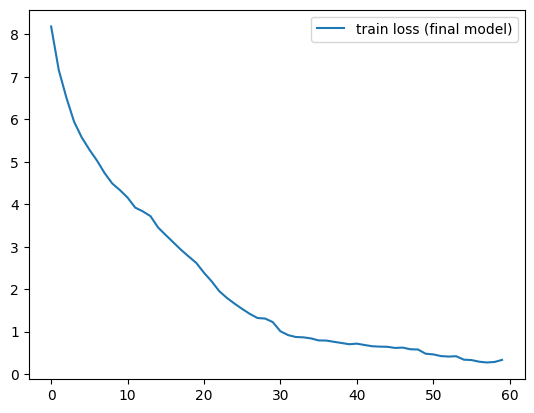

In [ ]:

###########################################
"""kNN Evaluation"""
###########################################
if 'model' not in dir():

    #model, global_mean, global_std, history = load_model_and_state(output_path, run_name, device)
    model, history = load_model_and_state(output_path, run_name, device)
model.to(device)

if 'history' not in dir():
    with open(final_history_path, "rb") as f:
        history = pickle.load(f)
# Generate TRAIN windows (all data used to train the final model)
# Generate TEST windows (the 10% held out at the start, never seen during training)

# Ensure final_training_dataset is available regardless of execution order
if 'final_training_dataset' not in dir():
    print(f"final_training_dataset not in memory, loading from {windowed_dataset_path}")
    with open(windowed_dataset_path, "rb") as f:
        final_training_dataset = pickle.load(f)

train_embedding_loader = DataLoader(
    EmbeddingExtractionDataset(final_training_dataset, device_to_label),#, global_mean, global_std),
    batch_size=BATCH_SIZE, collate_fn=collate_variable_length_spectrograms
)
val_embedding_loader = DataLoader(
    EmbeddingExtractionDataset(final_test_windows, device_to_label),#, global_mean, global_std),
    batch_size=BATCH_SIZE, collate_fn=collate_variable_length_spectrograms
)

# The model and device are already ready from train_final_model()
train_embeddings, train_labels = extract_embeddings(model, train_embedding_loader, device)
val_embeddings, val_labels = extract_embeddings(model, val_embedding_loader, device)
if REFERENCE_EMBEDDINGS_USE_FULL_AUDIO:
    if os.path.exists(full_audio_train_windows_path):
        print(f"Full-audio train windows already exist, loading from {full_audio_train_windows_path}")
        with open(full_audio_train_windows_path, "rb") as f:
            full_audio_train_windows = pickle.load(f)
    else:
        full_audio_train_windows = generate_splicing_windows_streaming(
            raw_train_audios, sr=SR, apply_jitter=APPLY_JITTER_EVAL
        )
        with open(full_audio_train_windows_path, "wb") as f:
            pickle.dump(full_audio_train_windows, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"Full-audio train windows saved to {full_audio_train_windows_path}")

    full_audio_train_loader = DataLoader(
        EmbeddingExtractionDataset(full_audio_train_windows, device_to_label),
        batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_variable_length_spectrograms
    )
    reference_embeddings, reference_labels = extract_embeddings(model, full_audio_train_loader, device)
    del full_audio_train_windows, full_audio_train_loader
    gc.collect()
else:
    reference_embeddings, reference_labels = train_embeddings, train_labels
knn_model = KNeighborsClassifier(n_neighbors=KNN_NEIGHBORS, metric="euclidean")
#knn_model.fit(train_embeddings.numpy(), train_labels.numpy())
knn_model.fit(reference_embeddings.numpy(), reference_labels.numpy())
predictions = knn_model.predict(val_embeddings.numpy())
knn_accuracy = accuracy_score(val_labels.numpy(), predictions)
plot_knn_confusion_matrix(
    val_labels.numpy(), predictions, id_to_device,
    title=f"kNN Confusion Matrix — Final Test ",
    file_name=f"cm_knn_test_{run_name}.png"
)
print(f" k-NN precision (final model vs test set): {knn_accuracy:.4%}")

# Step 3: Save
# Saved directly to your Drive (output_path) so it isn't lost when the runtime closes.
torch.save({
    'model_state_dict': model.state_dict(),
    #'mean_global': global_mean,
    #'std_global': global_std,
}, save_path)
print(f"Final model saved to {save_path}")
# If you prefer to download straight to your pc instead of Drive, uncomment:
# torch.save({...}, "siamese_model.pth"); files.download("siamese_model.pth")


# Step 4: Visualize final model loss
plt.plot(history['train_loss'], label='train loss (final model)')
plt.legend()
plt.show()

In [ ]:
print(model.training)

False


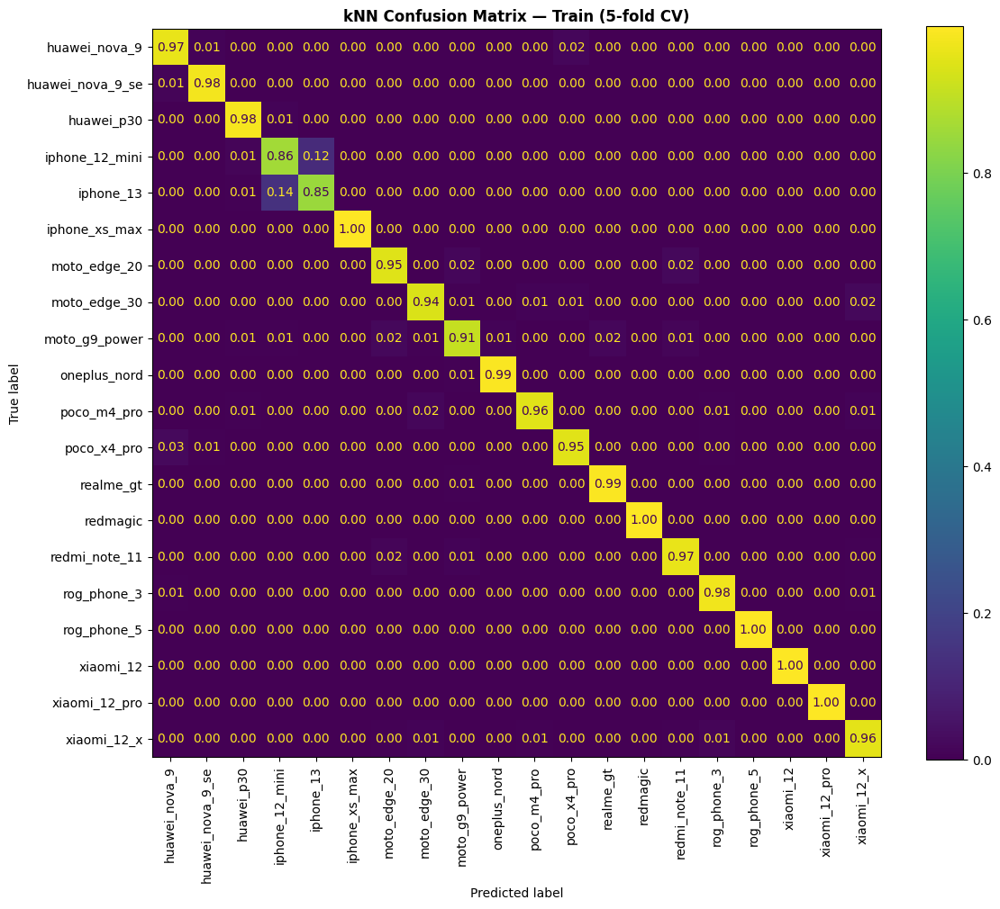

Confusion matrix saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/cm_knn_train_cv_euclidean_uv_epochs840_val15_win1_cosface_outdim64.png


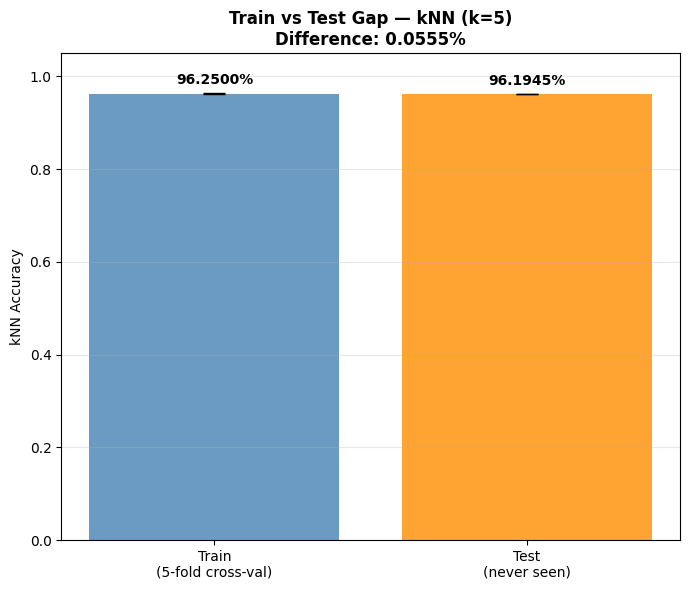

Train accuracy (5-fold CV): 96.2500% ± 0.0757%
Test accuracy (real):       96.1945%
Gap (train - test):         0.0555%
Plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/gap_train_test_accuracy.png


In [ ]:
###########################################
"""Train vs Test accuracy gap (kNN)"""
###########################################

def plot_train_test_accuracy_gap(train_embeddings, train_labels, val_embeddings, val_labels,
                                   knn_neighbors=KNN_NEIGHBORS, output_path=output_path):
    """
    Train accuracy is computed via cross-validation WITHIN the train set
    itself (not with knn.predict directly on train, because there each
    point would find itself as its nearest neighbor, giving an artificial
    ~100%).
    """
    knn_model = KNeighborsClassifier(n_neighbors=knn_neighbors, metric='euclidean')

    cv_splitter = StratifiedKFold(n_splits=N_SPLITS_CV_GAP, shuffle=True, random_state=RANDOM_SEED)
    train_cv_predictions = cross_val_predict(knn_model, train_embeddings.numpy(), train_labels.numpy(), cv=cv_splitter)
    train_cv_accuracy = cross_val_score(knn_model, train_embeddings.numpy(), train_labels.numpy(), cv=cv_splitter, scoring='accuracy')
    train_accuracy_mean = train_cv_accuracy.mean()
    train_accuracy_std = train_cv_accuracy.std()

    # Real test accuracy: kNN model trained with ALL of train, evaluated on never-seen test
    knn_model.fit(train_embeddings.numpy(), train_labels.numpy())
    test_predictions = knn_model.predict(val_embeddings.numpy())
    test_accuracy = accuracy_score(val_labels.numpy(), test_predictions)
    plot_knn_confusion_matrix(
    train_labels.numpy(), train_cv_predictions, id_to_device,
    title="kNN Confusion Matrix — Train (5-fold CV)",
    file_name=f"cm_knn_train_cv_{run_name}.png"
    )
    fig, ax = plt.subplots(figsize=(7, 6))
    bars = ax.bar(['Train\n(5-fold cross-val)', 'Test\n(never seen)'],
                     [train_accuracy_mean, test_accuracy],
                     yerr=[train_accuracy_std, 0],
                     color=['steelblue', 'darkorange'], alpha=0.8, capsize=8)
    for bar, value in zip(bars, [train_accuracy_mean, test_accuracy]):
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.02, f'{value:.4%}',
                ha='center', fontweight='bold')

    ax.set_ylabel('kNN Accuracy')
    ax.set_ylim(0, 1.05)
    ax.set_title(f'Train vs Test Gap — kNN (k={knn_neighbors})\n'
                 f'Difference: {(train_accuracy_mean - test_accuracy):.4%}',
                 fontweight='bold')
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()

    output_file_path = os.path.join(output_path, "gap_train_test_accuracy.png")
    plt.savefig(output_file_path, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()

    print(f"Train accuracy (5-fold CV): {train_accuracy_mean:.4%} ± {train_accuracy_std:.4%}")
    print(f"Test accuracy (real):       {test_accuracy:.4%}")
    print(f"Gap (train - test):         {(train_accuracy_mean - test_accuracy):.4%}")
    print(f"Plot saved to {output_file_path}")

    return train_accuracy_mean, test_accuracy

#train_accuracy_mean, test_accuracy = plot_train_test_accuracy_gap(train_embeddings, train_labels, val_embeddings, val_labels)
train_accuracy_mean, test_accuracy = plot_train_test_accuracy_gap(
    reference_embeddings, reference_labels, val_embeddings, val_labels
)


In [ ]:

def count_parameters(model, detail=True):
    total_params = 0
    trainable_params = 0

    if detail:
        print(f"{'Layer':<40}{'Shape':<20}{'# Parameters':>15}")
        print("-" * 75)

    for name, param in model.named_parameters():
        num_params = param.numel()
        total_params += num_params
        if param.requires_grad:
            trainable_params += num_params
        if detail:
            print(f"{name:<40}{str(tuple(param.shape)):<20}{num_params:>15,}")

    print("-" * 75)
    print(f"Total parameters:       {total_params:,}")
    print(f"Trainable parameters:    {trainable_params:,}")
    print(f"Non-trainable parameters: {total_params - trainable_params:,}")
    return total_params, trainable_params

count_parameters(model)

def count_flops_macs(model, input_shape=(1, 1, freq_bins, n_frames), device='cpu'):
    """
    Computes model FLOPs and MACs without modifying it.
    input_shape: (batch, channels, length) — adjust 128 to the actual size
                 of your spectral_feature (n_fft//2 + 1, check the real shape).
    """
    cpu_model = model.to('cpu')  # thop is more stable on CPU
    cpu_model.eval()

    dummy_input = torch.randn(input_shape)

    macs, params = profile(cpu_model, inputs=(dummy_input,), verbose=False)
    macs_formatted, params_formatted = clever_format([macs, params], "%.4f")

    flops = macs * 2  # 1 MAC ≈ 2 FLOPs

    print(f"Test input: {input_shape}")
    print(f"MACs:   {macs_formatted}  ({macs:,.0f} exact MACs)")
    print(f"FLOPs:  ≈{flops:,.0f}  (2 × MACs)")
    print(f"Params: {params_formatted}  ({int(params):,} exact parameters)")

    model.to(device)  # return the model to its original device
    return macs, flops, params

# Usage: adjust input_shape according to the actual shape of your spectral_feature
macs, flops, params = count_flops_macs(model, input_shape=(1, 1, freq_bins, n_frames), device=device)

Layer                                   Shape                  # Parameters
---------------------------------------------------------------------------
backbone.0.weight                       (64, 1, 3, 3)                   576
backbone.0.bias                         (64,)                            64
backbone.1.weight                       (64,)                            64
backbone.1.bias                         (64,)                            64
backbone.5.weight                       (128, 64, 3, 3)              73,728
backbone.5.bias                         (128,)                          128
backbone.6.weight                       (128,)                          128
backbone.6.bias                         (128,)                          128
backbone.10.weight                      (256, 128, 3, 3)            294,912
backbone.10.bias                        (256,)                          256
backbone.11.weight                      (256,)                          256
backbone.11.

In [ ]:

###########################################
"""Tensor check"""
###########################################

example_batch = next(iter(train_loader))
spectrograms, labels, _ = example_batch
# Convert the list of tensors into a single 4D tensor

print(" Batch loaded correctly:")
print(f"   - Spectrogram size: {spectrograms.shape}")  # Should be [32, 1, 128, 32]
print(f"   - Label size: {labels.shape}")          # Should be [32]
print(f"   - Example labels in this batch: {labels[:5]}")

 Batch loaded correctly:
   - Spectrogram size: torch.Size([128, 1, 1025, 22])
   - Label size: torch.Size([128])
   - Example labels in this batch: tensor([ 1, 14,  8,  6, 15])


In [ ]:
EER_MODULE_HASH_LENGTH = 8   # characters of the module digest stored with each run for traceability

In [ ]:
EER_MODULE_HASH = hashlib.sha1(
    Path(eer_evaluation_module.__file__).read_bytes()
).hexdigest()[:EER_MODULE_HASH_LENGTH]
print(f"eer_evaluation.py digest: {EER_MODULE_HASH}")

eer_evaluation.py digest: e6d600b7


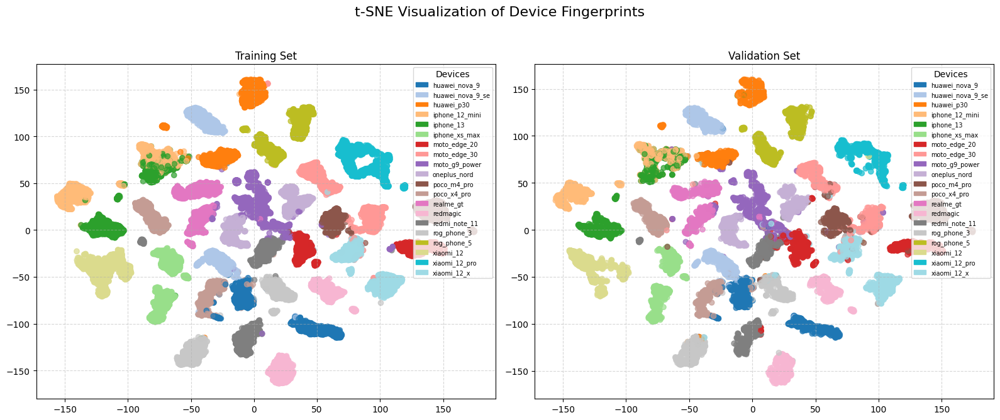

Unique devices in train_labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]
Count: 20
Unique devices in val_labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]
Count: 20


In [ ]:
###########################################
"""Training visualization"""
###########################################


# Invert the dictionary to get the name from the number

def present_names(labels_array):
    present_classes = sorted(np.unique(labels_array))
    return [id_to_device[c] for c in present_classes]

# 1. Combine the embeddings so t-SNE projects them onto the same map
all_embeddings = np.concatenate([train_embeddings.numpy(), val_embeddings.numpy()], axis=0)
num_train = len(train_embeddings)

# 2. Configure t-SNE and transform everything together
tsne_model = TSNE(n_components=TSNE_N_COMPONENTS, random_state=RANDOM_SEED, init='pca', learning_rate='auto', max_iter=TSNE_N_ITER, perplexity=TSNE_PERPLEXITY)
all_tsne_coords = tsne_model.fit_transform(all_embeddings)

# 3. Split the coordinates back apart for plotting
train_tsne_coords = all_tsne_coords[:num_train]
val_tsne_coords = all_tsne_coords[num_train:]

# 4. visualization
def manual_legend(ax, labels_array, cmap_name="Set1", total_classes=len(device_to_label)):
    present_classes = sorted(np.unique(labels_array))
    colormap = matplotlib.colormaps[cmap_name].resampled(total_classes)
    legend_handles = [
        mpatches.Patch(color=colormap(c / (total_classes - 1)), label=id_to_device[c])
        for c in present_classes
    ]
    ax.legend(handles=legend_handles, title="Devices", fontsize=7, loc='best', ncol=1)

# 4. visualization
tsne_figure = plt.figure(figsize=(16, 7))
plt.suptitle("t-SNE Visualization of Device Fingerprints", fontsize=16)

total_classes = len(device_to_label)

###########################################
"""t-SNE Visualization — Device Fingerprints"""
###########################################

#Training set subplot
ax_train = tsne_figure.add_subplot(1, 2, 1)
scatter_train = ax_train.scatter(
    train_tsne_coords[:, 0], train_tsne_coords[:, 1],
    c=train_labels.numpy(), cmap="tab20",
    vmin=0, vmax=total_classes - 1, alpha=0.7
)
manual_legend(ax_train, train_labels.numpy(), cmap_name="tab20", total_classes=total_classes)
ax_train.set_title("Training Set")
ax_train.grid(True, linestyle='--', alpha=0.5)

# Validation (Test) plot
ax_val = tsne_figure.add_subplot(1, 2, 2)
scatter_val = ax_val.scatter(
    val_tsne_coords[:, 0], val_tsne_coords[:, 1],
    c=val_labels.numpy(), cmap="tab20",
    vmin=0, vmax=total_classes - 1, alpha=0.7
)
manual_legend(ax_val, val_labels.numpy(), cmap_name="tab20", total_classes=total_classes)
ax_val.set_title("Validation Set")
ax_val.grid(True, linestyle='--', alpha=0.5)

tsne_figure.tight_layout(rect=[0, 0.03, 1, 0.95])

tsne_figure.savefig(tsne_png_path, bbox_inches='tight', dpi=FIGURE_DPI)

plt.show()

tsne_data = {
    'train_tsne': train_tsne_coords,
    'val_tsne': val_tsne_coords,
    'train_labs': train_labels.numpy(),
    'val_labs': val_labels.numpy(),
    'png_path': tsne_png_path,
}

print("Unique devices in train_labels:", sorted(np.unique(train_labels.numpy())))
print("Count:", len(np.unique(train_labels.numpy())))

print("Unique devices in val_labels:", sorted(np.unique(val_labels.numpy())))
print("Count:", len(np.unique(val_labels.numpy())))

In [ ]:

###########################################
"""Euclidean distance"""
###########################################
def detect_splice_point(embeddings, timestamps, threshold=THRESHOLD_DEFAULT):
    """
    Analyzes the distance between consecutive windows to find the jump.
    """
    distances = []
    detected_point = None

    for i in range(1, len(embeddings)):
        # Distance between the current window's embedding and the previous one
        d = np.linalg.norm(embeddings[i] - embeddings[i - 1])
        distances.append(d)

        # If the distance exceeds the threshold, mark the second
        if d > threshold and detected_point is None:
            detected_point = timestamps[i]

    return detected_point, distances

In [ ]:

def generate_forensic_report(suspect_audio, model, device, sr=SR,
                              win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, threshold=THRESHOLD_DEFAULT,
                              save_pdf=True, compute_entropy_comparison=False, entropy_window=None,
                              use_pairwise_distance: bool = False,
                              distance_metric: str = "euclidean", VI: np.ndarray = None,
                              norm_ord=None):#, mean_global=None, std_global=None):
    """
    Given a new audio file, generates a complete forensic report with:
    1. Distance-over-time plot
    2. Similarity heatmap between segments
    3. t-SNE of the audio compared against known reference audio files
    """

    # 1. Segment the suspect audio into windows
    win_len = int(win_sec * sr)
    hop_len = int(hop_sec * sr)
    windows, timestamps = [], []

    for start in range(0, len(suspect_audio) - win_len, hop_len):
      window = suspect_audio[start:start + win_len]
      feature_2d = extract_stft_power_spectrogram_db(window, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH_FFT, freq_mask=TRAIN_FREQUENCY_MASK)
      normalized_feature = (feature_2d - np.mean(feature_2d)) / (np.std(feature_2d) + 1e-8)
      #normalized_feature = (normalized_feature - mean_global) / (std_global + 1e-8)
      windows.append(normalized_feature)
      timestamps.append(start / sr)

    # 2. Extract embeddings
    model.eval()
    specs = torch.tensor(np.array(windows), dtype=torch.float32).unsqueeze(1).to(device)
    with torch.no_grad():
        embeddings = model(specs).cpu().numpy()

    # 3. Compute distances between consecutive windows
    if use_pairwise_distance:
        distances = [_pairwise_distance(embeddings[i], embeddings[i - 1], distance_metric=distance_metric, VI=VI)
                     for i in range(1, len(embeddings))]
    else:
        distances = [np.linalg.norm(embeddings[i] - embeddings[i - 1], ord=norm_ord) for i in range(1, len(embeddings))]
    distance_timestamps = timestamps[1:]

    # Detect splice point
    max_idx = int(np.argmax(distances))
    splice_time = distance_timestamps[max_idx]
    has_splice = distances[max_idx] > threshold

    # Entropy-weighted candidate (optional comparison against the baseline argmax candidate)
    entropy_candidate = None
    if compute_entropy_comparison:
        if entropy_window is None:
            raise ValueError("entropy_window must be provided when compute_entropy_comparison=True")
        entropy_candidate = entropy_weighted_localization(
            np.array(distances), distance_timestamps, entropy_window=entropy_window
        )
        entropy_candidate['has_splice_entropy'] = entropy_candidate['entropy_max_distance'] > threshold

    # 4. Similarity matrix between all segments
    num_windows = len(embeddings)
    similarity_matrix = np.zeros((num_windows, num_windows))
    for i in range(num_windows):
        for j in range(num_windows):
            if use_pairwise_distance:
                similarity_matrix[i, j] = _pairwise_distance(embeddings[i], embeddings[j], distance_metric=distance_metric, VI=VI)
            else:
                similarity_matrix[i, j] = np.linalg.norm(embeddings[i] - embeddings[j], ord=norm_ord)

    # 5. Build the visual report
    fig = plt.figure(figsize=(18, 14))
    fig.suptitle(
        f"AUDIO AUTHENTICITY FORENSIC REPORT\n"
        f"Analysis date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
        fontsize=14, fontweight='bold'
    )
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

    # Panel 1: Waveform with splice mark
    ax1 = fig.add_subplot(gs[0, :])  # takes the full width
    audio_time = np.linspace(0, len(suspect_audio) / sr, len(suspect_audio))
    ax1.plot(audio_time, suspect_audio, color='steelblue', linewidth=0.5, alpha=0.8)
    if has_splice:
        ax1.axvline(x=splice_time, color='red', linewidth=2, linestyle='--',
                    label=f'Splice detected: {splice_time:.4f}s')
        ax1.fill_betweenx(
            [suspect_audio.min(), suspect_audio.max()],
            splice_time - hop_sec, splice_time + hop_sec,
            alpha=0.2, color='red'
        )
    if entropy_candidate is not None and entropy_candidate['has_splice_entropy']:
      ax1.axvline(x=entropy_candidate['entropy_detected_time_s'], color='magenta', linewidth=2, linestyle=':',
                label=f'Entropy-weighted candidate: {entropy_candidate["entropy_detected_time_s"]:.4f}s')
    ax1.set_title('Waveform — Analyzed Audio Signal', fontweight='bold')
    ax1.set_xlabel('Time (seconds)')
    ax1.set_ylabel('Amplitude')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)

    # Panel 2: Distances over time
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(distance_timestamps, distances, color='darkorange', linewidth=1.5, marker='o',
              markersize=3, label='Distance between segments')
    ax2.axhline(y=threshold, color='gray', linestyle=':', linewidth=1.5,
                label=f'Threshold = {threshold}')
    if has_splice:
        ax2.axvline(x=splice_time, color='red', linewidth=2, linestyle='--',
                    label=f'Max peak: {splice_time:.4f}s')
        ax2.scatter([splice_time], [distances[max_idx]],
                    color='red', s=100, zorder=5)

    ax2.set_title('Euclidean Distance Between Consecutive Segments', fontweight='bold')
    ax2.set_xlabel('Time (seconds)')
    ax2.set_ylabel('Distance in embedding space')
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    # Panel 3: Similarity heatmap
    ax3 = fig.add_subplot(gs[1, 1])
    im = ax3.imshow(similarity_matrix, cmap='hot_r', aspect='auto',
                     extent=[timestamps[0], timestamps[-1],
                             timestamps[-1], timestamps[0]])
    plt.colorbar(im, ax=ax3, label='Euclidean distance')
    if has_splice:
        ax3.axvline(x=splice_time, color='cyan', linewidth=1.5, linestyle='--',
                    label=f'Splice: {splice_time:.4f}s')
        ax3.axhline(y=splice_time, color='cyan', linewidth=1.5, linestyle='--')
    ax3.set_title('Similarity Map Between Segments\n(darker = more similar)',
                  fontweight='bold')
    ax3.set_xlabel('Time (seconds)')
    ax3.set_ylabel('Time (seconds)')

    ax3.legend(fontsize=9)

    # Textual verdict
    if has_splice:
        verdict = (f" SPLICE DETECTED at t = {splice_time:.4f}s  "
                     f"(distance = {distances[max_idx]:.4f}, threshold = {threshold})")
        verdict_color = 'red'
    else:
        verdict = f" AUTHENTIC AUDIO — max distance {max(distances):.4f} < threshold {threshold}"
        verdict_color = 'green'

    if entropy_candidate is not None:
        if entropy_candidate['has_splice_entropy']:
            verdict += (
                f"\nEntropy-weighted candidate: t = {entropy_candidate['entropy_detected_time_s']:.4f}s  "
                f"(distance = {entropy_candidate['entropy_max_distance']:.4f}, "
                f"local entropy = {entropy_candidate['local_entropy_at_peak']:.4f})"
            )
        else:
            verdict += "\nEntropy-weighted candidate: no distance above threshold"

    fig.text(0.5, 0.01, verdict, ha='center', fontsize=13,
              fontweight='bold', color=verdict_color,
              bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor=verdict_color))

      # PDF saved directly to your Drive alongside the model, so it isn't lost
    if save_pdf:

        plt.savefig(pdf_path, bbox_inches='tight', dpi=FIGURE_DPI)
        print(f"Forensic report saved to {pdf_path}")
    plt.show()

    result = {
        "has_splice": has_splice,
        "splice_time_sec": splice_time if has_splice else None,
        "max_distance": float(distances[max_idx]),
        "threshold_used": threshold,
        "embeddings": embeddings,
        "timestamps": timestamps,
        "distances": distances,
    }
    if entropy_candidate is not None:
        result.update({
            "has_splice_entropy": entropy_candidate['has_splice_entropy'],
            "splice_time_sec_entropy": entropy_candidate['entropy_detected_time_s'] if entropy_candidate['has_splice_entropy'] else None,
            "max_distance_entropy": entropy_candidate['entropy_max_distance'],
            "local_entropy_at_peak": entropy_candidate['local_entropy_at_peak'],
        })
    return result

In [ ]:
###########################################
"""Peak-Localization Strategy Comparison — Raw vs Median vs Entropy vs Combined"""
###########################################
def plot_filtering_strategy_comparison(distances, timestamps, threshold, ground_truth_time_s,
                                        median_filter_kernel_size, entropy_window,
                                        output_path, run_name, dpi=FIGURE_DPI):
    """
    Compares four peak-localization strategies over the same consecutive-window
    distance sequence, to assess whether median filtering, entropy weighting, or
    their combination improves the separability between the splice-induced peak
    and off-splice noise peaks relative to the raw-distance baseline.

    Strategies
    ----------
    1. Raw distance            : unmodified Euclidean distance sequence.
    2. Median-filtered distance: raw distance smoothed with a 1D median filter.
    3. Entropy-weighted score  : distance divided by local Shannon entropy,
                                  computed on the raw sequence.
    4. Median + Entropy score  : distance divided by local Shannon entropy,
                                  computed on the median-filtered sequence.

    For each strategy, the detected candidate is the argmax of that strategy's
    curve; its timestamp is compared against `ground_truth_time_s` to report
    localization error. A dotted threshold line is drawn only for the two
    distance-domain panels (raw/median), since entropy-weighted scores are a
    unitless ratio and not directly comparable to `threshold`.

    Parameters
    ----------
    distances               : 1D array-like of consecutive-window embedding
                               distances for a single audio.
    timestamps              : timestamps aligned with `distances`.
    threshold               : calibrated distance threshold (embedding space).
    ground_truth_time_s     : known splice time for the analyzed audio.
    median_filter_kernel_size, entropy_window : forwarded from the pipeline's
                               global configuration (no hardcoded values).
    output_path, run_name   : where/how to name the exported figure.

    Returns
    -------
    dict keyed by strategy name, each holding detected_time_s, peak_value,
    and localization_error_s.
    """
    raw_distances = np.asarray(distances, dtype=np.float64)
    timestamps = np.asarray(timestamps, dtype=np.float64)

    filtered_distances = _apply_median_filter(raw_distances, median_filter_kernel_size)

    entropy_on_raw = _local_distance_entropy(raw_distances, entropy_window=entropy_window)
    score_entropy_raw = raw_distances / (entropy_on_raw + 1e-10)

    entropy_on_filtered = _local_distance_entropy(filtered_distances, entropy_window=entropy_window)
    score_combined = filtered_distances / (entropy_on_filtered + 1e-10)

    panels = [
        ("Raw Distance (Baseline)", raw_distances, True, 'darkorange'),
        (f"Median-Filtered Distance (k={median_filter_kernel_size})", filtered_distances, True, 'steelblue'),
        (f"Entropy-Weighted Score (window={entropy_window})", score_entropy_raw, False, 'seagreen'),
        ("Median-Filtered + Entropy-Weighted Score", score_combined, False, 'purple'),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.ravel()
    results = {}

    for ax, (title, curve, is_distance_domain, color) in zip(axes, panels):
        peak_idx = int(np.argmax(curve))
        detected_time_s = float(timestamps[peak_idx])
        localization_error_s = abs(detected_time_s - ground_truth_time_s)

        ax.plot(timestamps, curve, color=color, linewidth=1.2, marker='o', markersize=3,
                label='Signal')
        ax.axvline(x=ground_truth_time_s, color='green', linestyle=':', linewidth=2,
                   label=f'Ground truth: {ground_truth_time_s:.4f}s')
        ax.scatter([detected_time_s], [curve[peak_idx]], color='red', s=90, zorder=5,
                   label=f'Detected peak: {detected_time_s:.4f}s')
        if is_distance_domain:
            ax.axhline(y=threshold, color='gray', linestyle='--', linewidth=1.2,
                       label=f'Threshold = {threshold:.4f}')

        ax.set_title(f"{title}\nLocalization error: {localization_error_s:.4f}s", fontweight='bold', fontsize=10)
        ax.set_xlabel('Time (seconds)')
        ax.set_ylabel('Distance' if is_distance_domain else 'Entropy-weighted score')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

        results[title] = {
            "detected_time_s": detected_time_s,
            "peak_value": float(curve[peak_idx]),
            "localization_error_s": localization_error_s,
        }

    fig.suptitle('Splice-Peak Localization — Strategy Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    output_file_path = os.path.join(output_path, f"filtering_comparison_{run_name}.png")
    plt.savefig(output_file_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Filtering strategy comparison saved to {output_file_path}")

    return results




In [ ]:
###########################################
"""Batched Peak-Localization Strategy Comparison — Pure Test Set"""
###########################################
def _extract_consecutive_distances(suspect_audio, model, device, sr, win_sec, hop_sec, n_fft, hop_length_fft,
                                   distance_metric: str = "euclidean", VI: np.ndarray = None):
    """
    Lightweight counterpart to `generate_forensic_report`'s windowing +
    embedding-extraction steps, without any plotting. Used to batch-evaluate
    localization strategies across many test audios without generating one
    figure per audio.
    """
    win_len = int(win_sec * sr)
    hop_len = int(hop_sec * sr)
    windows, timestamps = [], []

    for start in range(0, len(suspect_audio) - win_len, hop_len):
        window = suspect_audio[start:start + win_len]
        feature_2d = extract_stft_power_spectrogram_db(window, sr=sr, n_fft=n_fft, hop_length=hop_length_fft, freq_mask=TRAIN_FREQUENCY_MASK)
        normalized_feature = (feature_2d - np.mean(feature_2d)) / (np.std(feature_2d) + 1e-8)
        windows.append(normalized_feature)
        timestamps.append(start / sr)

    model.eval()
    specs = torch.tensor(np.array(windows), dtype=torch.float32).unsqueeze(1).to(device)
    with torch.no_grad():
        embeddings = model(specs).cpu().numpy()

    distances = np.array([
        _pairwise_distance(embeddings[i], embeddings[i - 1], distance_metric=distance_metric, VI=VI)
        for i in range(1, len(embeddings))
    ])
    distance_timestamps = np.array(timestamps[1:])
    return distances, distance_timestamps


def evaluate_filtering_strategies_on_test_set(test_audios, devices, model, device,
                                               n_pairs, sr, win_sec, hop_sec, n_fft, hop_length_fft, top_db,
                                               median_filter_kernel_size, entropy_window,
                                               localization_tolerance_s,distance_metric: str = "euclidean", VI: np.ndarray = None):
    """
    Runs the four peak-localization strategies (raw / median-filtered /
    entropy-weighted-raw / median-filtered+entropy) across `n_pairs` freshly
    generated, never-seen splices sampled from the pure test set, and
    aggregates the localization error and hit rate (within
    `localization_tolerance_s`) per strategy. Scales the single-audio,
    manual-inspection comparison used in the TEST section up to a
    statistically meaningful sample of the held-out test set.
    """
    strategy_names = [
        "Raw Distance (Baseline)",
        f"Median-Filtered Distance (k={median_filter_kernel_size})",
        f"Entropy-Weighted Score (window={entropy_window})",
        "Median-Filtered + Entropy-Weighted Score",
    ]
    errors_by_strategy = {name: [] for name in strategy_names}
    hits_by_strategy = {name: [] for name in strategy_names}

    audios_by_device = {d: [a for a in test_audios if a['device'] == d] for d in devices}
    valid_devices = [d for d in devices if audios_by_device[d]]

    pairs_evaluated = 0
    max_attempts = n_pairs * 10  # guards against an infinite loop if a device pool is empty
    attempts = 0

    while pairs_evaluated < n_pairs and attempts < max_attempts:
        attempts += 1
        dev_a, dev_b = random.sample(valid_devices, 2)
        audio_info_a = random.choice(audios_by_device[dev_a])
        audio_info_b = random.choice(audios_by_device[dev_b])

        splice_result = generate_splicing_pair(audio_info_a, audio_info_b, top_db=top_db)
        if splice_result is None:
            continue

        raw_distances, dist_timestamps = _extract_consecutive_distances(
            splice_result['audio'], model, device, sr=sr, win_sec=win_sec, hop_sec=hop_sec,
            n_fft=n_fft, hop_length_fft=hop_length_fft, distance_metric=distance_metric, VI=VI
        )
        if len(raw_distances) == 0:
            continue

        filtered_distances = _apply_median_filter(raw_distances, median_filter_kernel_size)
        entropy_on_raw = _local_distance_entropy(raw_distances, entropy_window=entropy_window)
        score_entropy_raw = raw_distances / (entropy_on_raw + 1e-10)
        entropy_on_filtered = _local_distance_entropy(filtered_distances, entropy_window=entropy_window)
        score_combined = filtered_distances / (entropy_on_filtered + 1e-10)

        ground_truth_time_s = splice_result['cut_time']
        for name, curve in zip(strategy_names,
                                [raw_distances, filtered_distances, score_entropy_raw, score_combined]):
            peak_idx = int(np.argmax(curve))
            detected_time_s = float(dist_timestamps[peak_idx])
            error_s = abs(detected_time_s - ground_truth_time_s)
            errors_by_strategy[name].append(error_s)
            hits_by_strategy[name].append(error_s <= localization_tolerance_s)

        pairs_evaluated += 1

    return {
        name: {
            "mean_error_s": float(np.mean(errors_by_strategy[name])),
            "std_error_s": float(np.std(errors_by_strategy[name])),
            "hit_rate": float(np.mean(hits_by_strategy[name])),
            "n_pairs": len(errors_by_strategy[name]),
        }
        for name in strategy_names
    }


def plot_filtering_strategy_summary(summary, output_path, run_name, dpi=FIGURE_DPI):
    """
    Bar-chart summary of mean +/- std localization error and hit rate
    (within the calibrated tolerance) per strategy, aggregated over the
    pure-test-set sample produced by `evaluate_filtering_strategies_on_test_set`.
    """
    strategy_names = list(summary.keys())
    mean_errors = [summary[name]["mean_error_s"] for name in strategy_names]
    std_errors = [summary[name]["std_error_s"] for name in strategy_names]
    hit_rates = [summary[name]["hit_rate"] for name in strategy_names]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    bars = axes[0].bar(range(len(strategy_names)), mean_errors, yerr=std_errors,
                        color='steelblue', alpha=0.85, capsize=8)
    axes[0].set_xticks(range(len(strategy_names)))
    axes[0].set_xticklabels(strategy_names, rotation=20, ha='right', fontsize=8)
    axes[0].set_ylabel('Localization error (seconds)')
    axes[0].set_title('Mean ± Std. Dev. Localization Error per Strategy', fontweight='bold')
    axes[0].grid(True, axis='y', alpha=0.3)
    for bar, value in zip(bars, mean_errors):
        axes[0].text(bar.get_x() + bar.get_width() / 2, value, f'{value:.4f}s',
                     ha='center', va='bottom', fontsize=8, fontweight='bold')

    bars2 = axes[1].bar(range(len(strategy_names)), hit_rates, color='darkorange', alpha=0.85)
    axes[1].set_xticks(range(len(strategy_names)))
    axes[1].set_xticklabels(strategy_names, rotation=20, ha='right', fontsize=8)
    axes[1].set_ylabel('Hit rate (within tolerance)')
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title('Localization Hit Rate per Strategy', fontweight='bold')
    axes[1].grid(True, axis='y', alpha=0.3)
    for bar, value in zip(bars2, hit_rates):
        axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.02, f'{value:.4%}',
                     ha='center', fontweight='bold', fontsize=8)

    plt.tight_layout()
    output_file_path = os.path.join(output_path, f"filtering_strategy_summary_{run_name}.png")
    plt.savefig(output_file_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Filtering strategy summary saved to {output_file_path}")

In [ ]:
###########################################
"""Forensic Likelihood Ratio (LR) Evaluation — Final Pure Test Set"""
###########################################

def collect_audio_level_lr_scores(test_audios, devices, model, device, n_audios_test,
                                   sr, win_sec, hop_sec, n_fft, hop_length_fft, top_db, distance_metric: str = "euclidean", VI: np.ndarray = None):
    """
    Builds the audio-level score population required for LR calibration,
    using the same max-consecutive-distance statistic already used for
    splice detection.

    H1 (same-source / authentic): max distance within genuine, single-device
    audios, never spliced.
    H2 (different-source / spliced): max distance within freshly generated,
    cross-device spliced audios.

    Score convention: higher distance = stronger support for H2. This
    direction must match the sign convention used inside
    `evaluate_likelihood_ratio`.

    Returns
    -------
    h1_scores, h2_scores : np.ndarray
    """
    h1_scores = []
    for audio_info in random.sample(test_audios, min(n_audios_test, len(test_audios))):
        distances, _ = _extract_consecutive_distances(
            audio_info['audio'], model, device, sr=sr, win_sec=win_sec, hop_sec=hop_sec,
            n_fft=n_fft, hop_length_fft=hop_length_fft, distance_metric=distance_metric, VI=VI
        )
        if len(distances) == 0:
            continue
        h1_scores.append(float(np.max(distances)))

    audios_by_device = {d: [a for a in test_audios if a['device'] == d] for d in devices}
    valid_devices = [d for d in devices if audios_by_device[d]]

    h2_scores = []
    attempts, max_attempts = 0, n_audios_test * 10
    while len(h2_scores) < n_audios_test and attempts < max_attempts:
        attempts += 1
        dev_a, dev_b = random.sample(valid_devices, 2)
        audio_info_a = random.choice(audios_by_device[dev_a])
        audio_info_b = random.choice(audios_by_device[dev_b])
        splice_result = generate_splicing_pair(audio_info_a, audio_info_b, top_db=top_db)
        if splice_result is None:
            continue
        distances, _ = _extract_consecutive_distances(
            splice_result['audio'], model, device, sr=sr, win_sec=win_sec, hop_sec=hop_sec,
            n_fft=n_fft, hop_length_fft=hop_length_fft, distance_metric=distance_metric, VI=VI
        )
        if len(distances) == 0:
            continue
        h2_scores.append(float(np.max(distances)))

    return np.asarray(h1_scores), np.asarray(h2_scores)


def evaluate_likelihood_ratio(h1_scores, h2_scores, output_path, run_name, dpi=FIGURE_DPI):
    """
    Forensic likelihood-ratio evaluation of the splice-detection evidence.

    Step 1 — Calibration: a logistic-regression calibrator maps raw
    max-distance scores to log-likelihood-ratios (LLRs), with the training
    prior removed so the LLR reflects evidential strength only, independent
    of the H1/H2 sample sizes used for calibration.
    Step 2 — Validation: Cllr (empirical, post-calibration) and Cllr_min
    (calibration-independent, via Pool-Adjacent-Violators) are reported;
    the gap between them quantifies calibration loss.
    Step 3 — Reporting: a Tippett plot, the standard forensic-reporting
    graphic (ENFSI Guideline for Evaluative Reporting, 2015).

    Parameters
    ----------
    h1_scores, h2_scores : array-like
        Raw evidence scores for the same-source (H1) and different-source
        (H2) populations. Higher score must indicate stronger support for H2.

    Returns
    -------
    dict with calibrated LLRs, Cllr, Cllr_min, calibration loss, and the
    Tippett plot path.
    """
    h1_scores = np.asarray(h1_scores, dtype=np.float64).reshape(-1, 1)
    h2_scores = np.asarray(h2_scores, dtype=np.float64).reshape(-1, 1)

    all_scores = np.vstack([h1_scores, h2_scores])
    all_labels = np.concatenate([np.zeros(len(h1_scores)), np.ones(len(h2_scores))])

    calibrator = LogisticRegression(class_weight='balanced')
    calibrator.fit(all_scores, all_labels)

    log_posterior_odds = calibrator.decision_function(all_scores)
    training_prior_log_odds = np.log(len(h2_scores) / len(h1_scores))
    llr = log_posterior_odds - training_prior_log_odds  # strip the calibration-sample prior

    llr_h1 = llr[all_labels == 0]
    llr_h2 = llr[all_labels == 1]

    def _cllr(llr_given_h1, llr_given_h2):
      term_h1 = np.mean(np.log2(1 + np.exp(llr_given_h1)))
      term_h2 = np.mean(np.log2(1 + np.exp(-llr_given_h2)))
      return 0.5 * (term_h1 + term_h2)

    cllr = _cllr(llr_h1, llr_h2)

    # Cllr_min: calibration-independent lower bound, via PAV
    pav_input_scores = np.concatenate([llr_h1, llr_h2])
    pav_input_labels = np.concatenate([np.zeros(len(llr_h1)), np.ones(len(llr_h2))])
    sort_idx = np.argsort(pav_input_scores)

    pav_calibrator = IsotonicRegression(out_of_bounds='clip')
    pav_posteriors_sorted = pav_calibrator.fit_transform(pav_input_scores[sort_idx], pav_input_labels[sort_idx])
    pav_posteriors_sorted = np.clip(pav_posteriors_sorted, 1e-6, 1 - 1e-6)

    calibration_prior_odds = len(llr_h2) / len(llr_h1)
    llr_min_sorted = np.log(pav_posteriors_sorted / (1 - pav_posteriors_sorted)) - np.log(calibration_prior_odds)
    llr_min = np.empty_like(llr_min_sorted)
    llr_min[sort_idx] = llr_min_sorted

    cllr_min = _cllr(llr_min[pav_input_labels == 0], llr_min[pav_input_labels == 1])

    # Tippett plot: P(LLR <= x | H1) and P(LLR >= x | H2)
    sorted_h1 = np.sort(llr_h1)
    cumulative_h1 = np.arange(1, len(sorted_h1) + 1) / len(sorted_h1)

    sorted_h2 = np.sort(llr_h2)
    cumulative_h2 = 1.0 - np.arange(0, len(sorted_h2)) / len(sorted_h2)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(sorted_h1, cumulative_h1, color='steelblue', linewidth=2,
            label='P(LLR ≤ x | H1: same-source)')
    ax.plot(sorted_h2, cumulative_h2, color='darkorange', linewidth=2,
            label='P(LLR ≥ x | H2: different-source)')
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1, label='LLR = 0 (neutral evidence)')
    ax.set_xlabel('Log-Likelihood Ratio (natural log)')
    ax.set_ylabel('Cumulative proportion')
    ax.set_title(f'Tippett Plot — Forensic LR Validation\n'
                 f'$C_{{llr}}$ = {cllr:.4f}   |   $C_{{llr}}^{{min}}$ = {cllr_min:.4f}   |   '
                 f'Calibration loss = {cllr - cllr_min:.4f}',
                 fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(lr_tippett_png_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Tippett / LR validation plot saved to {lr_tippett_png_path}")

    return {
        "cllr": float(cllr),
        "cllr_min": float(cllr_min),
        "calibration_loss": float(cllr - cllr_min),
        "llr_h1": llr_h1,
        "llr_h2": llr_h2,
        "calibrator_coef": float(calibrator.coef_[0, 0]),
        "calibrator_intercept": float(calibrator.intercept_[0]),
        "tippett_plot_path": lr_tippett_png_path,
    }


def save_lr_results(lr_results, output_path, run_name):
    """Persists the LR evaluation dict alongside the other per-run artifacts."""
    output_file_path = os.path.join(output_path, f"lr_results_{run_name}.pkl")
    with open(output_file_path, "wb") as f:
        pickle.dump(lr_results, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"LR results saved to {output_file_path}")

In [ ]:
def diagnose_h1_peak_transition_proximity(test_audios, model, device, n_audios_test,
                                           sr, win_sec, hop_sec, n_fft, hop_length_fft, top_db,
                                           distance_metric: str = "euclidean", VI: np.ndarray = None):
    """
    Diagnostic check for H1 (genuine, single-device) audios: verifies whether
    the argmax(distances) peak used by collect_audio_level_lr_scores tends to
    land near a silence<->speech transition boundary rather than reflecting a
    genuine device-fingerprint change. Silence/speech boundaries are located
    with librosa.effects.split using the same top_db threshold applied
    elsewhere in the pipeline (generate_simple_splicing).

    For each sampled H1 audio, records the peak timestamp, the timestamp of
    the nearest silence<->speech boundary, and their absolute distance in
    seconds. A distribution concentrated near zero indicates the H1 score
    is frequently driven by content transitions rather than device identity.

    Returns
    -------
    list of dicts, one per audio, with keys:
        peak_time_s, nearest_boundary_time_s, boundary_distance_s,
        max_distance
    """
    diagnostic_records = []

    for audio_info in random.sample(test_audios, min(n_audios_test, len(test_audios))):
        distances, distance_timestamps = _extract_consecutive_distances(
            audio_info['audio'], model, device, sr=sr, win_sec=win_sec, hop_sec=hop_sec,
            n_fft=n_fft, hop_length_fft=hop_length_fft, distance_metric=distance_metric, VI=VI
        )
        if len(distances) == 0:
            continue

        peak_idx = int(np.argmax(distances))
        peak_time_s = float(distance_timestamps[peak_idx])

        # Silence/speech boundaries: start and end of every non-silent interval
        voiced_intervals = librosa.effects.split(audio_info['audio'], top_db=top_db)
        boundary_times_s = (voiced_intervals.flatten() / sr).astype(np.float64)

        if len(boundary_times_s) == 0:
            continue

        boundary_distance_s = float(np.min(np.abs(boundary_times_s - peak_time_s)))
        nearest_boundary_time_s = float(boundary_times_s[np.argmin(np.abs(boundary_times_s - peak_time_s))])

        diagnostic_records.append({
            "filename": audio_info['filename'],
            "peak_time_s": peak_time_s,
            "nearest_boundary_time_s": nearest_boundary_time_s,
            "boundary_distance_s": boundary_distance_s,
            "max_distance": float(distances[peak_idx]),
        })

    return diagnostic_records


def plot_h1_peak_transition_diagnostic(diagnostic_records, tolerance_s, output_path, dpi=FIGURE_DPI):
    """
    Plots the distribution of boundary_distance_s across sampled H1 audios,
    with a reference line at `tolerance_s` (reuse IA_SPLICING_TOLERANCE_S or
    any localization tolerance already defined in the pipeline). A
    distribution skewed toward small values supports the hypothesis that
    H1 peaks are driven by silence/speech transitions rather than device
    fingerprint drift.
    """
    boundary_distances_s = np.array([r["boundary_distance_s"] for r in diagnostic_records])
    fraction_near_boundary = float(np.mean(boundary_distances_s <= tolerance_s))

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hist(boundary_distances_s, bins=20, color='steelblue', alpha=0.8, edgecolor='white')
    ax.axvline(x=tolerance_s, color='red', linestyle='--', linewidth=1.5,
               label=f'Tolerance = {tolerance_s:.4f}s')
    ax.set_title(f'H1 Peak Distance to Nearest Silence/Speech Boundary\n'
                 f'{fraction_near_boundary:.2%} of peaks within tolerance', fontweight='bold')
    ax.set_xlabel('Distance from peak to nearest boundary (seconds)')
    ax.set_ylabel('Count')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"H1 peak transition diagnostic saved to {output_path}")

    return fraction_near_boundary

In [ ]:
###########################################
"""Pairwise Logistic-Regression Score Calibration — Raw Distance vs Calibrated Score"""
###########################################

def collect_window_pair_distances(audio_pool, model, device, n_pairs,
                                   sr, win_sec, hop_sec, n_fft, hop_length_fft,
                                   distance_metric: str = "euclidean", VI: np.ndarray = None):
    """
    Builds a genuine/impostor window-pair population for score calibration.
    Genuine pairs: two windows drawn from audios of the SAME device.
    Impostor pairs: two windows drawn from audios of DIFFERENT devices.
    Distance convention matches `_pairwise_distance`, so raw distance and
    calibrated score remain directly comparable.

    Returns
    -------
    distances : np.ndarray, shape (2*n_pairs,)
    labels    : np.ndarray, shape (2*n_pairs,) — 0 = genuine, 1 = impostor
    """
    devices_pool = sorted(set(a['device'] for a in audio_pool))
    audios_by_device = {d: [a for a in audio_pool if a['device'] == d] for d in devices_pool}

    def _single_embedding(audio_info):
        win_len = int(win_sec * sr)
        max_start = max(len(audio_info['audio']) - win_len, 0)
        start = random.randint(0, max_start)
        window = audio_info['audio'][start:start + win_len]
        feature = extract_stft_power_spectrogram_db(window, sr=sr, n_fft=n_fft, hop_length=hop_length_fft, freq_mask=TRAIN_FREQUENCY_MASK)
        normalized_feature = (feature - np.mean(feature)) / (np.std(feature) + 1e-8)
        spec = torch.tensor(normalized_feature, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        model.eval()
        with torch.no_grad():
            embedding = model(spec).cpu().numpy()[0]
        return embedding

    distances, labels = [], []
    for _ in range(n_pairs):
        dev = random.choice(devices_pool)
        pool = audios_by_device[dev]
        audio_a, audio_b = random.sample(pool, 2) if len(pool) >= 2 else (pool[0], pool[0])
        distances.append(_pairwise_distance(_single_embedding(audio_a), _single_embedding(audio_b),
                                             distance_metric=distance_metric, VI=VI))
        labels.append(0)

        dev_a, dev_b = random.sample(devices_pool, 2)
        audio_a = random.choice(audios_by_device[dev_a])
        audio_b = random.choice(audios_by_device[dev_b])
        distances.append(_pairwise_distance(_single_embedding(audio_a), _single_embedding(audio_b),
                                             distance_metric=distance_metric, VI=VI))
        labels.append(1)

    return np.asarray(distances, dtype=np.float64), np.asarray(labels, dtype=np.int64)


def fit_logistic_score_calibration(calibration_distances, calibration_labels):
    """
    Fits a 1D logistic-regression back-end (Platt-style / PLDA-style scalar
    calibration) mapping raw pairwise distances to a calibrated
    log-likelihood-ratio, at window-pair level — analogous to the audio-level
    calibration in `evaluate_likelihood_ratio`, but operating on the raw
    pairwise-distance population instead of per-audio max-distance.
    """
    calibrator = LogisticRegression(class_weight='balanced')
    calibrator.fit(calibration_distances.reshape(-1, 1), calibration_labels)
    class_prior = np.mean(calibration_labels)
    training_prior_log_odds = np.log(class_prior / (1 - class_prior))
    return calibrator, training_prior_log_odds


def apply_logistic_score_calibration(calibrator, training_prior_log_odds, distances):
    """Maps raw distances to calibrated LLRs using a previously fit calibrator."""
    log_posterior_odds = calibrator.decision_function(distances.reshape(-1, 1))
    return log_posterior_odds - training_prior_log_odds


def compute_eer_from_scores(scores, labels, positive_label=1):
    """
    EER for a score/label population (higher score = more 'impostor'/
    different-source), used to compare raw-distance EER vs calibrated-score
    EER on the same held-out pairs.
    """
    fpr, tpr, thresholds = roc_curve(labels, scores, pos_label=positive_label)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fpr - fnr))
    return float((fpr[eer_idx] + fnr[eer_idx]) / 2), float(thresholds[eer_idx])

###########################################
"""Device-Discriminability EER — Independent Window-Pair Population (separability ceiling)"""
###########################################

def evaluate_device_discriminability_eer(audio_pool, model, device, n_pairs,
                                          sr, win_sec, hop_sec, n_fft, hop_length_fft,
                                          distance_metric, VI,
                                          output_path, run_name, dpi=FIGURE_DPI):
    """
    Standalone EER computed on independent, non-spliced window pairs
    (genuine = same device, impostor = different device), built the same
    way as collect_window_pair_distances(). Unlike the sequential
    window-level EER produced inside evaluate_eer_complete() — which scores
    windows within a synthetically spliced audio and is therefore affected
    by content-mixed windows near the cut — this metric is free of that
    contamination and reports the embedding's device-discriminability
    ceiling, independent of the splice-localization pipeline.
    """
    distances, labels = collect_window_pair_distances(
        audio_pool, model, device, n_pairs=n_pairs,
        sr=sr, win_sec=win_sec, hop_sec=hop_sec, n_fft=n_fft, hop_length_fft=hop_length_fft,
        distance_metric=distance_metric, VI=VI,
    )
    eer, eer_threshold = compute_eer_from_scores(distances, labels)

    genuine_mask = labels == 0
    impostor_mask = labels == 1

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hist(distances[genuine_mask], bins=30, alpha=0.6, color='steelblue', label='Genuine (same device)')
    ax.hist(distances[impostor_mask], bins=30, alpha=0.6, color='darkorange', label='Impostor (different device)')
    ax.axvline(x=eer_threshold, color='red', linestyle='--', linewidth=1.5,
               label=f'EER threshold = {eer_threshold:.4f}')
    ax.set_title(f'Device-Discriminability EER — {distance_metric}\nEER = {eer:.4%}  (n={len(distances)})',
                 fontweight='bold')
    ax.set_xlabel(f'{distance_metric} distance')
    ax.set_ylabel('Count')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    output_png_path = os.path.join(output_path, f"device_discriminability_eer_{distance_metric}_{run_name}.png")
    plt.savefig(output_png_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Device-discriminability EER plot saved to {output_png_path}")

    result = {
        "distance_metric": distance_metric,
        "eer": eer,
        "eer_threshold": eer_threshold,
        "n_pairs": n_pairs,
        "scores": distances,
        "labels": labels,
        "plot_path": output_png_path,
    }

    output_pkl_path = os.path.join(output_path, f"device_discriminability_eer_{distance_metric}_{run_name}.pkl")
    with open(output_pkl_path, "wb") as f:
        pickle.dump(result, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Device-discriminability EER results saved to {output_pkl_path}")

    return result

def plot_pairwise_calibration_comparison(evaluation_distances, evaluation_labels, calibrated_scores,
                                          eer_raw, threshold_raw, eer_calibrated, threshold_calibrated,
                                          output_file_path, distance_metric, dpi=FIGURE_DPI):
    """
    Visualizes what the logistic calibration actually changes at pair level,
    given that the calibration is a strictly monotonic (affine) transform of
    the raw distance and therefore cannot alter the ROC/EER by construction.

    Panel 1 — Raw distance score distributions (genuine vs impostor), with
              the EER operating threshold marked.
    Panel 2 — Calibrated LLR score distributions (genuine vs impostor), with
              the EER operating threshold marked. Same separability as
              Panel 1, different scale/units (log-likelihood-ratio).
    Panel 3 — Calibrated score vs raw distance scatter, confirming the
              monotonic relationship and showing the calibration curve's
              slope/intercept in practice.
    Panel 4 — Overlaid ROC curves (raw vs calibrated), which should coincide
              exactly; this is the direct visual proof that EER is invariant
              under the calibration.
    """
    genuine_mask = evaluation_labels == 0
    impostor_mask = evaluation_labels == 1

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Panel 1: raw distance distributions
    ax = axes[0, 0]
    ax.hist(evaluation_distances[genuine_mask], bins=30, alpha=0.6, color='steelblue', label='Genuine (same device)')
    ax.hist(evaluation_distances[impostor_mask], bins=30, alpha=0.6, color='darkorange', label='Impostor (different device)')
    ax.axvline(x=threshold_raw, color='red', linestyle='--', linewidth=1.5, label=f'EER threshold = {threshold_raw:.4f}')
    ax.set_title(f'Raw Distance Distribution ({distance_metric})\nEER = {eer_raw:.4%}', fontweight='bold')
    ax.set_xlabel('Raw distance')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Panel 2: calibrated LLR distributions
    ax = axes[0, 1]
    ax.hist(calibrated_scores[genuine_mask], bins=30, alpha=0.6, color='steelblue', label='Genuine (same device)')
    ax.hist(calibrated_scores[impostor_mask], bins=30, alpha=0.6, color='darkorange', label='Impostor (different device)')
    ax.axvline(x=threshold_calibrated, color='red', linestyle='--', linewidth=1.5, label=f'EER threshold = {threshold_calibrated:.4f}')
    ax.axvline(x=0, color='gray', linestyle=':', linewidth=1.2, label='LLR = 0 (neutral evidence)')
    ax.set_title(f'Calibrated LLR Distribution ({distance_metric})\nEER = {eer_calibrated:.4%}', fontweight='bold')
    ax.set_xlabel('Calibrated log-likelihood-ratio')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Panel 3: monotonicity check
    ax = axes[1, 0]
    ax.scatter(evaluation_distances[genuine_mask], calibrated_scores[genuine_mask],
               s=12, alpha=0.5, color='steelblue', label='Genuine')
    ax.scatter(evaluation_distances[impostor_mask], calibrated_scores[impostor_mask],
               s=12, alpha=0.5, color='darkorange', label='Impostor')
    ax.set_title('Calibrated Score vs Raw Distance\n(confirms strictly monotonic mapping)', fontweight='bold')
    ax.set_xlabel('Raw distance')
    ax.set_ylabel('Calibrated log-likelihood-ratio')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Panel 4: overlaid ROC curves
    ax = axes[1, 1]
    fpr_raw, tpr_raw, _ = roc_curve(evaluation_labels, evaluation_distances, pos_label=1)
    fpr_cal, tpr_cal, _ = roc_curve(evaluation_labels, calibrated_scores, pos_label=1)
    ax.plot(fpr_raw, tpr_raw, color='steelblue', linewidth=2.5, label='Raw distance ROC')
    ax.plot(fpr_cal, tpr_cal, color='darkorange', linewidth=1.2, linestyle='--', label='Calibrated score ROC')
    ax.plot([0, 1], [0, 1], color='gray', linestyle=':', linewidth=1)
    ax.set_title('ROC Overlay — Identical by Construction\n(monotonic transform preserves ranking)', fontweight='bold')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    fig.suptitle(f'Pairwise Score Calibration Diagnostic — {distance_metric}', fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    plt.savefig(output_file_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Pairwise calibration diagnostic plot saved to {output_file_path}")

def compare_raw_vs_calibrated_score(model, device, calibration_audio_pool, evaluation_audio_pool,
                                     n_pairs_calibration, n_pairs_evaluation,
                                     sr, win_sec, hop_sec, n_fft, hop_length_fft,
                                     distance_metric: str = "euclidean", VI: np.ndarray = None,
                                     output_path: str = None, run_name: str = None):
    """
    Raw-distance EER vs logistic-regression-calibrated-score EER, evaluated
    on pairs never used for calibration. Calibration is fit ONLY on
    `calibration_audio_pool` (val_audios); evaluation runs on
    `evaluation_audio_pool` (test_audios) — same val/test separation used
    for `calibrated_threshold` and `mahalanobis_vi`.
    """
    calibration_distances, calibration_labels = collect_window_pair_distances(
        calibration_audio_pool, model, device, n_pairs=n_pairs_calibration,
        sr=sr, win_sec=win_sec, hop_sec=hop_sec, n_fft=n_fft, hop_length_fft=hop_length_fft,
        distance_metric=distance_metric, VI=VI,
    )
    calibrator, training_prior_log_odds = fit_logistic_score_calibration(calibration_distances, calibration_labels)

    evaluation_distances, evaluation_labels = collect_window_pair_distances(
        evaluation_audio_pool, model, device, n_pairs=n_pairs_evaluation,
        sr=sr, win_sec=win_sec, hop_sec=hop_sec, n_fft=n_fft, hop_length_fft=hop_length_fft,
        distance_metric=distance_metric, VI=VI,
    )
    calibrated_scores = apply_logistic_score_calibration(calibrator, training_prior_log_odds, evaluation_distances)

    eer_raw, threshold_raw = compute_eer_from_scores(evaluation_distances, evaluation_labels)
    eer_calibrated, threshold_calibrated = compute_eer_from_scores(calibrated_scores, evaluation_labels)

    print(f"Raw distance EER:     {eer_raw:.4%}  (threshold = {threshold_raw:.4f})")
    print(f"Calibrated score EER: {eer_calibrated:.4%}  (threshold = {threshold_calibrated:.4f})")

    result = {
        "distance_metric": distance_metric,
        "eer_raw": eer_raw, "eer_threshold_raw": threshold_raw,
        "eer_calibrated": eer_calibrated, "eer_threshold_calibrated": threshold_calibrated,
        "calibrator_coef": float(calibrator.coef_[0, 0]),
        "calibrator_intercept": float(calibrator.intercept_[0]),
        "n_pairs_calibration": n_pairs_calibration,
        "n_pairs_evaluation": n_pairs_evaluation,
    }

    if output_path is not None and run_name is not None:
        plot_file_path = os.path.join(output_path, f"pairwise_calibration_{distance_metric}_{run_name}.png")
        plot_pairwise_calibration_comparison(
            evaluation_distances=evaluation_distances,
            evaluation_labels=evaluation_labels,
            calibrated_scores=calibrated_scores,
            eer_raw=eer_raw, threshold_raw=threshold_raw,
            eer_calibrated=eer_calibrated, threshold_calibrated=threshold_calibrated,
            output_file_path=plot_file_path,
            distance_metric=distance_metric,
        )
        result["calibration_plot_path"] = plot_file_path

        output_file_path = os.path.join(output_path, f"pairwise_score_calibration_{run_name}.pkl")
        with open(output_file_path, "wb") as f:
            pickle.dump(result, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"Pairwise score calibration comparison saved to {output_file_path}")

    return result

In [ ]:
###########################################
"""IA-Discriminability EER — Independent Window-Pair Population (genuine vs AI-generated)"""
###########################################

def collect_window_pair_distances_cross_population(genuine_pool, ia_pool, model, device, n_pairs,
                                                     sr, win_sec, hop_sec, n_fft, hop_length_fft,
                                                     distance_metric: str = "euclidean", VI: np.ndarray = None):
    """
    Builds a genuine/impostor window-pair population to measure whether the
    embedding distinguishes REAL (device-recorded) audio from PURE
    AI-generated (IA) audio.

    Genuine pairs   : two windows drawn from `genuine_pool` (both real/authentic).
    Impostor pairs  : one window from `genuine_pool`, one window from `ia_pool`
                      (real vs. AI-generated).

    Parameters
    ----------
    genuine_pool : list[dict]
        Pool of authentic, device-recorded audio items.
    ia_pool : list[dict]
        Pool of pure, non-spliced AI-generated audio items.
    model : torch.nn.Module
        Trained embedding model.
    device : torch.device
        Device used for inference.
    n_pairs : int
        Number of genuine/impostor pair repetitions to generate
        (total output size is `2 * n_pairs`).
    sr, win_sec, hop_sec, n_fft, hop_length_fft
        Windowing and spectral-extraction parameters, forwarded from the
        pipeline's global configuration.
    distance_metric : str, default "euclidean"
        Distance metric forwarded to `_pairwise_distance`.
    VI : np.ndarray, optional
        Inverse covariance matrix, required when `distance_metric="mahalanobis"`.

    Returns
    -------
    distances : np.ndarray, shape (2 * n_pairs,)
    labels    : np.ndarray, shape (2 * n_pairs,)
        0 = genuine pair (both real), 1 = impostor pair (real vs. AI-generated).
    """

    def _extract_window_embedding(audio_info):
        window_length_samples = int(win_sec * sr)
        max_start_sample = max(len(audio_info['audio']) - window_length_samples, 0)
        start_sample = random.randint(0, max_start_sample)
        window = audio_info['audio'][start_sample:start_sample + window_length_samples]

        spectral_feature = extract_stft_power_spectrogram_db(
            window, sr=sr, n_fft=n_fft, hop_length=hop_length_fft, freq_mask=TRAIN_FREQUENCY_MASK
        )
        normalized_feature = (spectral_feature - np.mean(spectral_feature)) / (np.std(spectral_feature) + 1e-8)

        spec_tensor = torch.tensor(normalized_feature, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        model.eval()
        with torch.no_grad():
            embedding = model(spec_tensor).cpu().numpy()[0]
        return embedding

    distances, labels = [], []
    for _ in range(n_pairs):
        # Genuine pair: both windows are real, device-recorded audio
        audio_a, audio_b = random.sample(genuine_pool, 2)
        distances.append(_pairwise_distance(
            _extract_window_embedding(audio_a), _extract_window_embedding(audio_b),
            distance_metric=distance_metric, VI=VI
        ))
        labels.append(0)

        # Impostor pair: real audio vs. AI-generated audio
        audio_a = random.choice(genuine_pool)
        audio_b = random.choice(ia_pool)
        distances.append(_pairwise_distance(
            _extract_window_embedding(audio_a), _extract_window_embedding(audio_b),
            distance_metric=distance_metric, VI=VI
        ))
        labels.append(1)

    return np.asarray(distances, dtype=np.float64), np.asarray(labels, dtype=np.int64)


def evaluate_ia_discriminability_eer(genuine_pool, ia_pool, model, device, n_pairs,
                                      sr, win_sec, hop_sec, n_fft, hop_length_fft,
                                      distance_metric, VI,
                                      output_path, run_name, dpi=FIGURE_DPI):
    """
    Standalone EER computed on independent window pairs contrasting
    authentic (device-recorded) audio against pure, non-spliced AI-generated
    (IA) audio. Mirrors evaluate_device_discriminability_eer(), but
    population membership is "authentic vs AI-generated" rather than
    "same vs different device", reporting the embedding's genuine-vs-IA
    discriminability ceiling, independent of the splice-localization
    pipeline.
    """
    distances, labels = collect_window_pair_distances_cross_population(
        genuine_pool, ia_pool, model, device, n_pairs=n_pairs,
        sr=sr, win_sec=win_sec, hop_sec=hop_sec, n_fft=n_fft, hop_length_fft=hop_length_fft,
        distance_metric=distance_metric, VI=VI,
    )
    eer, eer_threshold = compute_eer_from_scores(distances, labels)

    genuine_mask = labels == 0
    impostor_mask = labels == 1

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hist(distances[genuine_mask], bins=30, alpha=0.6, color='steelblue', label='Genuine (real device audio)')
    ax.hist(distances[impostor_mask], bins=30, alpha=0.6, color='darkorange', label='Impostor (real vs. AI-generated)')
    ax.axvline(x=eer_threshold, color='red', linestyle='--', linewidth=1.5,
               label=f'EER threshold = {eer_threshold:.4f}')
    ax.set_title(f'IA-Discriminability EER — {distance_metric}\nEER = {eer:.4%}  (n={len(distances)})',
                 fontweight='bold')
    ax.set_xlabel(f'{distance_metric} distance')
    ax.set_ylabel('Count')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    output_png_path = os.path.join(output_path, f"ia_discriminability_eer_{distance_metric}_{run_name}.png")
    plt.savefig(output_png_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"IA-discriminability EER plot saved to {output_png_path}")

    result = {
        "distance_metric": distance_metric,
        "eer": eer,
        "eer_threshold": eer_threshold,
        "n_pairs": n_pairs,
        "scores": distances,
        "labels": labels,
        "plot_path": output_png_path,
    }

    output_pkl_path = os.path.join(output_path, f"ia_discriminability_eer_{distance_metric}_{run_name}.pkl")
    with open(output_pkl_path, "wb") as f:
        pickle.dump(result, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"IA-discriminability EER results saved to {output_pkl_path}")

    return result

In [ ]:
###########################################
"""Bootstrap Confidence Intervals — helpers"""
###########################################

def bootstrap_confidence_interval(statistic_fn, *arrays, strata=None,
                                   n_resamples=BOOTSTRAP_N_RESAMPLES,
                                   confidence_level=BOOTSTRAP_CONFIDENCE_LEVEL,
                                   seed=BOOTSTRAP_RANDOM_SEED):
    """
    Percentile bootstrap over the first axis of `arrays` (audios or pairs).
    If `strata` is given (e.g. the class labels), resampling is done within
    each stratum so class proportions stay fixed in every replicate.
    Replicates where `statistic_fn` returns NaN are ignored.
    """
    arrays = [np.asarray(a) for a in arrays]
    n_samples = len(arrays[0])
    rng = np.random.default_rng(seed)

    if strata is not None:
        strata = np.asarray(strata)
        stratum_indices = [np.flatnonzero(strata == s) for s in np.unique(strata)]

    def _draw_indices():
        if strata is None:
            return rng.integers(0, n_samples, n_samples)
        return np.concatenate([rng.choice(idx, size=len(idx), replace=True) for idx in stratum_indices])

    replicates = np.empty(n_resamples, dtype=np.float64)
    for replicate_index in range(n_resamples):
        resampled_indices = _draw_indices()
        replicates[replicate_index] = statistic_fn(*[a[resampled_indices] for a in arrays])

    tail_probability = (1.0 - confidence_level) / 2.0
    ci_lower, ci_upper = np.nanpercentile(replicates, [100 * tail_probability, 100 * (1 - tail_probability)])
    return {
        "estimate": float(statistic_fn(*arrays)),
        "ci_lower": float(ci_lower),
        "ci_upper": float(ci_upper),
        "confidence_level": confidence_level,
        "n_resamples": n_resamples,
        "n_samples": int(n_samples),
    }


def bootstrap_detection_metrics(scores, labels, frozen_threshold, **bootstrap_kwargs):
    """
    Audio-level detection CIs. Label convention of eer_evaluation.py:
    1 = authentic, 0 = spliced. EER is re-estimated per replicate (it defines
    its own threshold); FAR/FRR use the FROZEN threshold, never re-estimated.
    """
    statistics = {
        "eer": lambda s, l: calculate_eer(s, l)[0],
        "far": lambda s, l: calculate_far_frr_at_threshold(s, l, frozen_threshold)[0],
        "frr": lambda s, l: calculate_far_frr_at_threshold(s, l, frozen_threshold)[1],
    }
    return {name: bootstrap_confidence_interval(fn, scores, labels, strata=labels, **bootstrap_kwargs)
            for name, fn in statistics.items()}


def bootstrap_calibrated_threshold(scores, labels, **bootstrap_kwargs):
    """CI of the EER-optimal threshold (calibration stability on val_audios)."""
    return bootstrap_confidence_interval(lambda s, l: calculate_eer(s, l)[1],
                                         scores, labels, strata=labels, **bootstrap_kwargs)


def bootstrap_pairwise_eer(scores, labels, **bootstrap_kwargs):
    """
    CI for the window-pair discriminability EERs. Label convention of
    compute_eer_from_scores: 0 = genuine pair, 1 = impostor pair.
    Note: pairs share audios, so the interval is somewhat optimistic.
    """
    return bootstrap_confidence_interval(lambda s, l: compute_eer_from_scores(s, l)[0],
                                         scores, labels, strata=labels, **bootstrap_kwargs)


def bootstrap_localization_strategies(records, tolerance_s, baseline_key=BOOTSTRAP_BASELINE_STRATEGY,
                                       **bootstrap_kwargs):
    """
    Paired bootstrap across localization strategies. `records` is
    audio_results['localization_records'] (synthetic splices) or
    audio_results['per_sample'] (IA splicing); every audio is resampled once
    and scored under all strategies, so differences are paired.
    Hit = detected AND localization error <= tolerance_s (same definition
    used by the evaluation module).
    """
    strategy_keys = [k for k in LOCALIZATION_STRATEGY_KEYS
                     if all(f"{k}_localization_error_s" in r for r in records)]
    errors = np.array([[r[f"{k}_localization_error_s"] for k in strategy_keys] for r in records])
    detected = np.array([r['detected'] for r in records], dtype=bool)
    hits = (detected[:, None] & (errors <= tolerance_s)).astype(np.float64)
    baseline_column = strategy_keys.index(baseline_key)

    results = {}
    for column, key in enumerate(strategy_keys):
        results[key] = {
            "mean_error_s": bootstrap_confidence_interval(
                lambda e, h, c=column: e[:, c].mean(), errors, hits, **bootstrap_kwargs),
            "hit_rate": bootstrap_confidence_interval(
                lambda e, h, c=column: h[:, c].mean(), errors, hits, **bootstrap_kwargs),
        }
        if key != baseline_key:
            results[key]["mean_error_diff_vs_baseline_s"] = bootstrap_confidence_interval(
                lambda e, h, c=column: (e[:, c] - e[:, baseline_column]).mean(), errors, hits, **bootstrap_kwargs)
            results[key]["hit_rate_diff_vs_baseline"] = bootstrap_confidence_interval(
                lambda e, h, c=column: (h[:, c] - h[:, baseline_column]).mean(), errors, hits, **bootstrap_kwargs)
    return results


def bootstrap_grouped_accuracy(y_true, y_pred, group_ids, **bootstrap_kwargs):
    """Cluster bootstrap of accuracy: whole audios (groups) are resampled, not windows."""
    _, group_index = np.unique(group_ids, return_inverse=True)
    correct_per_group = np.bincount(group_index, weights=(np.asarray(y_true) == np.asarray(y_pred)).astype(np.float64))
    total_per_group = np.bincount(group_index).astype(np.float64)
    return bootstrap_confidence_interval(lambda c, t: c.sum() / t.sum(),
                                         correct_per_group, total_per_group, **bootstrap_kwargs)


def format_confidence_interval(ci, as_percent=True):
    scale, unit = (100.0, "%") if as_percent else (1.0, "")
    return (f"{ci['estimate'] * scale:.4f}{unit}  "
            f"[{ci['ci_lower'] * scale:.4f}{unit}, {ci['ci_upper'] * scale:.4f}{unit}] "
            f"({ci['confidence_level']:.0%} CI, n={ci['n_samples']})")

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/160 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   Window EER : 19.8767%  | optimal threshold (calibrated here) : 0.4264
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 5.9147 ± 11.8740 s (n=100)   |   Median-filtered (distance argmax): 5.8088 ± 12.2694 s (n=100)   |   Entropy-weighted (raw distances): 5.7691 ± 11.2533 s (n=100)   |   Median-filtered + Entropy-weighted: 6.3528 ± 12.7603 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 5.1211 ± 10.5118 s (n=74)   |   Median-filtered (distance argmax): 5.8851 ± 12.3996 s (n=74)   |   Entropy-weighted (raw distances): 4.6925 ± 9.8809 s (n=74)   |   Median-filtered + Entropy-weighted: 6.3703 ± 12.9433 s (n=74)
   Audio EER   : 26.0000%  | optimal threshold (calibrated here) : 1.1323
Threshold used for generate_forensic_report(): 0.4264
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_calibration_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_n

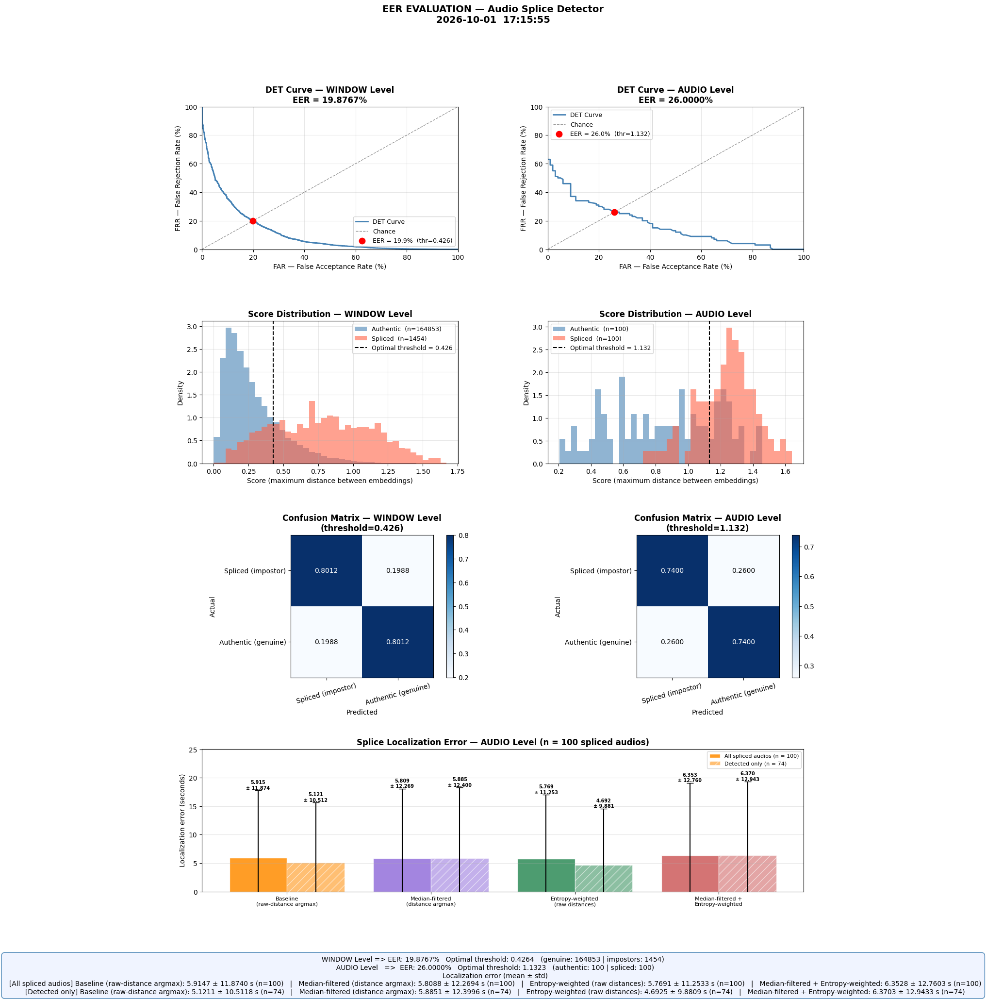

>>> FROZEN THRESHOLD  | window: 0.4264 | audio: 1.1323


In [ ]:

###########################################
"""ONE-TIME threshold calibration (with val_audios)"""
###########################################
set_all_seeds(RANDOM_SEED)
eer_results = evaluate_eer_complete(
    model=model,
    test_audios=val_audios,   #Calibration only, never seen in train
    device_to_label=device_to_label,
    #mean_global=global_mean,
    #std_global=global_std,
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER,
    save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"calibration_{eval_run_name}", class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE, compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
)

# This dict is the threshold we freeze and reuse in everything that follows
# Single calibrated threshold (per THRESHOLD_CALIBRATION_LEVEL), applied
# uniformly to both window- and audio-level evaluations, since the
# window-level EER threshold proved to underperform in practice.
# frozen_threshold_value = eer_results[THRESHOLD_CALIBRATION_LEVEL]['optimal_threshold']
# calibrated_threshold = {
#     'window': frozen_threshold_value,
#     'audio':  frozen_threshold_value,
# }
# print(f"\n>>> FROZEN THRESHOLD ({THRESHOLD_CALIBRATION_LEVEL}-calibrated, applied to both levels): "
#       f"{frozen_threshold_value:.4f}\n")
calibrated_threshold = {
    'window': eer_results['window']['optimal_threshold'],
    'audio':  eer_results['audio']['optimal_threshold'],
}
print(f">>> FROZEN THRESHOLD  | window: {calibrated_threshold['window']:.4f} "
      f"| audio: {calibrated_threshold['audio']:.4f}")

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/160 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   Window EER : 20.7015%  | optimal threshold (calibrated here) : 6.7688
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 9.6523 ± 14.7879 s (n=100)   |   Median-filtered (distance argmax): 8.2474 ± 13.5597 s (n=100)   |   Entropy-weighted (raw distances): 10.8302 ± 15.6952 s (n=100)   |   Median-filtered + Entropy-weighted: 8.6788 ± 14.6395 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 9.1609 ± 14.1787 s (n=71)   |   Median-filtered (distance argmax): 8.6722 ± 14.0146 s (n=71)   |   Entropy-weighted (raw distances): 11.1317 ± 15.5855 s (n=71)   |   Median-filtered + Entropy-weighted: 8.8157 ± 14.7935 s (n=71)
   Audio EER   : 30.0000%  | optimal threshold (calibrated here) : 13.5693
Threshold used for generate_forensic_report(): 6.7688
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_calibration_mahalanobis_euclidean_uv_epochs840_val15_win1_cosfa

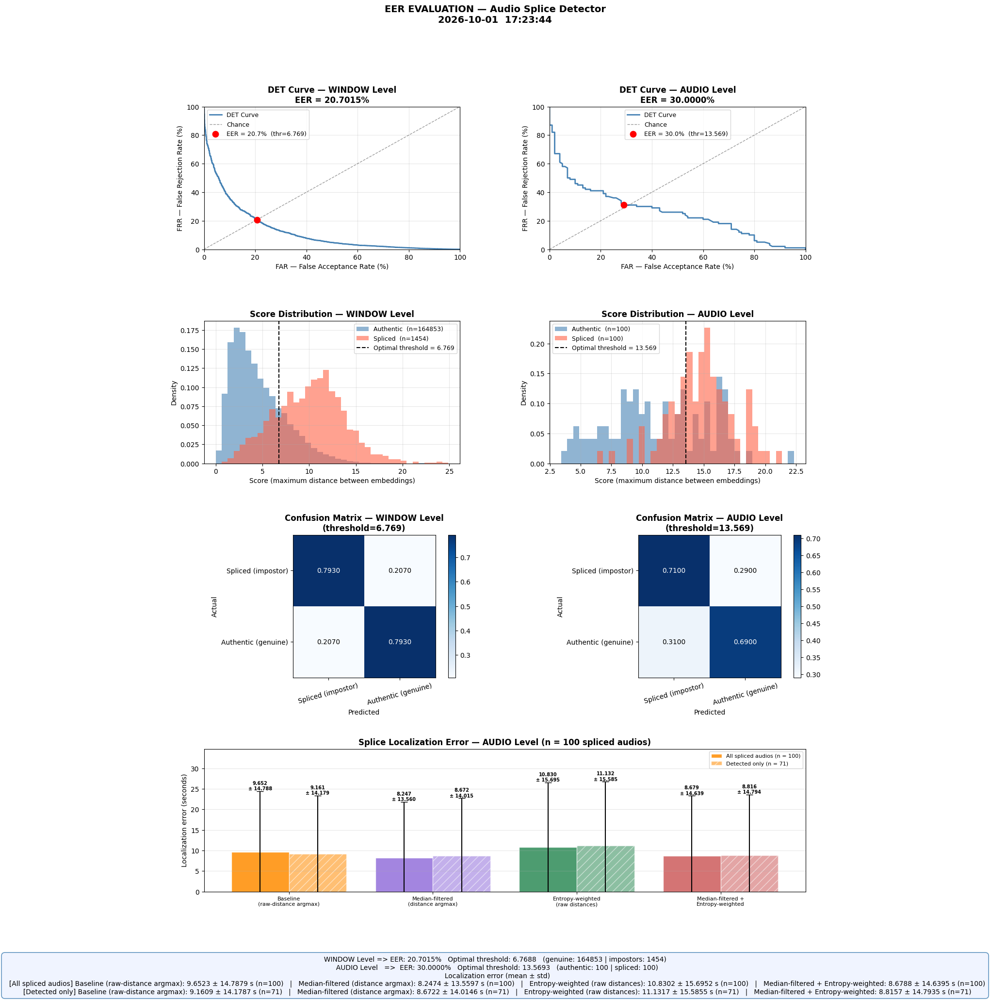

>>> FROZEN THRESHOLD | window: 6.7688 | audio: 13.5693


In [ ]:
###########################################
"""Mahalanobis distance — VI estimation + threshold calibration (with val_audios)"""
###########################################
if os.path.exists(mahalanobis_vi_path):
    with open(mahalanobis_vi_path, "rb") as f:
        mahalanobis_vi = pickle.load(f)
else:
    mahalanobis_vi = estimate_mahalanobis_vi(reference_embeddings.numpy())  # fit ONLY on train, never on val/test
    with open(mahalanobis_vi_path, "wb") as f:
        pickle.dump(mahalanobis_vi, f, protocol=pickle.HIGHEST_PROTOCOL)

# Calibrate the Mahalanobis threshold on val_audios — mirrors the calibration
# already done for calibrated_threshold (Euclidean), never on test_audios.
set_all_seeds(RANDOM_SEED)
eer_results_mahalanobis = evaluate_eer_complete(
    model=model, test_audios=val_audios, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"calibration_mahalanobis_{eval_run_name}",
    fixed_threshold=None,
    class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
)
# frozen_threshold_value_mahalanobis = eer_results_mahalanobis[THRESHOLD_CALIBRATION_LEVEL]['optimal_threshold']
# calibrated_threshold_mahalanobis = {
#     'window': frozen_threshold_value_mahalanobis,
#     'audio':  frozen_threshold_value_mahalanobis,
# }
# print(f"\n>>> FROZEN THRESHOLD (Mahalanobis, {THRESHOLD_CALIBRATION_LEVEL}-calibrated): "
#       f"{frozen_threshold_value_mahalanobis:.4f}\n")
calibrated_threshold_mahalanobis = {
    'window': eer_results_mahalanobis['window']['optimal_threshold'],
    'audio':  eer_results_mahalanobis['audio']['optimal_threshold'],
}
print(f">>> FROZEN THRESHOLD | window: {calibrated_threshold_mahalanobis['window']:.4f} "
      f"| audio: {calibrated_threshold_mahalanobis['audio']:.4f}")

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/160 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   Window EER : 19.8034%  | optimal threshold (calibrated here) : 2.7467
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 6.1758 ± 11.9731 s (n=100)   |   Median-filtered (distance argmax): 4.9700 ± 10.6330 s (n=100)   |   Entropy-weighted (raw distances): 7.2110 ± 12.9563 s (n=100)   |   Median-filtered + Entropy-weighted: 5.9893 ± 12.3199 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 5.3663 ± 10.5906 s (n=73)   |   Median-filtered (distance argmax): 4.1902 ± 9.0141 s (n=73)   |   Entropy-weighted (raw distances): 5.7855 ± 11.1990 s (n=73)   |   Median-filtered + Entropy-weighted: 4.7782 ± 10.7280 s (n=73)
   Audio EER   : 27.0000%  | optimal threshold (calibrated here) : 7.2711
Threshold used for generate_forensic_report(): 2.7467
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_calibration_manhattan_euclidean_uv_epochs840_val15_win1_cosface_out

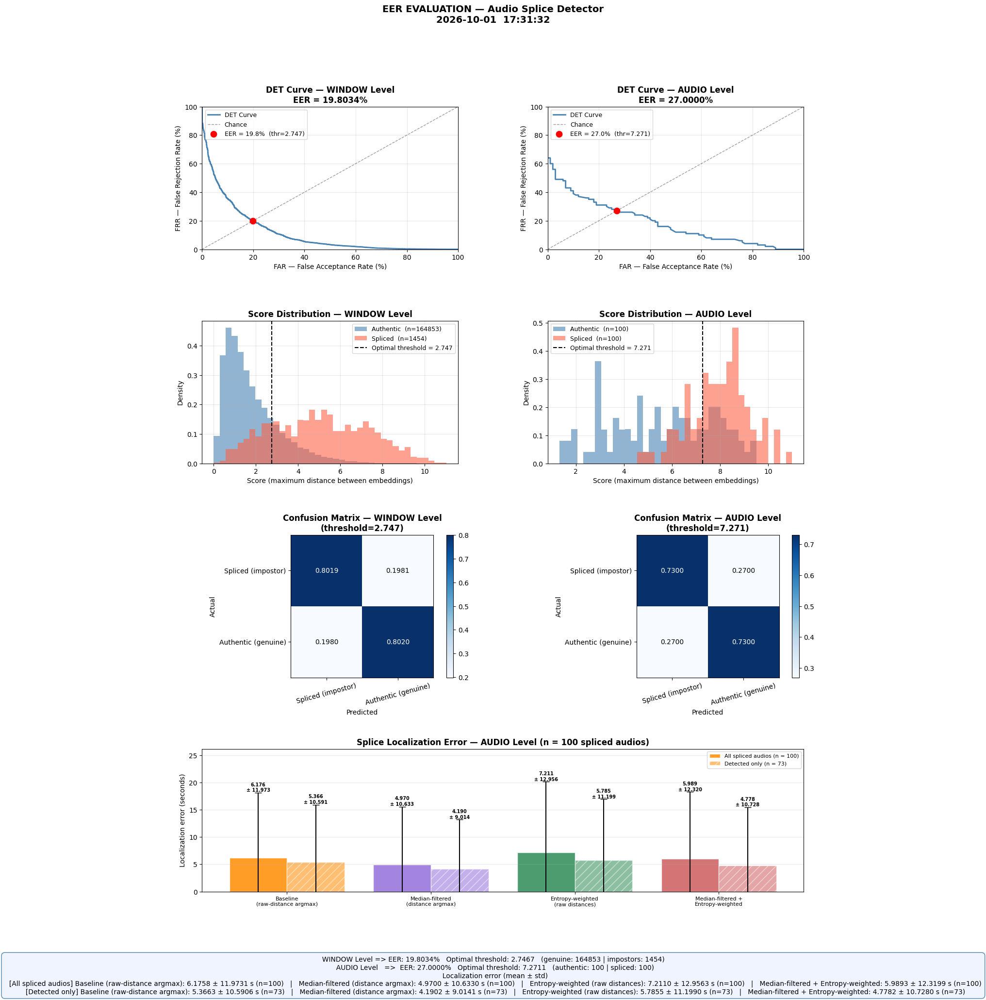

>>> FROZEN THRESHOLD | window: 2.7467 | audio: 7.2711


In [ ]:
# Calibrate the Manhattan-distance threshold on val_audios — mirrors the
# calibration already done for Euclidean/Mahalanobis, never on test_audios.
set_all_seeds(RANDOM_SEED)
eer_results_manhattan = evaluate_eer_complete(
    model=model, test_audios=val_audios, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"calibration_manhattan_{eval_run_name}",
    fixed_threshold=None,
    class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="manhattan", VI=None,
)
# frozen_threshold_value_manhattan = eer_results_manhattan[THRESHOLD_CALIBRATION_LEVEL]['optimal_threshold']
# calibrated_threshold_manhattan = {
#     'window': frozen_threshold_value_manhattan,
#     'audio':  frozen_threshold_value_manhattan,
# }
# print(f"\n>>> FROZEN THRESHOLD (Manhattan, {THRESHOLD_CALIBRATION_LEVEL}-calibrated): "
#       f"{frozen_threshold_value_manhattan:.4f}\n")
calibrated_threshold_manhattan = {
    'window': eer_results_manhattan['window']['optimal_threshold'],
    'audio':  eer_results_manhattan['audio']['optimal_threshold'],
}
print(f">>> FROZEN THRESHOLD | window: {calibrated_threshold_manhattan['window']:.4f} "
      f"| audio: {calibrated_threshold_manhattan['audio']:.4f}")

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/160 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   Window EER : 19.9447%  | optimal threshold (calibrated here) : 0.1813
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 6.0029 ± 11.8924 s (n=100)   |   Median-filtered (distance argmax): 5.5377 ± 12.1980 s (n=100)   |   Entropy-weighted (raw distances): 6.7145 ± 13.5446 s (n=100)   |   Median-filtered + Entropy-weighted: 6.9939 ± 13.9222 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 5.2253 ± 10.4775 s (n=75)   |   Median-filtered (distance argmax): 5.5748 ± 12.2305 s (n=75)   |   Entropy-weighted (raw distances): 5.0381 ± 10.4930 s (n=75)   |   Median-filtered + Entropy-weighted: 6.2983 ± 13.2188 s (n=75)
   Audio EER   : 25.0000%  | optimal threshold (calibrated here) : 1.2700
Threshold used for generate_forensic_report(): 0.1813
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_calibration_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64

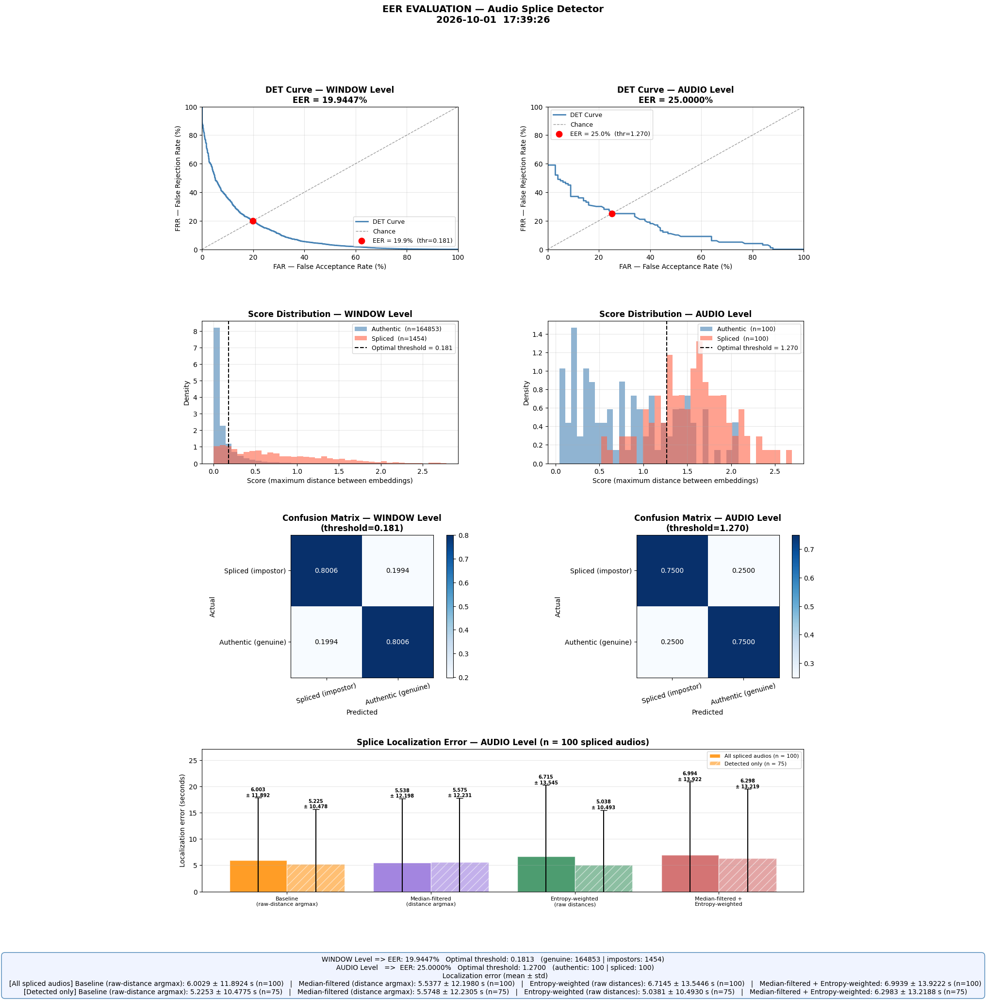

>>> FROZEN THRESHOLD | window: 0.1813 | audio: 1.2700


In [ ]:
# Calibrate the SNR-distance threshold on val_audios — mirrors the
# calibration already done for Euclidean/Mahalanobis/Manhattan, never on test_audios.
set_all_seeds(RANDOM_SEED)
eer_results_snr = evaluate_eer_complete(
    model=model, test_audios=val_audios, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"calibration_snr_{eval_run_name}",
    fixed_threshold=None,
    class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="snr", VI=None,
)
# frozen_threshold_value_snr = eer_results_snr[THRESHOLD_CALIBRATION_LEVEL]['optimal_threshold']
# calibrated_threshold_snr = {
#     'window': frozen_threshold_value_snr,
#     'audio':  frozen_threshold_value_snr,
# }
# print(f"\n>>> FROZEN THRESHOLD (SNR, {THRESHOLD_CALIBRATION_LEVEL}-calibrated): "
#       f"{frozen_threshold_value_snr:.4f}\n")
calibrated_threshold_snr = {
    'window': eer_results_snr['window']['optimal_threshold'],
    'audio':  eer_results_snr['audio']['optimal_threshold'],
}
print(f">>> FROZEN THRESHOLD | window: {calibrated_threshold_snr['window']:.4f} "
      f"| audio: {calibrated_threshold_snr['audio']:.4f}")

Condition combination in this splice: speech_noise -> speech_noise
Real cut point: sample 892416 - 20.2362 seconds


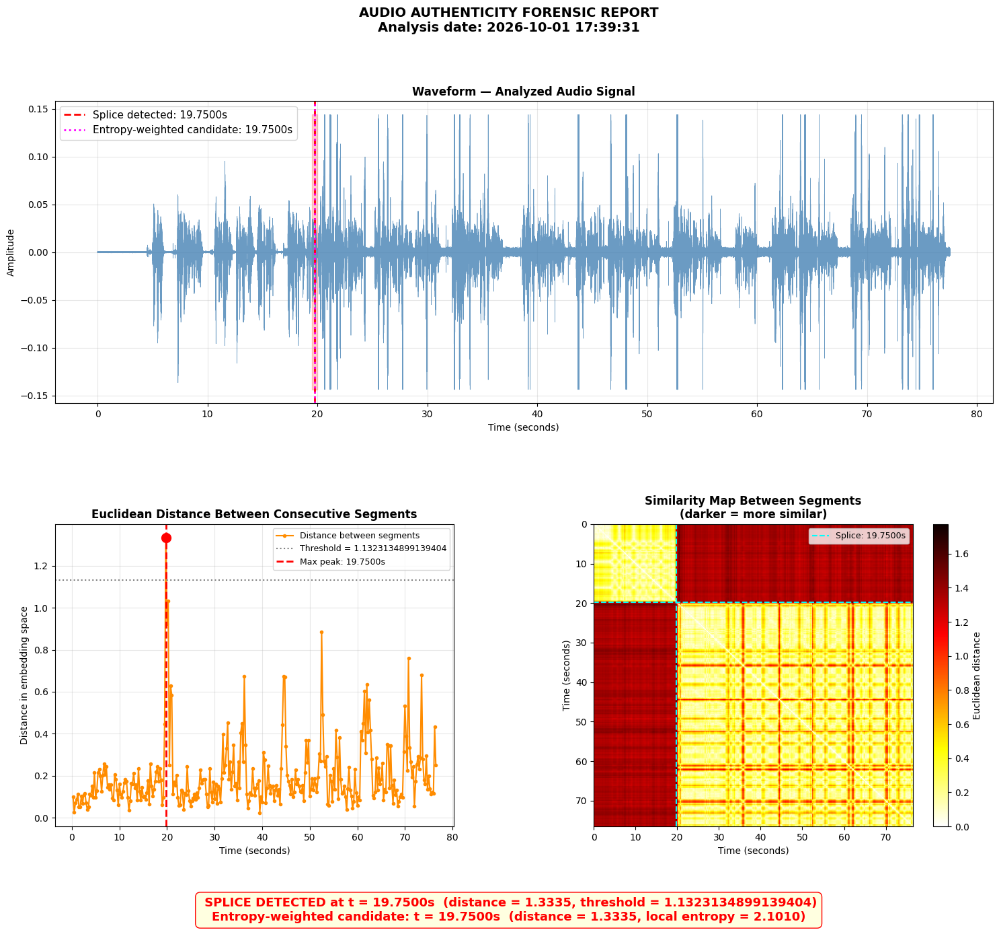

Max distance found: 1.3335
Current threshold:  1.1323
Detected splice?:    True
Model detected: splice at 19.7500s
Error:          0.4862s
Entropy-weighted candidate: splice at 19.7500s
Error (entropy):            0.4862s


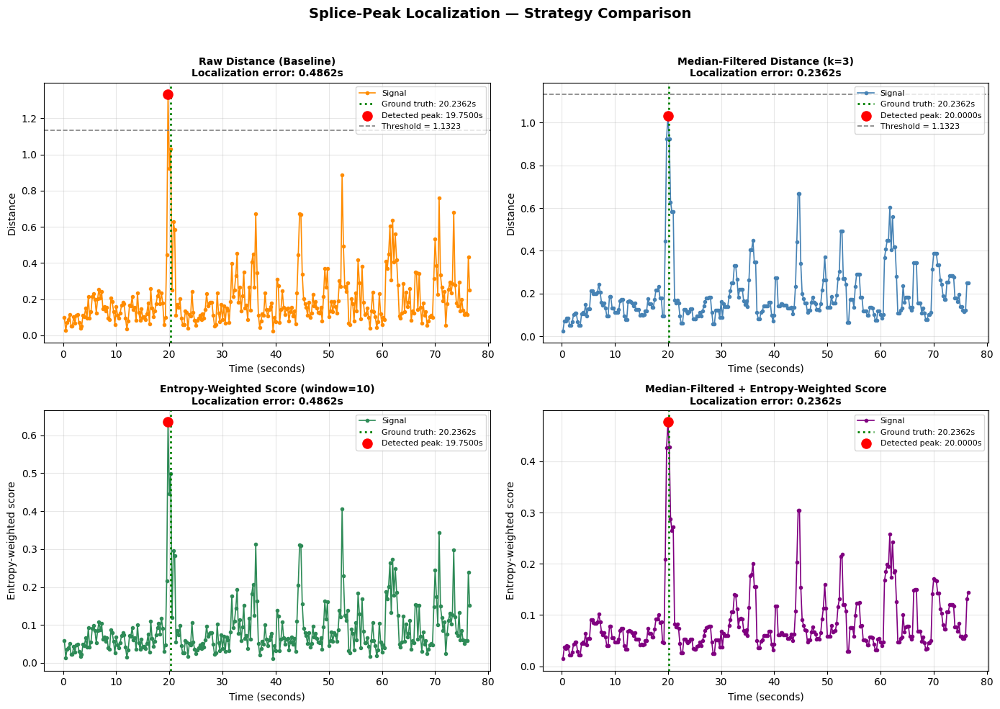

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary ===
Raw Distance (Baseline)                       error = 0.4862s (detected at 19.7500s)
Median-Filtered Distance (k=3)                error = 0.2362s (detected at 20.0000s)
Entropy-Weighted Score (window=10)            error = 0.4862s (detected at 19.7500s)
Median-Filtered + Entropy-Weighted Score      error = 0.2362s (detected at 20.0000s)


In [ ]:

###
"""TEST"""
####
# audio files the model has NOT seen during training

# test_audios for testing
#test_audio_a = random.choice([a for a in test_audios if a['device'] == 'huawei_nova_9'])
#test_audio_b = random.choice([a for a in test_audios if a['device'] == 'poco_m4_pro'])
device_a, device_b = random.sample(devices, 2)
test_audio_a = random.choice([a for a in test_audios if a['device'] == device_a])
test_audio_b = random.choice([a for a in test_audios if a['device'] == device_b])

print(f"Condition combination in this splice: "
      f"{test_audio_a['condition']} -> {test_audio_b['condition']}")
# Generate the splicing with the existing function
test_result = generate_splicing_pair(test_audio_a, test_audio_b)

spliced_test_audio = test_result['audio']
real_cut_point = test_result['cut_point']
real_cut_time = test_result['cut_time']

print(f"Real cut point: sample {real_cut_point} - {real_cut_time:.4f} seconds")

# Pass to the forensic report

forensic_report_result = generate_forensic_report(
    suspect_audio=spliced_test_audio,
    model=model,
    device=device,
    threshold=calibrated_threshold['audio'],
    #mean_global=global_mean,
    #std_global=global_std,
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
)
# check what the actual max distance obtained is
print(f"Max distance found: {forensic_report_result['max_distance']:.4f}")
print(f"Current threshold:  {forensic_report_result['threshold_used']:.4f}")
print(f"Detected splice?:    {forensic_report_result['has_splice']}")

# Compare what the model detected against reality

if forensic_report_result['has_splice']:
    time_error = abs(real_cut_time - forensic_report_result['splice_time_sec'])
    print(f"Model detected: splice at {forensic_report_result['splice_time_sec']:.4f}s")
    print(f"Error:          {time_error:.4f}s")
else:
    print(f"Model detected: AUTHENTIC AUDIO (did not exceed threshold {forensic_report_result['threshold_used']:.4f})")
    print(f"Max distance:   {forensic_report_result['max_distance']:.4f}")
if forensic_report_result.get('has_splice_entropy'):
    time_error_entropy = abs(real_cut_time - forensic_report_result['splice_time_sec_entropy'])
    print(f"Entropy-weighted candidate: splice at {forensic_report_result['splice_time_sec_entropy']:.4f}s")
    print(f"Error (entropy):            {time_error_entropy:.4f}s")
else:
    print(f"Entropy-weighted candidate: no distance above threshold ")
    print(f"(max distance = {forensic_report_result.get('max_distance_entropy', float('nan')):.4f})")

strategy_comparison_results = plot_filtering_strategy_comparison(
    distances=forensic_report_result['distances'],
    timestamps=forensic_report_result['timestamps'][1:],
    threshold=forensic_report_result['threshold_used'],
    ground_truth_time_s=real_cut_time,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    output_path=output_path,
    run_name=eval_run_name,
)

print("\n=== Strategy comparison summary ===")
for strategy_name, strategy_metrics in strategy_comparison_results.items():
    print(f"{strategy_name:<45} error = {strategy_metrics['localization_error_s']:.4f}s "
          f"(detected at {strategy_metrics['detected_time_s']:.4f}s)")

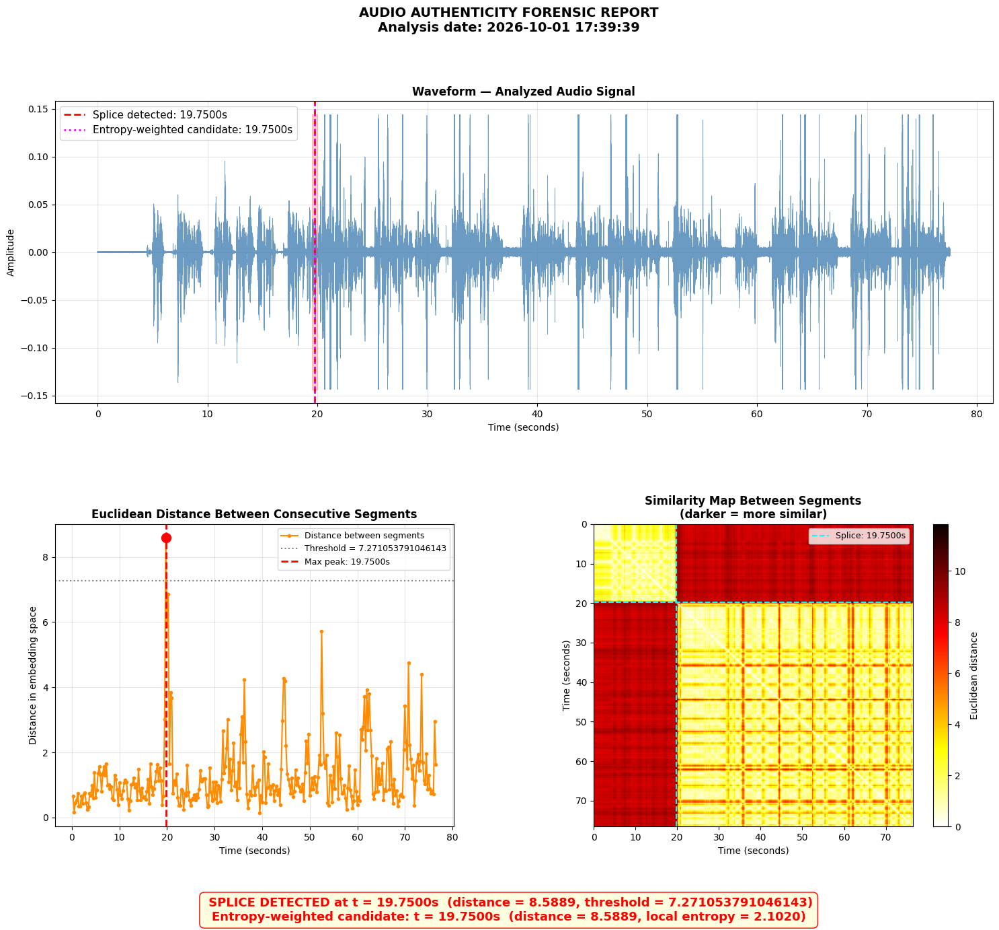

Max distance found (Manhattan, direct): 8.5889
Current threshold (Manhattan, direct):  7.2711
Detected splice?:                       True
Model detected: splice at 19.7500s
Error:          0.4862s
Entropy-weighted candidate: splice at 19.7500s
Error (entropy):            0.4862s


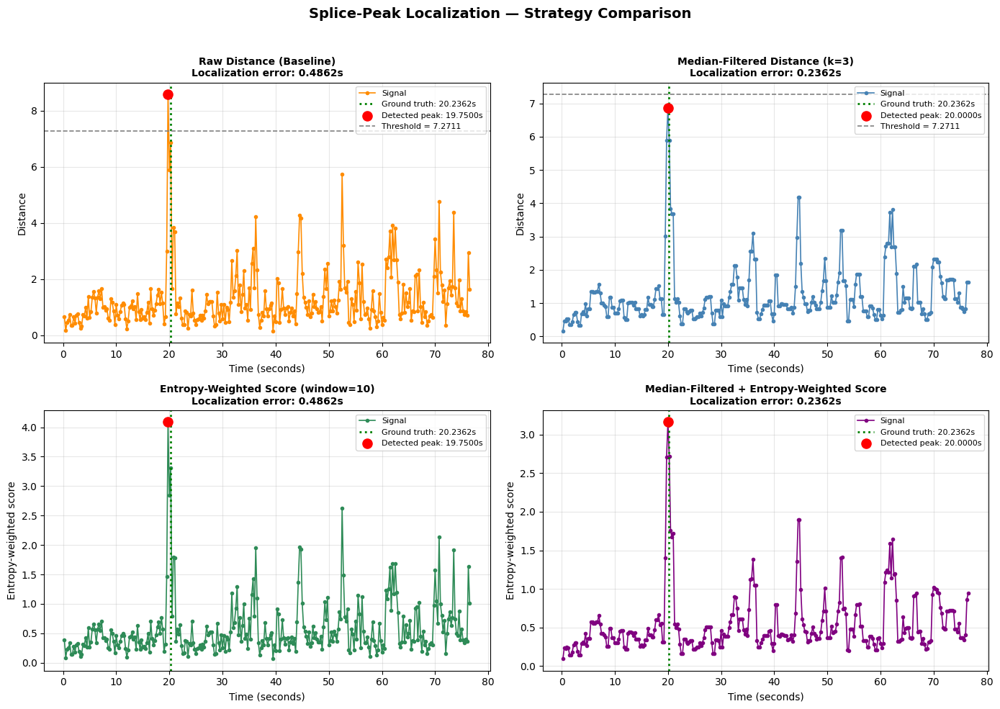

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_manhattan_direct_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary (Manhattan, direct/no pairwise) ===
Raw Distance (Baseline)                       error = 0.4862s (detected at 19.7500s)
Median-Filtered Distance (k=3)                error = 0.2362s (detected at 20.0000s)
Entropy-Weighted Score (window=10)            error = 0.4862s (detected at 19.7500s)
Median-Filtered + Entropy-Weighted Score      error = 0.2362s (detected at 20.0000s)


In [ ]:
###
"""TEST — MANHATTAN (without pairwise, via np.linalg.norm(ord=1))"""
####
# Same never-seen splice pair, computing L1 distance directly through
# np.linalg.norm instead of the _pairwise_distance abstraction, to compare
# against the pairwise-routed Manhattan block above.

forensic_report_result_manhattan_direct = generate_forensic_report(
    suspect_audio=spliced_test_audio,
    model=model,
    device=device,
    threshold=calibrated_threshold_manhattan['audio'],
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    use_pairwise_distance=False,
    norm_ord=1,
)
print(f"Max distance found (Manhattan, direct): {forensic_report_result_manhattan_direct['max_distance']:.4f}")
print(f"Current threshold (Manhattan, direct):  {forensic_report_result_manhattan_direct['threshold_used']:.4f}")
print(f"Detected splice?:                       {forensic_report_result_manhattan_direct['has_splice']}")

if forensic_report_result_manhattan_direct['has_splice']:
    time_error_manhattan_direct = abs(real_cut_time - forensic_report_result_manhattan_direct['splice_time_sec'])
    print(f"Model detected: splice at {forensic_report_result_manhattan_direct['splice_time_sec']:.4f}s")
    print(f"Error:          {time_error_manhattan_direct:.4f}s")
else:
    print(f"Model detected: AUTHENTIC AUDIO (did not exceed threshold {forensic_report_result_manhattan_direct['threshold_used']:.4f})")
    print(f"Max distance:   {forensic_report_result_manhattan_direct['max_distance']:.4f}")
if forensic_report_result_manhattan_direct.get('has_splice_entropy'):
    time_error_entropy_manhattan_direct = abs(real_cut_time - forensic_report_result_manhattan_direct['splice_time_sec_entropy'])
    print(f"Entropy-weighted candidate: splice at {forensic_report_result_manhattan_direct['splice_time_sec_entropy']:.4f}s")
    print(f"Error (entropy):            {time_error_entropy_manhattan_direct:.4f}s")
else:
    print(f"Entropy-weighted candidate: no distance above threshold ")
    print(f"(max distance = {forensic_report_result_manhattan_direct.get('max_distance_entropy', float('nan')):.4f})")

strategy_comparison_results_manhattan_direct = plot_filtering_strategy_comparison(
    distances=forensic_report_result_manhattan_direct['distances'],
    timestamps=forensic_report_result_manhattan_direct['timestamps'][1:],
    threshold=forensic_report_result_manhattan_direct['threshold_used'],
    ground_truth_time_s=real_cut_time,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    output_path=output_path,
    run_name=f"manhattan_direct_{eval_run_name}",
)

print("\n=== Strategy comparison summary (Manhattan, direct/no pairwise) ===")
for strategy_name, strategy_metrics in strategy_comparison_results_manhattan_direct.items():
    print(f"{strategy_name:<45} error = {strategy_metrics['localization_error_s']:.4f}s "
          f"(detected at {strategy_metrics['detected_time_s']:.4f}s)")

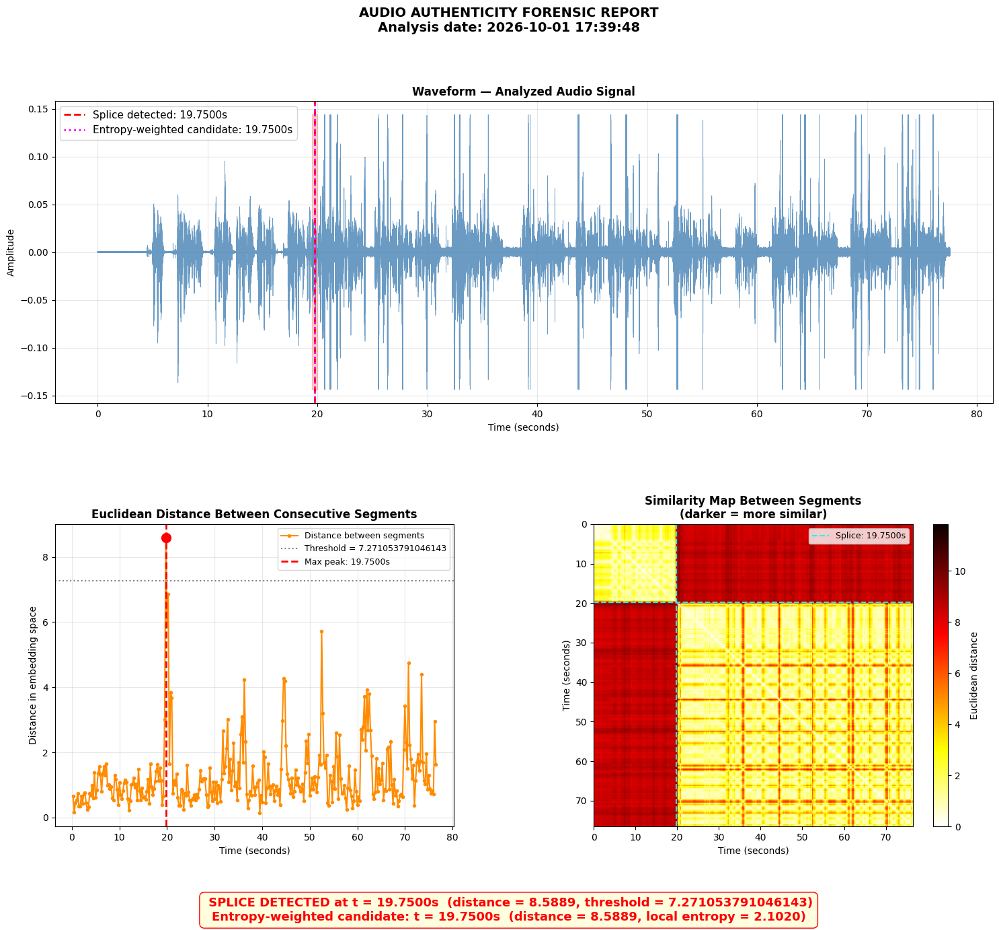

Max distance found (Manhattan): 8.5889
Current threshold (Manhattan):  7.2711
Detected splice?:               True
Model detected: splice at 19.7500s
Error:          0.4862s
Entropy-weighted candidate: splice at 19.7500s
Error (entropy):            0.4862s


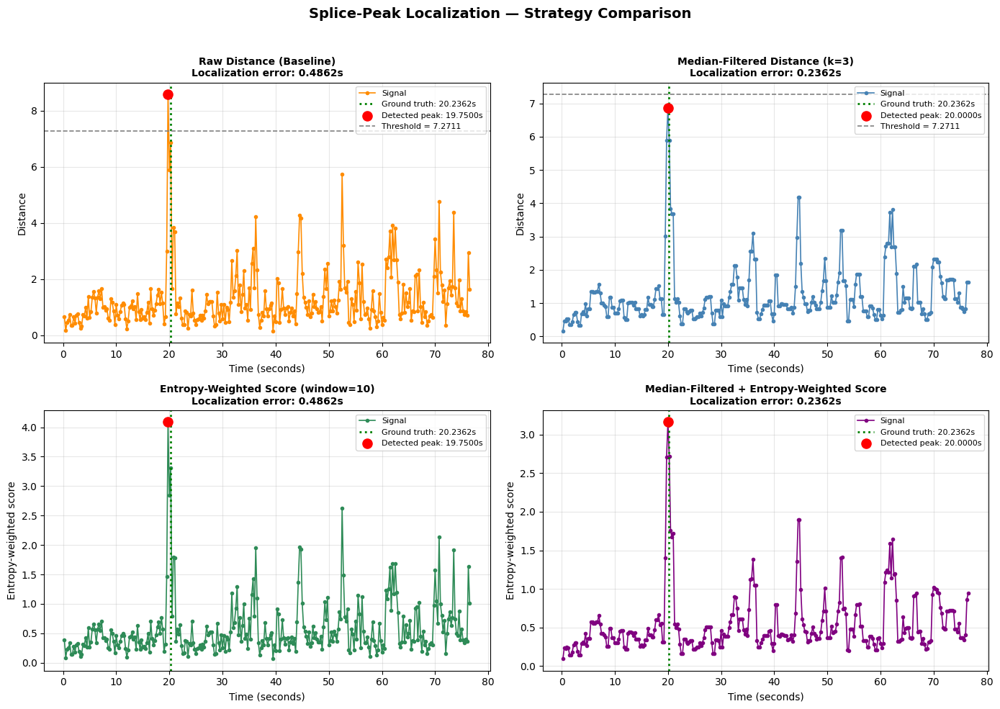

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary (Manhattan, pairwise) ===
Raw Distance (Baseline)                       error = 0.4862s (detected at 19.7500s)
Median-Filtered Distance (k=3)                error = 0.2362s (detected at 20.0000s)
Entropy-Weighted Score (window=10)            error = 0.4862s (detected at 19.7500s)
Median-Filtered + Entropy-Weighted Score      error = 0.2362s (detected at 20.0000s)


In [ ]:
###
"""TEST — MANHATTAN (_pairwise_distance)"""
####
# Same never-seen splice pair, routed through the pairwise-distance
# abstraction instead of the hardcoded np.linalg.norm path, so results
# can be compared against the original block with and without that change.

forensic_report_result_manhattan = generate_forensic_report(
    suspect_audio=spliced_test_audio,
    model=model,
    device=device,
    threshold=calibrated_threshold_manhattan['audio'],
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    use_pairwise_distance=True,
    distance_metric="manhattan",
    VI=None,
)
print(f"Max distance found (Manhattan): {forensic_report_result_manhattan['max_distance']:.4f}")
print(f"Current threshold (Manhattan):  {forensic_report_result_manhattan['threshold_used']:.4f}")
print(f"Detected splice?:               {forensic_report_result_manhattan['has_splice']}")

if forensic_report_result_manhattan['has_splice']:
    time_error_manhattan = abs(real_cut_time - forensic_report_result_manhattan['splice_time_sec'])
    print(f"Model detected: splice at {forensic_report_result_manhattan['splice_time_sec']:.4f}s")
    print(f"Error:          {time_error_manhattan:.4f}s")
else:
    print(f"Model detected: AUTHENTIC AUDIO (did not exceed threshold {forensic_report_result_manhattan['threshold_used']:.4f})")
    print(f"Max distance:   {forensic_report_result_manhattan['max_distance']:.4f}")
if forensic_report_result_manhattan.get('has_splice_entropy'):
    time_error_entropy_manhattan = abs(real_cut_time - forensic_report_result_manhattan['splice_time_sec_entropy'])
    print(f"Entropy-weighted candidate: splice at {forensic_report_result_manhattan['splice_time_sec_entropy']:.4f}s")
    print(f"Error (entropy):            {time_error_entropy_manhattan:.4f}s")
else:
    print(f"Entropy-weighted candidate: no distance above threshold ")
    print(f"(max distance = {forensic_report_result_manhattan.get('max_distance_entropy', float('nan')):.4f})")

strategy_comparison_results_manhattan = plot_filtering_strategy_comparison(
    distances=forensic_report_result_manhattan['distances'],
    timestamps=forensic_report_result_manhattan['timestamps'][1:],
    threshold=forensic_report_result_manhattan['threshold_used'],
    ground_truth_time_s=real_cut_time,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    output_path=output_path,
    run_name=f"manhattan_{eval_run_name}",
)

print("\n=== Strategy comparison summary (Manhattan, pairwise) ===")
for strategy_name, strategy_metrics in strategy_comparison_results_manhattan.items():
    print(f"{strategy_name:<45} error = {strategy_metrics['localization_error_s']:.4f}s "
          f"(detected at {strategy_metrics['detected_time_s']:.4f}s)")

=== CLEAN-only evaluation (fixed threshold) ===
 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/100 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   FIXED threshold used: 0.4264  | FAR: 21.2500%  | FRR: 29.1668%  (reference EER for this sample: 24.8031%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 10.1572 ± 14.8872 s (n=100)   |   Median-filtered (distance argmax): 11.5606 ± 16.1606 s (n=100)   |   Entropy-weighted (raw distances): 9.9815 ± 15.0662 s (n=100)   |   Median-filtered + Entropy-weighted: 10.7782 ± 16.0632 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 8.2312 ± 14.2992 s (n=64)   |   Median-filtered (distance argmax): 9.9953 ± 15.2312 s (n=64)   |   Entropy-weighted (raw distances): 7.4331 ± 13.8013 s (n=64)   |   Median-filtered + Entropy-weighted: 9.5175 ± 15.0956 s (n=64)
   FIXED threshold used: 1.1323  | FAR: 36.0000%  | FRR: 25.0000%  (reference EER for this sample: 30.0000%)
Threshold used for generate_forensic_report(): 0.4264
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer

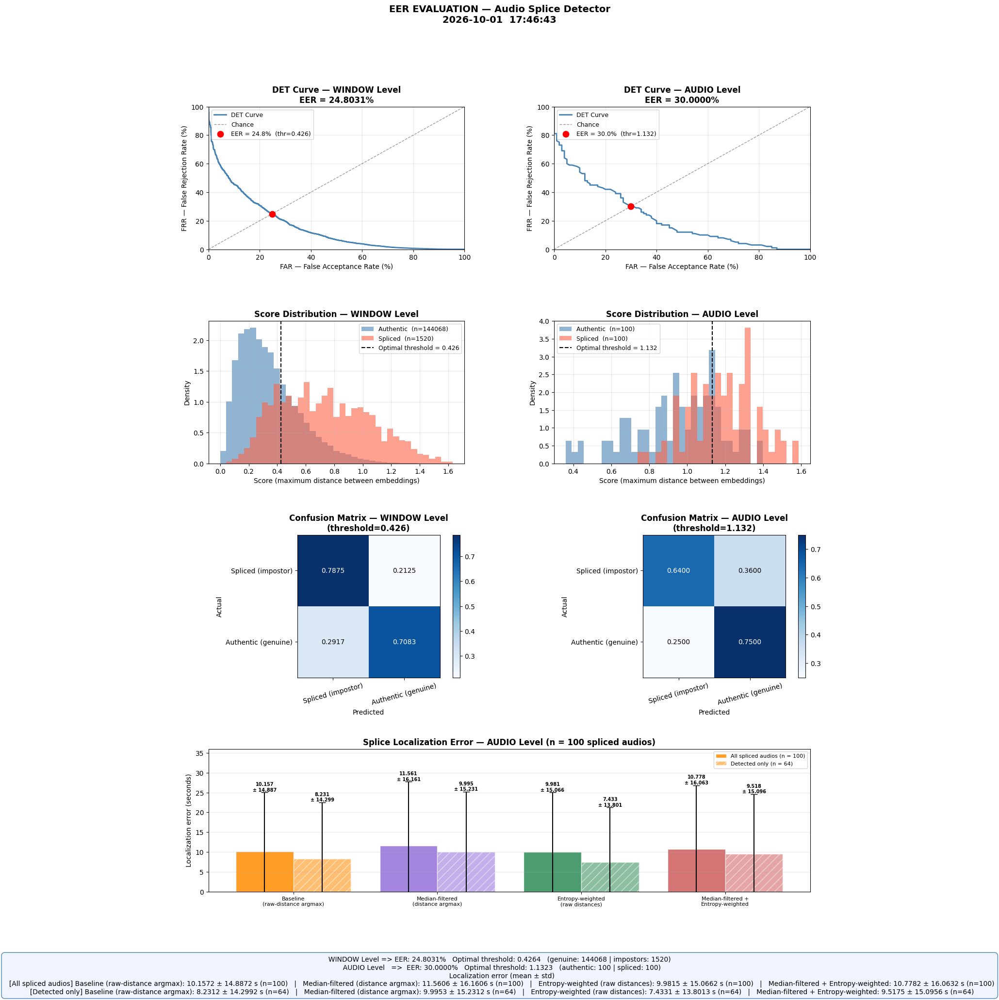

=== NOISE-only evaluation (fixed threshold) ===
 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/100 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   FIXED threshold used: 0.4264  | FAR: 26.9597%  | FRR: 7.7943%  (reference EER for this sample: 16.0430%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 4.8983 ± 10.7998 s (n=100)   |   Median-filtered (distance argmax): 5.4788 ± 10.0280 s (n=100)   |   Entropy-weighted (raw distances): 4.6634 ± 10.4441 s (n=100)   |   Median-filtered + Entropy-weighted: 5.9768 ± 11.6764 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 1.6923 ± 6.4458 s (n=54)   |   Median-filtered (distance argmax): 2.8497 ± 6.5337 s (n=54)   |   Entropy-weighted (raw distances): 1.6884 ± 6.4470 s (n=54)   |   Median-filtered + Entropy-weighted: 3.4468 ± 9.1156 s (n=54)
   FIXED threshold used: 1.1323  | FAR: 46.0000%  | FRR: 11.0000%  (reference EER for this sample: 21.0000%)
Threshold used for generate_forensic_report(): 0.4264
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_

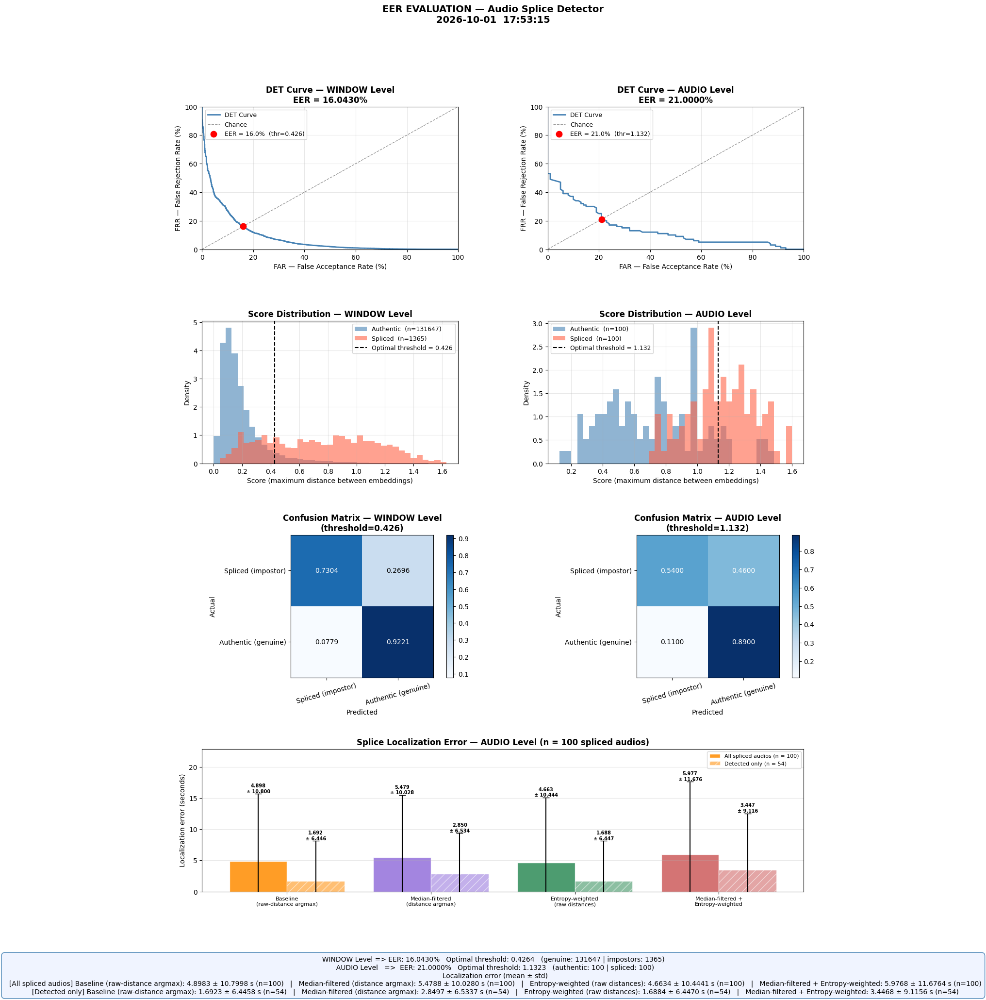

Evaluating clean_vs_clean ...
  EER = 0.0000%  (thr=0.4755, genuine=94, impostors=106)
Evaluating noise_vs_noise ...
  EER = 0.0000%  (thr=0.3016, genuine=97, impostors=103)
Evaluating clean_vs_noise ...
  EER = 0.0000%  (thr=0.8829, genuine=105, impostors=95)


In [ ]:

###########################################
"""Clean vs noise diagnostic — reports ONLY FAR/FRR with the frozen threshold"""
###########################################
test_clean = [a for a in test_audios if a['condition'] == 'speech_clean']
test_noise = [a for a in test_audios if a['condition'] == 'speech_noise']
set_all_seeds(RANDOM_SEED)
print("=== CLEAN-only evaluation (fixed threshold) ===")
clean_results = evaluate_eer_complete(
    model=model, test_audios=test_clean, device_to_label=device_to_label,
    #mean_global=global_mean, std_global=global_std,
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True, sr=SR,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"clean_{eval_run_name}",
    fixed_threshold=calibrated_threshold, class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE, compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
)
set_all_seeds(RANDOM_SEED)
print("=== NOISE-only evaluation (fixed threshold) ===")
noise_results = evaluate_eer_complete(
    model=model, test_audios=test_noise, device_to_label=device_to_label,
    #mean_global=global_mean, std_global=global_std,
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True, sr=SR,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"noise_{eval_run_name}",
    fixed_threshold=calibrated_threshold, class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE, compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
)
set_all_seeds(RANDOM_SEED)
robustness_results = evaluate_noise_robustness(
    model=model, test_audios=test_audios,
    #mean_global=global_mean, std_global=global_std,
    device=device, n_pairs=N_PAIRS_ROBUSTNESS, sr=SR,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT
)

=== FINAL EVALUATION ON TEST SET (never seen, frozen threshold) ===
 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/200 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   FIXED threshold used: 0.4264  | FAR: 20.4930%  | FRR: 18.5564%  (reference EER for this sample: 19.4371%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 4.4822 ± 9.8919 s (n=100)   |   Median-filtered (distance argmax): 7.2750 ± 13.3790 s (n=100)   |   Entropy-weighted (raw distances): 5.7106 ± 12.1820 s (n=100)   |   Median-filtered + Entropy-weighted: 6.4501 ± 13.0911 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 2.9724 ± 8.0451 s (n=59)   |   Median-filtered (distance argmax): 5.6948 ± 12.2781 s (n=59)   |   Entropy-weighted (raw distances): 3.5392 ± 10.1333 s (n=59)   |   Median-filtered + Entropy-weighted: 4.5035 ± 11.5159 s (n=59)
   FIXED threshold used: 1.1323  | FAR: 41.0000%  | FRR: 18.0000%  (reference EER for this sample: 26.0000%)
Threshold used for generate_forensic_report(): 0.4264
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_repo

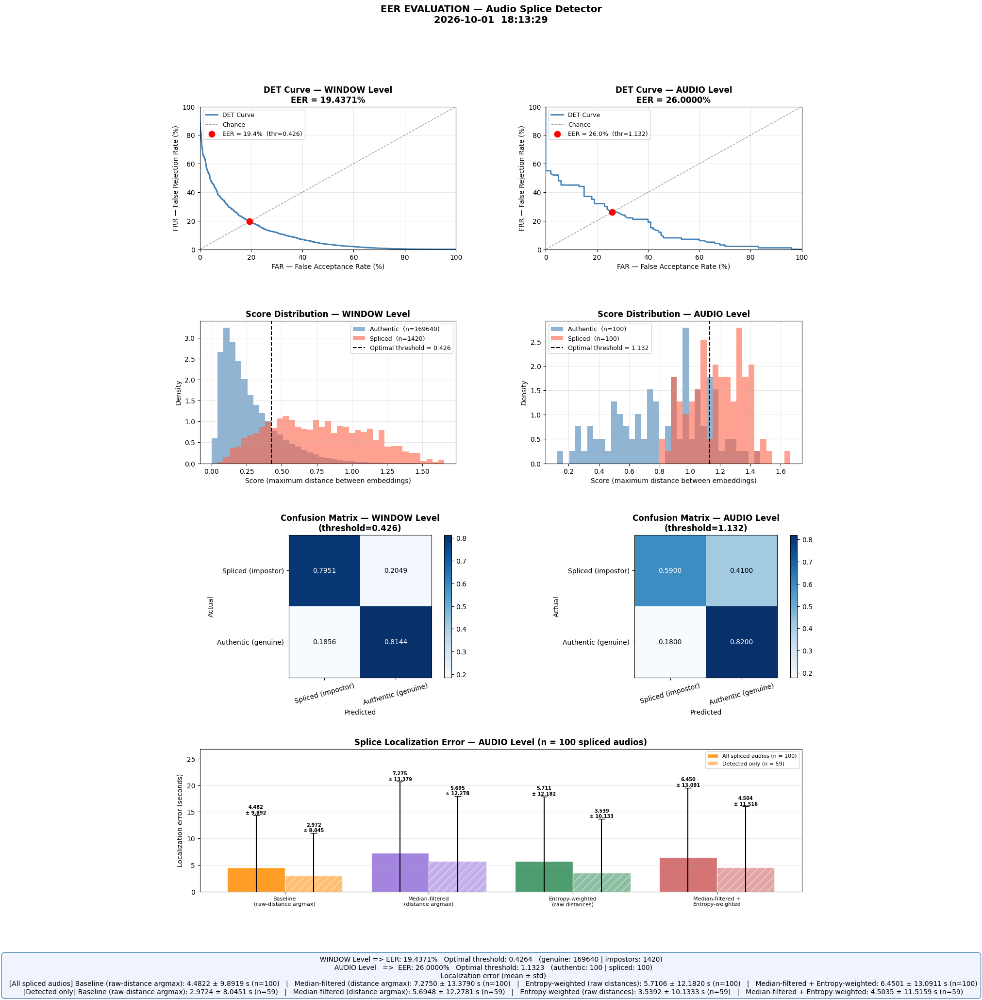

In [ ]:

###########################################
"""FINAL EVALUATION — pure test set, with the frozen threshold"""
###########################################
print("=== FINAL EVALUATION ON TEST SET (never seen, frozen threshold) ===")
final_test_results = evaluate_eer_complete(
    model=model,
    test_audios=test_audios,
    device_to_label=device_to_label,
    #mean_global=global_mean,std_global=global_std,
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER,
    save_pdf=True,
    sr=SR,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    top_db=TOP_DB,
    output_path=output_path, run_name=f"final_test_{eval_run_name}",
    fixed_threshold=calibrated_threshold, class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE, compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
)


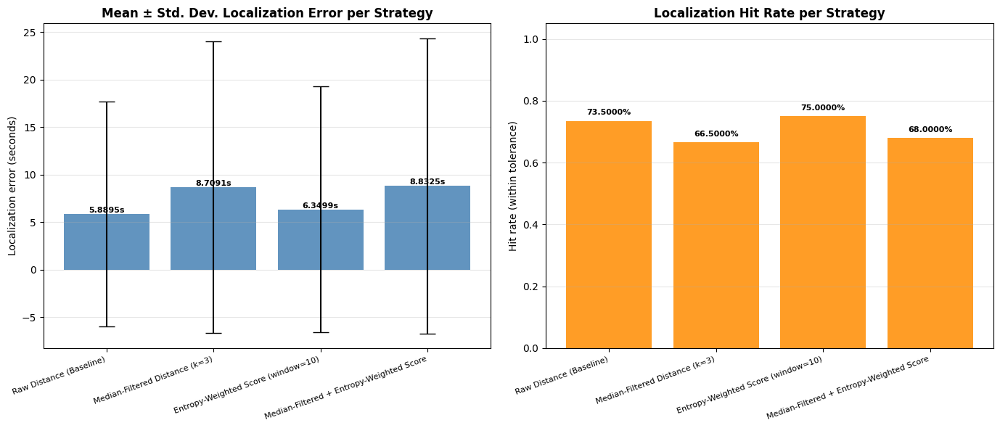

Filtering strategy summary saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_strategy_summary_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Filtering strategy summary — pure test set ===
Raw Distance (Baseline)                       mean error = 5.8895s ± 11.8230s 
| hit rate = 73.5000%  (n=200)
Median-Filtered Distance (k=3)                mean error = 8.7091s ± 15.3305s 
| hit rate = 66.5000%  (n=200)
Entropy-Weighted Score (window=10)            mean error = 6.3499s ± 12.9237s 
| hit rate = 75.0000%  (n=200)
Median-Filtered + Entropy-Weighted Score      mean error = 8.8325s ± 15.5137s 
| hit rate = 68.0000%  (n=200)
Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.

'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
set_all_seeds(RANDOM_SEED)
filtering_strategy_summary = evaluate_filtering_strategies_on_test_set(
    test_audios=test_audios,
    devices=devices,
    model=model,
    device=device,
    n_pairs=N_PAIRS_FILTERING_COMPARISON,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, top_db=TOP_DB,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
)
plot_filtering_strategy_summary(filtering_strategy_summary, output_path=output_path, run_name=eval_run_name)

print("\n=== Filtering strategy summary — pure test set ===")
for strategy_name, metrics in filtering_strategy_summary.items():
    print(f"{strategy_name:<45} mean error = {metrics['mean_error_s']:.4f}s ± {metrics['std_error_s']:.4f}s ")
    print(f"| hit rate = {metrics['hit_rate']:.4%}  (n={metrics['n_pairs']})")

save_eer_results(
    final_test_results,
    output_path=output_path,
    run_name=eval_run_name,
    config_extra={
        "SR": SR, "EPOCHS": EPOCHS, "OUT_DIM": OUT_DIM,
        "N_FFT": N_FFT, "WIN_LENGTH_SEC": WIN_LENGTH_SEC,
        "TRIPLET_MARGIN": TRIPLET_MARGIN,
        "frozen_threshold_window": calibrated_threshold['window'],
        "frozen_threshold_audio": calibrated_threshold['audio'],
    },
)

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/200 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   FIXED threshold used: 6.7688  | FAR: 23.2272%  | FRR: 18.6785%  (reference EER for this sample: 20.7665%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 9.9322 ± 14.0600 s (n=100)   |   Median-filtered (distance argmax): 11.7897 ± 16.0310 s (n=100)   |   Entropy-weighted (raw distances): 10.8078 ± 15.8833 s (n=100)   |   Median-filtered + Entropy-weighted: 10.8674 ± 15.2998 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 10.6592 ± 14.6648 s (n=69)   |   Median-filtered (distance argmax): 12.0776 ± 15.8620 s (n=69)   |   Entropy-weighted (raw distances): 11.6093 ± 16.6877 s (n=69)   |   Median-filtered + Entropy-weighted: 11.0552 ± 14.7149 s (n=69)
   FIXED threshold used: 13.5693  | FAR: 31.0000%  | FRR: 32.0000%  (reference EER for this sample: 32.0000%)
Threshold used for generate_forensic_report(): 6.7688
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectru

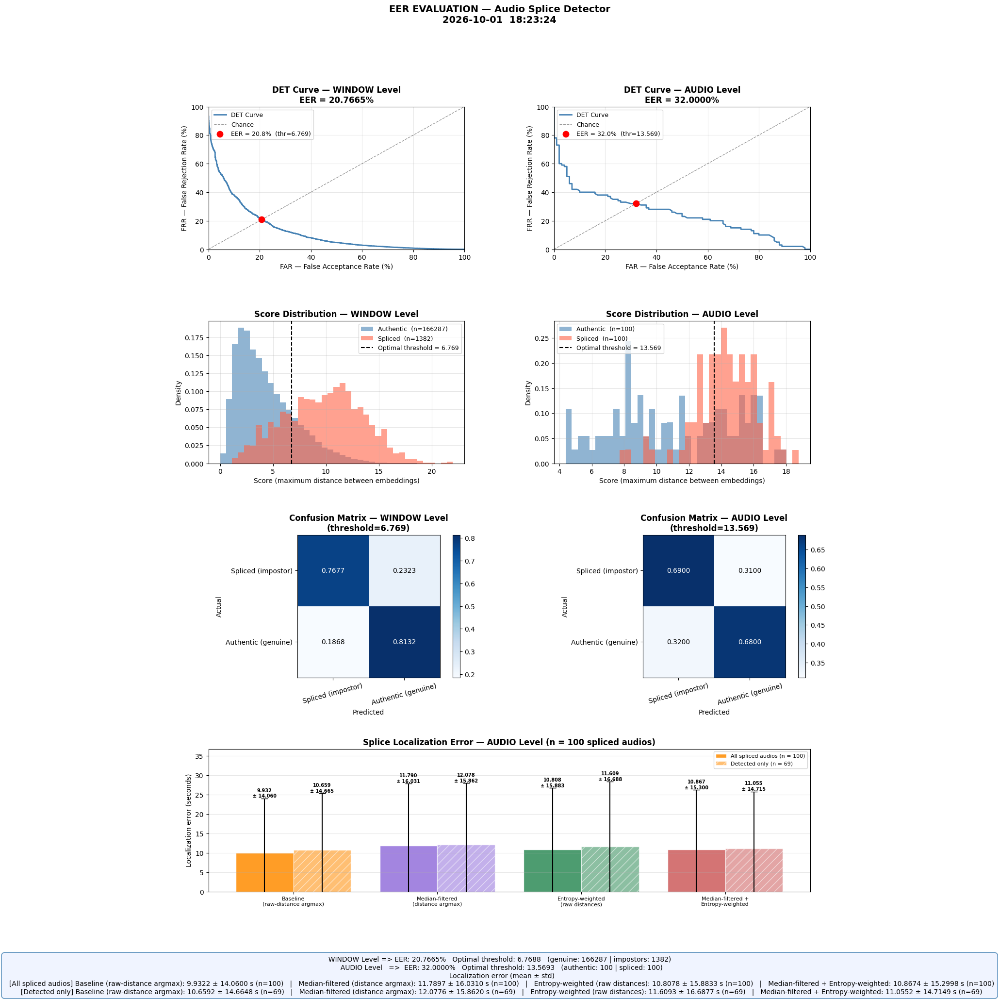

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_final_test_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:

###########################################
"""FINAL EVALUATION — pure test set, with the frozen threshold - Mahalanobis"""
###########################################
final_test_results_mahalanobis = evaluate_eer_complete(
    model=model, test_audios=test_audios, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"final_test_mahalanobis_{eval_run_name}",
    fixed_threshold=calibrated_threshold_mahalanobis,   # frozen threshold
    class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
)
save_eer_results(final_test_results_mahalanobis, output_path=output_path,
                  run_name=f"final_test_mahalanobis_{eval_run_name}",
                  config_extra={"distance_metric": "mahalanobis"})

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/200 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   FIXED threshold used: 2.7467  | FAR: 20.4181%  | FRR: 19.0313%  (reference EER for this sample: 19.7119%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 4.2397 ± 9.7441 s (n=100)   |   Median-filtered (distance argmax): 7.4108 ± 12.3350 s (n=100)   |   Entropy-weighted (raw distances): 4.5207 ± 9.4200 s (n=100)   |   Median-filtered + Entropy-weighted: 7.1712 ± 12.8972 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 2.2222 ± 7.5981 s (n=64)   |   Median-filtered (distance argmax): 5.4394 ± 10.3094 s (n=64)   |   Entropy-weighted (raw distances): 1.7611 ± 3.9817 s (n=64)   |   Median-filtered + Entropy-weighted: 5.5485 ± 11.7673 s (n=64)
   FIXED threshold used: 7.2711  | FAR: 36.0000%  | FRR: 19.0000%  (reference EER for this sample: 23.5000%)
Threshold used for generate_forensic_report(): 2.7467
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report

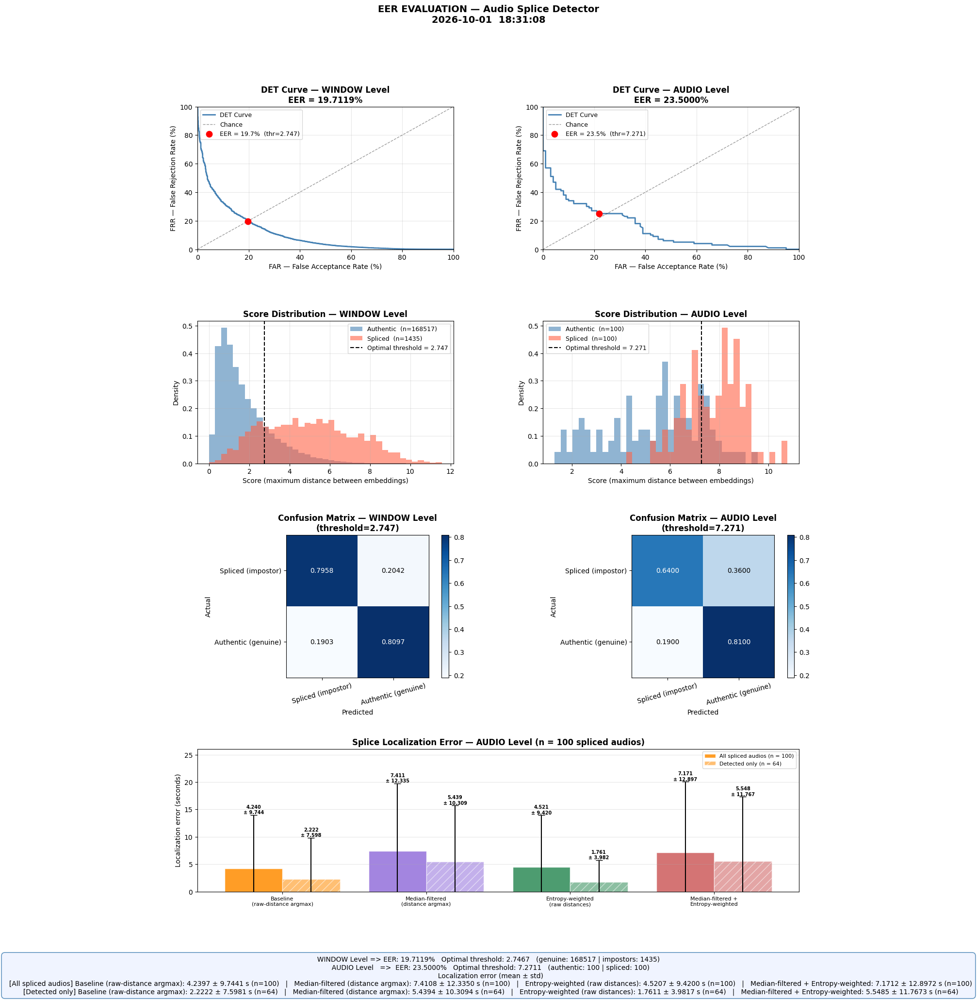

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_final_test_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
###########################################
"""FINAL EVALUATION — pure test set, with the frozen threshold - Manhattan"""
###########################################
final_test_results_manhattan = evaluate_eer_complete(
    model=model, test_audios=test_audios, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"final_test_manhattan_{eval_run_name}",
    fixed_threshold=calibrated_threshold_manhattan,
    class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="manhattan", VI=None,
)
save_eer_results(final_test_results_manhattan, output_path=output_path,
                  run_name=f"final_test_manhattan_{eval_run_name}",
                  config_extra={"distance_metric": "manhattan"})

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/200 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/20 [00:00<?, ?it/s]

   FIXED threshold used: 0.1813  | FAR: 20.5582%  | FRR: 18.4319%  (reference EER for this sample: 19.4687%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 6.4967 ± 11.5997 s (n=100)   |   Median-filtered (distance argmax): 5.7300 ± 11.4533 s (n=100)   |   Entropy-weighted (raw distances): 5.5339 ± 10.9438 s (n=100)   |   Median-filtered + Entropy-weighted: 6.1635 ± 12.1669 s (n=100)
  [Detected only] Baseline (raw-distance argmax): 3.8730 ± 9.1652 s (n=66)   |   Median-filtered (distance argmax): 5.1237 ± 11.0345 s (n=66)   |   Entropy-weighted (raw distances): 3.6117 ± 8.7557 s (n=66)   |   Median-filtered + Entropy-weighted: 6.0836 ± 12.5909 s (n=66)
   FIXED threshold used: 1.2700  | FAR: 34.0000%  | FRR: 21.0000%  (reference EER for this sample: 27.0000%)
Threshold used for generate_forensic_report(): 0.1813
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_repo

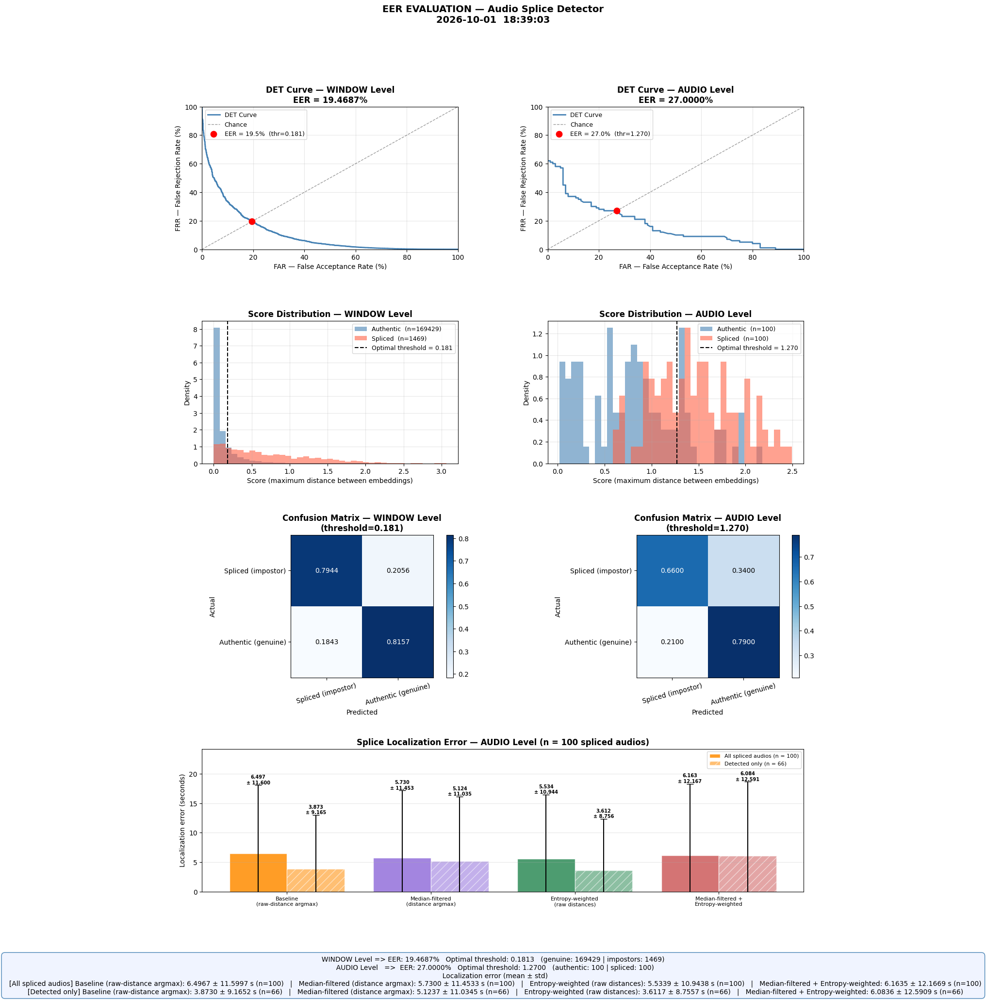

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_final_test_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
###########################################
"""FINAL EVALUATION — pure test set, with the frozen threshold - SNR"""
###########################################
final_test_results_snr = evaluate_eer_complete(
    model=model, test_audios=test_audios, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"final_test_snr_{eval_run_name}",
    fixed_threshold=calibrated_threshold_snr,
    class_names=CM_CLASS_NAMES_DETECTION, normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="snr", VI=None,
)
save_eer_results(final_test_results_snr, output_path=output_path,
                  run_name=f"final_test_snr_{eval_run_name}",
                  config_extra={"distance_metric": "snr"})

=== FORENSIC LIKELIHOOD RATIO EVALUATION (final test set) ===


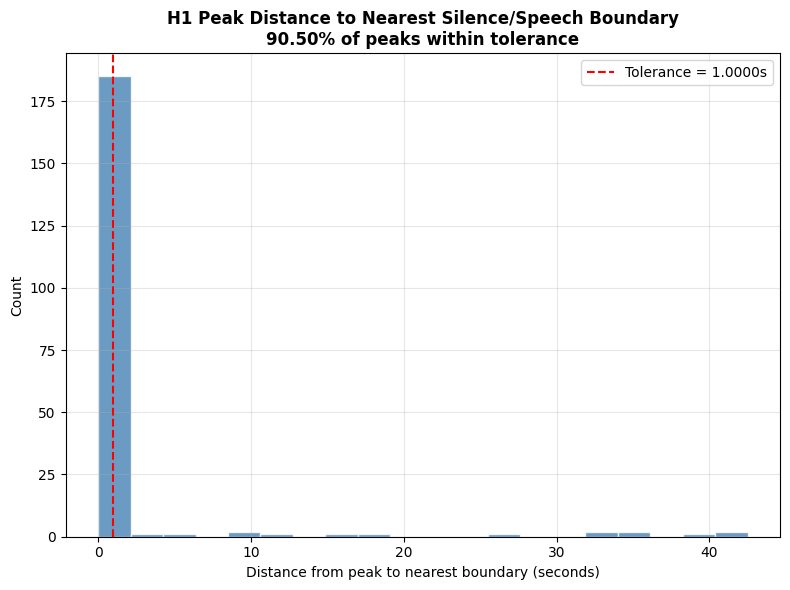

H1 peak transition diagnostic saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/h1_peak_transition_diagnostic_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Fraction of H1 peaks near a silence/speech boundary: 90.50%


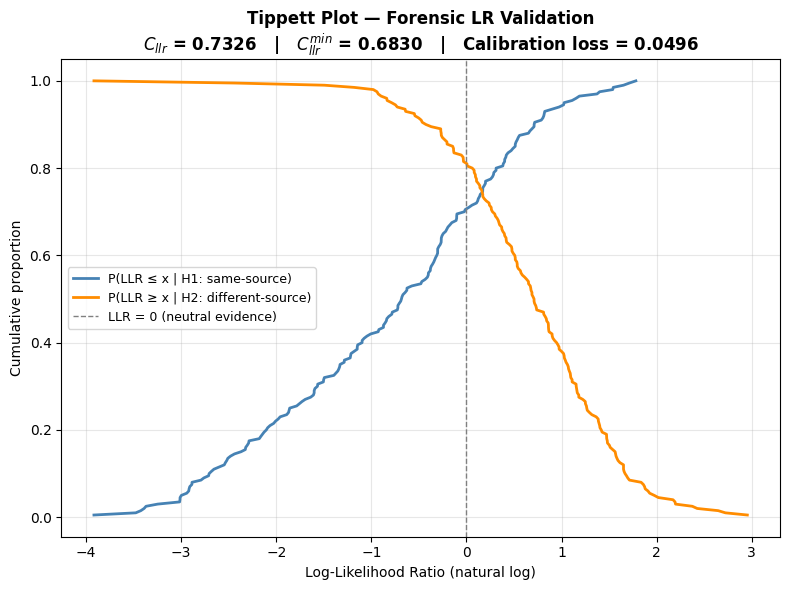

Tippett / LR validation plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/tippett_lr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
LR results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/lr_results_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl
Cllr = 0.7326 | Cllr_min = 0.6830 | Calibration loss = 0.0496


In [ ]:
###########################################
"""FINAL EVALUATION — Forensic Likelihood Ratio (pure test set)"""
###########################################
print("=== FORENSIC LIKELIHOOD RATIO EVALUATION (final test set) ===")
set_all_seeds(RANDOM_SEED)
h1_scores, h2_scores = collect_audio_level_lr_scores(
    test_audios=test_audios,
    devices=devices,
    model=model,
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, top_db=TOP_DB,
)
set_all_seeds(RANDOM_SEED)
h1_diagnostic_records = diagnose_h1_peak_transition_proximity(
    test_audios=test_audios,
    model=model,
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, top_db=TOP_DB,
)
fraction_h1_peaks_near_boundary = plot_h1_peak_transition_diagnostic(
    h1_diagnostic_records,
    tolerance_s=IA_SPLICING_TOLERANCE_S,
    output_path=h1_peak_diagnostic_png_path,
)
print(f"Fraction of H1 peaks near a silence/speech boundary: {fraction_h1_peaks_near_boundary:.2%}")

lr_results = evaluate_likelihood_ratio(
    h1_scores=h1_scores,
    h2_scores=h2_scores,
    output_path=output_path,
    run_name=eval_run_name,
    dpi=FIGURE_DPI,
)

save_lr_results(lr_results, output_path=output_path, run_name=eval_run_name)

print(f"Cllr = {lr_results['cllr']:.4f} | Cllr_min = {lr_results['cllr_min']:.4f} "
      f"| Calibration loss = {lr_results['calibration_loss']:.4f}")

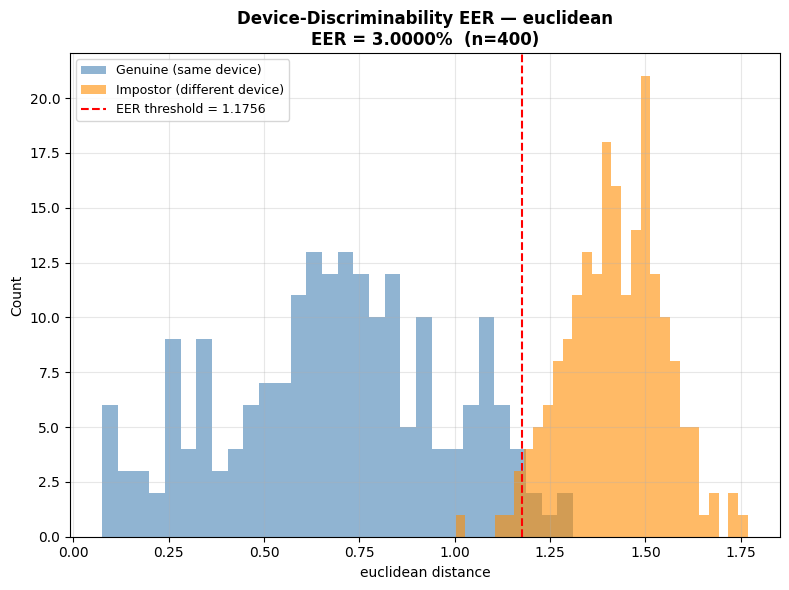

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


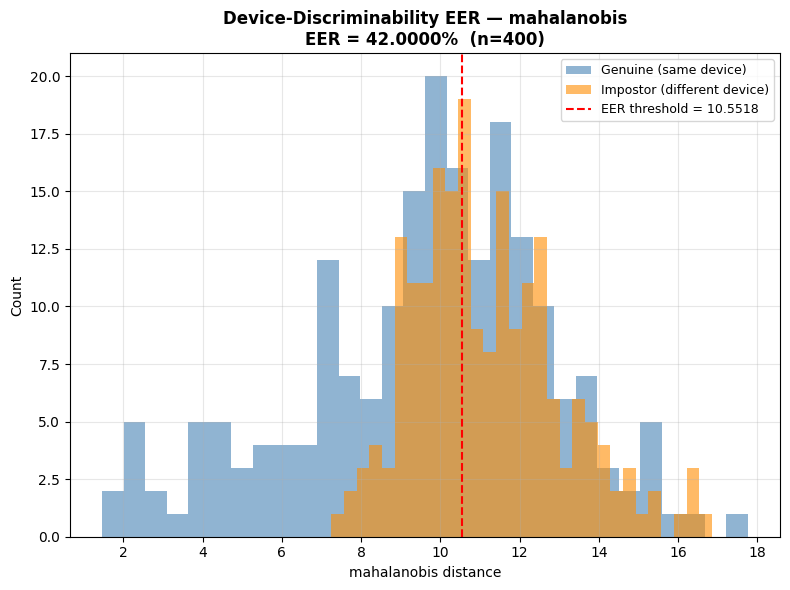

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


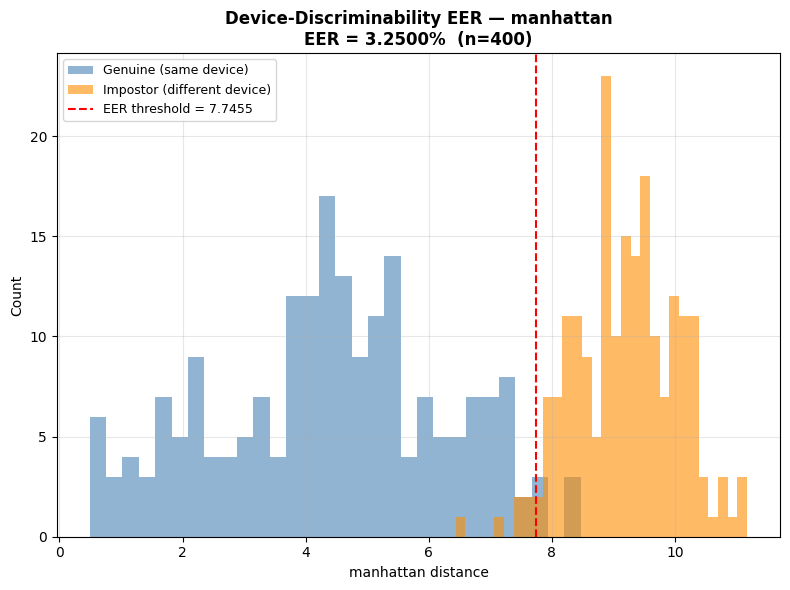

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


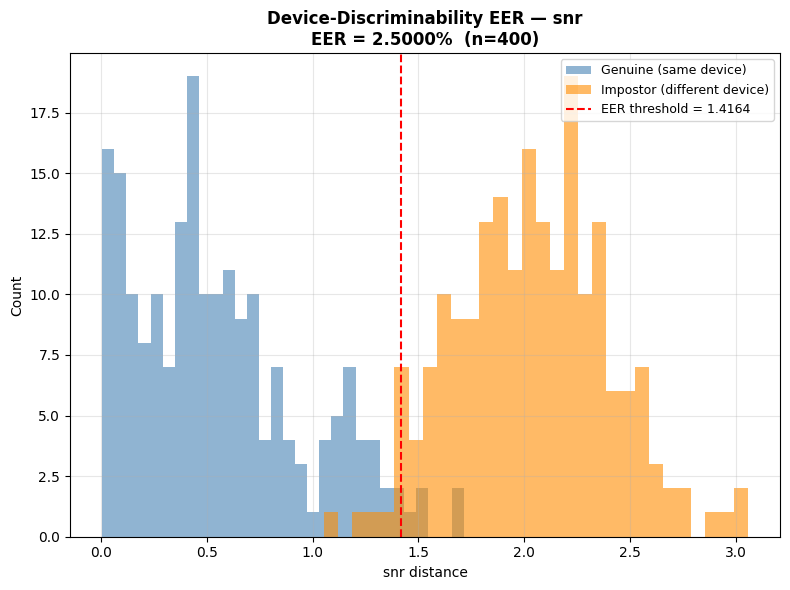

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
set_all_seeds(RANDOM_SEED)
device_discriminability_euclidean = evaluate_device_discriminability_eer(
    audio_pool=test_audios, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="euclidean", VI=None,
    output_path=output_path, run_name=eval_run_name,
)
set_all_seeds(RANDOM_SEED)
device_discriminability_mahalanobis = evaluate_device_discriminability_eer(
    audio_pool=test_audios, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
    output_path=output_path, run_name=eval_run_name,
)
set_all_seeds(RANDOM_SEED)
device_discriminability_manhattan = evaluate_device_discriminability_eer(
    audio_pool=test_audios, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="manhattan", VI=None,
    output_path=output_path, run_name=eval_run_name,
)
set_all_seeds(RANDOM_SEED)
device_discriminability_snr = evaluate_device_discriminability_eer(
    audio_pool=test_audios, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="snr", VI=None,
    output_path=output_path, run_name=eval_run_name,
)

Raw distance EER:     4.7500%  (threshold = 1.1243)
Calibrated score EER: 4.7500%  (threshold = 0.1324)


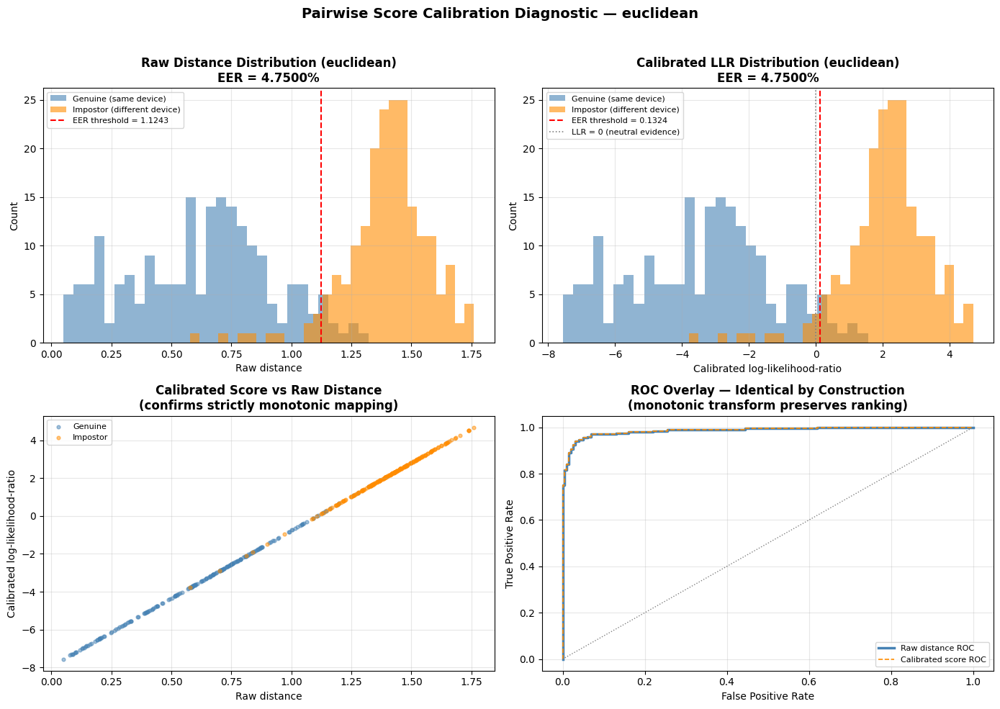

Pairwise calibration diagnostic plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_calibration_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Pairwise score calibration comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_score_calibration_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
set_all_seeds(RANDOM_SEED)
pairwise_calibration_comparison = compare_raw_vs_calibrated_score(
    model=model, device=device,
    calibration_audio_pool=val_audios,      # calibration only, never test
    evaluation_audio_pool=test_audios,      # never-seen pairs
    n_pairs_calibration=N_PAIRS_ROBUSTNESS,   # or N_PAIRS_PAIRWISE_CALIBRATION
    n_pairs_evaluation=N_PAIRS_ROBUSTNESS,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="euclidean", VI=None,
    output_path=output_path, run_name=eval_run_name,
)

Raw distance EER:     42.0000%  (threshold = 10.3396)
Calibrated score EER: 42.0000%  (threshold = 0.0785)


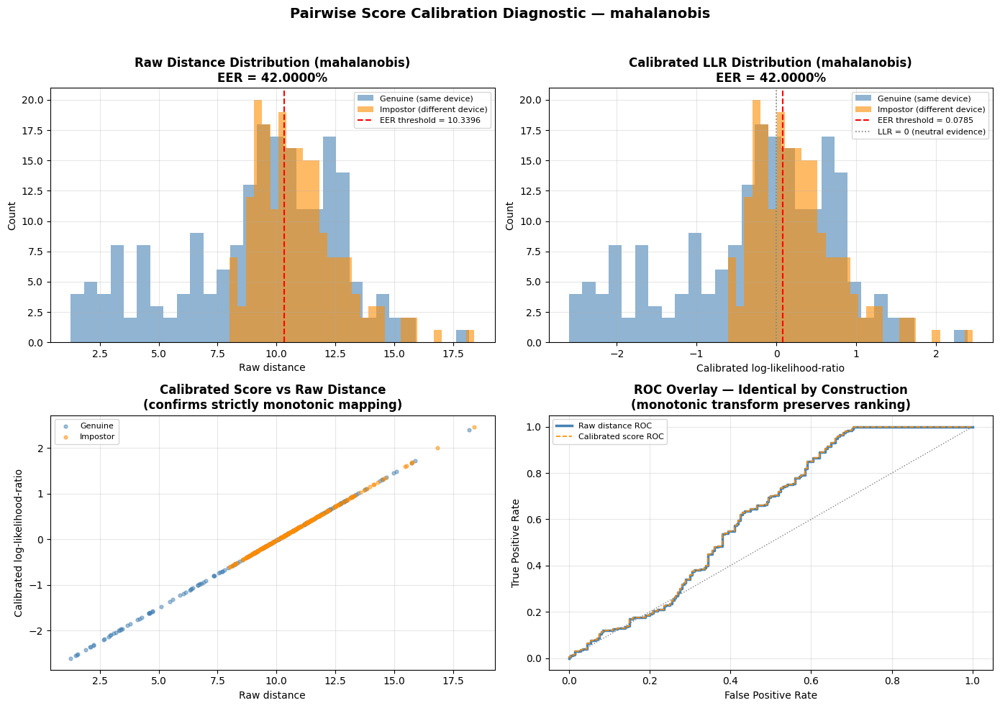

Pairwise calibration diagnostic plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_calibration_mahalanobis_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Pairwise score calibration comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_score_calibration_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
#pairwise calibration with mahalonobis
set_all_seeds(RANDOM_SEED)
pairwise_calibration_comparison_mahalanobis = compare_raw_vs_calibrated_score(
    model=model, device=device,
    calibration_audio_pool=val_audios, evaluation_audio_pool=test_audios,
    n_pairs_calibration=N_PAIRS_ROBUSTNESS, n_pairs_evaluation=N_PAIRS_ROBUSTNESS,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
    output_path=output_path, run_name=f"mahalanobis_{eval_run_name}",
)

Raw distance EER:     5.0000%  (threshold = 7.1788)
Calibrated score EER: 5.0000%  (threshold = -0.4158)


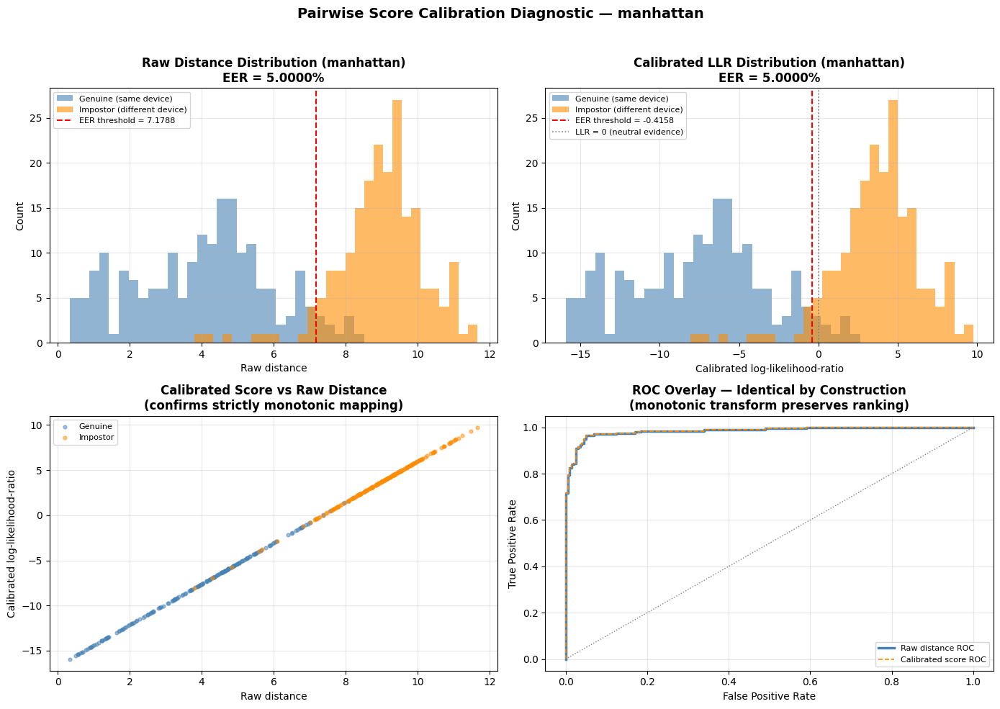

Pairwise calibration diagnostic plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_calibration_manhattan_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Pairwise score calibration comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_score_calibration_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
set_all_seeds(RANDOM_SEED)
pairwise_calibration_comparison_manhattan = compare_raw_vs_calibrated_score(
    model=model, device=device,
    calibration_audio_pool=val_audios, evaluation_audio_pool=test_audios,
    n_pairs_calibration=N_PAIRS_ROBUSTNESS, n_pairs_evaluation=N_PAIRS_ROBUSTNESS,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="manhattan", VI=None,
    output_path=output_path, run_name=f"manhattan_{eval_run_name}",
)

Raw distance EER:     4.2500%  (threshold = 1.2466)
Calibrated score EER: 4.2500%  (threshold = -0.3685)


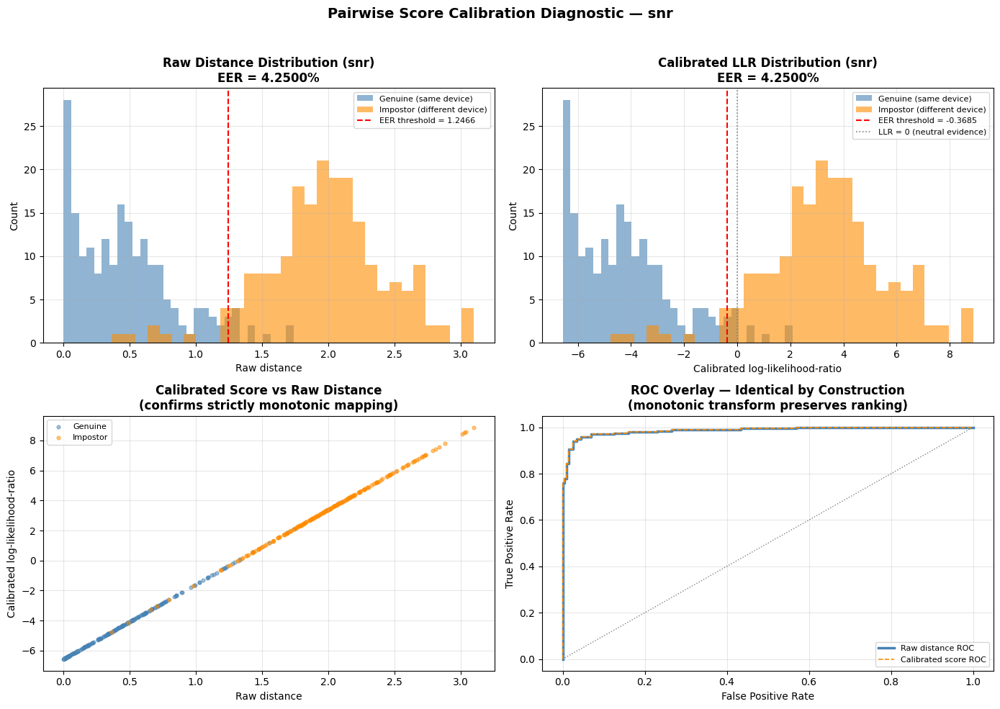

Pairwise calibration diagnostic plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_calibration_snr_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Pairwise score calibration comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/pairwise_score_calibration_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
set_all_seeds(RANDOM_SEED)
pairwise_calibration_comparison_snr = compare_raw_vs_calibrated_score(
    model=model, device=device,
    calibration_audio_pool=val_audios, evaluation_audio_pool=test_audios,
    n_pairs_calibration=N_PAIRS_ROBUSTNESS, n_pairs_evaluation=N_PAIRS_ROBUSTNESS,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="snr", VI=None,
    output_path=output_path, run_name=f"snr_{eval_run_name}",
)

In [ ]:
###########################################
"""Load Pure IA-Segment Dataset (audio-level genuine pool)"""
###########################################
if os.path.exists(ia_pure_set_dataset_path):
    print(f"ia_pure_set_dataset already exists, loading from {ia_pure_set_dataset_path}")
    with open(ia_pure_set_dataset_path, "rb") as f:
        ia_pure_set_dataset = pickle.load(f)
else:
    ia_pure_set_dataset = load_ia_pure_set()
    with open(ia_pure_set_dataset_path, "wb") as f:
        pickle.dump(ia_pure_set_dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"ia_pure_set_dataset saved to {ia_pure_set_dataset_path}")

ia_pure_set_dataset already exists, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_pure_set_dataset.pkl


=== FINAL EVALUATION ON IA-SPLICING SET (frozen threshold) ===
ia_splicing_dataset not in memory, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_dataset.pkl
 Computing WINDOW-level detection (AI-splicing set) 
   FIXED threshold used: 0.4264  | FAR: 56.8153%  | FRR: 40.5467%  (reference EER for this sample: 48.2358%)
 Computing AUDIO-level detection (IA-splicing set) 
   Detection rate:    74.6914%
   Localization rate (baseline, argmax distance): 2.4691%  (±1.0s)
   Localization rate (median-filtered):            2.4691%  (±1.0s)
   Localization rate (entropy-weighted):           3.0864%  (±1.0s)
   Localization rate (median-filtered + entropy):  3.0864%  (±1.0s)
 Computing AUDIO-level EER (IA-splicing set) 
   FIXED threshold used: 1.1323  | FAR: 25.3086%  | FRR: 20.0000%  (reference EER for this sample: 20.6852%)
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_report_ia_

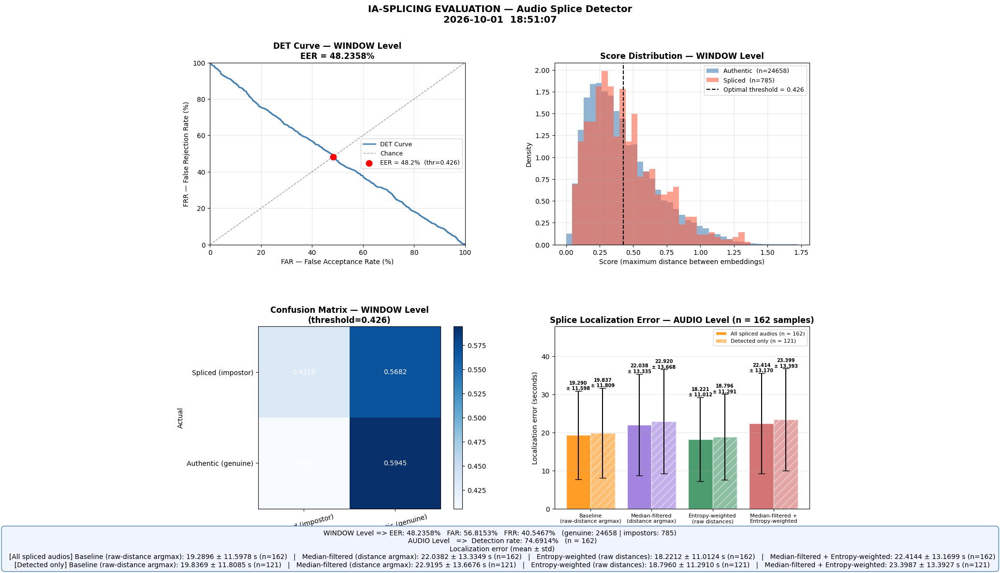

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_history.csv


In [ ]:
###########################################
"""FINAL EVALUATION — IA-splicing set (ground-truth cut, frozen threshold)"""
###########################################
print("=== FINAL EVALUATION ON IA-SPLICING SET (frozen threshold) ===")

if 'ia_splicing_dataset' not in dir():
    print(f"ia_splicing_dataset not in memory, loading from {ia_splicing_dataset_path}")
    with open(ia_splicing_dataset_path, "rb") as f:
        ia_splicing_dataset = pickle.load(f)

ia_splicing_results = evaluate_ia_splicing_complete(
    model=model, ia_dataset=ia_splicing_dataset,
    #global_mean=global_mean, global_std=global_std,
    genuine_audios=test_audios, n_genuine_audios_eer=N_AUDIOS_TEST_EER,
    device=device,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    fixed_threshold=calibrated_threshold,
    tolerance_s=IA_SPLICING_TOLERANCE_S,
    margin_s=IA_SPLICING_MARGIN_S,
    save_pdf=True,
    output_path=output_path,
    run_name=f"ia_splicing_{eval_run_name}",
    class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE,
    dpi=FIGURE_DPI, median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW, distance_metric="euclidean", VI=mahalanobis_vi
)
save_ia_splicing_results(
    ia_splicing_results, output_path=output_path, run_name=eval_run_name,
    csv_name=ia_splicing_history_csv,
    config_extra={"SR": SR, "N_FFT": N_FFT, "WIN_LENGTH_SEC": WIN_LENGTH_SEC,
                  "IA_SPLICING_MARGIN_S": IA_SPLICING_MARGIN_S,
                  "IA_SPLICING_TOLERANCE_S": IA_SPLICING_TOLERANCE_S},
)
with open(os.path.join(output_path, f"ia_splicing_detail_{eval_run_name}.pkl"), "wb") as f:
    pickle.dump(ia_splicing_results, f, protocol=pickle.HIGHEST_PROTOCOL)

=== FINAL EVALUATION ON IA-SPLICING SET (Mahalanobis, frozen threshold) ===
 Computing WINDOW-level detection (AI-splicing set) 
   FIXED threshold used: 6.7688  | FAR: 61.2739%  | FRR: 35.3313%  (reference EER for this sample: 48.0496%)
 Computing AUDIO-level detection (IA-splicing set) 
   Detection rate:    73.4568%
   Localization rate (baseline, argmax distance): 1.8519%  (±1.0s)
   Localization rate (median-filtered):            1.8519%  (±1.0s)
   Localization rate (entropy-weighted):           2.4691%  (±1.0s)
   Localization rate (median-filtered + entropy):  0.6173%  (±1.0s)
 Computing AUDIO-level EER (IA-splicing set) 
   FIXED threshold used: 13.5693  | FAR: 26.5432%  | FRR: 34.5000%  (reference EER for this sample: 29.2562%)
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_report_ia_splicing_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


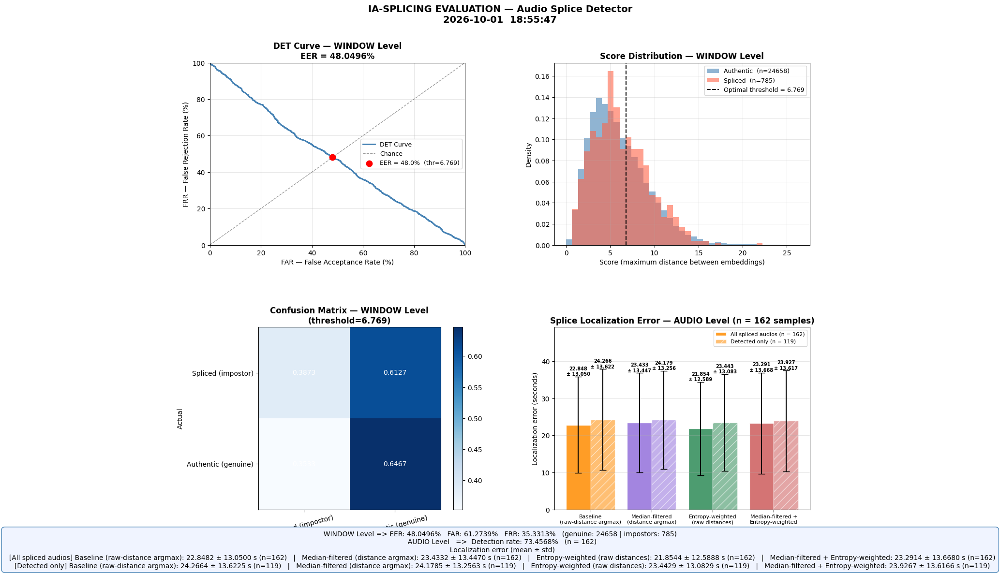

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_history.csv


In [ ]:
##########################################
"""FINAL EVALUATION — IA-splicing set (ground-truth cut, frozen threshold) — MAHALANOBIS"""
###########################################
print("=== FINAL EVALUATION ON IA-SPLICING SET (Mahalanobis, frozen threshold) ===")

if 'ia_splicing_dataset' not in dir():
    print(f"ia_splicing_dataset not in memory, loading from {ia_splicing_dataset_path}")
    with open(ia_splicing_dataset_path, "rb") as f:
        ia_splicing_dataset = pickle.load(f)

ia_splicing_results_mahalanobis = evaluate_ia_splicing_complete(
    model=model, ia_dataset=ia_splicing_dataset,
    genuine_audios=test_audios, n_genuine_audios_eer=N_AUDIOS_TEST_EER,
    device=device,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    fixed_threshold=calibrated_threshold_mahalanobis,
    tolerance_s=IA_SPLICING_TOLERANCE_S,
    margin_s=IA_SPLICING_MARGIN_S,
    save_pdf=True,
    output_path=output_path,
    run_name=f"ia_splicing_mahalanobis_{eval_run_name}",
    class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE,
    dpi=FIGURE_DPI, median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
)
save_ia_splicing_results(
    ia_splicing_results_mahalanobis, output_path=output_path, run_name=f"mahalanobis_{eval_run_name}",
    csv_name=ia_splicing_history_csv,
    config_extra={"SR": SR, "N_FFT": N_FFT, "WIN_LENGTH_SEC": WIN_LENGTH_SEC,
                  "IA_SPLICING_MARGIN_S": IA_SPLICING_MARGIN_S,
                  "IA_SPLICING_TOLERANCE_S": IA_SPLICING_TOLERANCE_S,
                  "distance_metric": "mahalanobis"},
)
with open(os.path.join(output_path, f"ia_splicing_detail_mahalanobis_{eval_run_name}.pkl"), "wb") as f:
    pickle.dump(ia_splicing_results_mahalanobis, f, protocol=pickle.HIGHEST_PROTOCOL)

 Computing WINDOW-level detection (AI-splicing set) 
   FIXED threshold used: 2.7467  | FAR: 56.6879%  | FRR: 40.6643%  (reference EER for this sample: 48.2824%)
 Computing AUDIO-level detection (IA-splicing set) 
   Detection rate:    77.1605%
   Localization rate (baseline, argmax distance): 1.8519%  (±1.0s)
   Localization rate (median-filtered):            2.4691%  (±1.0s)
   Localization rate (entropy-weighted):           1.8519%  (±1.0s)
   Localization rate (median-filtered + entropy):  3.0864%  (±1.0s)
 Computing AUDIO-level EER (IA-splicing set) 
   FIXED threshold used: 7.2711  | FAR: 22.8395%  | FRR: 20.0000%  (reference EER for this sample: 20.9938%)
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_report_ia_splicing_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


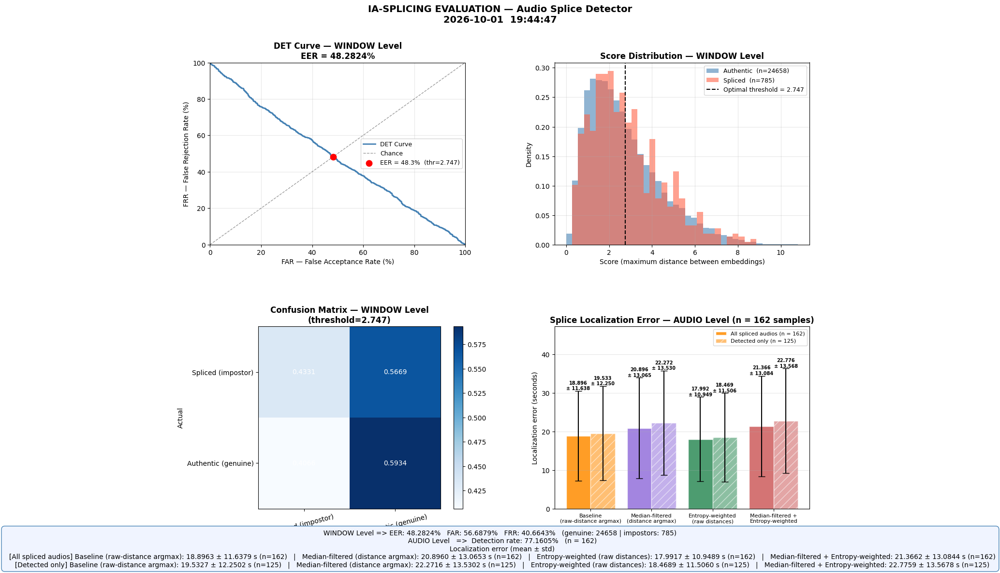

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_history.csv


In [ ]:
ia_splicing_results_manhattan = evaluate_ia_splicing_complete(
    model=model, ia_dataset=ia_splicing_dataset,
    genuine_audios=test_audios, n_genuine_audios_eer=N_AUDIOS_TEST_EER,
    device=device,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    fixed_threshold=calibrated_threshold_manhattan,
    tolerance_s=IA_SPLICING_TOLERANCE_S,
    margin_s=IA_SPLICING_MARGIN_S,
    save_pdf=True,
    output_path=output_path,
    run_name=f"ia_splicing_manhattan_{eval_run_name}",
    class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE,
    dpi=FIGURE_DPI, median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW, distance_metric="manhattan", VI=None,
)
save_ia_splicing_results(
    ia_splicing_results_manhattan, output_path=output_path, run_name=f"manhattan_{eval_run_name}",
    csv_name=ia_splicing_history_csv,
    config_extra={"SR": SR, "N_FFT": N_FFT, "WIN_LENGTH_SEC": WIN_LENGTH_SEC,
                  "IA_SPLICING_MARGIN_S": IA_SPLICING_MARGIN_S,
                  "IA_SPLICING_TOLERANCE_S": IA_SPLICING_TOLERANCE_S,
                  "distance_metric": "manhattan"},
)
with open(os.path.join(output_path, f"ia_splicing_detail_manhattan_{eval_run_name}.pkl"), "wb") as f:
    pickle.dump(ia_splicing_results_manhattan, f, protocol=pickle.HIGHEST_PROTOCOL)

 Computing WINDOW-level detection (AI-splicing set) 
   FIXED threshold used: 0.1813  | FAR: 56.0510%  | FRR: 40.8062%  (reference EER for this sample: 48.1688%)
 Computing AUDIO-level detection (IA-splicing set) 
   Detection rate:    78.3951%
   Localization rate (baseline, argmax distance): 2.4691%  (±1.0s)
   Localization rate (median-filtered):            2.4691%  (±1.0s)
   Localization rate (entropy-weighted):           2.4691%  (±1.0s)
   Localization rate (median-filtered + entropy):  2.4691%  (±1.0s)
 Computing AUDIO-level EER (IA-splicing set) 
   FIXED threshold used: 1.2700  | FAR: 21.6049%  | FRR: 20.0000%  (reference EER for this sample: 21.5525%)
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_report_ia_splicing_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


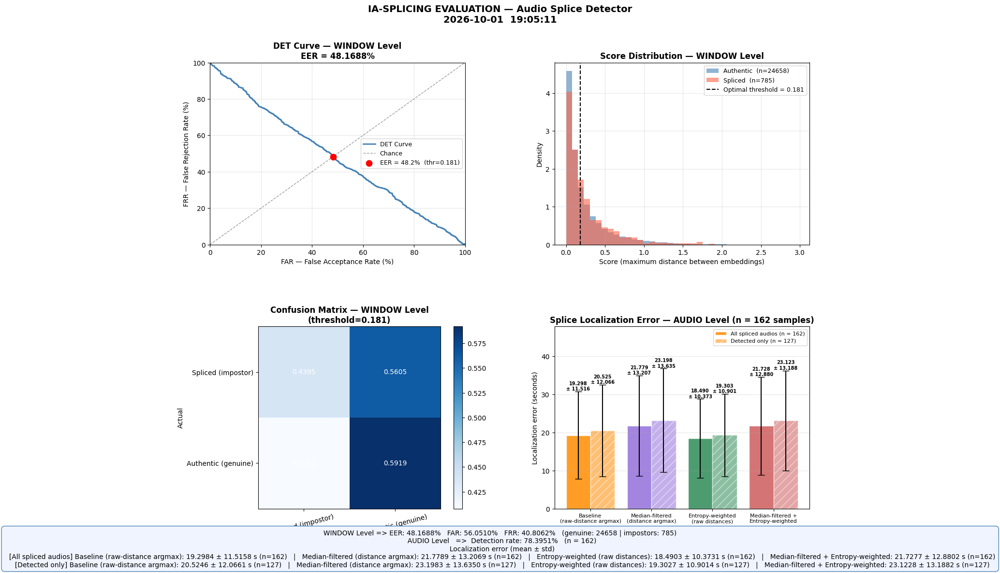

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_splicing_history.csv


In [ ]:
ia_splicing_results_snr = evaluate_ia_splicing_complete(
    model=model, ia_dataset=ia_splicing_dataset,
    genuine_audios=test_audios, n_genuine_audios_eer=N_AUDIOS_TEST_EER,
    device=device,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    fixed_threshold=calibrated_threshold_snr,
    tolerance_s=IA_SPLICING_TOLERANCE_S,
    margin_s=IA_SPLICING_MARGIN_S,
    save_pdf=True,
    output_path=output_path,
    run_name=f"ia_splicing_snr_{eval_run_name}",
    class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE,
    dpi=FIGURE_DPI, median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True,
    entropy_window=ENTROPY_LOCAL_WINDOW, distance_metric="snr", VI=None,
)
save_ia_splicing_results(
    ia_splicing_results_snr, output_path=output_path, run_name=f"snr_{eval_run_name}",
    csv_name=ia_splicing_history_csv,
    config_extra={"SR": SR, "N_FFT": N_FFT, "WIN_LENGTH_SEC": WIN_LENGTH_SEC,
                  "IA_SPLICING_MARGIN_S": IA_SPLICING_MARGIN_S,
                  "IA_SPLICING_TOLERANCE_S": IA_SPLICING_TOLERANCE_S,
                  "distance_metric": "snr"},
)
with open(os.path.join(output_path, f"ia_splicing_detail_snr_{eval_run_name}.pkl"), "wb") as f:
    pickle.dump(ia_splicing_results_snr, f, protocol=pickle.HIGHEST_PROTOCOL)

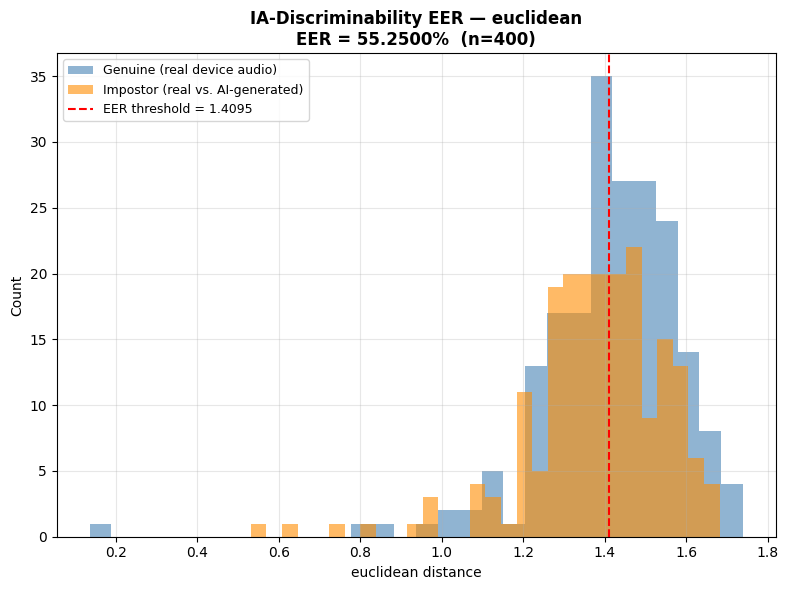

IA-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
IA-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


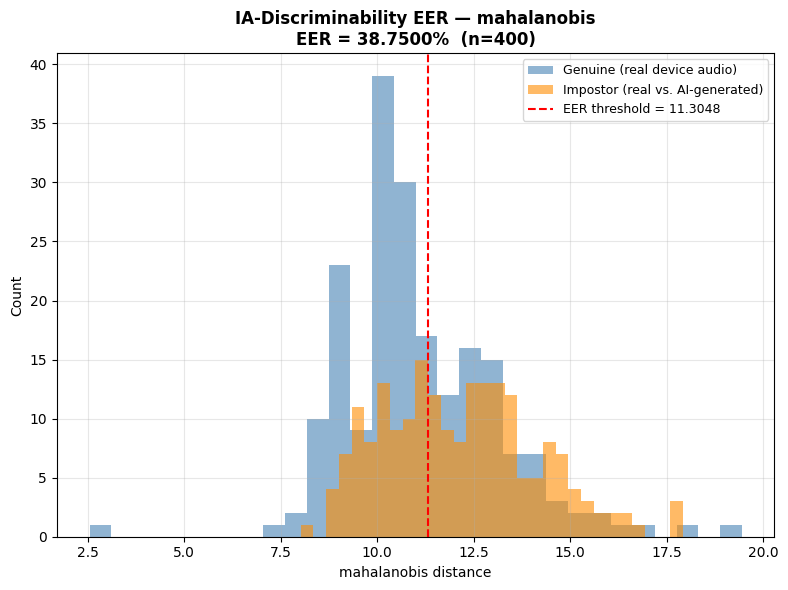

IA-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
IA-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


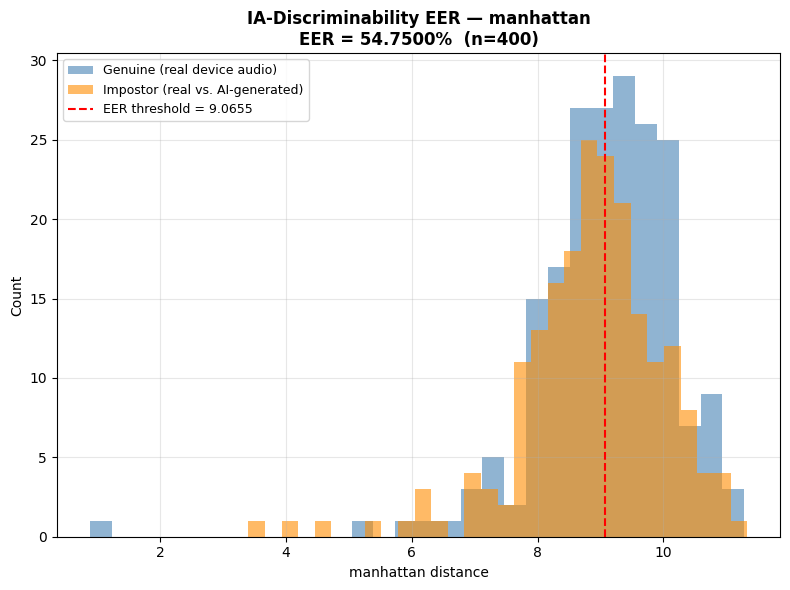

IA-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
IA-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


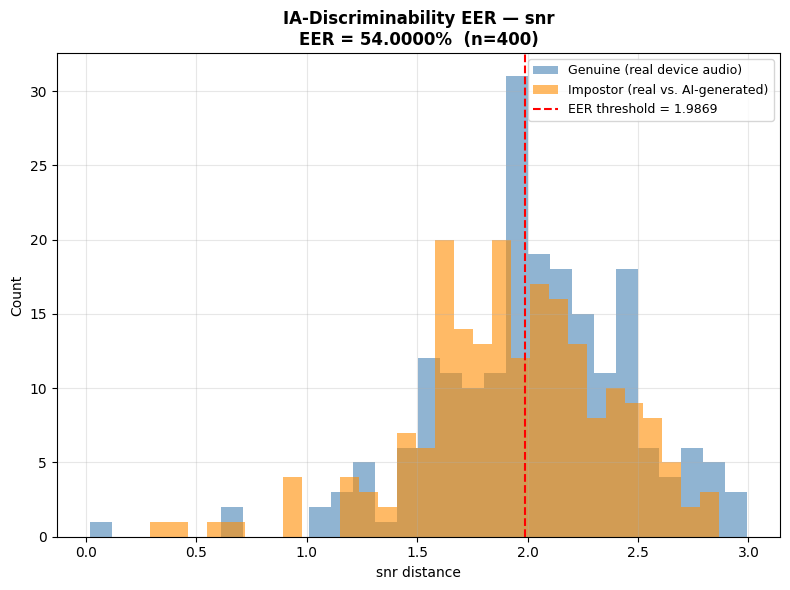

IA-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
IA-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/ia_discriminability_eer_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
set_all_seeds(RANDOM_SEED)
ia_discriminability_euclidean = evaluate_ia_discriminability_eer(
    genuine_pool=test_audios, ia_pool=ia_pure_set_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="euclidean", VI=None,
    output_path=output_path, run_name=eval_run_name,
)
set_all_seeds(RANDOM_SEED)
ia_discriminability_mahalanobis = evaluate_ia_discriminability_eer(
    genuine_pool=test_audios, ia_pool=ia_pure_set_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
    output_path=output_path, run_name=eval_run_name,
)
set_all_seeds(RANDOM_SEED)
ia_discriminability_manhattan = evaluate_ia_discriminability_eer(
    genuine_pool=test_audios, ia_pool=ia_pure_set_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="manhattan", VI=None,
    output_path=output_path, run_name=eval_run_name,
)
set_all_seeds(RANDOM_SEED)
ia_discriminability_snr = evaluate_ia_discriminability_eer(
    genuine_pool=test_audios, ia_pool=ia_pure_set_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="snr", VI=None,
    output_path=output_path, run_name=eval_run_name,
)

IA-splicing sample: Splicing_IA.wav (device=xiaomi_12, condition=speech_clean)
Ground-truth insertion boundaries: 34.8320s -> 37.2640s


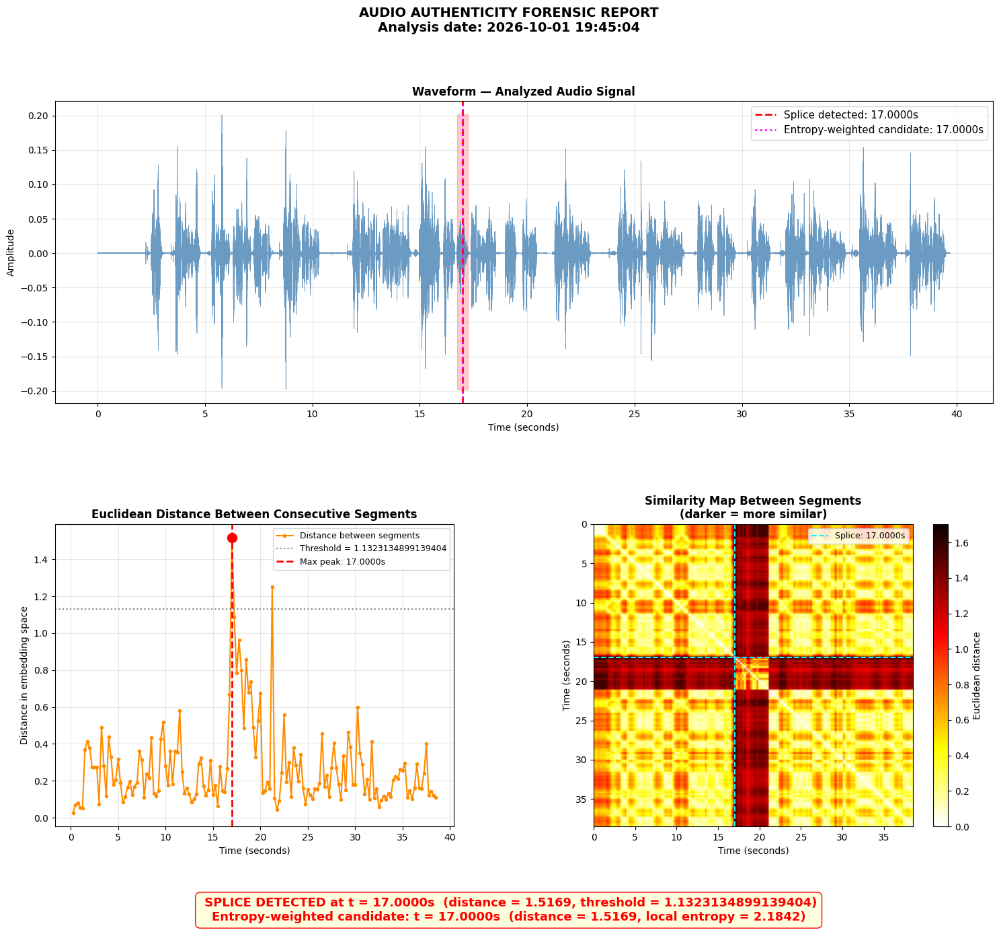


[Euclidean] Max distance found: 1.5169
[Euclidean] Current threshold:  1.1323
[Euclidean] Detected splice?:    True
[Euclidean] Model detected: splice at 17.0000s
[Euclidean] Error (nearest boundary): 17.8320s
[Euclidean] Entropy-weighted candidate: splice at 17.0000s
[Euclidean] Error (entropy, nearest boundary): 17.8320s


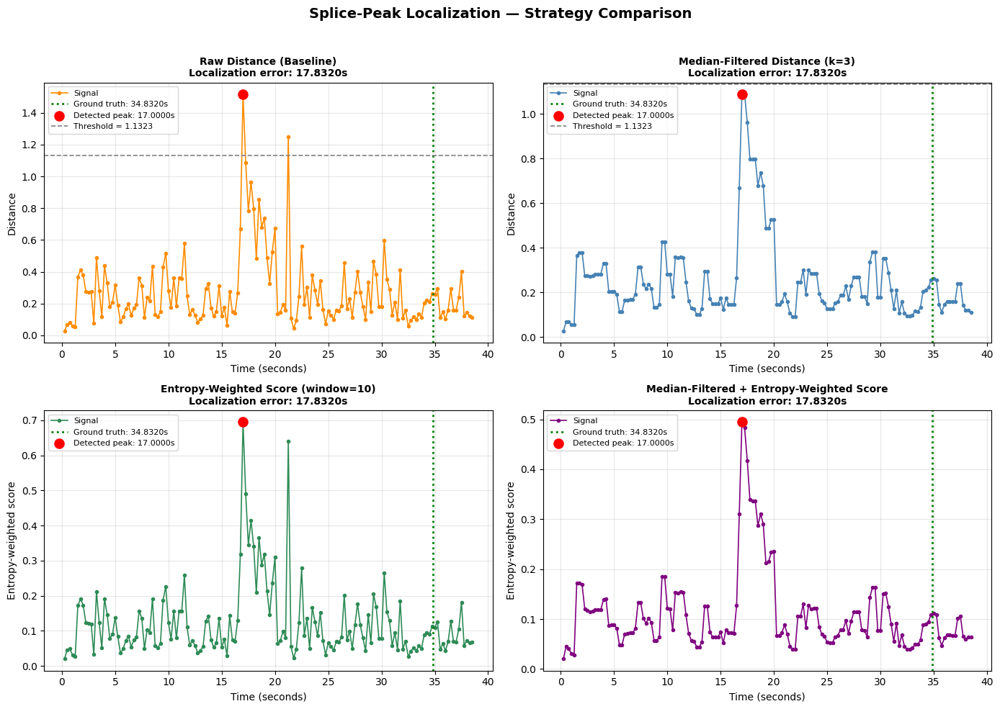

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_ia_splicing_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary (IA-splicing, Euclidean) ===
Raw Distance (Baseline)                       error = 17.8320s (detected at 17.0000s)
Median-Filtered Distance (k=3)                error = 17.8320s (detected at 17.0000s)
Entropy-Weighted Score (window=10)            error = 17.8320s (detected at 17.0000s)
Median-Filtered + Entropy-Weighted Score      error = 17.8320s (detected at 17.0000s)


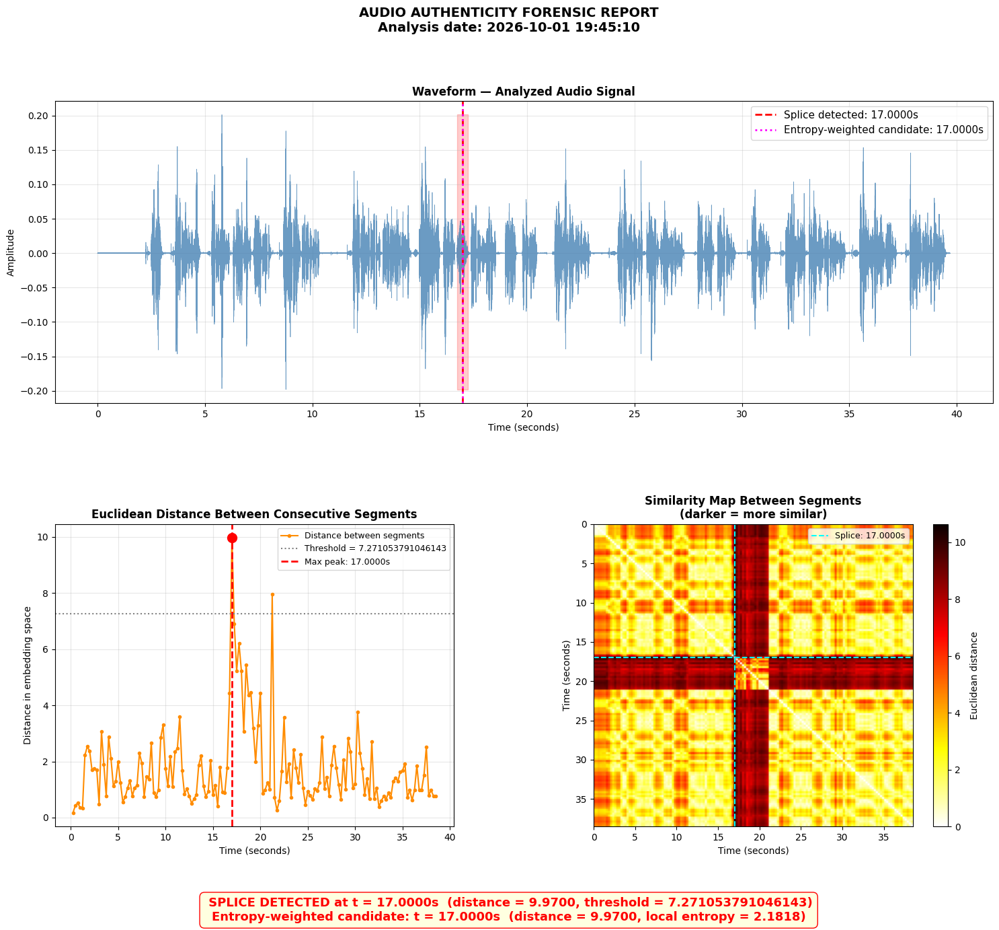


[Manhattan] Max distance found: 9.9700
[Manhattan] Current threshold:  7.2711
[Manhattan] Detected splice?:    True
[Manhattan] Model detected: splice at 17.0000s
[Manhattan] Error (nearest boundary): 17.8320s
[Manhattan] Entropy-weighted candidate: splice at 17.0000s
[Manhattan] Error (entropy, nearest boundary): 17.8320s


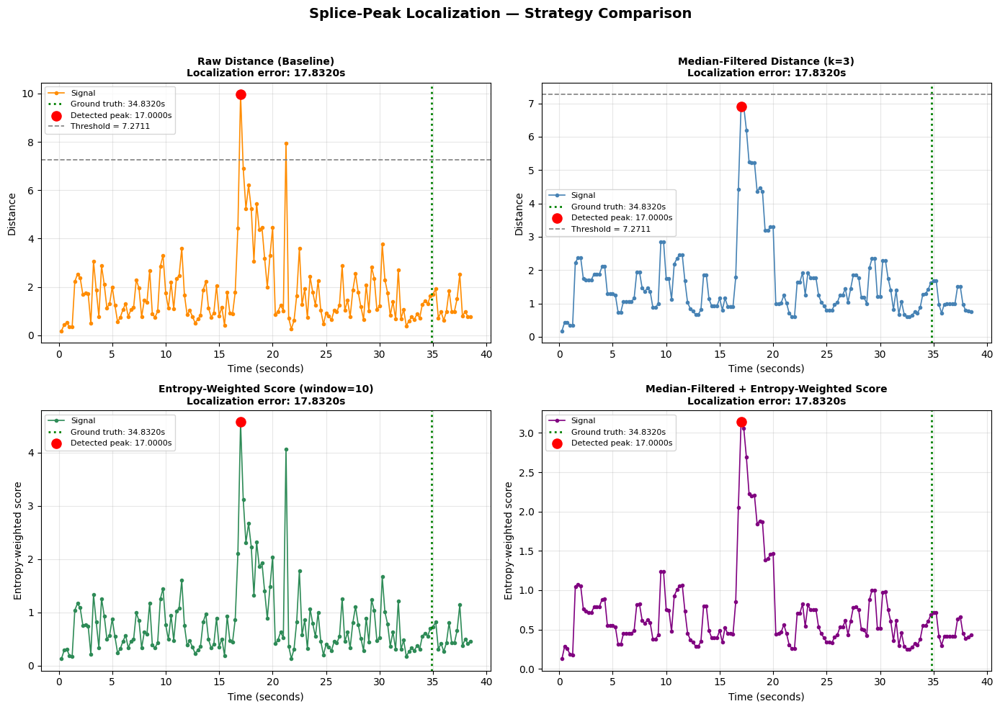

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_ia_splicing_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary (IA-splicing, Manhattan) ===
Raw Distance (Baseline)                       error = 17.8320s (detected at 17.0000s)
Median-Filtered Distance (k=3)                error = 17.8320s (detected at 17.0000s)
Entropy-Weighted Score (window=10)            error = 17.8320s (detected at 17.0000s)
Median-Filtered + Entropy-Weighted Score      error = 17.8320s (detected at 17.0000s)


In [ ]:
###########################################
"""TEST — IA-SPLICING SAMPLE (single-example forensic report, Euclidean & Manhattan)"""
###########################################
# Draws one AI-generated splice sample and runs the same single-audio forensic
# report used for the synthetic-splice TEST blocks above, comparing the
# detected splice instant against the ground-truth insertion boundaries
# reported in the sample's metadata (true_insert_start_s / true_insert_end_s).

ia_test_sample = random.choice(ia_splicing_dataset)

print(f"IA-splicing sample: {ia_test_sample['filename']} "
      f"(device={ia_test_sample['device']}, condition={ia_test_sample['condition']})")

ia_ground_truth_boundaries_s = (
    ia_test_sample['true_insert_start_s'],
    ia_test_sample['true_insert_end_s'],
)
print(f"Ground-truth insertion boundaries: "
      f"{ia_ground_truth_boundaries_s[0]:.4f}s -> {ia_ground_truth_boundaries_s[1]:.4f}s")


def _nearest_boundary_error_s(detected_time_s, boundaries_s):
    """Localization error against the closer of the two insertion boundaries."""
    return min(abs(detected_time_s - boundary_s) for boundary_s in boundaries_s)


def _run_ia_splicing_forensic_test(distance_metric, threshold, VI=None):
    forensic_result = generate_forensic_report(
        suspect_audio=ia_test_sample['audio'],
        model=model,
        device=device,
        threshold=threshold,
        compute_entropy_comparison=True,
        entropy_window=ENTROPY_LOCAL_WINDOW,
        use_pairwise_distance=True,
        distance_metric=distance_metric,
        VI=VI,
    )

    print(f"\n[{distance_metric.capitalize()}] Max distance found: {forensic_result['max_distance']:.4f}")
    print(f"[{distance_metric.capitalize()}] Current threshold:  {forensic_result['threshold_used']:.4f}")
    print(f"[{distance_metric.capitalize()}] Detected splice?:    {forensic_result['has_splice']}")

    if forensic_result['has_splice']:
        time_error = _nearest_boundary_error_s(forensic_result['splice_time_sec'], ia_ground_truth_boundaries_s)
        print(f"[{distance_metric.capitalize()}] Model detected: splice at {forensic_result['splice_time_sec']:.4f}s")
        print(f"[{distance_metric.capitalize()}] Error (nearest boundary): {time_error:.4f}s")
    else:
        print(f"[{distance_metric.capitalize()}] Model detected: AUTHENTIC AUDIO "
              f"(did not exceed threshold {forensic_result['threshold_used']:.4f})")
        print(f"[{distance_metric.capitalize()}] Max distance: {forensic_result['max_distance']:.4f}")

    if forensic_result.get('has_splice_entropy'):
        time_error_entropy = _nearest_boundary_error_s(
            forensic_result['splice_time_sec_entropy'], ia_ground_truth_boundaries_s
        )
        print(f"[{distance_metric.capitalize()}] Entropy-weighted candidate: "
              f"splice at {forensic_result['splice_time_sec_entropy']:.4f}s")
        print(f"[{distance_metric.capitalize()}] Error (entropy, nearest boundary): {time_error_entropy:.4f}s")
    else:
        print(f"[{distance_metric.capitalize()}] Entropy-weighted candidate: no distance above threshold "
              f"(max distance = {forensic_result.get('max_distance_entropy', float('nan')):.4f})")

    strategy_comparison_results = plot_filtering_strategy_comparison(
        distances=forensic_result['distances'],
        timestamps=forensic_result['timestamps'][1:],
        threshold=forensic_result['threshold_used'],
        ground_truth_time_s=ia_ground_truth_boundaries_s[0],   # primary boundary: genuine -> IA segment
        median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
        entropy_window=ENTROPY_LOCAL_WINDOW,
        output_path=output_path,
        run_name=f"ia_splicing_{distance_metric}_{eval_run_name}",
    )

    print(f"\n=== Strategy comparison summary (IA-splicing, {distance_metric.capitalize()}) ===")
    for strategy_name, strategy_metrics in strategy_comparison_results.items():
        print(f"{strategy_name:<45} error = {strategy_metrics['localization_error_s']:.4f}s "
              f"(detected at {strategy_metrics['detected_time_s']:.4f}s)")

    return forensic_result, strategy_comparison_results


ia_forensic_result_euclidean, ia_strategy_comparison_euclidean = _run_ia_splicing_forensic_test(
    distance_metric="euclidean", threshold=calibrated_threshold['audio'], VI=None,
)

ia_forensic_result_manhattan, ia_strategy_comparison_manhattan = _run_ia_splicing_forensic_test(
    distance_metric="manhattan", threshold=calibrated_threshold_manhattan['audio'], VI=None,
)

In [ ]:
def report_unseen_class_balance(evaluation_results, distance_metric, requested_audios_per_class):
    """Warns when the unseen-set audio-level evaluation could not build balanced classes."""
    audio_results = evaluation_results['audio']
    n_authentic, n_spliced = audio_results['n_authentic'], audio_results['n_spliced']
    print(f"[{distance_metric}] authentic={n_authentic}/{requested_audios_per_class} | "
          f"spliced={n_spliced}/{requested_audios_per_class}")
    if n_authentic < requested_audios_per_class or n_spliced < requested_audios_per_class:
        print(f"WARNING [{distance_metric}]: classes are incomplete or imbalanced; "
              f"EER is not strictly comparable with a fully balanced run.")

=== FINAL EVALUATION ON UNSEEN-DEVICE CROSS-CORPUS SET (frozen threshold) ===
unseen_devices_dataset already exists, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/unseen_devices_dataset.pkl
 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/504 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/21 [00:00<?, ?it/s]

   FIXED threshold used: 0.4264  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 11.0969%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 0.5755 ± 0.3471 s (n=100)   |   Median-filtered (distance argmax): 0.6333 ± 0.9269 s (n=100)   |   Entropy-weighted (raw distances): 0.5592 ± 0.3518 s (n=100)   |   Median-filtered + Entropy-weighted: 0.6477 ± 1.6490 s (n=100)
   FIXED threshold used: 1.1323  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 1.0000%)
Threshold used for generate_forensic_report(): 0.4264
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


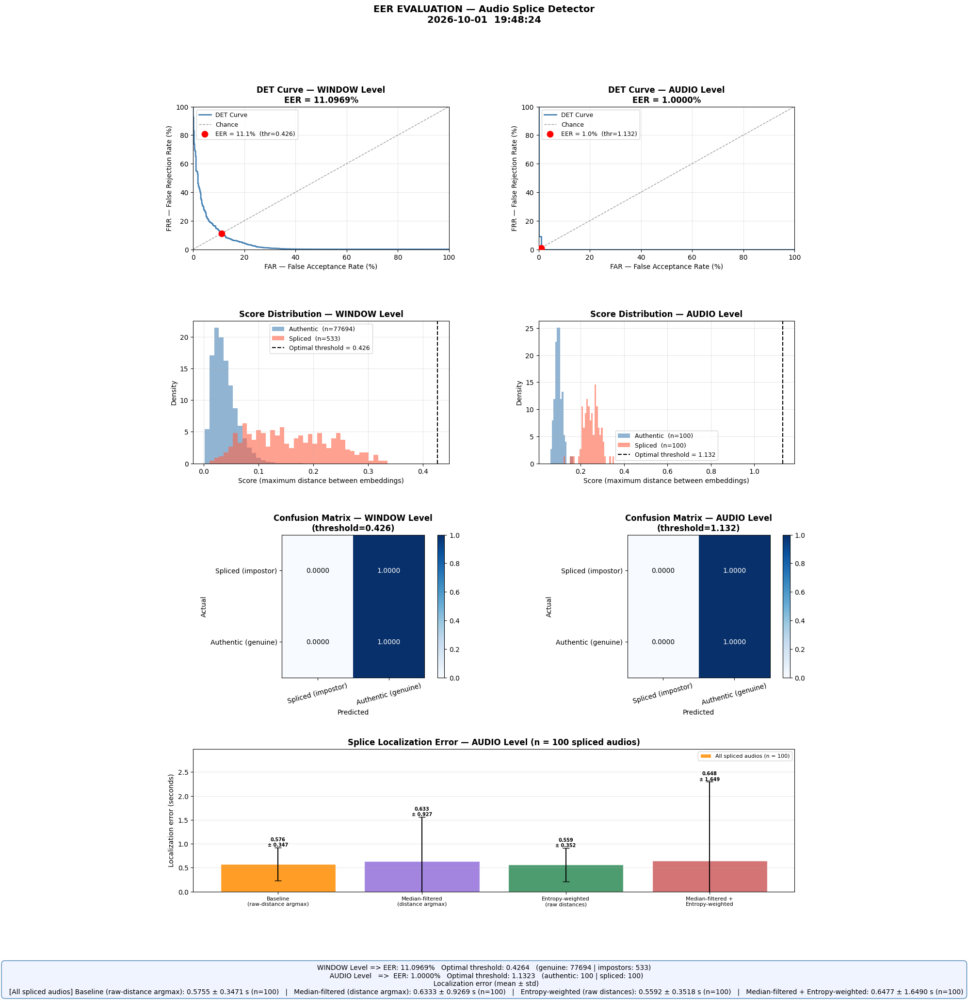

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
###########################################
"""FINAL EVALUATION — Cross-Corpus Generalization (unseen devices, frozen threshold)"""
###########################################
print("=== FINAL EVALUATION ON UNSEEN-DEVICE CROSS-CORPUS SET (frozen threshold) ===")

if os.path.exists(unseen_devices_dataset_path):
    print(f"unseen_devices_dataset already exists, loading from {unseen_devices_dataset_path}")
    with open(unseen_devices_dataset_path, "rb") as f:
        unseen_devices_dataset = pickle.load(f)
else:
    unseen_devices_dataset = load_unseen_devices_dataset()
    with open(unseen_devices_dataset_path, "wb") as f:
        pickle.dump(unseen_devices_dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"unseen_devices_dataset saved to {unseen_devices_dataset_path}")
set_all_seeds(RANDOM_SEED)
unseen_devices_results = evaluate_eer_complete(
    model=model,
    test_audios=unseen_devices_dataset,
    device_to_label=device_to_label,   # unused internally; kept for signature compatibility
    device=device,
    n_audios_test=N_AUDIOS_TEST_EER,
    save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"unseen_devices_{eval_run_name}",
    fixed_threshold=calibrated_threshold, class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
)
save_eer_results(
    unseen_devices_results, output_path=output_path,
    run_name=f"unseen_devices_{eval_run_name}",
    config_extra={"distance_metric": "euclidean", "source": "external_cross_corpus",
              "eer_module_hash": EER_MODULE_HASH, "random_seed": RANDOM_SEED},
)


 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/504 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/21 [00:00<?, ?it/s]

   FIXED threshold used: 6.7688  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 12.9456%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 0.6249 ± 0.3297 s (n=100)   |   Median-filtered (distance argmax): 1.1965 ± 1.9808 s (n=100)   |   Entropy-weighted (raw distances): 1.2283 ± 2.3406 s (n=100)   |   Median-filtered + Entropy-weighted: 1.3037 ± 2.5285 s (n=100)
   FIXED threshold used: 13.5693  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 4.0000%)
Threshold used for generate_forensic_report(): 6.7688
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_unseen_devices_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


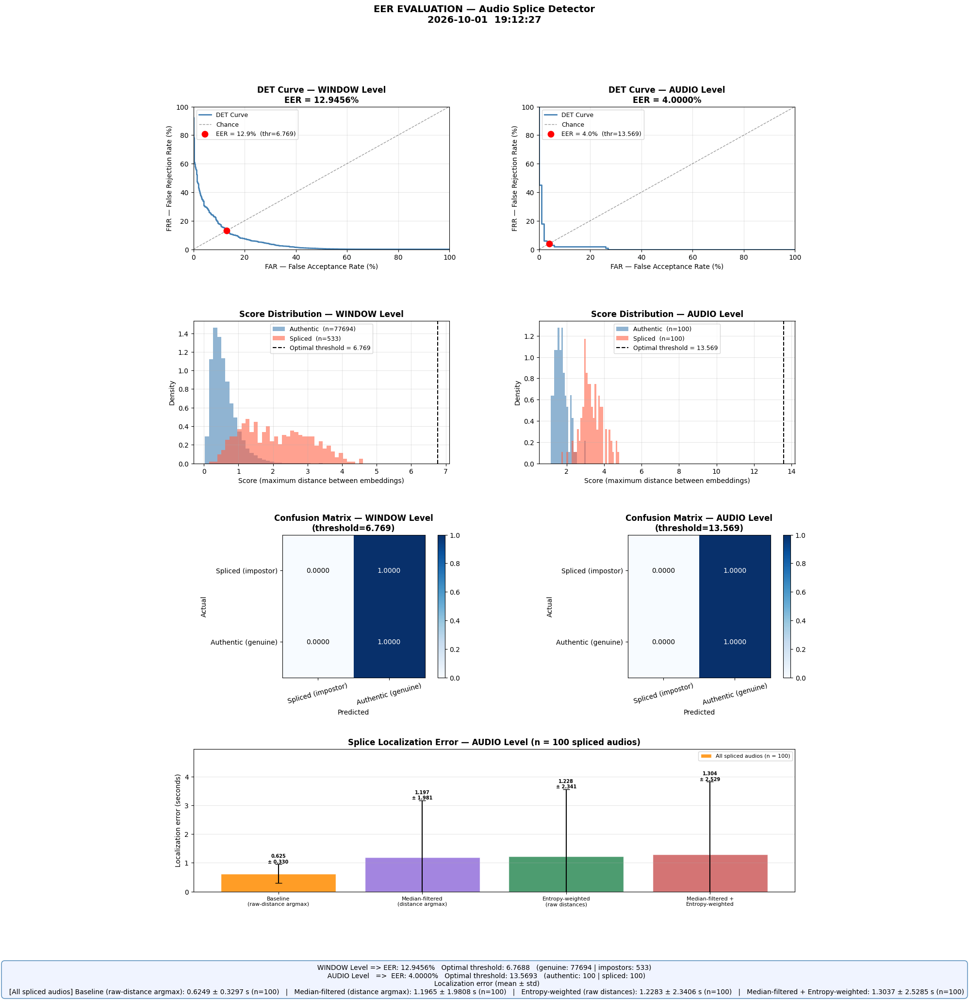

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_unseen_devices_mahalanobis_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
set_all_seeds(RANDOM_SEED)
unseen_devices_results_mahalanobis = evaluate_eer_complete(
    model=model, test_audios=unseen_devices_dataset, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"unseen_devices_mahalanobis_{eval_run_name}",
    fixed_threshold=calibrated_threshold_mahalanobis, class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
)
save_eer_results(
    unseen_devices_results_mahalanobis, output_path=output_path,
    run_name=f"unseen_devices_mahalanobis_{eval_run_name}",
    config_extra={"distance_metric": "mahalanobis", "source": "external_cross_corpus",
              "eer_module_hash": EER_MODULE_HASH, "random_seed": RANDOM_SEED},
)


 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/504 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/21 [00:00<?, ?it/s]

   FIXED threshold used: 2.7467  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 11.0686%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 0.5702 ± 0.3534 s (n=100)   |   Median-filtered (distance argmax): 0.5558 ± 0.7114 s (n=100)   |   Entropy-weighted (raw distances): 0.5663 ± 0.3522 s (n=100)   |   Median-filtered + Entropy-weighted: 0.6485 ± 1.6487 s (n=100)
   FIXED threshold used: 7.2711  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 1.0000%)
Threshold used for generate_forensic_report(): 2.7467
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_unseen_devices_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


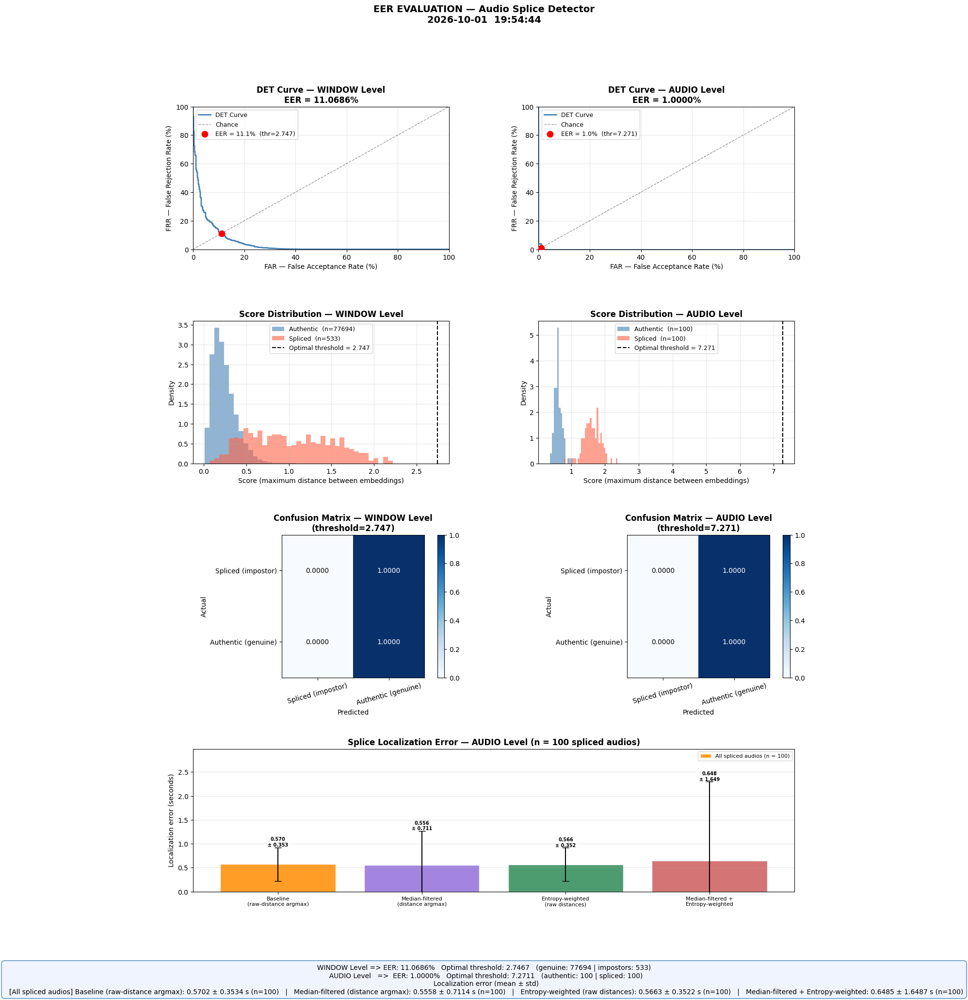

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_unseen_devices_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
set_all_seeds(RANDOM_SEED)
unseen_devices_results_manhattan = evaluate_eer_complete(
    model=model, test_audios=unseen_devices_dataset, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"unseen_devices_manhattan_{eval_run_name}",
    fixed_threshold=calibrated_threshold_manhattan, class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="manhattan", VI=None,
)
save_eer_results(
    unseen_devices_results_manhattan, output_path=output_path,
    run_name=f"unseen_devices_manhattan_{eval_run_name}",
    config_extra={"distance_metric": "manhattan", "source": "external_cross_corpus",
              "eer_module_hash": EER_MODULE_HASH, "random_seed": RANDOM_SEED},
)

 Computing WINDOW-level EER 


Window-level EER | genuine pairs:   0%|          | 0/504 [00:00<?, ?it/s]

Window-level EER | impostor pairs (by source device):   0%|          | 0/21 [00:00<?, ?it/s]

   FIXED threshold used: 0.1813  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 11.2570%)
 Computing AUDIO-level EER 
   Localization error (mean ± std):
   [All spliced audios] Baseline (raw-distance argmax): 0.5755 ± 0.3471 s (n=100)   |   Median-filtered (distance argmax): 0.6333 ± 0.9269 s (n=100)   |   Entropy-weighted (raw distances): 0.5604 ± 0.3517 s (n=100)   |   Median-filtered + Entropy-weighted: 0.5992 ± 1.3062 s (n=100)
   FIXED threshold used: 1.2700  | FAR: 100.0000%  | FRR: 0.0000%  (reference EER for this sample: 0.5000%)
Threshold used for generate_forensic_report(): 0.1813
Report saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_report_unseen_devices_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pdf


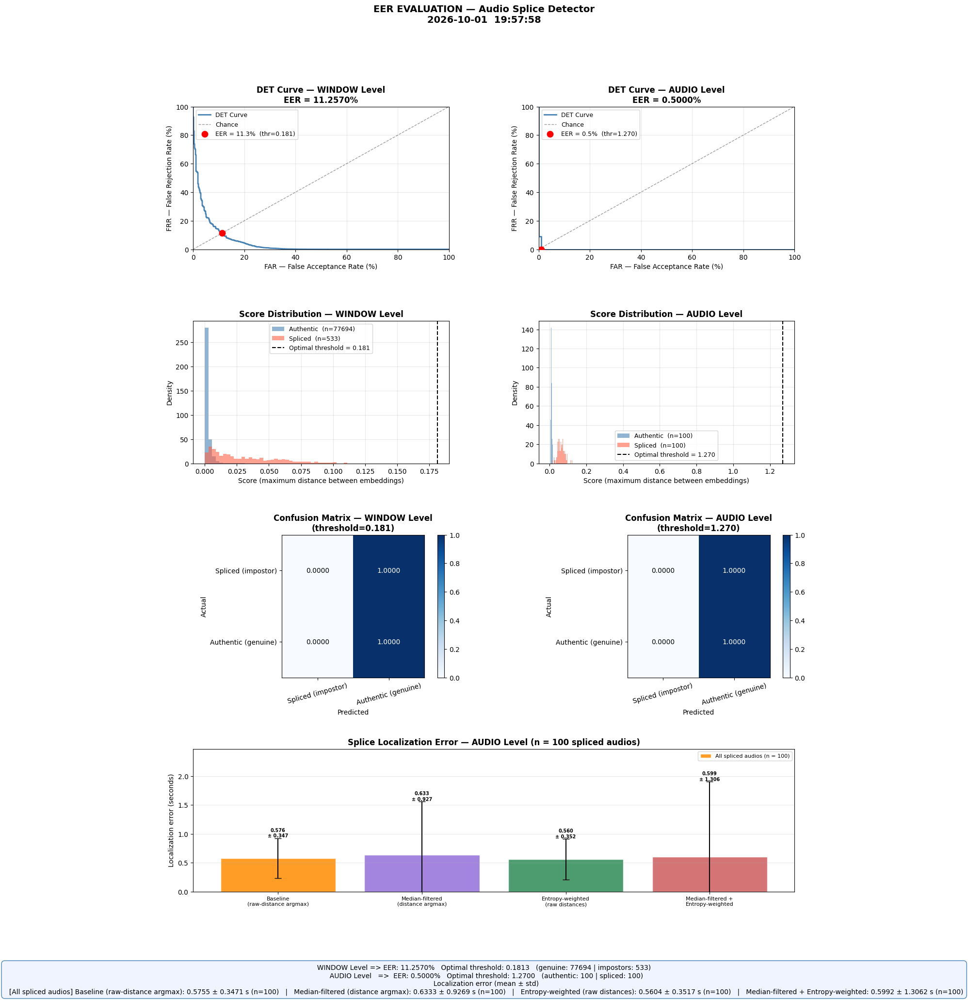

Result appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv
Full detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_detail_unseen_devices_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/eer_history.csv'

In [ ]:
set_all_seeds(RANDOM_SEED)
unseen_devices_results_snr = evaluate_eer_complete(
    model=model, test_audios=unseen_devices_dataset, device_to_label=device_to_label,
    device=device, n_audios_test=N_AUDIOS_TEST_EER, save_pdf=True,
    sr=SR, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL, top_db=TOP_DB,
    output_path=output_path, run_name=f"unseen_devices_snr_{eval_run_name}",
    fixed_threshold=calibrated_threshold_snr, class_names=CM_CLASS_NAMES_DETECTION,
    normalize=CM_NORMALIZE, dpi=FIGURE_DPI,
    median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
    compute_entropy_comparison=True, entropy_window=ENTROPY_LOCAL_WINDOW,
    localization_tolerance_s=IA_SPLICING_TOLERANCE_S,
    distance_metric="snr", VI=None,
)
save_eer_results(
    unseen_devices_results_snr, output_path=output_path,
    run_name=f"unseen_devices_snr_{eval_run_name}",
    config_extra={"distance_metric": "snr", "source": "external_cross_corpus",
              "eer_module_hash": EER_MODULE_HASH, "random_seed": RANDOM_SEED},
)

In [ ]:
###########################################
"""Audio-Level Score Strategies — Median / Median + Entropy EER (calibrated on val, evaluated on unseen devices)"""
###########################################

def compute_audio_score_by_strategy(raw_distances, median_filter_kernel_size, entropy_window,
                                    epsilon=SCORE_STRATEGY_ENTROPY_EPSILON):
    """
    Derives one audio-level detection score per strategy from the SAME raw
    consecutive-window distance sequence (paired design):
      baseline       : max(raw distances)
      median         : max(median-filtered distances)
      median_entropy : max(median-filtered distances / local entropy)
    Higher score = stronger evidence of splicing (same convention as eer_audio_level).
    """
    filtered_distances = _apply_median_filter(raw_distances, median_filter_kernel_size)
    filtered_local_entropy = _local_distance_entropy(filtered_distances, entropy_window=entropy_window)
    return {
        "baseline":       float(raw_distances.max()),
        "median":         float(filtered_distances.max()),
        "median_entropy": float(np.max(filtered_distances / (filtered_local_entropy + epsilon))),
    }


def collect_audio_level_strategy_scores(audio_pool, model, device, n_audios,
                                        sr, win_sec, hop_sec, n_fft, hop_length_fft, top_db,
                                        median_filter_kernel_size, entropy_window,
                                        distance_metric="euclidean", VI=None):
    """
    Mirrors the sampling protocol of eer_evaluation.eer_audio_level (eligibility,
    duration equalization, edge margin, authentic sampling without replacement)
    but returns one score per strategy for every audio.

    Labels: 1 = authentic, 0 = spliced.
    """
    module = eer_evaluation_module
    min_edge_margin_samples = int(module.SPLICE_MIN_EDGE_MARGIN_WINDOWS * win_sec * sr)
    min_duration_samples = int(module.AUDIO_LEVEL_MIN_DURATION_WINDOWS * win_sec * sr)

    eligible_audios = [a for a in audio_pool if len(a['audio']) >= min_duration_samples]
    pool_devices = sorted(set(a['device'] for a in eligible_audios))
    if len(pool_devices) < 2:
        raise ValueError("Audio-level strategy evaluation requires eligible audios from at least 2 devices.")
    audios_by_device = {d: [a for a in eligible_audios if a['device'] == d] for d in pool_devices}

    common_length_samples = (min(len(a['audio']) for a in eligible_audios)
                             if module.AUDIO_LEVEL_EQUALIZE_DURATION else None)

    def _crop_to_common_length(audio_signal):
        return audio_signal if common_length_samples is None else audio_signal[:common_length_samples]

    def _score_signal(audio_signal):
        embeddings, _ = module._audio_embeddings(
            audio_signal, model, device=device, sr=sr, win_sec=win_sec, hop_sec=hop_sec,
            n_fft=n_fft, hop_length_fft=hop_length_fft,
        )
        raw_distances = module._consecutive_distances(embeddings, distance_metric=distance_metric, VI=VI)
        if len(raw_distances) == 0:
            return None
        return compute_audio_score_by_strategy(raw_distances, median_filter_kernel_size, entropy_window)

    scores_by_strategy = {key: [] for key in SCORE_STRATEGY_KEYS}
    labels = []

    def _register(strategy_scores, label):
        for key in SCORE_STRATEGY_KEYS:
            scores_by_strategy[key].append(strategy_scores[key])
        labels.append(label)

    n_per_class = n_audios // 2

    # Authentic audios
    for audio_info in random.sample(eligible_audios, min(n_per_class, len(eligible_audios))):
        strategy_scores = _score_signal(_crop_to_common_length(audio_info['audio']))
        if strategy_scores is not None:
            _register(strategy_scores, 1)

    # Spliced audios
    n_spliced_generated, n_attempts = 0, 0
    max_attempts = n_per_class * module.SPLICE_MAX_ATTEMPTS_FACTOR
    while n_spliced_generated < n_per_class and n_attempts < max_attempts:
        n_attempts += 1
        device_a, device_b = random.sample(pool_devices, 2)
        audio_a = _crop_to_common_length(random.choice(audios_by_device[device_a])['audio'])
        audio_b = _crop_to_common_length(random.choice(audios_by_device[device_b])['audio'])
        spliced_audio, _ = generate_simple_splicing(
            audio_a, audio_b, top_db=top_db, min_edge_margin_samples=min_edge_margin_samples,
        )
        if spliced_audio is None:
            continue
        strategy_scores = _score_signal(spliced_audio)
        if strategy_scores is None:
            continue
        _register(strategy_scores, 0)
        n_spliced_generated += 1

    if n_spliced_generated < n_per_class:
        print(f"WARNING [{distance_metric}]: only {n_spliced_generated}/{n_per_class} spliced audios generated "
              f"after {n_attempts} attempts; classes are imbalanced.")

    return ({key: np.asarray(values) for key, values in scores_by_strategy.items()},
            np.asarray(labels))


def evaluate_audio_score_strategies(calibration_pool, evaluation_pools, model, device, n_audios,
                                    sr, win_sec, hop_sec, n_fft, hop_length_fft, top_db,
                                    median_filter_kernel_size, entropy_window,
                                    distance_metric="euclidean", VI=None, seed=RANDOM_SEED):
    """
    For each score strategy: (1) freeze the EER-optimal threshold on
    `calibration_pool` (val_audios), (2) evaluate on every pool in
    `evaluation_pools` (dict name -> audio list) reporting EER, FAR and FRR
    at the frozen threshold, with bootstrap confidence intervals.
    """
    scoring_kwargs = dict(
        model=model, device=device, n_audios=n_audios, sr=sr, win_sec=win_sec, hop_sec=hop_sec,
        n_fft=n_fft, hop_length_fft=hop_length_fft, top_db=top_db,
        median_filter_kernel_size=median_filter_kernel_size, entropy_window=entropy_window,
        distance_metric=distance_metric, VI=VI,
    )

    set_all_seeds(seed)
    calibration_scores, calibration_labels = collect_audio_level_strategy_scores(calibration_pool, **scoring_kwargs)
    frozen_thresholds = {key: calculate_eer(calibration_scores[key], calibration_labels)[1]
                         for key in SCORE_STRATEGY_KEYS}

    # Calibration-stability CI of each strategy's EER-optimal threshold (val_audios only)
    frozen_threshold_intervals = {
        key: bootstrap_calibrated_threshold(calibration_scores[key], calibration_labels)
        for key in SCORE_STRATEGY_KEYS
    }
    print(f"\n[{distance_metric}] Frozen-threshold stability (calibration pool)")
    for key in SCORE_STRATEGY_KEYS:
        print(f"   {SCORE_STRATEGY_LABELS[key]}: "
              f"{format_confidence_interval(frozen_threshold_intervals[key], as_percent=False)}")

    results = {
        "distance_metric": distance_metric,
        "frozen_thresholds": frozen_thresholds,
        "frozen_threshold_bootstrap": frozen_threshold_intervals,
        "evaluation": {},
    }
    for pool_name, evaluation_pool in evaluation_pools.items():
        set_all_seeds(seed)
        evaluation_scores, evaluation_labels = collect_audio_level_strategy_scores(evaluation_pool, **scoring_kwargs)

        results["evaluation"][pool_name] = {}
        print(f"\n[{distance_metric} | {pool_name}] "
              f"authentic={int((evaluation_labels == 1).sum())} | spliced={int((evaluation_labels == 0).sum())}")
        for key in SCORE_STRATEGY_KEYS:
            frozen_threshold = frozen_thresholds[key]
            detection_intervals = bootstrap_detection_metrics(
                evaluation_scores[key], evaluation_labels, frozen_threshold)
            results["evaluation"][pool_name][key] = {
                "scores": evaluation_scores[key],
                "labels": evaluation_labels,
                "frozen_threshold": frozen_threshold,
                "eer": detection_intervals["eer"]["estimate"],
                "far": detection_intervals["far"]["estimate"],
                "frr": detection_intervals["frr"]["estimate"],
                "bootstrap": detection_intervals,
            }
            print(f"   {SCORE_STRATEGY_LABELS[key]} (thr={frozen_threshold:.4f})")
            for metric_name, interval in detection_intervals.items():
                print(f"      {metric_name.upper():<4} {format_confidence_interval(interval)}")
    return results


score_strategy_evaluation_pools = {
    "unseen_devices": unseen_devices_dataset,
    "final_test":     test_audios,
}
score_strategy_vi_by_metric = {"mahalanobis": mahalanobis_vi}

strategy_eer_results = {}
for metric_name in SCORE_STRATEGY_DISTANCE_METRICS:
    print(f"\n=== AUDIO-LEVEL SCORE STRATEGIES — {metric_name.upper()} ===")
    strategy_eer_results[metric_name] = evaluate_audio_score_strategies(
        calibration_pool=val_audios,
        evaluation_pools=score_strategy_evaluation_pools,
        model=model, device=device, n_audios=N_AUDIOS_TEST_EER,
        sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
        n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, top_db=TOP_DB,
        median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
        entropy_window=ENTROPY_LOCAL_WINDOW,
        distance_metric=metric_name, VI=score_strategy_vi_by_metric.get(metric_name),
    )

with open(strategy_eer_results_path, "wb") as f:
    pickle.dump(strategy_eer_results, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Audio-level score strategy results saved to {strategy_eer_results_path}")


=== AUDIO-LEVEL SCORE STRATEGIES — EUCLIDEAN ===

[euclidean] Frozen-threshold stability (calibration pool)
   Baseline (raw max distance): 1.0883  [1.0511, 1.1417] (95% CI, n=200)
   Median-filtered max distance: 0.8735  [0.8155, 0.9098] (95% CI, n=200)
   Median-filtered + entropy-weighted max score: 0.3953  [0.3641, 0.4061] (95% CI, n=200)

[euclidean | unseen_devices] authentic=100 | spliced=100
   Baseline (raw max distance) (thr=1.0883)
      EER  1.0000%  [0.0000%, 2.0000%] (95% CI, n=200)
      FAR  100.0000%  [100.0000%, 100.0000%] (95% CI, n=200)
      FRR  0.0000%  [0.0000%, 0.0000%] (95% CI, n=200)
   Median-filtered max distance (thr=0.8735)
      EER  7.5000%  [2.5000%, 10.5000%] (95% CI, n=200)
      FAR  100.0000%  [100.0000%, 100.0000%] (95% CI, n=200)
      FRR  0.0000%  [0.0000%, 0.0000%] (95% CI, n=200)
   Median-filtered + entropy-weighted max score (thr=0.3953)
      EER  5.0000%  [3.0000%, 10.0125%] (95% CI, n=200)
      FAR  100.0000%  [100.0000%, 100.0000%] (9


=== Audio-level score strategies — summary ===
distance_metric           pool                                     strategy  frozen_threshold  eer_pct  eer_ci_lower_pct  eer_ci_upper_pct  far_pct  far_ci_lower_pct  far_ci_upper_pct  frr_pct  frr_ci_lower_pct  frr_ci_upper_pct
      euclidean unseen_devices                  Baseline (raw max distance)            1.0883      1.0               0.0            2.0000    100.0             100.0           100.000      0.0               0.0             0.000
      euclidean unseen_devices                 Median-filtered max distance            0.8735      7.5               2.5           10.5000    100.0             100.0           100.000      0.0               0.0             0.000
      euclidean unseen_devices Median-filtered + entropy-weighted max score            0.3953      5.0               3.0           10.0125    100.0             100.0           100.000      0.0               0.0             0.000
      euclidean     final_test      

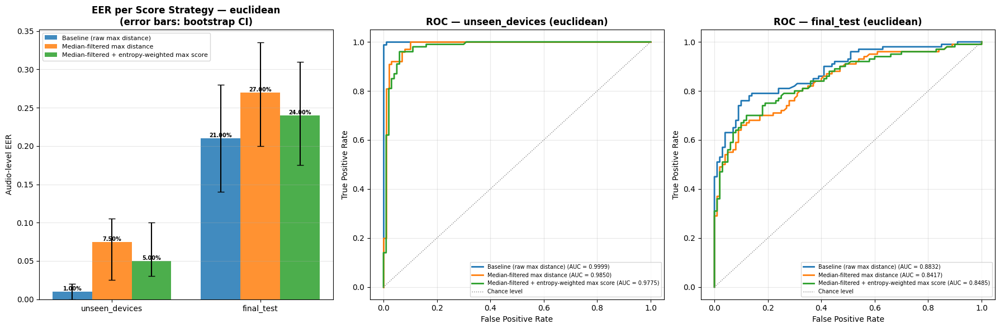

Strategy EER/ROC comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
###########################################
"""Audio-Level Score Strategies — Summary Table and EER/ROC Plots"""
###########################################

def build_strategy_eer_summary_table(strategy_eer_results, decimals=SUMMARY_TABLE_DECIMALS):
    """
    Flattens the nested output of evaluate_audio_score_strategies() into a
    tidy DataFrame (one row per distance metric x evaluation pool x strategy).
    EER / FAR / FRR are expressed in percent, each with its bootstrap CI bounds.
    """
    records = []
    for distance_metric, metric_results in strategy_eer_results.items():
        for pool_name, pool_results in metric_results["evaluation"].items():
            for strategy_key, strategy_result in pool_results.items():
                record = {
                    "distance_metric": distance_metric,
                    "pool": pool_name,
                    "strategy": SCORE_STRATEGY_LABELS[strategy_key],
                    "frozen_threshold": strategy_result["frozen_threshold"],
                }
                for detection_metric in ("eer", "far", "frr"):
                    interval = strategy_result["bootstrap"][detection_metric]
                    record[f"{detection_metric}_pct"] = 100.0 * interval["estimate"]
                    record[f"{detection_metric}_ci_lower_pct"] = 100.0 * interval["ci_lower"]
                    record[f"{detection_metric}_ci_upper_pct"] = 100.0 * interval["ci_upper"]
                records.append(record)
    return pd.DataFrame.from_records(records).round(decimals)


def plot_strategy_eer_comparison(strategy_eer_results, path_template=strategy_eer_png_template,
                                 strategy_keys=SCORE_STRATEGY_KEYS, dpi=FIGURE_DPI):
    """
    One figure per distance metric:
      Panel 0    : grouped bars of EER (with bootstrap CI error bars),
                   evaluation pools on the x-axis, one bar per score strategy.
      Panels 1..N: ROC curves of every strategy for each evaluation pool.
    Label convention of eer_evaluation.py (1 = authentic, 0 = spliced, higher
    score = more spliced) is handled by inverting the scores, exactly as
    calculate_eer() does.
    """
    colormap = matplotlib.colormaps["tab10"]
    saved_paths = {}

    for distance_metric, metric_results in strategy_eer_results.items():
        evaluation = metric_results["evaluation"]
        pool_names = list(evaluation.keys())
        n_strategies = len(strategy_keys)
        bar_width = 0.8 / n_strategies

        fig, axes = plt.subplots(1, 1 + len(pool_names), figsize=(6 * (1 + len(pool_names)), 6))

        # Panel 0: EER with bootstrap CI
        ax = axes[0]
        x_positions = np.arange(len(pool_names))
        for strategy_index, strategy_key in enumerate(strategy_keys):
            estimates = np.array([evaluation[p][strategy_key]["bootstrap"]["eer"]["estimate"] for p in pool_names])
            lower_bounds = np.array([evaluation[p][strategy_key]["bootstrap"]["eer"]["ci_lower"] for p in pool_names])
            upper_bounds = np.array([evaluation[p][strategy_key]["bootstrap"]["eer"]["ci_upper"] for p in pool_names])
            yerr = np.vstack([np.clip(estimates - lower_bounds, 0, None),
                              np.clip(upper_bounds - estimates, 0, None)])
            bar_offsets = x_positions + (strategy_index - (n_strategies - 1) / 2) * bar_width
            bars = ax.bar(bar_offsets, estimates, width=bar_width, yerr=yerr, capsize=4,
                          color=colormap(strategy_index), alpha=0.85,
                          label=SCORE_STRATEGY_LABELS[strategy_key])
            for bar, value in zip(bars, estimates):
                ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2%}",
                        ha="center", va="bottom", fontsize=7, fontweight="bold")
        ax.set_xticks(x_positions)
        ax.set_xticklabels(pool_names)
        ax.set_ylabel("Audio-level EER")
        ax.set_title(f"EER per Score Strategy — {distance_metric}\n(error bars: bootstrap CI)", fontweight="bold")
        ax.legend(fontsize=8)
        ax.grid(True, axis="y", alpha=0.3)

        # Panels 1..N: ROC per evaluation pool
        for pool_index, pool_name in enumerate(pool_names, start=1):
            ax = axes[pool_index]
            for strategy_index, strategy_key in enumerate(strategy_keys):
                strategy_result = evaluation[pool_name][strategy_key]
                false_positive_rate, true_positive_rate, _ = roc_curve(
                    strategy_result["labels"], -np.asarray(strategy_result["scores"]), pos_label=1
                )
                roc_auc = auc(false_positive_rate, true_positive_rate)
                ax.plot(false_positive_rate, true_positive_rate, linewidth=2, color=colormap(strategy_index),
                        label=f"{SCORE_STRATEGY_LABELS[strategy_key]} (AUC = {roc_auc:.4f})")
            ax.plot([0, 1], [0, 1], color="gray", linestyle=":", linewidth=1, label="Chance level")
            ax.set_xlabel("False Positive Rate")
            ax.set_ylabel("True Positive Rate")
            ax.set_title(f"ROC — {pool_name} ({distance_metric})", fontweight="bold")
            ax.legend(fontsize=7, loc="lower right")
            ax.grid(True, alpha=0.3)

        plt.tight_layout()
        output_file_path = path_template.format(distance_metric=distance_metric)
        plt.savefig(output_file_path, dpi=dpi, bbox_inches="tight")
        plt.show()
        print(f"Strategy EER/ROC comparison saved to {output_file_path}")
        saved_paths[distance_metric] = output_file_path

    return saved_paths


strategy_eer_summary = build_strategy_eer_summary_table(strategy_eer_results)
print("\n=== Audio-level score strategies — summary ===")
print(strategy_eer_summary.to_string(index=False))
strategy_eer_summary.to_csv(strategy_eer_summary_csv_path, index=False)
print(f"Strategy summary table saved to {strategy_eer_summary_csv_path}")

strategy_eer_plot_paths = plot_strategy_eer_comparison(strategy_eer_results)

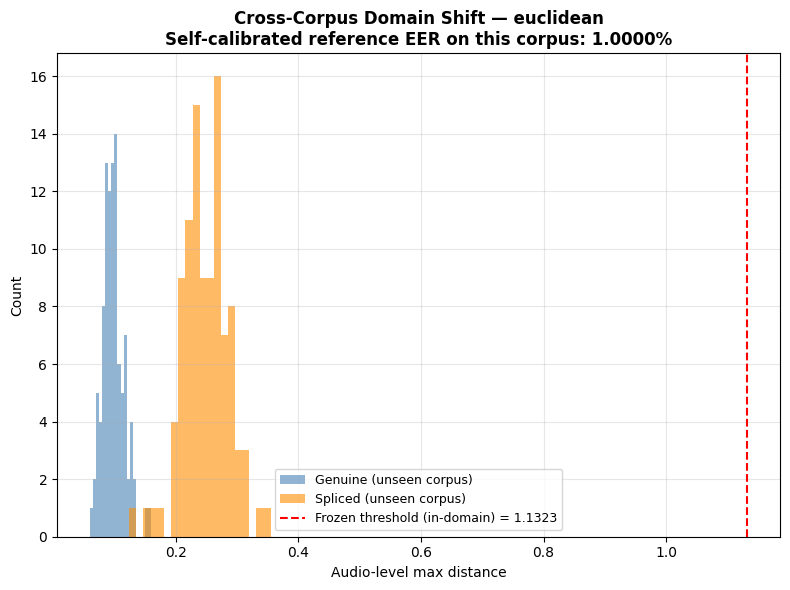

Domain-shift diagnostic saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/domain_shift_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


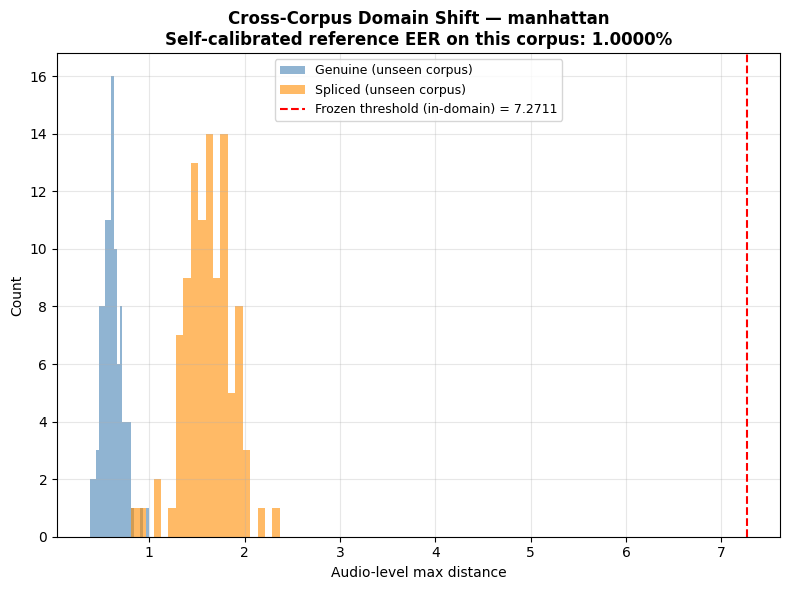

Domain-shift diagnostic saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/domain_shift_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


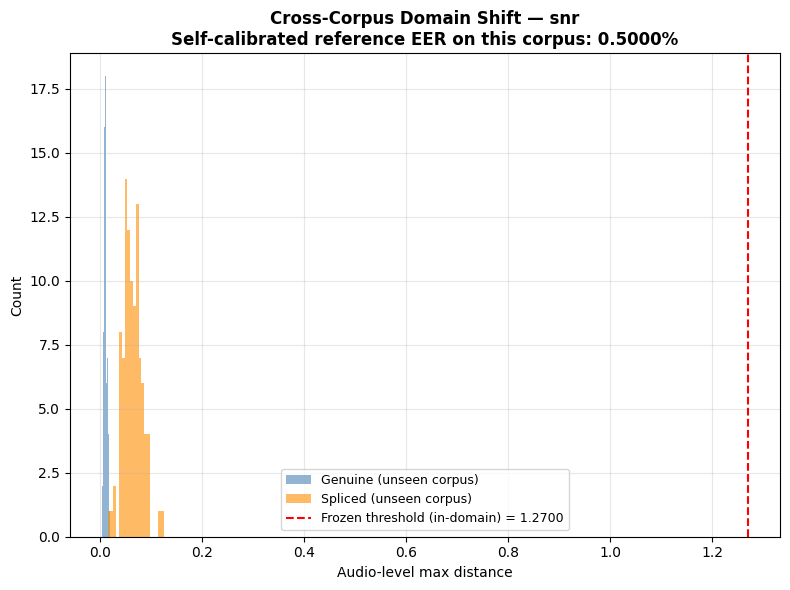

Domain-shift diagnostic saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/domain_shift_snr_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
###########################################
"""Cross-Corpus Domain-Shift Diagnostic — Score Distribution vs Frozen Threshold"""
###########################################

def plot_cross_corpus_domain_shift(audio_results, frozen_threshold, distance_metric,
                                    output_path, run_name, dpi=FIGURE_DPI):
    """
    Visual diagnostic for a cross-corpus (unseen-device) evaluation:
    overlays the genuine/spliced audio-level score distributions against
    the in-domain frozen threshold, making explicit why a fixed threshold
    calibrated on the training corpus may fail to transfer under domain
    shift, independent of whether splicing was correctly generated.
    """
    scores = audio_results['scores']
    labels = audio_results['labels']

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hist(scores[labels == 1], bins=20, alpha=0.6, color='steelblue', label='Genuine (unseen corpus)')
    ax.hist(scores[labels == 0], bins=20, alpha=0.6, color='darkorange', label='Spliced (unseen corpus)')
    ax.axvline(x=frozen_threshold, color='red', linestyle='--', linewidth=1.5,
               label=f'Frozen threshold (in-domain) = {frozen_threshold:.4f}')
    ax.set_title(f'Cross-Corpus Domain Shift — {distance_metric}\n'
                 f'Self-calibrated reference EER on this corpus: {audio_results["eer"]:.4%}',
                 fontweight='bold')
    ax.set_xlabel('Audio-level max distance')
    ax.set_ylabel('Count')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    output_file_path = os.path.join(output_path, f"domain_shift_{distance_metric}_{run_name}.png")
    plt.savefig(output_file_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"Domain-shift diagnostic saved to {output_file_path}")

plot_cross_corpus_domain_shift(unseen_devices_results['audio'], calibrated_threshold['audio'],
                                "euclidean", output_path, eval_run_name)
#plot_cross_corpus_domain_shift(unseen_devices_results_mahalanobis['audio'], calibrated_threshold_mahalanobis['audio'],
 #                              "mahalanobis", output_path, eval_run_name)
plot_cross_corpus_domain_shift(unseen_devices_results_manhattan['audio'], calibrated_threshold_manhattan['audio'],
                                "manhattan", output_path, eval_run_name)
plot_cross_corpus_domain_shift(unseen_devices_results_snr['audio'], calibrated_threshold_snr['audio'],
                                "snr", output_path, eval_run_name)

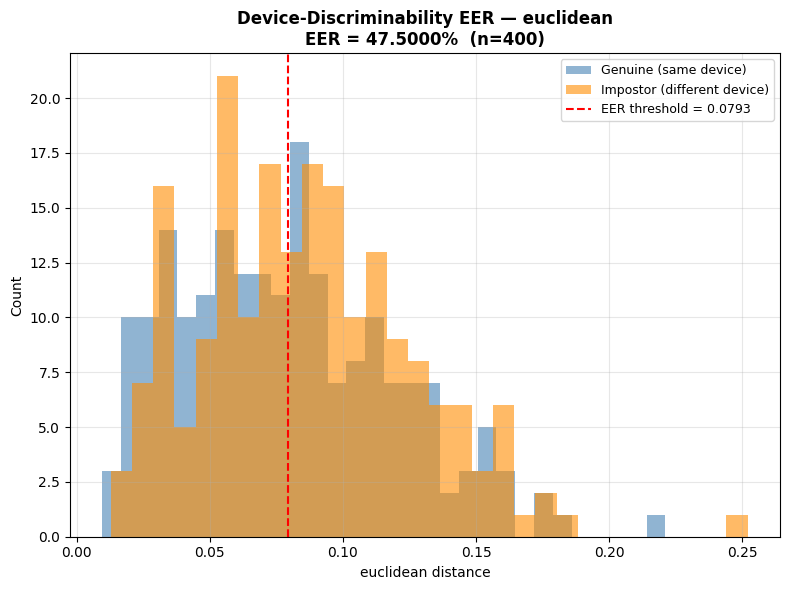

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_euclidean_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_euclidean_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


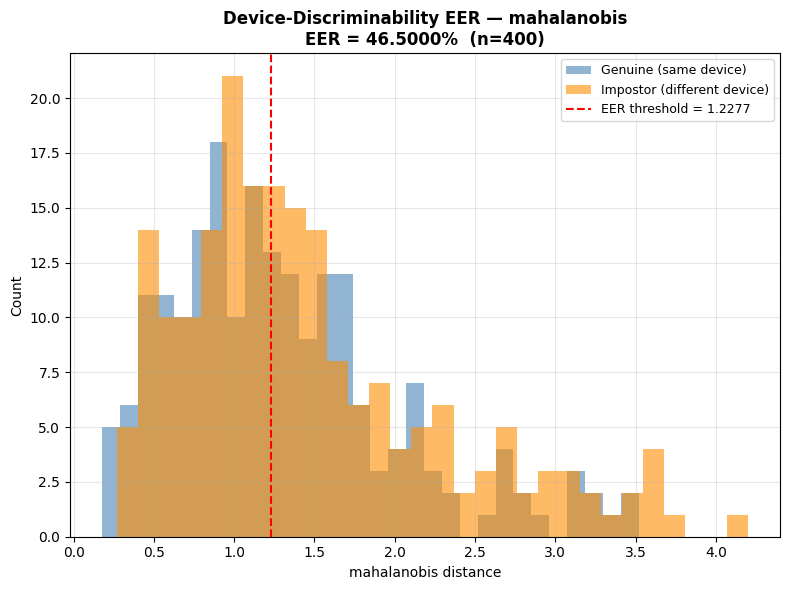

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_mahalanobis_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_mahalanobis_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


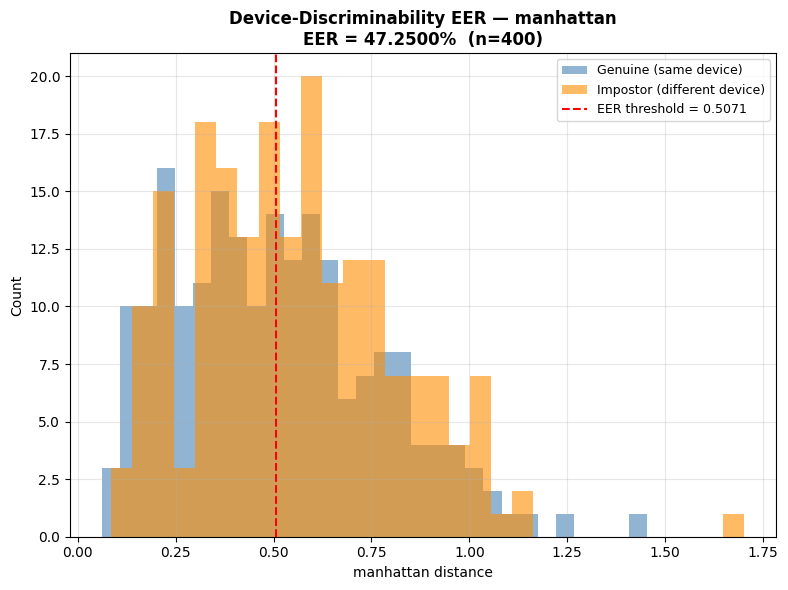

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_manhattan_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_manhattan_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


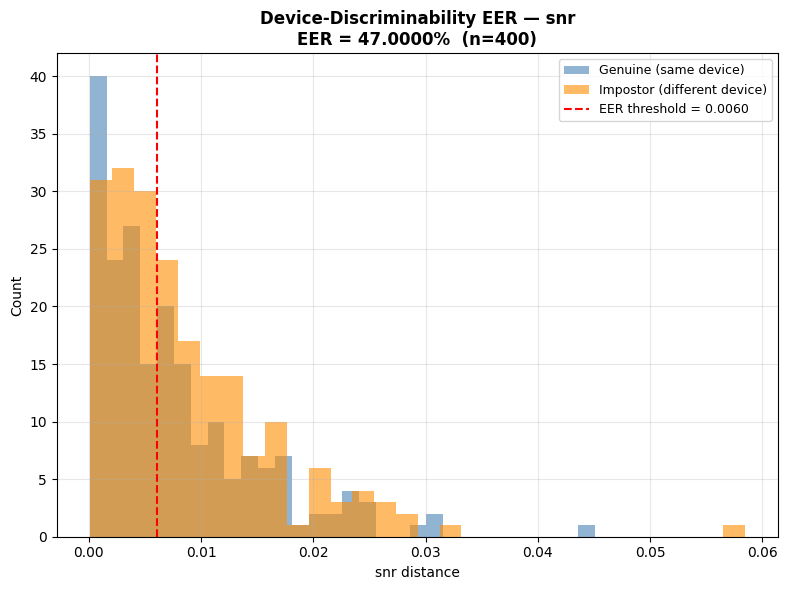

Device-discriminability EER plot saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_snr_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png
Device-discriminability EER results saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/device_discriminability_eer_snr_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


In [ ]:
set_all_seeds(RANDOM_SEED)
unseen_device_discriminability_euclidean = evaluate_device_discriminability_eer(
    audio_pool=unseen_devices_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="euclidean", VI=None,
    output_path=output_path, run_name=f"unseen_devices_{eval_run_name}",
)
set_all_seeds(RANDOM_SEED)
unseen_device_discriminability_mahalanobis = evaluate_device_discriminability_eer(
    audio_pool=unseen_devices_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="mahalanobis", VI=mahalanobis_vi,
    output_path=output_path, run_name=f"unseen_devices_{eval_run_name}",
)
set_all_seeds(RANDOM_SEED)
unseen_device_discriminability_manhattan = evaluate_device_discriminability_eer(
    audio_pool=unseen_devices_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="manhattan", VI=None,
    output_path=output_path, run_name=f"unseen_devices_{eval_run_name}",
)
set_all_seeds(RANDOM_SEED)
unseen_device_discriminability_snr = evaluate_device_discriminability_eer(
    audio_pool=unseen_devices_dataset, model=model, device=device,
    n_pairs=N_PAIRS_PAIRWISE_CALIBRATION,
    sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT,
    distance_metric="snr", VI=None,
    output_path=output_path, run_name=f"unseen_devices_{eval_run_name}",
)

Unseen-device splice pair: Nokia N70 -> Samsung Galaxy Nexus S (top_db=30, reference=30)
Real cut point: sample 906752 - 20.5613 seconds


/tmp/ipykernel_1355/151254906.py:93: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(fontsize=11)
/tmp/ipykernel_1355/151254906.py:129: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend(fontsize=9)


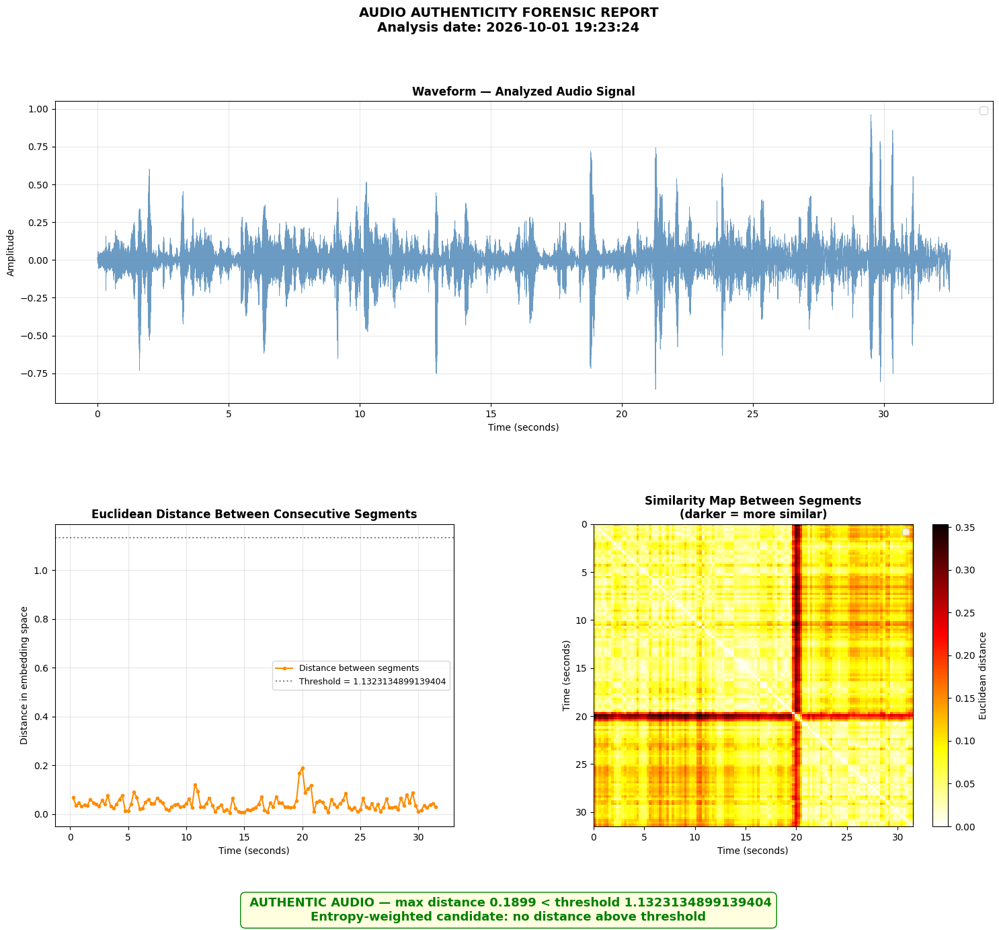


[Euclidean] Max distance found: 0.1899
[Euclidean] Current threshold:  1.1323
[Euclidean] Detected splice?:    False
[Euclidean] Model detected: AUTHENTIC AUDIO (did not exceed threshold 1.1323)
[Euclidean] Max distance: 0.1899
[Euclidean] Entropy-weighted candidate: no distance above threshold (max distance = 0.1899)


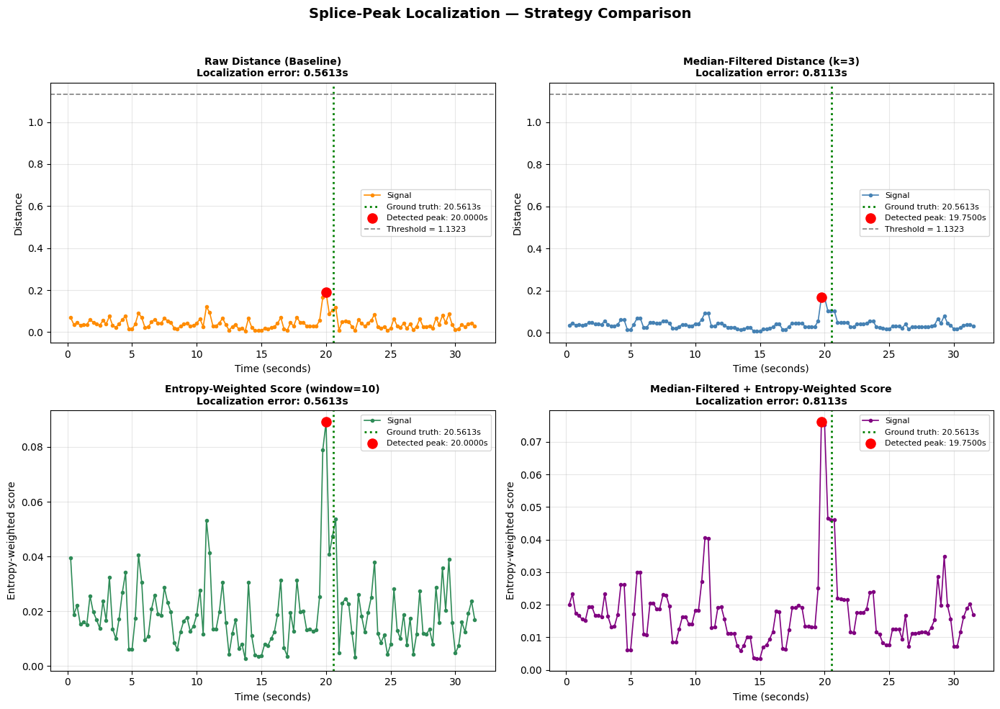

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_unseen_devices_euclidean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary (unseen devices, Euclidean) ===
Raw Distance (Baseline)                       error = 0.5613s (detected at 20.0000s)
Median-Filtered Distance (k=3)                error = 0.8113s (detected at 19.7500s)
Entropy-Weighted Score (window=10)            error = 0.5613s (detected at 20.0000s)
Median-Filtered + Entropy-Weighted Score      error = 0.8113s (detected at 19.7500s)


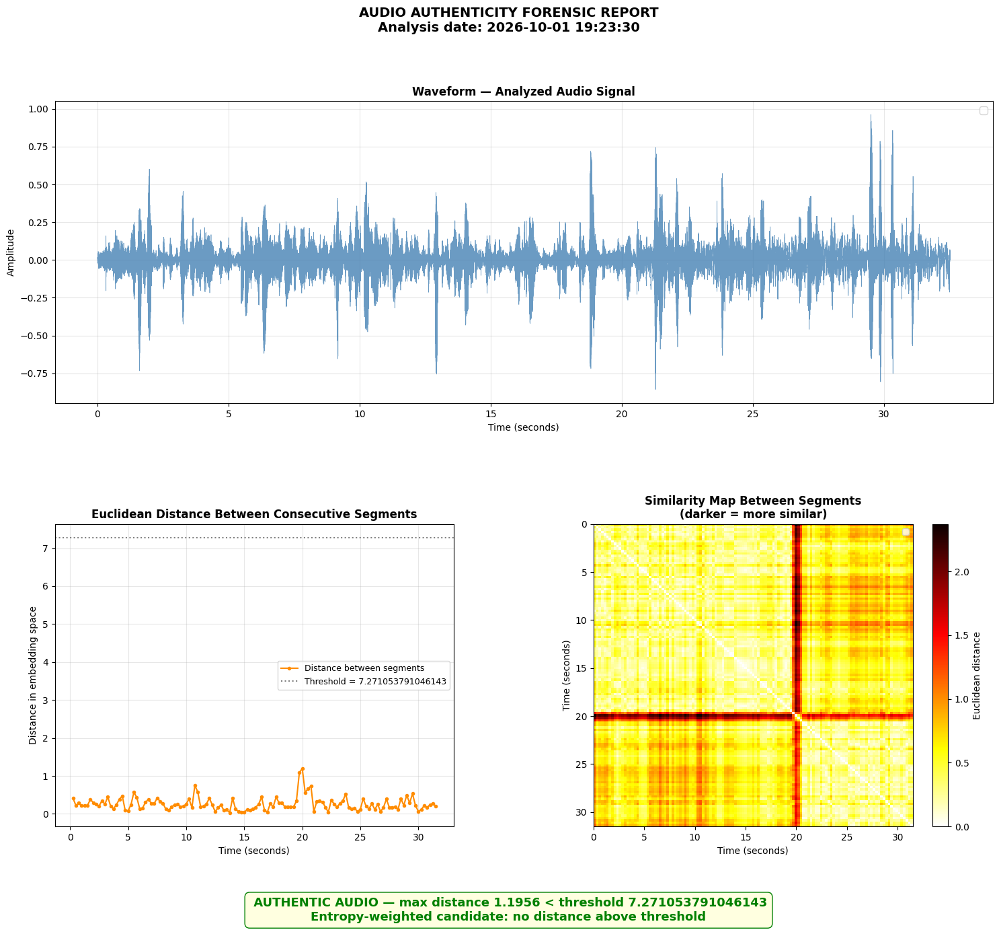


[Manhattan] Max distance found: 1.1956
[Manhattan] Current threshold:  7.2711
[Manhattan] Detected splice?:    False
[Manhattan] Model detected: AUTHENTIC AUDIO (did not exceed threshold 7.2711)
[Manhattan] Max distance: 1.1956
[Manhattan] Entropy-weighted candidate: no distance above threshold (max distance = 1.1956)


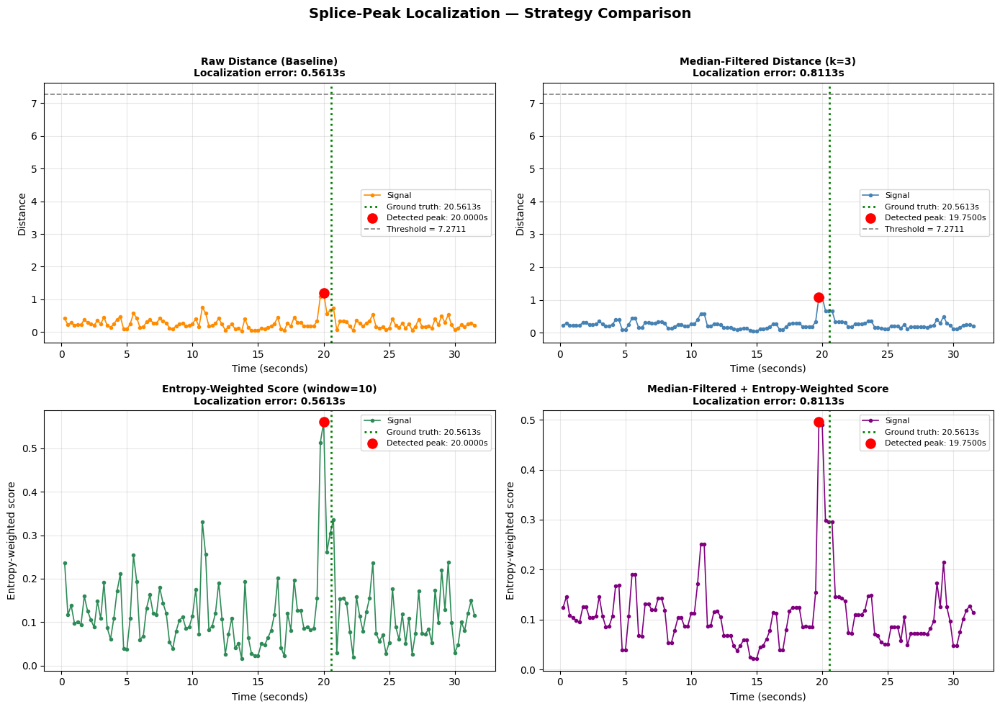

Filtering strategy comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_unseen_devices_manhattan_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary (unseen devices, Manhattan) ===
Raw Distance (Baseline)                       error = 0.5613s (detected at 20.0000s)
Median-Filtered Distance (k=3)                error = 0.8113s (detected at 19.7500s)
Entropy-Weighted Score (window=10)            error = 0.5613s (detected at 20.0000s)
Median-Filtered + Entropy-Weighted Score      error = 0.8113s (detected at 19.7500s)


In [ ]:
###########################################
"""TEST — UNSEEN-DEVICE SPLICE (single-example forensic report, Euclidean & Manhattan)"""
###########################################
# Same single-splice forensic-report test as the TEST block above, but drawn
# from unseen_devices_dataset (cross-corpus, never seen in train/val/test),
# to visually inspect how the calibrated Euclidean/Manhattan thresholds
# transfer to an out-of-domain device pair.
def find_closest_valid_splice_pair(audio_pool, devices_available,
                                    top_db_default=TOP_DB,
                                    top_db_floor=UNSEEN_DEVICE_SPLICE_TOP_DB_FLOOR,
                                    top_db_step=UNSEEN_DEVICE_SPLICE_TOP_DB_STEP,
                                    n_candidate_pairs=UNSEEN_DEVICE_SPLICE_CANDIDATE_PAIRS):
    """
    Samples cross-device candidate pairs and, for each, searches for the
    smallest relaxation of `top_db` (stepping down from top_db_default to
    top_db_floor) that yields a valid splice via generate_simple_splicing.

    Across all sampled pairs, returns the one whose required top_db is
    closest to top_db_default — i.e., the pair that best satisfies the
    original silence criterion — rather than the first pair that happens
    to succeed. Search stops early once a pair succeeds at top_db_default.

    Returns
    -------
    splice_result   : dict, same schema as generate_splicing_pair's output
    top_db_used     : int, the relaxed top_db that produced splice_result
    device_pair     : tuple(str, str), the (source_a, source_b) devices used
    """
    best_result = None
    best_top_db_used = None
    best_device_pair = None

    for _ in range(n_candidate_pairs):
        device_a, device_b = random.sample(devices_available, 2)
        audio_info_a = random.choice([a for a in audio_pool if a['device'] == device_a])
        audio_info_b = random.choice([a for a in audio_pool if a['device'] == device_b])

        for candidate_top_db in range(top_db_default, top_db_floor - 1, -top_db_step):
            spliced_audio, cut_point = generate_simple_splicing(
                audio_info_a['audio'], audio_info_b['audio'], top_db=candidate_top_db
            )
            if spliced_audio is not None:
                if best_top_db_used is None or candidate_top_db > best_top_db_used:
                    best_result = {
                        "audio": spliced_audio,
                        "label": 0,
                        "source_a": audio_info_a['device'],
                        "source_b": audio_info_b['device'],
                        "cut_point": cut_point,
                        "cut_time": cut_point / audio_info_a['sr'],
                    }
                    best_top_db_used = candidate_top_db
                    best_device_pair = (device_a, device_b)
                break  # this pair matched at candidate_top_db; stop relaxing further for it

        if best_top_db_used == top_db_default:
            break  # a pair already meets the original criterion, no need to search further

    if best_result is None:
        raise RuntimeError(
            f"No valid splice found among {n_candidate_pairs} candidate pairs even at "
            f"top_db={top_db_floor}. Consider raising n_candidate_pairs or lowering top_db_floor."
        )

    return best_result, best_top_db_used, best_device_pair

unseen_device_pool = unseen_devices_dataset  # cross-corpus pool, distinct device set from `devices`
unseen_devices_available = sorted(set(a['device'] for a in unseen_device_pool))

unseen_splice_result, unseen_splice_top_db_used, (unseen_device_a, unseen_device_b) = find_closest_valid_splice_pair(
    audio_pool=unseen_device_pool, devices_available=unseen_devices_available
)

print(f"Unseen-device splice pair: {unseen_device_a} -> {unseen_device_b} "
      f"(top_db={unseen_splice_top_db_used}, reference={TOP_DB})")

unseen_spliced_audio = unseen_splice_result['audio']
unseen_real_cut_time = unseen_splice_result['cut_time']

print(f"Real cut point: sample {unseen_splice_result['cut_point']} - {unseen_real_cut_time:.4f} seconds")

# Metric -> frozen calibration threshold, reusing the thresholds already
# calibrated on val_audios (no new calibration performed here)
unseen_test_metric_thresholds = {
    "euclidean": calibrated_threshold['audio'],
    "manhattan": calibrated_threshold_manhattan['audio'],
}

def run_unseen_device_forensic_test(suspect_audio, ground_truth_time_s, distance_metric, threshold, VI=None):
    forensic_result = generate_forensic_report(
        suspect_audio=suspect_audio,
        model=model,
        device=device,
        threshold=threshold,
        compute_entropy_comparison=True,
        entropy_window=ENTROPY_LOCAL_WINDOW,
        use_pairwise_distance=True,
        distance_metric=distance_metric,
        VI=VI,
    )

    print(f"\n[{distance_metric.capitalize()}] Max distance found: {forensic_result['max_distance']:.4f}")
    print(f"[{distance_metric.capitalize()}] Current threshold:  {forensic_result['threshold_used']:.4f}")
    print(f"[{distance_metric.capitalize()}] Detected splice?:    {forensic_result['has_splice']}")

    if forensic_result['has_splice']:
        time_error = abs(ground_truth_time_s - forensic_result['splice_time_sec'])
        print(f"[{distance_metric.capitalize()}] Model detected: splice at {forensic_result['splice_time_sec']:.4f}s")
        print(f"[{distance_metric.capitalize()}] Error: {time_error:.4f}s")
    else:
        print(f"[{distance_metric.capitalize()}] Model detected: AUTHENTIC AUDIO "
              f"(did not exceed threshold {forensic_result['threshold_used']:.4f})")
        print(f"[{distance_metric.capitalize()}] Max distance: {forensic_result['max_distance']:.4f}")

    if forensic_result.get('has_splice_entropy'):
        time_error_entropy = abs(ground_truth_time_s - forensic_result['splice_time_sec_entropy'])
        print(f"[{distance_metric.capitalize()}] Entropy-weighted candidate: "
              f"splice at {forensic_result['splice_time_sec_entropy']:.4f}s")
        print(f"[{distance_metric.capitalize()}] Error (entropy): {time_error_entropy:.4f}s")
    else:
        print(f"[{distance_metric.capitalize()}] Entropy-weighted candidate: no distance above threshold "
              f"(max distance = {forensic_result.get('max_distance_entropy', float('nan')):.4f})")

    strategy_comparison_results = plot_filtering_strategy_comparison(
        distances=forensic_result['distances'],
        timestamps=forensic_result['timestamps'][1:],
        threshold=forensic_result['threshold_used'],
        ground_truth_time_s=ground_truth_time_s,
        median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
        entropy_window=ENTROPY_LOCAL_WINDOW,
        output_path=output_path,
        run_name=f"unseen_devices_{distance_metric}_{eval_run_name}",
    )

    print(f"\n=== Strategy comparison summary (unseen devices, {distance_metric.capitalize()}) ===")
    for strategy_name, strategy_metrics in strategy_comparison_results.items():
        print(f"{strategy_name:<45} error = {strategy_metrics['localization_error_s']:.4f}s "
              f"(detected at {strategy_metrics['detected_time_s']:.4f}s)")

    return forensic_result, strategy_comparison_results


unseen_forensic_results = {}
for metric_name, metric_threshold in unseen_test_metric_thresholds.items():
    unseen_forensic_results[metric_name] = run_unseen_device_forensic_test(
        suspect_audio=unseen_spliced_audio,
        ground_truth_time_s=unseen_real_cut_time,
        distance_metric=metric_name,
        threshold=metric_threshold,
    )

In [ ]:
for metric_name, metric_results in {
    "euclidean": unseen_devices_results,
    "mahalanobis": unseen_devices_results_mahalanobis,
    "manhattan": unseen_devices_results_manhattan,
    "snr": unseen_devices_results_snr,
}.items():
    report_unseen_class_balance(metric_results, metric_name,
                                requested_audios_per_class=N_AUDIOS_TEST_EER // 2)

[euclidean] authentic=100/100 | spliced=100/100
[mahalanobis] authentic=100/100 | spliced=100/100
[manhattan] authentic=100/100 | spliced=100/100
[snr] authentic=100/100 | spliced=100/100


In [ ]:

###########################################
"""Save COMPLETE EXPERIMENT for comparison across versions"""
###########################################
# The csv can be plotted with pandas or excel
# open the .pkl files for plots
save_complete_experiment(
    output_path=output_path,
    run_name=eval_run_name,
    calibrated_threshold=calibrated_threshold,
    calibration_results=eer_results,        # the one from val_audios
    clean_results=clean_results,
    noise_results=noise_results,
    robustness_results=robustness_results,
    final_test_results=final_test_results,
    tsne_data=tsne_data,
    config_extra={
        "SR": SR, "EPOCHS": EPOCHS, "OUT_DIM": OUT_DIM,
        "N_FFT": N_FFT, "HOP_LENGTH_FFT": HOP_LENGTH_FFT,
        "WIN_LENGTH_SEC": WIN_LENGTH_SEC, "HOP_LENGTH_SEC": HOP_LENGTH_SEC_EVAL,
        "BATCH_SIZE": BATCH_SIZE,
        "N_SPLITS": N_SPLITS, "KNN_NEIGHBORS": KNN_NEIGHBORS,
        "NUM_PER_DEVICE": NUM_PER_DEVICE,
        **get_active_loss_config(),
        "POOLING_TYPE": POOLING_TYPE,
        "POOLING_STD_EPSILON": POOLING_STD_EPSILON,
    },
)


Experiment summary appended to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/experiment_history.csv
Full experiment detail saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/experiment_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.pkl


'/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/experiment_history.csv'

In [ ]:

def load_eer_detail(run_name, output_path=output_path):
    """Loads the full-detail dict saved by save_eer_results() (scores, labels, eer, ...)."""
    file_path = os.path.join(output_path, f"eer_detail_{run_name}.pkl")
    with open(file_path, "rb") as f:
        return pickle.load(f)

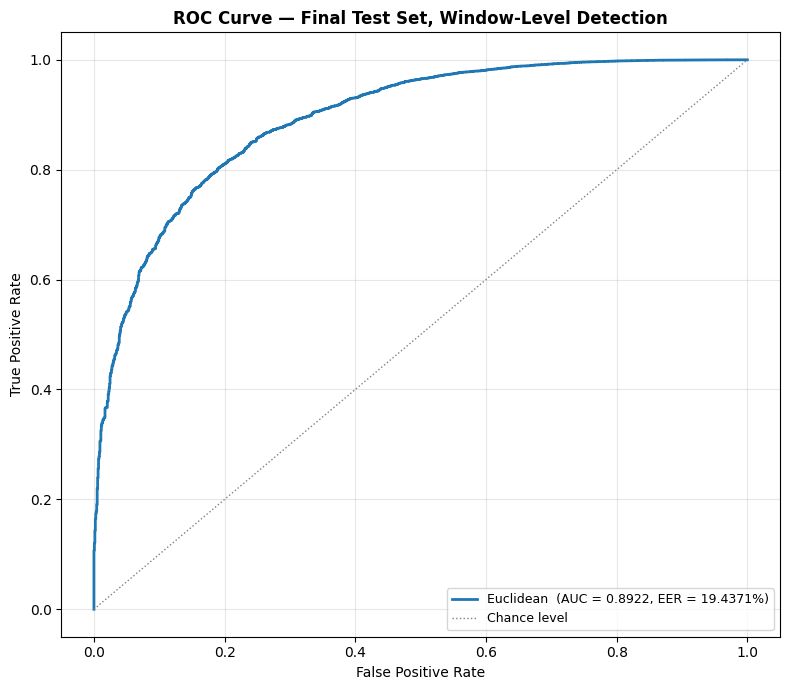

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_final_test_window_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


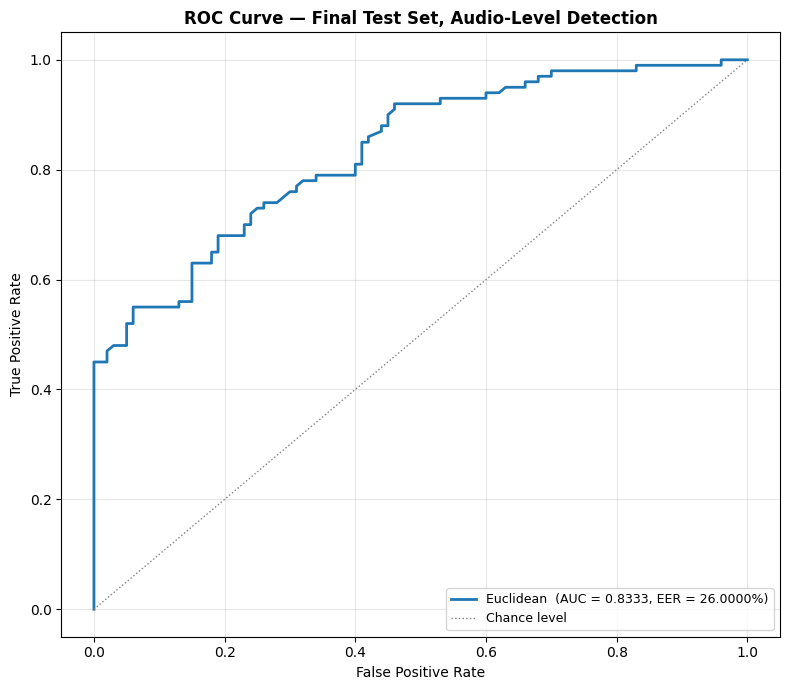

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_final_test_audio_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


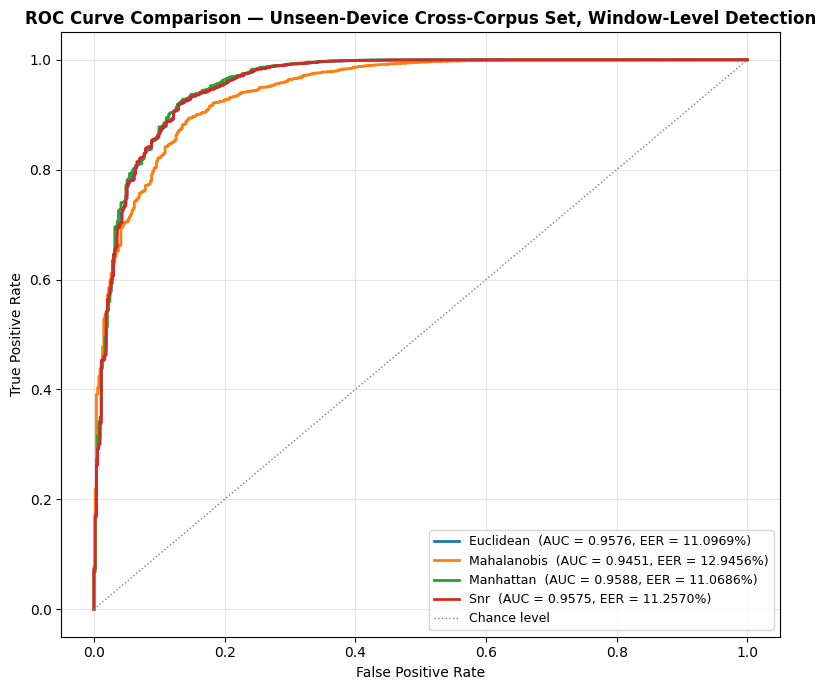

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_unseen_devices_window_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


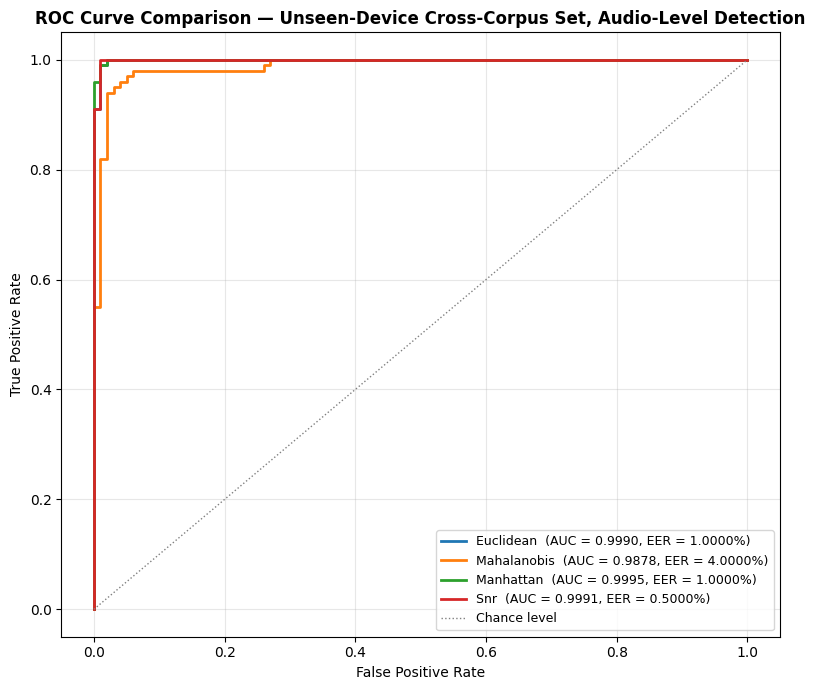

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_unseen_devices_audio_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
###########################################
"""Additional ROC Curves — Audio-Level and Window-Level Detection (loaded from cached eer_detail files)"""
###########################################



def plot_detection_roc_comparison(results_by_metric, level, title, output_file_path, dpi=FIGURE_DPI):
    """
    ROC at a given detection level ('window' or 'audio'). Label convention
    in eer_evaluation.py: label = 1 genuine, label = 0 impostor/spliced,
    with distances INVERTED internally by calculate_eer(); roc_curve here
    is computed the same way (pos_label=1 on the inverted score) so AUC/EER
    match calculate_eer()'s own reporting.
    """
    fig, ax = plt.subplots(figsize=(8, 7))

    for distance_metric, full_result in results_by_metric.items():
        level_result = full_result[level]
        scores_inverted = -np.asarray(level_result['scores'])  # same inversion as calculate_eer()
        labels = level_result['labels']

        false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores_inverted, pos_label=1)
        roc_auc = auc(false_positive_rate, true_positive_rate)
        ax.plot(false_positive_rate, true_positive_rate, linewidth=2,
                label=f"{distance_metric.capitalize()}  (AUC = {roc_auc:.4f}, EER = {level_result['eer']:.4%})")

    ax.plot([0, 1], [0, 1], color='gray', linestyle=':', linewidth=1, label='Chance level')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_file_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"ROC curve comparison saved to {output_file_path}")


# --- Final test set (in-domain) — only euclidean was persisted ---
final_test_detail_by_metric = {
    "euclidean": load_eer_detail(eval_run_name),
}
for level in ("window", "audio"):
    plot_detection_roc_comparison(
        final_test_detail_by_metric, level=level,
        title=f"ROC Curve — Final Test Set, {level.capitalize()}-Level Detection",
        output_file_path=os.path.join(output_path, f"roc_final_test_{level}_{eval_run_name}.png"),
    )

# --- Unseen-device cross-corpus set — all four metrics were persisted ---
unseen_detail_by_metric = {
    distance_metric: load_eer_detail(f"unseen_devices_{('' if distance_metric == 'euclidean' else distance_metric + '_')}{eval_run_name}")
    for distance_metric in ["euclidean", "mahalanobis", "manhattan", "snr"]
}
for level in ("window", "audio"):
    plot_detection_roc_comparison(
        unseen_detail_by_metric, level=level,
        title=f"ROC Curve Comparison — Unseen-Device Cross-Corpus Set, {level.capitalize()}-Level Detection",
        output_file_path=os.path.join(output_path, f"roc_unseen_devices_{level}_{eval_run_name}.png"),
    )

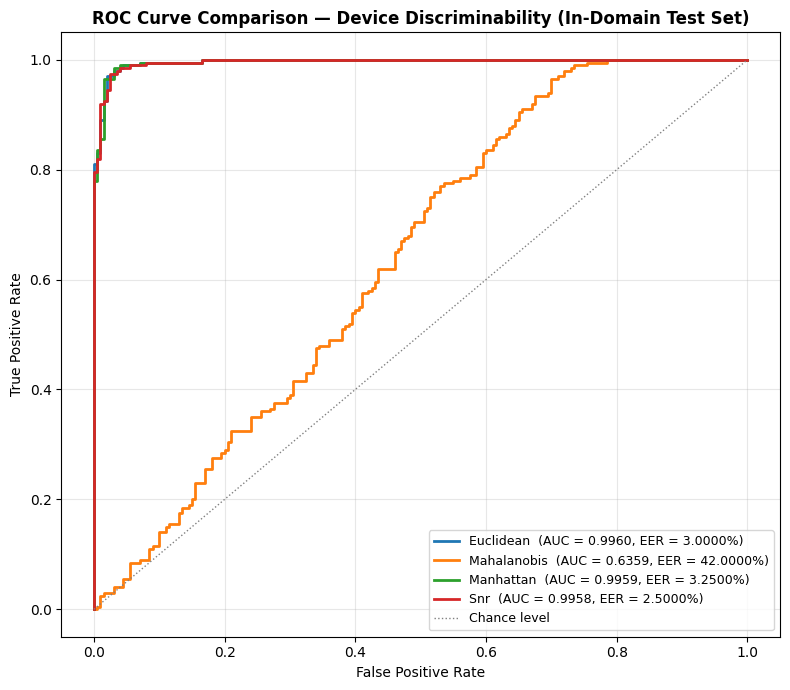

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_comparison_device_discriminability_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


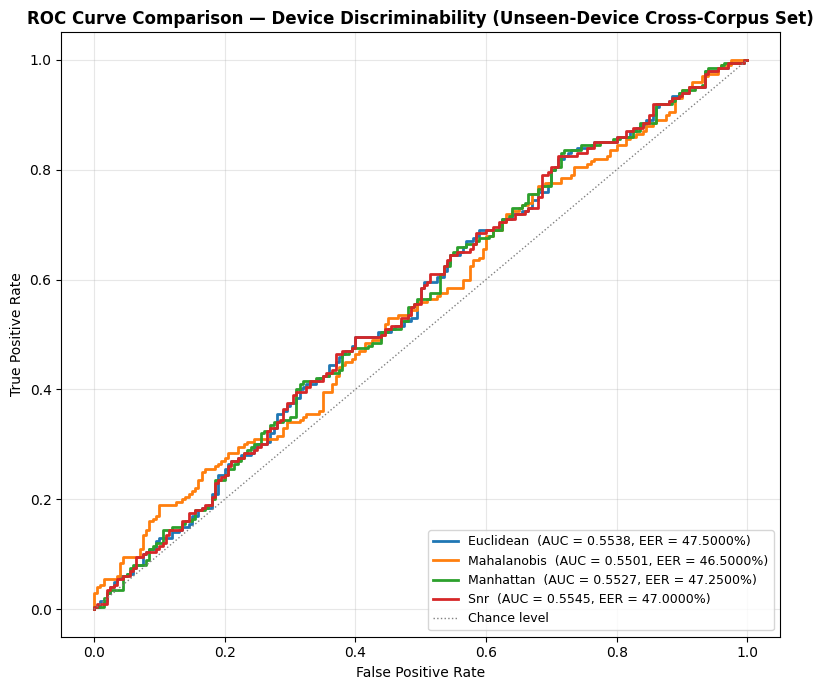

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_comparison_unseen_device_discriminability_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


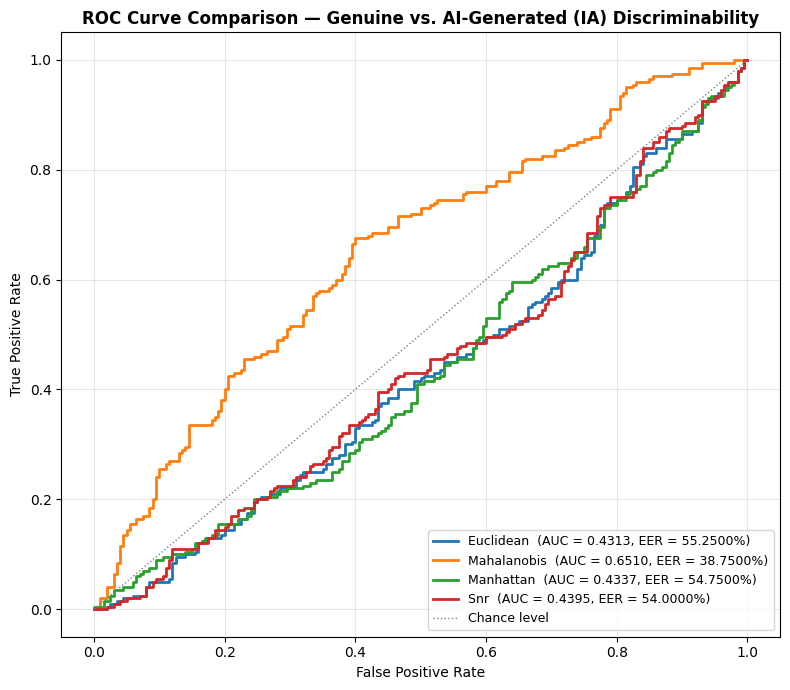

ROC curve comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/roc_comparison_ia_discriminability_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
###########################################
"""Additional ROC Curves — Device- and IA-Discriminability (loaded from cached results)"""
###########################################
# Reuses the score/label populations already computed and cached to disk by
# evaluate_device_discriminability_eer() / evaluate_ia_discriminability_eer(),
# so no model inference, dataset reload, or embedding recomputation is required.

ROC_DISTANCE_METRICS = ["euclidean", "mahalanobis", "manhattan", "snr"]


def load_discriminability_result(file_prefix, distance_metric, run_name, output_path=output_path):
    """
    Loads a cached discriminability-EER result (scores, labels, eer, ...)
    saved by evaluate_device_discriminability_eer() or
    evaluate_ia_discriminability_eer().
    """
    file_path = os.path.join(output_path, f"{file_prefix}_{distance_metric}_{run_name}.pkl")
    with open(file_path, "rb") as f:
        return pickle.load(f)


def plot_roc_curve_comparison(results_by_metric, title, output_file_path, dpi=FIGURE_DPI):
    """
    Overlays the ROC curve of each distance metric on a single axis, using
    the raw score/label population stored in each cached discriminability
    result (label convention: 0 = genuine pair, 1 = impostor pair, matching
    compute_eer_from_scores()).
    """
    fig, ax = plt.subplots(figsize=(8, 7))

    for distance_metric, result in results_by_metric.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(
            result["labels"], result["scores"], pos_label=1
        )
        roc_auc = auc(false_positive_rate, true_positive_rate)
        ax.plot(false_positive_rate, true_positive_rate, linewidth=2,
                label=f"{distance_metric.capitalize()}  (AUC = {roc_auc:.4f}, EER = {result['eer']:.4%})")

    ax.plot([0, 1], [0, 1], color='gray', linestyle=':', linewidth=1, label='Chance level')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9, loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_file_path, dpi=dpi, bbox_inches='tight')
    plt.show()
    print(f"ROC curve comparison saved to {output_file_path}")


# --- Device-discriminability ROC (in-domain test set) ---
device_discriminability_by_metric = {
    distance_metric: load_discriminability_result("device_discriminability_eer", distance_metric, eval_run_name)
    for distance_metric in ROC_DISTANCE_METRICS
}
plot_roc_curve_comparison(
    device_discriminability_by_metric,
    title="ROC Curve Comparison — Device Discriminability (In-Domain Test Set)",
    output_file_path=os.path.join(output_path, f"roc_comparison_device_discriminability_{eval_run_name}.png"),
)

# --- Device-discriminability ROC (unseen-device cross-corpus set) ---
unseen_device_discriminability_by_metric = {
    distance_metric: load_discriminability_result(
        "device_discriminability_eer", distance_metric, f"unseen_devices_{eval_run_name}"
    )
    for distance_metric in ROC_DISTANCE_METRICS
}
plot_roc_curve_comparison(
    unseen_device_discriminability_by_metric,
    title="ROC Curve Comparison — Device Discriminability (Unseen-Device Cross-Corpus Set)",
    output_file_path=os.path.join(output_path, f"roc_comparison_unseen_device_discriminability_{eval_run_name}.png"),
)

# --- IA-discriminability ROC (genuine vs. AI-generated) ---
ia_discriminability_by_metric = {
    distance_metric: load_discriminability_result("ia_discriminability_eer", distance_metric, eval_run_name)
    for distance_metric in ROC_DISTANCE_METRICS
}
plot_roc_curve_comparison(
    ia_discriminability_by_metric,
    title="ROC Curve Comparison — Genuine vs. AI-Generated (IA) Discriminability",
    output_file_path=os.path.join(output_path, f"roc_comparison_ia_discriminability_{eval_run_name}.png"),
)

In [ ]:
###########################################
"""Bootstrap Confidence Intervals — execution"""
###########################################
bootstrap_results = {"detection": {}, "pairwise_eer": {}, "localization": {},
                     "calibrated_threshold": {}, "knn_accuracy": None}

# 1) Audio-level EER / FAR / FRR (frozen threshold) — in-domain, cross-corpus, IA splicing
audio_level_sources = {
    "final_test_euclidean":   final_test_results['audio'],
    "final_test_mahalanobis": final_test_results_mahalanobis['audio'],
    "final_test_manhattan":   final_test_results_manhattan['audio'],
    "final_test_snr":         final_test_results_snr['audio'],
    "unseen_euclidean":       unseen_devices_results['audio'],
    "unseen_mahalanobis":     unseen_devices_results_mahalanobis['audio'],
    "unseen_manhattan":       unseen_devices_results_manhattan['audio'],
    "unseen_snr":             unseen_devices_results_snr['audio'],
    "ia_splicing_euclidean":  ia_splicing_results['audio_eer'],
    "ia_splicing_mahalanobis": ia_splicing_results_mahalanobis['audio_eer'],
    "ia_splicing_manhattan":  ia_splicing_results_manhattan['audio_eer'],
    "ia_splicing_snr":        ia_splicing_results_snr['audio_eer'],
}
for source_name, audio_results in audio_level_sources.items():
    bootstrap_results["detection"][source_name] = bootstrap_detection_metrics(
        audio_results['scores'], audio_results['labels'], audio_results['optimal_threshold'])
    print(f"[{source_name}]")
    for metric_name, ci in bootstrap_results["detection"][source_name].items():
        print(f"   {metric_name.upper():<4} {format_confidence_interval(ci)}")

# 2) Window-pair discriminability EER
pairwise_sources = {
    "device_euclidean": device_discriminability_euclidean,
    "device_mahalanobis": device_discriminability_mahalanobis,
    "device_manhattan": device_discriminability_manhattan,
    "device_snr": device_discriminability_snr,
    "unseen_device_euclidean": unseen_device_discriminability_euclidean,
    "unseen_device_mahalanobis": unseen_device_discriminability_mahalanobis,
    "unseen_device_manhattan": unseen_device_discriminability_manhattan,
    "unseen_device_snr": unseen_device_discriminability_snr,
    "ia_euclidean": ia_discriminability_euclidean,
    "ia_mahalanobis": ia_discriminability_mahalanobis,
    "ia_manhattan": ia_discriminability_manhattan,
    "ia_snr": ia_discriminability_snr,
}
for source_name, pairwise_result in pairwise_sources.items():
    bootstrap_results["pairwise_eer"][source_name] = bootstrap_pairwise_eer(
        pairwise_result['scores'], pairwise_result['labels'])
    print(f"[{source_name}] EER {format_confidence_interval(bootstrap_results['pairwise_eer'][source_name])}")

# 3) Localization strategies (paired) — synthetic splices and IA splicing
localization_sources = {
    "final_test_euclidean": (final_test_results['audio']['localization_records'],
                             final_test_results['audio']['localization_tolerance_s']),
    "unseen_euclidean":     (unseen_devices_results['audio']['localization_records'],
                             unseen_devices_results['audio']['localization_tolerance_s']),
    "ia_splicing_euclidean": (ia_splicing_results['audio']['per_sample'],
                              ia_splicing_results['audio']['tolerance_s']),
}
for source_name, (records, tolerance_s) in localization_sources.items():
    bootstrap_results["localization"][source_name] = bootstrap_localization_strategies(records, tolerance_s)
    print(f"[{source_name}]")
    for strategy_key, strategy_ci in bootstrap_results["localization"][source_name].items():
        print(f"   {strategy_key:<15} error: {format_confidence_interval(strategy_ci['mean_error_s'], as_percent=False)} s"
              f" | hit: {format_confidence_interval(strategy_ci['hit_rate'])}")
        if "hit_rate_diff_vs_baseline" in strategy_ci:
            print(f"   {'':<15} Δhit vs baseline: {format_confidence_interval(strategy_ci['hit_rate_diff_vs_baseline'])}")
            print(f"   {'':<15} Δerror vs baseline: {format_confidence_interval(strategy_ci['mean_error_diff_vs_baseline_s'], as_percent=False)} s")

# 4) Stability of the calibrated (frozen) thresholds, from val_audios
calibration_sources = {
    "euclidean": eer_results, "mahalanobis": eer_results_mahalanobis,
    "manhattan": eer_results_manhattan, "snr": eer_results_snr,
}
for metric_name, calibration_result in calibration_sources.items():
    bootstrap_results["calibrated_threshold"][metric_name] = bootstrap_calibrated_threshold(
        calibration_result['audio']['scores'], calibration_result['audio']['labels'])
    print(f"[threshold {metric_name}] "
          f"{format_confidence_interval(bootstrap_results['calibrated_threshold'][metric_name], as_percent=False)}")

# 5) kNN test accuracy (cluster bootstrap by audio)
knn_group_ids = np.array([window['audio_id'] for window in final_test_windows])
bootstrap_results["knn_accuracy"] = bootstrap_grouped_accuracy(
    val_labels.numpy(), predictions, knn_group_ids)
print(f"[kNN test accuracy] {format_confidence_interval(bootstrap_results['knn_accuracy'])}")

with open(bootstrap_results_path, "wb") as f:
    pickle.dump(bootstrap_results, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Bootstrap results saved to {bootstrap_results_path}")
with open(bootstrap_results_summary_path, "w") as f:
    json.dump(bootstrap_results, f, indent=2, default=str)
print(f"Bootstrap summary (JSON) saved to {bootstrap_results_summary_path}")

[final_test_euclidean]
   EER  26.0000%  [20.5000%, 32.5000%] (95% CI, n=200)
   FAR  41.0000%  [32.0000%, 50.0000%] (95% CI, n=200)
   FRR  18.0000%  [11.0000%, 26.0000%] (95% CI, n=200)
[final_test_mahalanobis]
   EER  32.0000%  [24.5000%, 38.0125%] (95% CI, n=200)
   FAR  31.0000%  [22.0000%, 40.0000%] (95% CI, n=200)
   FRR  32.0000%  [23.0000%, 41.0000%] (95% CI, n=200)
[final_test_manhattan]
   EER  23.5000%  [18.5000%, 32.0000%] (95% CI, n=200)
   FAR  36.0000%  [27.0000%, 46.0000%] (95% CI, n=200)
   FRR  19.0000%  [11.9750%, 28.0000%] (95% CI, n=200)
[final_test_snr]
   EER  27.0000%  [19.5000%, 33.5000%] (95% CI, n=200)
   FAR  34.0000%  [25.0000%, 43.0000%] (95% CI, n=200)
   FRR  21.0000%  [13.0000%, 30.0000%] (95% CI, n=200)
[unseen_euclidean]
   EER  1.0000%  [0.0000%, 3.5000%] (95% CI, n=200)
   FAR  100.0000%  [100.0000%, 100.0000%] (95% CI, n=200)
   FRR  0.0000%  [0.0000%, 0.0000%] (95% CI, n=200)
[unseen_mahalanobis]
   EER  4.0000%  [1.5000%, 7.0125%] (95% CI, n=200

Additional plots

In [ ]:
print("=== FINAL EVALUATION ON UNSEEN-DEVICE CROSS-CORPUS SET (frozen threshold) ===")

if os.path.exists(unseen_devices_dataset_path):
    print(f"unseen_devices_dataset already exists, loading from {unseen_devices_dataset_path}")
    with open(unseen_devices_dataset_path, "rb") as f:
        unseen_devices_dataset = pickle.load(f)
else:
    unseen_devices_dataset = load_unseen_devices_dataset()
    with open(unseen_devices_dataset_path, "wb") as f:
        pickle.dump(unseen_devices_dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"unseen_devices_dataset saved to {unseen_devices_dataset_path}")

=== FINAL EVALUATION ON UNSEEN-DEVICE CROSS-CORPUS SET (frozen threshold) ===
unseen_devices_dataset already exists, loading from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/unseen_devices_dataset.pkl


In [ ]:

if 'model' not in dir():

    #model, global_mean, global_std, history = load_model_and_state(output_path, run_name, device)
    model, history = load_model_and_state(output_path, run_name, device)
model.to(device)

if 'history' not in dir():
    with open(final_history_path, "rb") as f:
        history = pickle.load(f)
# Generate TRAIN windows (all data used to train the final model)
# Generate TEST windows (the 10% held out at the start, never seen during training)

# Ensure final_training_dataset is available regardless of execution order
if 'final_training_dataset' not in dir():
    print(f"final_training_dataset not in memory, loading from {windowed_dataset_path}")
    with open(windowed_dataset_path, "rb") as f:
        final_training_dataset = pickle.load(f)

train_embedding_loader = DataLoader(
    EmbeddingExtractionDataset(final_training_dataset, device_to_label),#, global_mean, global_std),
    batch_size=BATCH_SIZE
)
val_embedding_loader = DataLoader(
    EmbeddingExtractionDataset(final_test_windows, device_to_label),#, global_mean, global_std),
    batch_size=BATCH_SIZE
)

# The model and device are already ready from train_final_model()
train_embeddings, train_labels = extract_embeddings(model, train_embedding_loader, device)
val_embeddings, val_labels = extract_embeddings(model, val_embedding_loader, device)

In [ ]:

###########################################
"""Embedding Collapse Diagnostic — consecutive-window distance scale and embedding spread"""
###########################################

def collect_raw_consecutive_distances(audio_pool, n_audios, distance_metric="euclidean", VI=None):
    """Concatenates the raw consecutive-window distances of `n_audios` randomly sampled audios."""
    sampled_audios = random.sample(audio_pool, min(n_audios, len(audio_pool)))
    distance_arrays = []
    for audio_info in sampled_audios:
        distances, _ = _extract_consecutive_distances(
            audio_info['audio'], model, device, sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
            n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, distance_metric=distance_metric, VI=VI
        )
        if len(distances) > 0:
            distance_arrays.append(distances)
    return np.concatenate(distance_arrays)


set_all_seeds(RANDOM_SEED)
diagnostic_pools = {"val (in-domain)": val_audios, "unseen devices": unseen_devices_dataset}

for pool_name, audio_pool in diagnostic_pools.items():
    pool_distances = collect_raw_consecutive_distances(audio_pool, DISTANCE_DIAGNOSTIC_N_AUDIOS)
    percentile_values = np.percentile(pool_distances, DISTANCE_DIAGNOSTIC_PERCENTILES)
    percentile_report = " | ".join(f"p{p} = {v:.6f}" for p, v in zip(DISTANCE_DIAGNOSTIC_PERCENTILES, percentile_values))
    print(f"[{pool_name}] consecutive distances (n={len(pool_distances)}): {percentile_report}")

# Embedding spread on the training set (L2-normalized embeddings)
per_dimension_std = train_embeddings.std(dim=0)
print(f"\nMean per-dimension std of train embeddings: {per_dimension_std.mean().item():.6f}")
print(f"Mean embedding L2 norm:                     {train_embeddings.norm(dim=1).mean().item():.6f}")
print(f"Reference for isotropic unit vectors (1/sqrt(OUT_DIM)): {1.0 / np.sqrt(OUT_DIM):.6f}")

[val (in-domain)] consecutive distances (n=49200): p5 = 0.058296 | p50 = 0.222941 | p95 = 0.692716
[unseen devices] consecutive distances (n=23922): p5 = 0.010166 | p50 = 0.032813 | p95 = 0.077548

Mean per-dimension std of train embeddings: 0.122913
Mean embedding L2 norm:                     1.000000
Reference for isotropic unit vectors (1/sqrt(OUT_DIM)): 0.125000


In [ ]:

###########################################
"""Embedding Collapse Diagnostic — spread and intra/inter-device distances"""
###########################################

def collect_pool_embeddings(audio_pool, n_windows, model, device,
                            sr=SR, win_sec=WIN_LENGTH_SEC, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT):
    """Embeds `n_windows` random windows (one per randomly drawn audio) and returns (embeddings, device_names)."""
    win_len = int(win_sec * sr)
    features, device_names = [], []
    for audio_info in random.choices(audio_pool, k=n_windows):
        signal = audio_info['audio']
        start = random.randint(0, max(len(signal) - win_len, 0))
        feature = extract_stft_power_spectrogram_db(signal[start:start + win_len], sr=sr, n_fft=n_fft,
                                                    hop_length=hop_length_fft, freq_mask=TRAIN_FREQUENCY_MASK)
        features.append((feature - np.mean(feature)) / (np.std(feature) + 1e-8))
        device_names.append(audio_info['device'])

    model.eval()
    specs = torch.tensor(np.array(features), dtype=torch.float32).unsqueeze(1).to(device)
    with torch.no_grad():
        embeddings = model(specs).cpu()
    return embeddings, np.array(device_names)


set_all_seeds(RANDOM_SEED)
for pool_name, audio_pool in {"val (in-domain)": val_audios, "unseen devices": unseen_devices_dataset}.items():
    pool_embeddings, pool_device_names = collect_pool_embeddings(
        audio_pool, EMBEDDING_DIAGNOSTIC_N_WINDOWS, model, device)

    pairwise_distances = torch.cdist(pool_embeddings, pool_embeddings)
    same_device_mask = torch.tensor(pool_device_names[:, None] == pool_device_names[None, :])
    off_diagonal_mask = ~torch.eye(len(pool_embeddings), dtype=torch.bool)

    intra_device = pairwise_distances[same_device_mask & off_diagonal_mask]
    inter_device = pairwise_distances[~same_device_mask]

    print(f"[{pool_name}]")
    print(f"   Mean per-dimension std:   {pool_embeddings.std(dim=0).mean().item():.6f}  "
          f"(isotropic reference: {1.0 / np.sqrt(OUT_DIM):.6f})")
    print(f"   Mean L2 norm:             {pool_embeddings.norm(dim=1).mean().item():.6f}")
    print(f"   Intra-device distance:    mean = {intra_device.mean().item():.6f}")
    print(f"   Inter-device distance:    mean = {inter_device.mean().item():.6f}")


[val (in-domain)]
   Mean per-dimension std:   0.122460  (isotropic reference: 0.125000)
   Mean L2 norm:             1.000000
   Intra-device distance:    mean = 0.646568
   Inter-device distance:    mean = 1.418002
[unseen devices]
   Mean per-dimension std:   0.007473  (isotropic reference: 0.125000)
   Mean L2 norm:             1.000000
   Intra-device distance:    mean = 0.079868
   Inter-device distance:    mean = 0.082957


In [ ]:
print(history['train_loss'][:5], history['train_loss'][-5:])
print(len(history['train_loss']))

[8.186205226131994, 7.158944354098067, 6.507325035894019, 5.944418799163949, 5.5744083905831365] [0.3302278650813123, 0.29178408661491084, 0.27320264287304896, 0.2848190763332427, 0.33396779403536236]
60


[val (in-domain)] effective bandwidth ≈ 22050 Hz | bins near floor: 0.00%
[unseen devices] effective bandwidth ≈ 7924 Hz | bins near floor: 64.00%


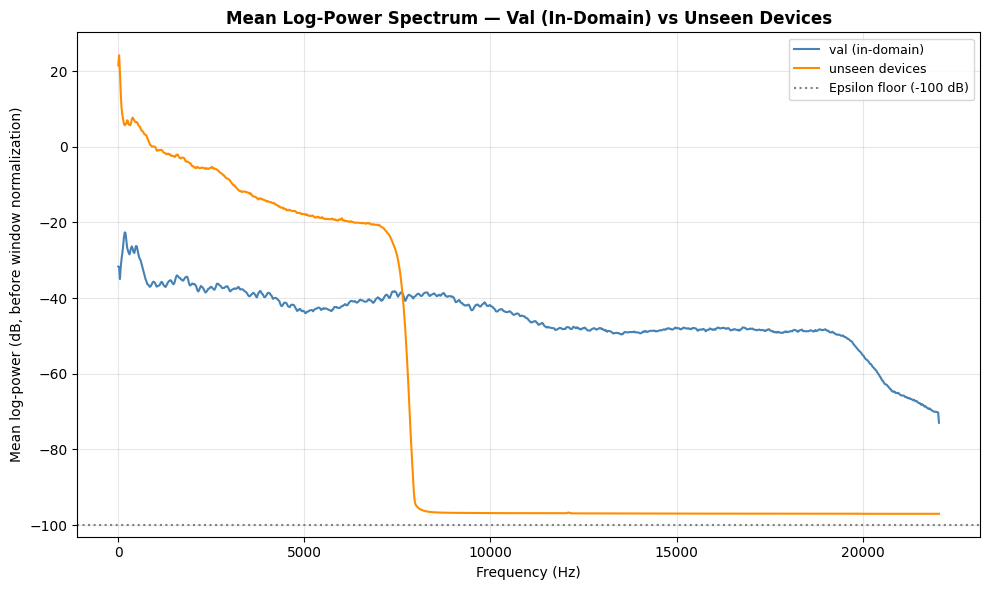

Bandwidth diagnostic saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/mean_spectrum_val_vs_unseen_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:

###########################################
"""Bandwidth Diagnostic — mean log-power spectrum (val vs unseen)"""
###########################################

def mean_log_power_spectrum(audio_pool, n_audios, sr=SR, win_sec=WIN_LENGTH_SEC):
    """Mean per-bin log-power spectrum (dB, BEFORE window normalization) over one random window per audio."""
    win_len = int(win_sec * sr)
    spectra = []
    for audio_info in random.sample(audio_pool, min(n_audios, len(audio_pool))):
        signal = audio_info['audio']
        start = random.randint(0, max(len(signal) - win_len, 0))
        feature = extract_stft_power_spectrogram_db(signal[start:start + win_len], sr=sr)
        spectra.append(feature.mean(axis=1))
    return np.mean(spectra, axis=0)


set_all_seeds(RANDOM_SEED)
frequency_axis_hz = np.fft.rfftfreq(N_FFT, d=1.0 / SR)
floor_db = 10 * np.log10(LOG_POWER_EPSILON)

fig, ax = plt.subplots(figsize=(10, 6))
for pool_name, audio_pool, color in [("val (in-domain)", val_audios, "steelblue"),
                                      ("unseen devices", unseen_devices_dataset, "darkorange")]:
    mean_spectrum_db = mean_log_power_spectrum(audio_pool, SPECTRUM_DIAGNOSTIC_N_AUDIOS)
    ax.plot(frequency_axis_hz, mean_spectrum_db, color=color, linewidth=1.5, label=pool_name)

    populated_bins = frequency_axis_hz[mean_spectrum_db > floor_db + SPECTRUM_DIAGNOSTIC_FLOOR_MARGIN_DB]
    effective_bandwidth_hz = populated_bins.max() if len(populated_bins) else 0.0
    print(f"[{pool_name}] effective bandwidth ≈ {effective_bandwidth_hz:.0f} Hz "
          f"| bins near floor: {np.mean(mean_spectrum_db <= floor_db + SPECTRUM_DIAGNOSTIC_FLOOR_MARGIN_DB):.2%}")

ax.axhline(y=floor_db, color="gray", linestyle=":", label=f"Epsilon floor ({floor_db:.0f} dB)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Mean log-power (dB, before window normalization)")
ax.set_title("Mean Log-Power Spectrum — Val (In-Domain) vs Unseen Devices", fontweight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(SPECTRUM_DIAGNOSTIC_PNG_PATH, dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()
print(f"Bandwidth diagnostic saved to {SPECTRUM_DIAGNOSTIC_PNG_PATH}")


In [ ]:
from scipy.signal import butter, sosfiltfilt

def lowpass_pool(audio_pool, cutoff_hz=LOWPASS_TEST_CUTOFF_HZ, order=LOWPASS_TEST_ORDER, sr=SR):
    sos = butter(order, cutoff_hz, btype="low", fs=sr, output="sos")
    return [{**a, "audio": sosfiltfilt(sos, a["audio"]).astype(a["audio"].dtype)} for a in audio_pool]

val_lowpassed = lowpass_pool(val_audios)

for pool_name, audio_pool in {"val (in-domain)": val_audios,
                              "val (low-passed)": val_lowpassed,
                              "unseen devices": unseen_devices_dataset}.items():
    set_all_seeds(RANDOM_SEED)   # same sampled windows for val vs val_lowpassed (paired comparison)
    pool_embeddings, pool_device_names = collect_pool_embeddings(
        audio_pool, EMBEDDING_DIAGNOSTIC_N_WINDOWS, model, device)

    pairwise_distances = torch.cdist(pool_embeddings, pool_embeddings)
    same_device_mask = torch.tensor(pool_device_names[:, None] == pool_device_names[None, :])
    off_diagonal_mask = ~torch.eye(len(pool_embeddings), dtype=torch.bool)

    print(f"[{pool_name}] per-dim std = {pool_embeddings.std(dim=0).mean().item():.6f} | "
          f"intra = {pairwise_distances[same_device_mask & off_diagonal_mask].mean().item():.6f} | "
          f"inter = {pairwise_distances[~same_device_mask].mean().item():.6f}")

[val (in-domain)] per-dim std = 0.122460 | intra = 0.646568 | inter = 1.418002
[val (low-passed)] per-dim std = 0.046543 | intra = 0.312897 | inter = 0.528243
[unseen devices] per-dim std = 0.007413 | intra = 0.078850 | inter = 0.082376


In [ ]:

with open(final_holdout_windows_path, "rb") as f:
    holdout = pickle.load(f)

def summarize_windows(split_name, windows):
    """Prints the number of windows, recordings and windows per recording."""
    windows_per_recording = np.array(list(Counter(w['audio_id'] for w in windows).values()))
    print(f"{split_name}: {len(windows)} windows | {len(windows_per_recording)} recordings | "
          f"per recording: {windows_per_recording.mean():.1f} ± {windows_per_recording.std():.1f} "
          f"(min {windows_per_recording.min()}, max {windows_per_recording.max()})")

summarize_windows("Fitting (train)", holdout["train"])
summarize_windows("Internal control (validation)", holdout["validation"])

del holdout

Fitting (train): 29971 windows | 714 recordings | per recording: 42.0 ± 6.7 (min 26, max 55)
Internal control (validation): 9568 windows | 126 recordings | per recording: 75.9 ± 7.2 (min 65, max 88)


In [ ]:

with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    split = pickle.load(f)
val_audios = split["val_audios"]
test_audios = split["test_audios"]
del split

with open(os.path.join(output_path, "unseen_devices_dataset.pkl"), "rb") as f:
    unseen_devices_dataset = pickle.load(f)

min_dur = int(3.0 * WIN_LENGTH_SEC * SR)
for name, pool in {"val": val_audios, "test": test_audios,
                   "unseen": unseen_devices_dataset}.items():
    eligible = [a for a in pool if len(a["audio"]) >= min_dur]
    print(name, len(pool), len(eligible),
          min(len(a["audio"]) for a in eligible) / SR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
val 160 160 69.53566893424036
test 200 200 65.7490022675737
unseen 504 504 14.395759637188208


In [ ]:

for name, pool in {"val": val_audios, "test": test_audios}.items():
    srs = {a["sr"] for a in pool}
    durs = np.array([len(a["audio"]) / a["sr"] for a in pool])
    print(name, "frecuencias:", srs,
          "| min/med/max (s):", durs.min().round(2), np.median(durs).round(2), durs.max().round(2))
    shortest = min(pool, key=lambda a: len(a["audio"]) / a["sr"])
    print("   shortest:", shortest["filename"], shortest["condition"], shortest["device"])

val frecuencias: {44100} | min/med/max (s): 69.54 76.73 88.82
   más corto: speaker_15.wav speech_clean huawei_nova_9
test frecuencias: {44100} | min/med/max (s): 65.75 77.56 88.09
   más corto: speaker_18.wav speech_clean huawei_nova_9


In [ ]:
with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
      s = pickle.load(f)
all_audios = s["raw_train_audios"] + s["val_audios"] + s["test_audios"]
d = np.array([len(a["audio"]) / a["sr"] for a in all_audios])
print(len(d), d.min(), np.median(d), d.max(), d.sum() / 3600)

1200 65.1873469387755 76.5670068027211 88.82072562358276 25.607564877802975


In [ ]:

from itertools import permutations

set_all_seeds(RANDOM_SEED)  # same seed as the evaluation


def audit_window_level_splice_points(audio_pool, top_db=TOP_DB, sr=SR):

    device_names = sorted({item['device'] for item in audio_pool})
    audios_by_device = {
        device_name: [item for item in audio_pool if item['device'] == device_name]
        for device_name in device_names
    }

    n_splices = 0
    n_without_destination_content = 0
    overshoot_s = []

    for source_device, destination_device in permutations(device_names, 2):
        source_item = random.choice(audios_by_device[source_device])
        destination_item = random.choice(audios_by_device[destination_device])

        spliced_audio, cut_sample = generate_simple_splicing(
            source_item['audio'], destination_item['audio'], top_db=top_db
        )
        if spliced_audio is None:
            continue

        n_splices += 1
        destination_length = len(destination_item['audio'])
        if cut_sample >= destination_length:
            n_without_destination_content += 1
            overshoot_s.append((cut_sample - destination_length) / sr)

    fraction = n_without_destination_content / max(n_splices, 1)
    mean_overshoot_s = float(np.mean(overshoot_s)) if overshoot_s else None

    print(f"Splices generated: {n_splices} | "
          f"without destination content: {n_without_destination_content} ({fraction:.1%})")
    if mean_overshoot_s is not None:
        print(f"Mean overshoot of the cut beyond the end of the destination: "
              f"{mean_overshoot_s:.2f} s")

    return {
        "n_splices": n_splices,
        "n_without_destination_content": n_without_destination_content,
        "fraction": fraction,
        "mean_overshoot_s": mean_overshoot_s,
    }


print("Validation set:")
validation_audit = audit_window_level_splice_points(val_audios)
print("Test set:")
test_audit = audit_window_level_splice_points(test_audios)

Validation set:
Splices generated: 377 | without destination content: 29 (7.7%)
Mean overshoot of the cut beyond the end of the destination: 5.20 s
Test set:
Splices generated: 348 | without destination content: 14 (4.0%)
Mean overshoot of the cut beyond the end of the destination: 4.73 s


In [ ]:


def build_duration_records(audio_pools):
    """
    Builds one record per audio item (device x condition x speaker file)
    with its duration in seconds, computed from the in-memory signal.
    """
    records = []
    for split_name, audio_items in audio_pools.items():
        for audio_info in audio_items:
            records.append({
                "split": split_name,
                "condition": audio_info["condition"],
                "speaker": audio_info["filename"],
                "device": audio_info["device"],
                "duration_sec": len(audio_info["audio"]) / audio_info["sr"],
            })
    return pd.DataFrame.from_records(records)


def audit_speaker_durations(duration_records,
                            tolerance_sec=SPEAKER_DURATION_TOLERANCE_SEC,
                            exact_decimals=DURATION_EXACT_DECIMALS,
                            decimals=SPEAKER_DURATION_DECIMALS):
    """
    One row per (condition, speaker) take, aggregated over ALL devices:
    duration, cross-device spread, number of distinct durations and a
    same-duration flag.
    """
    audit = (
        duration_records
        .assign(duration_exact=duration_records["duration_sec"].round(exact_decimals))
        .groupby(["condition", "speaker"])
        .agg(split=("split", "first"),
             n_devices=("device", "nunique"),
             duration_sec=("duration_sec", "median"),
             min_duration_sec=("duration_sec", "min"),
             max_duration_sec=("duration_sec", "max"),
             n_distinct_durations=("duration_exact", "nunique"))
        .reset_index()
    )
    audit["spread_sec"] = audit["max_duration_sec"] - audit["min_duration_sec"]
    audit["same_duration_across_devices"] = audit["spread_sec"] <= tolerance_sec
    return audit.round(decimals)
required_pool_names = ("raw_train_audios", "val_audios", "test_audios")
if any(pool_name not in globals() for pool_name in required_pool_names):
    with open(raw_split_path, "rb") as f:
        loaded_split = pickle.load(f)
    duration_audit_pools = {
        "train": loaded_split["raw_train_audios"],
        "val": loaded_split["val_audios"],
        "test": loaded_split["test_audios"],
    }
    del loaded_split
else:
    duration_audit_pools = {
        "train": raw_train_audios,
        "val": val_audios,
        "test": test_audios,
    }

duration_records = build_duration_records(duration_audit_pools)
speaker_duration_audit = audit_speaker_durations(duration_records)

print(speaker_duration_audit
      .sort_values(["condition", "spread_sec", "speaker"], ascending=[True, False, True])
      [["condition", "speaker", "split", "n_devices", "duration_sec",
        "spread_sec", "n_distinct_durations", "same_duration_across_devices"]]
      .to_string(index=False))

n_devices_total = duration_records["device"].nunique()
files_per_device = duration_records.groupby("device").size()

print("\n=== Duration audit summary ===")
print(f"Devices:                        {n_devices_total}")
print(f"Files per device:               min={files_per_device.min()} | max={files_per_device.max()}")
print(f"Takes (condition x speaker):    {len(speaker_duration_audit)}")
print(f"Takes covered by all devices:   {int((speaker_duration_audit['n_devices'] == n_devices_total).sum())}")
print(f"Same duration on all devices:   {int(speaker_duration_audit['same_duration_across_devices'].sum())}")
print(f"Takes with >1 distinct dur.:    {int((speaker_duration_audit['n_distinct_durations'] > 1).sum())}")
print(f"Max spread observed:            {speaker_duration_audit['spread_sec'].max():.{SPEAKER_DURATION_DECIMALS}f} s")

for condition_name, condition_audit in speaker_duration_audit.groupby("condition"):
    print(f"[{condition_name}] speakers={len(condition_audit)} | duration min/median/max = "
          f"{condition_audit['duration_sec'].min():.2f} / {condition_audit['duration_sec'].median():.2f} / "
          f"{condition_audit['duration_sec'].max():.2f} s")

# Clean vs noise: same speaker, same duration?
clean_vs_noise = (
    speaker_duration_audit.pivot(index="speaker", columns="condition", values="duration_sec")
    .assign(difference_sec=lambda df: (df["speech_clean"] - df["speech_noise"]).abs())
)
print(f"Max clean-vs-noise duration difference: "
      f"{clean_vs_noise['difference_sec'].max():.{SPEAKER_DURATION_DECIMALS}f} s")

   condition        speaker split  n_devices  duration_sec  spread_sec  n_distinct_durations  same_duration_across_devices
speech_clean  speaker_1.wav train         20       68.0732         0.0                     1                          True
speech_clean speaker_10.wav  test         20       88.0942         0.0                     1                          True
speech_clean speaker_11.wav train         20       77.7807         0.0                     1                          True
speech_clean speaker_12.wav train         20       82.0985         0.0                     1                          True
speech_clean speaker_13.wav train         20       78.4203         0.0                     1                          True
speech_clean speaker_14.wav train         20       72.8006         0.0                     1                          True
speech_clean speaker_15.wav   val         20       69.5357         0.0                     1                          True
speech_clean spe

In [ ]:


from scipy.signal import fftconvolve


def estimate_lag_samples(reference_signal, target_signal, max_lag_samples):
    """
    FFT cross-correlation lag of target relative to reference, restricted to
    +/- max_lag_samples. Sign convention matches np.correlate(reference, target)
    as used in check_take_alignment.
    """
    n = min(len(reference_signal), len(target_signal))
    ref = reference_signal[:n] - reference_signal[:n].mean()
    tgt = target_signal[:n] - target_signal[:n].mean()
    correlation = fftconvolve(ref, tgt[::-1], mode="full")
    center = n - 1
    window = correlation[center - max_lag_samples:center + max_lag_samples + 1]
    return int(np.argmax(window)) - max_lag_samples


def audit_cross_device_lags(audio_pools, reference_device=LAG_AUDIT_REFERENCE_DEVICE,
                            max_lag_sec=LAG_AUDIT_MAX_LAG_SEC, sr=SR):
    """
    For every (condition, speaker) take, estimates the lag of each device
    against a reference device. Returns one record per (take, device).
    """
    all_items = [item for pool in audio_pools.values() for item in pool]
    device_names = sorted({item["device"] for item in all_items})
    reference_device = reference_device or device_names[0]
    max_lag_samples = round(max_lag_sec * sr)

    items_by_take = {}
    for item in all_items:
        items_by_take.setdefault((item["condition"], item["filename"]), {})[item["device"]] = item

    records = []
    for (condition, filename), items_by_device in items_by_take.items():
        if reference_device not in items_by_device:
            continue
        reference_signal = items_by_device[reference_device]["audio"]
        for device_name, item in items_by_device.items():
            if device_name == reference_device:
                continue
            records.append({
                "condition": condition,
                "speaker": filename,
                "device": device_name,
                "lag_samples": estimate_lag_samples(reference_signal, item["audio"], max_lag_samples),
            })
    lag_records = pd.DataFrame.from_records(records)
    lag_records["lag_ms"] = lag_records["lag_samples"] / sr * 1000
    return lag_records, reference_device
def build_fragment_reference_devices(audio_items):
    """Device whose audio was used to compute each take's shared fragments (first one encountered)."""
    reference_device_by_take = {}
    for audio_info in audio_items:
        reference_device_by_take.setdefault(
            (audio_info["condition"], audio_info["filename"]), audio_info["device"]
        )
    return reference_device_by_take


def build_device_lag_lookup(lag_records, lag_reference_device):
    """(condition, speaker, device) -> lag in samples against the lag-audit reference device."""
    lag_lookup = {
        (row.condition, row.speaker, row.device): int(row.lag_samples)
        for row in lag_records.itertuples()
    }
    return lag_lookup, lag_reference_device
# Cross-device lag audit
lag_records, lag_reference_device = audit_cross_device_lags(duration_audit_pools)

lag_by_device = (
    lag_records.groupby("device")["lag_samples"]
    .agg(mean="mean", std="std", min="min", max="max",
         max_abs=lambda s: s.abs().max())
    .round(2)
)
print(f"Reference device: {lag_reference_device}\n")
print(lag_by_device.to_string())

max_abs_lag = int(lag_records["lag_samples"].abs().max())
n_over_tolerance = int((lag_records["lag_samples"].abs() > LAG_AUDIT_TOLERANCE_SAMPLES).sum())
print(f"\nTakes x devices evaluated: {len(lag_records)}")
print(f"Max |lag|: {max_abs_lag} samples ({max_abs_lag / SR * 1000:.4f} ms)")
print(f"Above voiced-guard tolerance ({LAG_AUDIT_TOLERANCE_SAMPLES} samples): {n_over_tolerance}")

Reference device: huawei_nova_9

                    mean     std   min  max  max_abs
device                                              
huawei_nova_9_se   77.08   52.62     1  219      219
huawei_p30        213.32  122.99    11  412      412
iphone_12_mini   -792.45  466.19 -1632  -22     1632
iphone_13        -548.78  324.95 -1152  -10     1152
iphone_xs_max    -360.77  223.23  -805   -1      805
moto_edge_20       84.87   48.39  -133  157      157
moto_edge_30      117.33   66.85    23  288      288
moto_g9_power     -67.17   40.16  -140   -3      140
oneplus_nord       -5.23   32.69   -68   73       73
poco_m4_pro        23.92    7.18    -2   36       36
poco_x4_pro       149.00   79.10    18  283      283
realme_gt          68.00   34.90     9  130      130
redmagic           92.23   53.11     2  182      182
redmi_note_11      23.52   31.57    -1  118      118
rog_phone_3       165.93  103.29     9  399      399
rog_phone_5       195.72  120.57     6  451      451
xiaomi_12    

In [ ]:

FRAGMENT_REFERENCE_DEVICE_BY_TAKE = build_fragment_reference_devices(raw_train_audios)
DEVICE_LAG_LOOKUP, LAG_REFERENCE_DEVICE = build_device_lag_lookup(lag_records, lag_reference_device)


def _device_lag_samples(device_name, take_key):
    if device_name == LAG_REFERENCE_DEVICE:
        return 0
    return DEVICE_LAG_LOOKUP[(take_key[0], take_key[1], device_name)]
def estimate_lag_start_end(reference_signal, target_signal, segment_sec, max_lag_samples, sr=SR):
    segment_len = round(segment_sec * sr)
    lag_start = estimate_lag_samples(reference_signal[:segment_len], target_signal[:segment_len], max_lag_samples)
    lag_end = estimate_lag_samples(reference_signal[-segment_len:], target_signal[-segment_len:], max_lag_samples)
    return lag_start, lag_end

# Example on the worst case
LAG_DRIFT_SEGMENT_SEC = 10.0
worst_row = lag_records.loc[lag_records["lag_samples"].abs().idxmax()]
all_items = [i for pool in duration_audit_pools.values() for i in pool]
lookup = {(i["device"], i["condition"], i["filename"]): i["audio"] for i in all_items}
ref = lookup[(lag_reference_device, worst_row["condition"], worst_row["speaker"])]
tgt = lookup[(worst_row["device"], worst_row["condition"], worst_row["speaker"])]
print(worst_row.to_dict())
print("lag (start, end):", estimate_lag_start_end(ref, tgt, LAG_DRIFT_SEGMENT_SEC, round(LAG_AUDIT_MAX_LAG_SEC * SR)))

{'condition': 'speech_noise', 'speaker': 'speaker_30.wav', 'device': 'iphone_12_mini', 'lag_samples': -1632, 'lag_ms': -37.006802721088434}
lag (start, end): (-1608, -1663)


In [ ]:
CONTAMINATION_GUARD_SAMPLES = LAG_AUDIT_TOLERANCE_SAMPLES

contamination_records = []
for audio_info in raw_train_audios:
    take_key = (audio_info['condition'], audio_info['filename'])
    fragments = shared_unvoiced_fragments[take_key]
    shift_samples = abs(_device_lag_samples(FRAGMENT_REFERENCE_DEVICE_BY_TAKE[take_key], take_key)
                        - _device_lag_samples(audio_info['device'], take_key))
    excess_per_fragment = max(shift_samples - CONTAMINATION_GUARD_SAMPLES, 0)
    total_unvoiced = sum(end - start for start, end in fragments)
    # upper bound: one misaligned edge per fragment
    contaminated = sum(min(excess_per_fragment, end - start) for start, end in fragments)
    contamination_records.append({
        "device": audio_info['device'],
        "contaminated_fraction": contaminated / max(total_unvoiced, 1),
    })

contamination_by_device = (pd.DataFrame(contamination_records)
                           .groupby("device")["contaminated_fraction"]
                           .agg(mean="mean", max="max").round(4))
print(contamination_by_device.to_string())

                    mean     max
device                          
huawei_nova_9     0.0000  0.0000
huawei_nova_9_se  0.0000  0.0000
huawei_p30        0.0000  0.0000
iphone_12_mini    0.0371  0.1298
iphone_13         0.0178  0.0705
iphone_xs_max     0.0051  0.0314
moto_edge_20      0.0000  0.0000
moto_edge_30      0.0000  0.0000
moto_g9_power     0.0000  0.0000
oneplus_nord      0.0000  0.0000
poco_m4_pro       0.0000  0.0000
poco_x4_pro       0.0000  0.0000
realme_gt         0.0000  0.0000
redmagic          0.0000  0.0000
redmi_note_11     0.0000  0.0000
rog_phone_3       0.0000  0.0000
rog_phone_5       0.0000  0.0012
xiaomi_12         0.0000  0.0000
xiaomi_12_pro     0.0000  0.0000
xiaomi_12_x       0.0000  0.0000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os, pickle
import numpy as np
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import calculate_eer, calculate_far_frr_at_threshold, LOCALIZATION_STRATEGY_KEYS

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

def bootstrap_ci(statistic_fn, *arrays, strata=None, n_resamples=1000,
                 confidence_level=0.95, seed=42):
    """Percentile bootstrap over the first axis; stratified resampling if `strata` is given."""
    arrays = [np.asarray(a) for a in arrays]
    rng = np.random.default_rng(seed)
    if strata is not None:
        strata = np.asarray(strata)
        stratum_indices = [np.flatnonzero(strata == s) for s in np.unique(strata)]
        draw = lambda: np.concatenate([rng.choice(idx, len(idx), replace=True) for idx in stratum_indices])
    else:
        draw = lambda: rng.integers(0, len(arrays[0]), len(arrays[0]))
    replicates = np.array([statistic_fn(*[a[idx] for a in arrays])
                           for idx in (draw() for _ in range(n_resamples))])
    tail = (1 - confidence_level) / 2
    lower, upper = np.nanpercentile(replicates, [100 * tail, 100 * (1 - tail)])
    return float(statistic_fn(*arrays)), float(lower), float(upper)

def load_eer_detail(name):
    with open(os.path.join(output_path, f"eer_detail_{name}.pkl"), "rb") as f:
        return pickle.load(f)

# --- Window-level detection metrics at the frozen threshold ---
window_runs = {
    "euclidean":   eval_run_name,
    "mahalanobis": f"final_test_mahalanobis_{eval_run_name}",
    "manhattan":   f"final_test_manhattan_{eval_run_name}",
    "snr":         f"final_test_snr_{eval_run_name}",
}
for metric, run in window_runs.items():
    window_results = load_eer_detail(run)['window']
    scores, labels = window_results['scores'], window_results['labels']
    threshold = window_results['optimal_threshold']
    print(f"[{metric}] n_genuine={window_results['n_genuine']} "
          f"n_impostor={window_results['n_impostors']} threshold={threshold:.4f}")
    statistics = {
        "EER": lambda s, l: calculate_eer(s, l)[0],
        "FAR": lambda s, l: calculate_far_frr_at_threshold(s, l, threshold)[0],
        "FRR": lambda s, l: calculate_far_frr_at_threshold(s, l, threshold)[1],
    }
    for stat_name, stat_fn in statistics.items():
        estimate, lower, upper = bootstrap_ci(stat_fn, scores, labels, strata=labels)
        print(f"   {stat_name} {estimate:.2%} [{lower:.2%}, {upper:.2%}]")

# --- Median localization error per strategy ---
record_sources = {"final_test": load_eer_detail(eval_run_name)['audio']['localization_records']}
with open(os.path.join(output_path, f"ia_splicing_detail_{eval_run_name}.pkl"), "rb") as f:
    record_sources["ia_splicing"] = pickle.load(f)['audio']['per_sample']
record_sources["unseen"] = load_eer_detail(f"unseen_devices_{eval_run_name}")['audio']['localization_records']

for source_name, records in record_sources.items():
    for strategy_key in LOCALIZATION_STRATEGY_KEYS:
        errors = np.array([r[f"{strategy_key}_localization_error_s"] for r in records
                           if f"{strategy_key}_localization_error_s" in r])
        if len(errors):
            median, lower, upper = bootstrap_ci(np.median, errors)
            print(f"[{source_name}] {strategy_key}: median {median:.3f} s "
                  f"[{lower:.3f}, {upper:.3f}] | mean {errors.mean():.3f} s")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[euclidean] n_genuine=169640 n_impostor=1420 threshold=0.4264
   EER 19.44% [18.45%, 20.51%]
   FAR 20.49% [18.45%, 22.68%]
   FRR 18.56% [18.38%, 18.73%]
[mahalanobis] n_genuine=166287 n_impostor=1382 threshold=6.7688
   EER 20.77% [19.90%, 21.97%]
   FAR 23.23% [21.13%, 25.47%]
   FRR 18.68% [18.49%, 18.87%]
[manhattan] n_genuine=168517 n_impostor=1435 threshold=2.7467
   EER 19.71% [18.75%, 21.05%]
   FAR 20.42% [18.40%, 22.44%]
   FRR 19.03% [18.85%, 19.23%]
[snr] n_genuine=169429 n_impostor=1469 threshold=0.1813
   EER 19.47% [18.45%, 20.49%]
   FAR 20.56% [18.52%, 22.53%]
   FRR 18.43% [18.24%, 18.61%]
[final_test] baseline: median 0.511 s [0.436, 0.728] | mean 4.482 s
[final_test] median: median 0.527 s [0.482, 0.702] | mean 7.275 s
[final_test] entropy: median 0.511 s [0.436, 0.728] | mean 5.711 s
[final_test] median_entropy: median 0.488 s [0.417, 0.

In [ ]:
# Verify class balance (authentic / spliced) from results saved on disk.
# Standalone: no model, datasets, or other notebook state required.

import os
import pickle
from google.colab import drive

drive.mount('/content/drive')

# Must match the values used in the original run
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

REQUESTED_PER_CLASS = 100  # N_AUDIOS_TEST_EER // 2


def load_eer_detail(name):
    """Loads the detail dict saved by save_eer_results()."""
    file_path = os.path.join(output_path, f"eer_detail_{name}.pkl")
    if not os.path.exists(file_path):
        print(f"NOT FOUND: {file_path}")
        return None
    with open(file_path, "rb") as f:
        return pickle.load(f)


def report_balance(label, name):
    detail = load_eer_detail(name)
    if detail is None:
        return
    audio = detail['audio']
    n_auth, n_spl = audio['n_authentic'], audio['n_spliced']
    flag = "" if (n_auth == REQUESTED_PER_CLASS and n_spl == REQUESTED_PER_CLASS) else "  INCOMPLETE/IMBALANCED"
    print(f"{label:<28} authentic={n_auth}/{REQUESTED_PER_CLASS} | spliced={n_spl}/{REQUESTED_PER_CLASS}{flag}")


print("=== Final test set ===")
report_balance("test | euclidean", eval_run_name)
report_balance("test | mahalanobis", f"final_test_mahalanobis_{eval_run_name}")
report_balance("test | manhattan",   f"final_test_manhattan_{eval_run_name}")
report_balance("test | snr",         f"final_test_snr_{eval_run_name}")

print("\n=== Unseen devices ===")
report_balance("unseen | euclidean",   f"unseen_devices_{eval_run_name}")
report_balance("unseen | mahalanobis", f"unseen_devices_mahalanobis_{eval_run_name}")
report_balance("unseen | manhattan",   f"unseen_devices_manhattan_{eval_run_name}")
report_balance("unseen | snr",         f"unseen_devices_snr_{eval_run_name}")

# Cross-check with the bootstrap file (n_samples = authentic + spliced per source)
bootstrap_path = os.path.join(output_path, f"bootstrap_ci_{eval_run_name}.pkl")
if os.path.exists(bootstrap_path):
    with open(bootstrap_path, "rb") as f:
        bootstrap_results = pickle.load(f)
    print("\n=== Bootstrap cross-check (total audios = authentic + spliced) ===")
    for source_name in ("final_test_euclidean", "unseen_euclidean"):
        ci = bootstrap_results["detection"].get(source_name)
        if ci:
            print(f"{source_name:<28} n_samples={ci['eer']['n_samples']}")
else:
    print(f"\nBootstrap file not found: {bootstrap_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Final test set ===
test | euclidean             authentic=100/100 | spliced=100/100
test | mahalanobis           authentic=100/100 | spliced=100/100
test | manhattan             authentic=100/100 | spliced=100/100
test | snr                   authentic=100/100 | spliced=100/100

=== Unseen devices ===
unseen | euclidean           authentic=100/100 | spliced=100/100
unseen | mahalanobis         authentic=100/100 | spliced=100/100
unseen | manhattan           authentic=100/100 | spliced=100/100
unseen | snr                 authentic=100/100 | spliced=100/100

=== Bootstrap cross-check (total audios = authentic + spliced) ===
final_test_euclidean         n_samples=200
unseen_euclidean             n_samples=200


In [ ]:
# Standalone cell: window-level pair counts (genuine vs. impostor) per evaluation set.
# Needs no model, datasets or other notebook state; it only reads the pickles saved on Drive.

import os
import pickle
from google.colab import drive

drive.mount('/content/drive')

# Must match the values used in the original run
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"


def load_pickle(file_name):
    """Loads a pickle from output_path; returns None (with a message) if it does not exist."""
    file_path = os.path.join(output_path, file_name)
    if not os.path.exists(file_path):
        print(f"NOT FOUND: {file_path}")
        return None
    with open(file_path, "rb") as f:
        return pickle.load(f)


rows = []  # (label, n_genuine, n_impostors)

# 1) Validation (calibration), test, clean only, noise only (Euclidean)
experiment = load_pickle(f"experiment_{eval_run_name}.pkl")
if experiment is not None:
    for label, key in [("Validation (calibration)", "calibration_results"),
                       ("Test",                     "final_test_results"),
                       ("Test, clean only",         "clean_results"),
                       ("Test, noise only",         "noise_results")]:
        results = experiment.get(key)
        if results is None:
            print(f"Missing '{key}' inside the experiment pickle.")
            continue
        window = results["window"]
        rows.append((label, window["n_genuine"], window["n_impostors"]))

# 2) Unseen devices (Euclidean)
unseen = load_pickle(f"eer_detail_unseen_devices_{eval_run_name}.pkl")
if unseen is not None:
    window = unseen["window"]
    rows.append(("Unseen devices", window["n_genuine"], window["n_impostors"]))

# 3) AI splices
ia_splicing = load_pickle(f"ia_splicing_detail_{eval_run_name}.pkl")
if ia_splicing is not None:
    window = ia_splicing["window"]
    rows.append(("AI splices", window["n_genuine"], window["n_impostors"]))

print("\nTable 21.10. Consecutive window pairs per set (window-level evaluation)\n")
print(f"{'Set':<26}{'Genuine':>10}{'Impostor':>10}{'Total':>10}{'Ratio (G:I)':>14}{'% impostor':>13}")
for label, n_genuine, n_impostors in rows:
    total = n_genuine + n_impostors
    ratio = f"{n_genuine / n_impostors:.1f}:1" if n_impostors else "n/a"
    pct_impostor = f"{100 * n_impostors / total:.2f}%" if total else "n/a"
    print(f"{label:<26}{n_genuine:>10,}{n_impostors:>10,}{total:>10,}{ratio:>14}{pct_impostor:>13}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Table 21.10. Consecutive window pairs per set (window-level evaluation)

Set                          Genuine  Impostor     Total   Ratio (G:I)   % impostor
Validation (calibration)     164,853     1,454   166,307       113.4:1        0.87%
Test                         169,640     1,420   171,060       119.5:1        0.83%
Test, clean only             144,068     1,520   145,588        94.8:1        1.04%
Test, noise only             131,647     1,365   133,012        96.4:1        1.03%
Unseen devices                77,694       533    78,227       145.8:1        0.68%
AI splices                    24,658       785    25,443        31.4:1        3.09%


In [ ]:
# Standalone cell: balanced window-level evaluation (Euclidean only) for
# TEST, UNSEEN DEVICES and AI SPLICES. Reads only the pickles saved on Drive.

import os
import pickle
import numpy as np
from sklearn.metrics import roc_curve
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

N_REPEATS = 1000
SEED = 42

# label -> pickle file name (each holds a dict with a 'window' entry)
sources = {
    "Test":           f"eer_detail_{eval_run_name}.pkl",
    "Unseen devices": f"eer_detail_unseen_devices_{eval_run_name}.pkl",
    "AI splices":     f"ia_splicing_detail_{eval_run_name}.pkl",
}


def eer_from_scores(s, l):
    """Same logic as calculate_eer(): distances inverted so genuine = positive class."""
    fpr, tpr, _ = roc_curve(l, -s, pos_label=1)
    fnr = 1.0 - tpr
    idx = np.argmin(np.abs(fpr - fnr))
    return float((fpr[idx] + fnr[idx]) / 2)


def far_frr(s, l, thr):
    """FAR: impostors not flagged. FRR: genuine wrongly flagged (flag = score > thr)."""
    flagged = s > thr
    return float((~flagged[l == 0]).mean()), float(flagged[l == 1].mean())


def precision(tpr, fpr, prevalence):
    denominator = tpr * prevalence + fpr * (1 - prevalence)
    return float(tpr * prevalence / denominator) if denominator > 0 else float("nan")


def mean_std_ci(values):
    values = np.asarray(values)
    lo, hi = np.percentile(values, [2.5, 97.5])
    return values.mean(), values.std(), lo, hi


summary_rows = []

for set_name, file_name in sources.items():
    file_path = os.path.join(output_path, file_name)
    if not os.path.exists(file_path):
        print(f"NOT FOUND: {file_path}")
        continue
    with open(file_path, "rb") as f:
        window = pickle.load(f)["window"]

    scores = np.asarray(window["scores"], dtype=np.float64)
    labels = np.asarray(window["labels"])           # 1 = genuine, 0 = impostor
    frozen_threshold = float(window["optimal_threshold"])

    genuine_idx = np.flatnonzero(labels == 1)
    impostor_idx = np.flatnonzero(labels == 0)
    n_impostors = len(impostor_idx)

    full_eer = eer_from_scores(scores, labels)
    full_far, full_frr = far_frr(scores, labels, frozen_threshold)

    rng = np.random.default_rng(SEED)
    eers, fars, frrs = [], [], []
    for _ in range(N_REPEATS):
        chosen_genuine = rng.choice(genuine_idx, size=n_impostors, replace=False)
        idx = np.concatenate([chosen_genuine, impostor_idx])
        eers.append(eer_from_scores(scores[idx], labels[idx]))
        far, frr = far_frr(scores[idx], labels[idx], frozen_threshold)
        fars.append(far)
        frrs.append(frr)

    # Precision of the 'splice' alarm (positive = impostor/spliced): TPR = 1 - FAR, FPR = FRR
    tpr, fpr = 1.0 - full_far, full_frr
    prevalence_real = n_impostors / len(labels)

    print(f"\n=== {set_name} ===")
    print(f"Genuine={len(genuine_idx):,} | Impostor={n_impostors:,} | frozen window threshold={frozen_threshold:.4f}")
    for name, full_value, values in [("EER", full_eer, eers), ("FAR", full_far, fars), ("FRR", full_frr, frrs)]:
        m, s, lo, hi = mean_std_ci(values)
        print(f"{name}: full set {full_value:.2%} | balanced {m:.2%} ± {s:.2%} [{lo:.2%}, {hi:.2%}]")
    print(f"Precision at real prevalence ({prevalence_real:.2%}): {precision(tpr, fpr, prevalence_real):.2%}")
    print(f"Precision at 50% prevalence:                  {precision(tpr, fpr, 0.5):.2%}")

    summary_rows.append((set_name, n_impostors, full_eer, mean_std_ci(eers),
                         full_far, mean_std_ci(fars), full_frr, mean_std_ci(frrs),
                         precision(tpr, fpr, prevalence_real), precision(tpr, fpr, 0.5)))


print("| Set | Impostor pairs | EER (full) | EER (balanced) | FAR (full) | FAR (balanced) | FRR (full) | FRR (balanced) | Precision (real prev.) | Precision (50 %) |")
print("|---|---|---|---|---|---|---|---|---|---|")
for (name, n_imp, e_full, e_bal, a_full, a_bal, r_full, r_bal, p_real, p_half) in summary_rows:
    fmt = lambda t: f"{t[0]:.2%} ± {t[1]:.2%}"
    print(f"| {name} | {n_imp:,} | {e_full:.2%} | {fmt(e_bal)} | {a_full:.2%} | {fmt(a_bal)} | "
          f"{r_full:.2%} | {fmt(r_bal)} | {p_real:.2%} | {p_half:.2%} |")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== Test ===
Genuine=169,640 | Impostor=1,420 | frozen window threshold=0.4264
EER: full set 19.44% | balanced 19.44% ± 0.55% [18.42%, 20.53%]
FAR: full set 20.49% | balanced 20.49% ± 0.00% [20.49%, 20.49%]
FRR: full set 18.56% | balanced 18.56% ± 1.04% [16.55%, 20.70%]
Precision at real prevalence (0.83%): 3.46%
Precision at 50% prevalence:                  81.08%

=== Unseen devices ===
Genuine=77,694 | Impostor=533 | frozen window threshold=0.4264
EER: full set 11.10% | balanced 11.33% ± 0.64% [10.13%, 12.48%]
FAR: full set 100.00% | balanced 100.00% ± 0.00% [100.00%, 100.00%]
FRR: full set 0.00% | balanced 0.00% ± 0.00% [0.00%, 0.00%]
Precision at real prevalence (0.68%): nan%
Precision at 50% prevalence:                  nan%

=== AI splices ===
Genuine=24,658 | Impostor=785 | frozen window threshold=0.4264
EER: full set 48.24% | balanced 48.31% ± 0.66%

In [ ]:
# Standalone cell: balanced WINDOW-level evaluation for the 4 distance metrics
# on TEST, UNSEEN DEVICES and AI SPLICES. Reads only pickles saved on Drive.

import os
import pickle
import numpy as np
from sklearn.metrics import roc_curve
from google.colab import drive
import csv
drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

N_REPEATS = 1000
SEED = 42
METRICS = ["euclidean", "mahalanobis", "manhattan", "snr"]


def metric_tag(metric):
    return "" if metric == "euclidean" else f"{metric}_"


# (set name, metric) -> pickle file name, following the names used when saving
def pickle_name(set_name, metric):
    if set_name == "Test":
        return f"eer_detail_{eval_run_name}.pkl" if metric == "euclidean" \
            else f"eer_detail_final_test_{metric}_{eval_run_name}.pkl"
    if set_name == "Unseen devices":
        return f"eer_detail_unseen_devices_{metric_tag(metric)}{eval_run_name}.pkl"
    if set_name == "AI splices":
        return f"ia_splicing_detail_{metric_tag(metric)}{eval_run_name}.pkl"


def eer_from_scores(s, l):
    fpr, tpr, _ = roc_curve(l, -s, pos_label=1)
    fnr = 1.0 - tpr
    idx = np.argmin(np.abs(fpr - fnr))
    return float((fpr[idx] + fnr[idx]) / 2)


def far_frr(s, l, thr):
    flagged = s > thr
    return float((~flagged[l == 0]).mean()), float(flagged[l == 1].mean())


def precision(tpr, fpr, prevalence):
    denominator = tpr * prevalence + fpr * (1 - prevalence)
    return float(tpr * prevalence / denominator) if denominator > 0 else float("nan")


def pct(x):
    return "n.d." if np.isnan(x) else f"{x:.2%}"


rows = []
for set_name in ["Test", "Unseen devices", "AI splices"]:
    for metric in METRICS:
        file_path = os.path.join(output_path, pickle_name(set_name, metric))
        if not os.path.exists(file_path):
            print(f"NOT FOUND: {file_path}")
            continue
        with open(file_path, "rb") as f:
            window = pickle.load(f)["window"]

        scores = np.asarray(window["scores"], dtype=np.float64)
        labels = np.asarray(window["labels"])           # 1 = genuine, 0 = impostor
        threshold = float(window["optimal_threshold"])

        finite = np.isfinite(scores)                    # SNR can return inf
        if not finite.all():
            print(f"[{set_name} | {metric}] dropping {(~finite).sum()} non-finite scores")
            scores, labels = scores[finite], labels[finite]

        genuine_idx = np.flatnonzero(labels == 1)
        impostor_idx = np.flatnonzero(labels == 0)
        n_imp = len(impostor_idx)

        # Full (imbalanced) set
        full_eer = eer_from_scores(scores, labels)
        full_far, full_frr = far_frr(scores, labels, threshold)

        # Balanced: all impostors + n_imp genuine pairs drawn without replacement
        rng = np.random.default_rng(SEED)
        eers, fars, frrs = [], [], []
        for _ in range(N_REPEATS):
            idx = np.concatenate([rng.choice(genuine_idx, size=n_imp, replace=False), impostor_idx])
            eers.append(eer_from_scores(scores[idx], labels[idx]))
            far_b, frr_b = far_frr(scores[idx], labels[idx], threshold)
            fars.append(far_b)
            frrs.append(frr_b)

        rows.append(dict(
            set=set_name, metric=metric, n_gen_full=len(genuine_idx), n_per_class_bal=n_imp, thr=threshold,
            eer_full=full_eer, eer_bal=np.mean(eers), eer_std=np.std(eers),
            far_full=full_far, far_bal=np.mean(fars), far_std=np.std(fars),
            frr_full=full_frr, frr_bal=np.mean(frrs), frr_std=np.std(frrs),
        ))

# Plain-text table
header = (f"{'Set':<15}{'Metric':<13}{'Gen.(full)':>11}{'N/class(bal)':>13}{'Thr.':>8}"
          f"{'EER full':>10}{'EER bal.':>10}"
          f"{'FAR full':>10}{'FAR bal.':>10}"
          f"{'FRR full':>10}{'FRR bal.':>10}")
print("\nWINDOW-level evaluation: full vs. balanced\n")
print(header)
print("-" * len(header))
previous_set = None
for r in rows:
    if previous_set is not None and r['set'] != previous_set:
        print()
    previous_set = r['set']
    print(f"{r['set']:<15}{r['metric']:<13}{r['n_gen_full']:>11,}{r['n_per_class_bal']:>13,}{r['thr']:>8.4f}"
          f"{r['eer_full']:>10.2%}{r['eer_bal']:>10.2%}"
          f"{r['far_full']:>10.2%}{r['far_bal']:>10.2%}"
          f"{r['frr_full']:>10.2%}{r['frr_bal']:>10.2%}")

# CSV export (includes the standard deviations)
csv_path = os.path.join(output_path, f"window_balanced_evaluation_{eval_run_name}.csv")
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)
print(f"\nCSV saved to {csv_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

WINDOW-level evaluation: full vs. balanced

Set            Metric        Gen.(full) N/class(bal)    Thr.  EER full  EER bal.  FAR full  FAR bal.  FRR full  FRR bal.
------------------------------------------------------------------------------------------------------------------------
Test           euclidean        169,640        1,420  0.4264    19.44%    19.44%    20.49%    20.49%    18.56%    18.56%
Test           mahalanobis      166,287        1,382  6.7688    20.77%    20.80%    23.23%    23.23%    18.68%    18.66%
Test           manhattan        168,517        1,435  2.7467    19.71%    19.79%    20.42%    20.42%    19.03%    19.05%
Test           snr              169,429        1,469  0.1813    19.47%    19.46%    20.56%    20.56%    18.43%    18.47%

Unseen devices euclidean         77,694          533  0.4264    11.10%    11.33%   100.00%   100.00

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


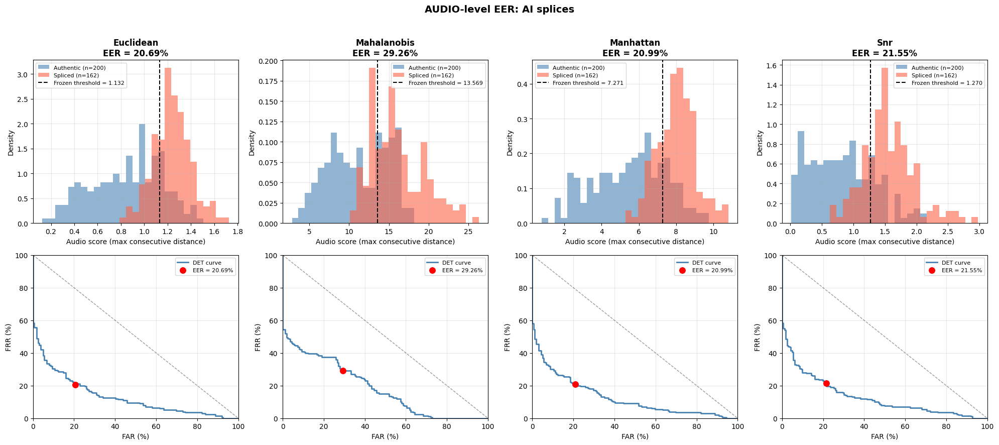

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_level_eer_ai_splices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


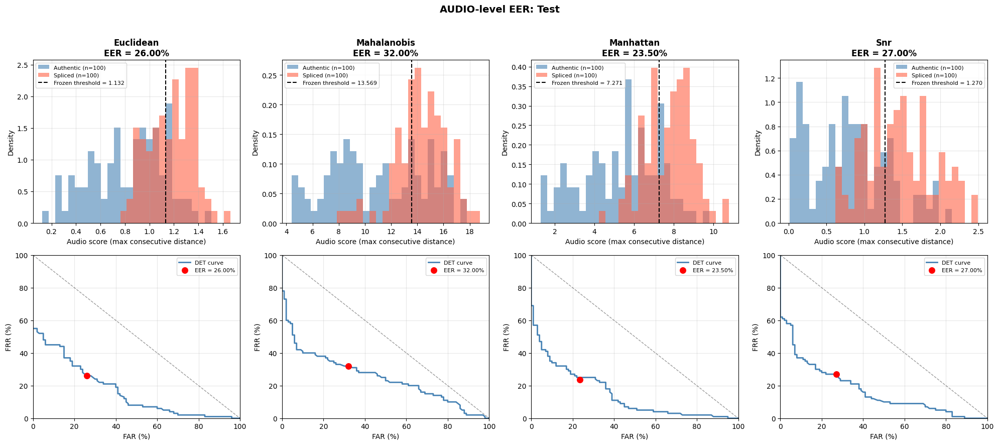

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_level_eer_test_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


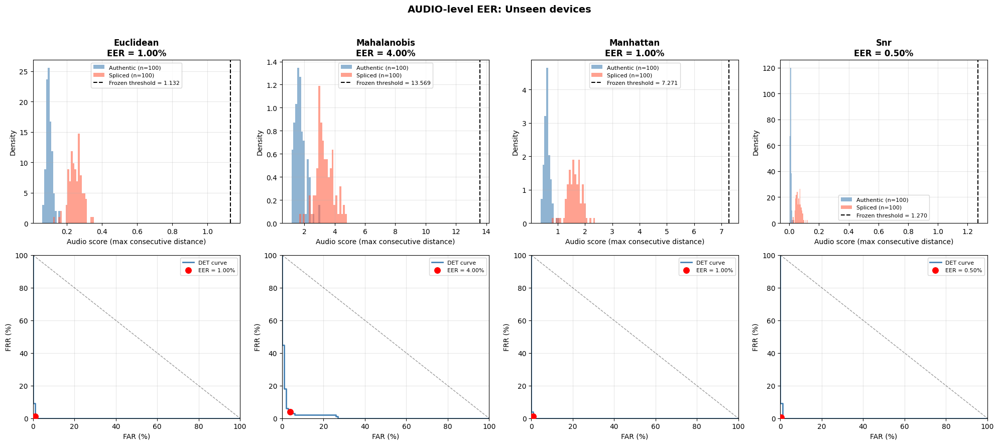

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_level_eer_unseen_devices_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
# Standalone cell: AUDIO-level EER plots (score histogram + DET curve) for the 4 metrics,
# on AI splices, Test and Unseen devices. Reads only pickles saved on Drive.

import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"
METRICS = ["euclidean", "mahalanobis", "manhattan", "snr"]
DPI = 400


def tag(metric):
    return "" if metric == "euclidean" else f"{metric}_"


# set name -> (file name builder, key holding the audio-level EER population)
SETS = {
    "AI splices": (lambda m: f"ia_splicing_detail_{tag(m)}{eval_run_name}.pkl", "audio_eer"),
    "Test": (lambda m: f"eer_detail_{eval_run_name}.pkl" if m == "euclidean"
             else f"eer_detail_final_test_{m}_{eval_run_name}.pkl", "audio"),
    "Unseen devices": (lambda m: f"eer_detail_unseen_devices_{tag(m)}{eval_run_name}.pkl", "audio"),
}


def det_points(scores, labels):
    """FAR (impostor accepted) vs FRR (genuine rejected); label 1 = authentic, 0 = spliced."""
    fpr, tpr, _ = roc_curve(labels, -scores, pos_label=1)
    return fpr * 100, (1 - tpr) * 100


for set_name, (name_fn, key) in SETS.items():
    fig, axes = plt.subplots(2, len(METRICS), figsize=(5 * len(METRICS), 9))
    for col, metric in enumerate(METRICS):
        path = os.path.join(output_path, name_fn(metric))
        if not os.path.exists(path):
            print(f"NOT FOUND: {path}")
            axes[0, col].axis("off"); axes[1, col].axis("off")
            continue
        with open(path, "rb") as f:
            res = pickle.load(f)[key]
        scores = np.asarray(res["scores"], dtype=np.float64)
        labels = np.asarray(res["labels"])
        finite = np.isfinite(scores)
        scores, labels = scores[finite], labels[finite]
        thr = res["optimal_threshold"]
        n_auth, n_spl = int((labels == 1).sum()), int((labels == 0).sum())

        ax = axes[0, col]
        bins = np.linspace(scores.min(), scores.max(), 30)
        ax.hist(scores[labels == 1], bins=bins, alpha=0.6, color="steelblue", density=True,
                label=f"Authentic (n={n_auth})")
        ax.hist(scores[labels == 0], bins=bins, alpha=0.6, color="tomato", density=True,
                label=f"Spliced (n={n_spl})")
        ax.axvline(thr, color="black", linestyle="--", label=f"Frozen threshold = {thr:.3f}")
        ax.set_title(f"{metric.capitalize()}\nEER = {res['eer']:.2%}", fontweight="bold")
        ax.set_xlabel("Audio score (max consecutive distance)")
        ax.set_ylabel("Density")
        ax.legend(fontsize=8); ax.grid(alpha=0.3)

        ax = axes[1, col]
        far, frr = det_points(scores, labels)
        ax.plot(far, frr, color="steelblue", linewidth=2, label="DET curve")
        ax.plot([0, 100], [100, 0], "k--", alpha=0.4, linewidth=1)
        ax.scatter([res["eer"] * 100], [res["eer"] * 100], color="red", s=70, zorder=5,
                   label=f"EER = {res['eer']:.2%}")
        ax.set_xlabel("FAR (%)"); ax.set_ylabel("FRR (%)")
        ax.set_xlim(0, 100); ax.set_ylim(0, 100)
        ax.legend(fontsize=8); ax.grid(alpha=0.3)

    fig.suptitle(f"AUDIO-level EER: {set_name}", fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = os.path.join(output_path, f"audio_level_eer_{set_name.replace(' ', '_').lower()}_{eval_run_name}.png")
    plt.savefig(out, dpi=DPI, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")

In [ ]:
import numpy as np, pickle, os
with open(os.path.join(output_path, "ia_splicing_dataset.pkl"), "rb") as f:
    ia = pickle.load(f)
with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    test = pickle.load(f)["test_audios"]
dur = lambda pool: np.array([len(a["audio"]) / a["sr"] for a in pool])
for name, pool in [("IA splices", ia), ("Test (genuine pool)", test)]:
    d = dur(pool)
    print(f"{name}: n={len(d)} | min/median/max = {d.min():.1f} / {np.median(d):.1f} / {d.max():.1f} s")

IA splices: n=162 | min/median/max = 69.8 / 81.7 / 95.9 s
Test (genuine pool): n=200 | min/median/max = 65.7 / 77.6 / 88.1 s


In [ ]:
import os, sys, pickle, csv
import numpy as np
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import calculate_eer, calculate_far_frr_at_threshold

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

DISTANCE_METRICS = ["euclidean", "mahalanobis", "manhattan", "snr"]
DETECTION_LEVELS = ("audio", "window")


def metric_tag(metric):
    return "" if metric == "euclidean" else f"{metric}_"


# evaluation set -> (pickle-name builder, key of the audio-level population)
EVALUATION_SETS = {
    "Test": (
        lambda m: f"eer_detail_{eval_run_name}.pkl" if m == "euclidean"
        else f"eer_detail_final_test_{m}_{eval_run_name}.pkl",
        "audio",
    ),
    "Unseen devices": (
        lambda m: f"eer_detail_unseen_devices_{metric_tag(m)}{eval_run_name}.pkl",
        "audio",
    ),
    "AI splices": (
        lambda m: f"ia_splicing_detail_{metric_tag(m)}{eval_run_name}.pkl",
        "audio_eer",
    ),
}

records = []
for set_name, (file_name_fn, audio_key) in EVALUATION_SETS.items():
    for metric in DISTANCE_METRICS:
        file_path = os.path.join(output_path, file_name_fn(metric))
        if not os.path.exists(file_path):
            print(f"NOT FOUND: {file_path}")
            continue
        with open(file_path, "rb") as f:
            detail = pickle.load(f)

        for level in DETECTION_LEVELS:
            result = detail[audio_key if level == "audio" else "window"]
            scores = np.asarray(result["scores"], dtype=np.float64)
            labels = np.asarray(result["labels"])
            finite = np.isfinite(scores)              # SNR can return inf
            scores, labels = scores[finite], labels[finite]

            frozen_threshold = float(result["optimal_threshold"])
            eer_sc, self_calibrated_threshold = calculate_eer(scores, labels)
            far_frozen, frr_frozen = calculate_far_frr_at_threshold(scores, labels, frozen_threshold)
            far_sc, frr_sc = calculate_far_frr_at_threshold(scores, labels, self_calibrated_threshold)

            # Error rate at the frozen operating point: (FAR + FRR) / 2 (HTER)
            eer_frozen = (far_frozen + frr_frozen) / 2.0

            records.append(dict(
                set=set_name, metric=metric, level=level,
                n_genuine=int((labels == 1).sum()), n_impostor=int((labels == 0).sum()),
                thr_frozen=frozen_threshold, far_frozen=far_frozen, frr_frozen=frr_frozen,
                thr_self=float(self_calibrated_threshold), far_self=far_sc, frr_self=frr_sc,
                eer_frozen=float(eer_frozen), eer_self=float(eer_sc),
            ))

header = (f"{'Set':<16}{'Metric':<13}{'Level':<8}{'Thr(F)':>9}{'FAR(F)':>9}{'FRR(F)':>9}"
          f"{'Thr(SC)':>10}{'FAR(SC)':>10}{'FRR(SC)':>10}{'EER(F)':>9}{'EER(SC)':>9}")
print("\nFAR / FRR / EER at the frozen (F) vs. self-calibrated (SC) threshold\n")
print(header)
print("-" * len(header))
previous_set = None
for r in records:
    if previous_set is not None and r["set"] != previous_set:
        print()
    previous_set = r["set"]
    print(f"{r['set']:<16}{r['metric']:<13}{r['level']:<8}{r['thr_frozen']:>9.4f}"
          f"{r['far_frozen']:>9.2%}{r['frr_frozen']:>9.2%}{r['thr_self']:>10.4f}"
          f"{r['far_self']:>10.2%}{r['frr_self']:>10.2%}"
          f"{r['eer_frozen']:>9.2%}{r['eer_self']:>9.2%}")

csv_path = os.path.join(output_path, f"self_calibrated_far_frr_{eval_run_name}.csv")
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(records[0].keys()))
    writer.writeheader()
    writer.writerows(records)
print(f"\nCSV saved to {csv_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

FAR / FRR / EER at the frozen (F) vs. self-calibrated (SC) threshold

Set             Metric       Level      Thr(F)   FAR(F)   FRR(F)   Thr(SC)   FAR(SC)   FRR(SC)   EER(F)  EER(SC)
----------------------------------------------------------------------------------------------------------------
Test            euclidean    audio      1.1323   41.00%   18.00%    1.0523    26.00%    26.00%   29.50%   26.00%
Test            euclidean    window     0.4264   20.49%   18.56%    0.4170    19.44%    19.44%   19.52%   19.44%
Test            mahalanobis  audio     13.5693   31.00%   32.00%   13.5855    32.00%    32.00%   31.50%   32.00%
Test            mahalanobis  window     6.7688   23.23%   18.68%    6.4741    20.77%    20.77%   20.95%   20.77%
Test            manhattan    audio      7.2711   36.00%   19.00%    6.8697    22.00%    25.00%   27.50%   23.50%
Test     

In [ ]:
# Standalone cell: inference-time measurement (model + full pipeline).
# Needs only the saved weights and raw_split.pkl from Drive.

import os, time, pickle, platform
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import librosa
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"

SR, N_FFT, HOP_LENGTH_FFT = 44100, 2048, 2048
WIN_SEC, HOP_SEC = 1.0, 0.25
OUT_DIM, N_AUDIOS, N_WARMUP, SEED = 64, 30, 3, 42

# ── Architecture (must match the training notebook exactly) ──
class Backbone(nn.Sequential):
    def __init__(self, dropout_conv=0.1):
        super().__init__(
            nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(dropout_conv),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(dropout_conv),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Dropout2d(dropout_conv),
        )

class Neck(nn.Sequential):
    def __init__(self, out_dim, dropout_fc=0.1):
        super().__init__(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 1024), nn.ReLU(), nn.Dropout(dropout_fc),
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(dropout_fc),
            nn.Linear(256, out_dim),
        )

class EmbeddingNet(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.backbone, self.neck = Backbone(), Neck(out_dim)
    def forward(self, x, valid_input_time_lengths=None):
        return F.normalize(self.neck(self.backbone(x)), p=2, dim=1)

def stft_feature(window):
    """Same extraction + per-window normalization used in the pipeline."""
    power = np.abs(librosa.stft(window, n_fft=N_FFT, hop_length=HOP_LENGTH_FFT, window='hann')) ** 2
    db = (10 * np.log10(power + 1e-10)).astype(np.float32)
    return (db - db.mean()) / (db.std() + 1e-8)

def analyze_audio(audio, model, device):
    """Full pipeline for one audio: windows -> STFT -> embeddings -> consecutive distances.
    Returns the elapsed time of each stage in seconds."""
    win_len, hop_len = int(WIN_SEC * SR), int(HOP_SEC * SR)

    t0 = time.perf_counter()
    feats = [stft_feature(audio[s:s + win_len]) for s in range(0, len(audio) - win_len, hop_len)]
    specs = torch.tensor(np.array(feats), dtype=torch.float32).unsqueeze(1).to(device)
    t1 = time.perf_counter()

    with torch.no_grad():
        embs = model(specs)
        if device.type == "cuda":
            torch.cuda.synchronize()
    embs = embs.cpu().numpy()
    t2 = time.perf_counter()

    dists = np.linalg.norm(embs[1:] - embs[:-1], axis=1)
    _ = float(dists.max())
    t3 = time.perf_counter()
    return t1 - t0, t2 - t1, t3 - t2, len(feats)

# ── Load weights and audios ──
checkpoint = torch.load(os.path.join(output_path, f"siamese_model_{run_name}.pth"), map_location="cpu")
with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    test_audios = pickle.load(f)["test_audios"]

rng = np.random.default_rng(SEED)
sample = [test_audios[i] for i in rng.choice(len(test_audios), size=min(N_AUDIOS, len(test_audios)), replace=False)]
del test_audios

print(f"CPU: {platform.processor() or platform.machine()} | torch threads: {torch.get_num_threads()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

devices_to_test = [torch.device("cpu")] + ([torch.device("cuda")] if torch.cuda.is_available() else [])

for dev in devices_to_test:
    model = EmbeddingNet(OUT_DIM)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(dev).eval()

    for item in sample[:N_WARMUP]:                    # warm-up (not timed)
        analyze_audio(item['audio'], model, dev)

    t_feat, t_model, t_dist, n_win, durations = [], [], [], [], []
    for item in sample:
        a, b, c, n = analyze_audio(item['audio'], model, dev)
        t_feat.append(a); t_model.append(b); t_dist.append(c); n_win.append(n)
        durations.append(len(item['audio']) / item['sr'])

    t_feat, t_model, t_dist = map(np.array, (t_feat, t_model, t_dist))
    total = t_feat + t_model + t_dist
    n_win, durations = np.array(n_win), np.array(durations)

    print(f"\n=== {dev.type.upper()} | {len(sample)} audios | {n_win.sum()} windows ===")
    print(f"Audio duration (s):        mean {durations.mean():.1f} (min {durations.min():.1f}, max {durations.max():.1f})")
    print(f"STFT + normalization (s):  {t_feat.mean():.3f} ± {t_feat.std():.3f}   ({1000*t_feat.sum()/n_win.sum():.2f} ms/window)")
    print(f"Model forward (s):         {t_model.mean():.3f} ± {t_model.std():.3f}   ({1000*t_model.sum()/n_win.sum():.2f} ms/window)")
    print(f"Distances (s):             {t_dist.mean():.5f} ± {t_dist.std():.5f}")
    print(f"TOTAL per audio (s):       {total.mean():.3f} ± {total.std():.3f}")
    print(f"Real-time factor (total/duration): {(total / durations).mean():.3f}")


Mounted at /content/drive
CPU: x86_64 | torch threads: 4
GPU: Tesla T4

=== CPU | 30 audios | 8900 windows ===
Audio duration (s):        mean 75.1 (min 65.7, max 88.1)
STFT + normalization (s):  0.353 ± 0.036   (1.19 ms/window)
Model forward (s):         5.330 ± 0.596   (17.97 ms/window)
Distances (s):             0.00013 ± 0.00002
TOTAL per audio (s):       5.683 ± 0.627
Real-time factor (total/duration): 0.076

=== CUDA | 30 audios | 8900 windows ===
Audio duration (s):        mean 75.1 (min 65.7, max 88.1)
STFT + normalization (s):  0.352 ± 0.037   (1.19 ms/window)
Model forward (s):         0.195 ± 0.018   (0.66 ms/window)
Distances (s):             0.00012 ± 0.00002
TOTAL per audio (s):       0.548 ± 0.055
Real-time factor (total/duration): 0.007


In [ ]:
!lscpu | grep "Model name"

Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
History loaded from /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/final_model_history_euclidean_uv_epochs840_val15_win1_cosface_outdim64.pkl
History keys: ['valid_loss', 'train_loss', 'lr']


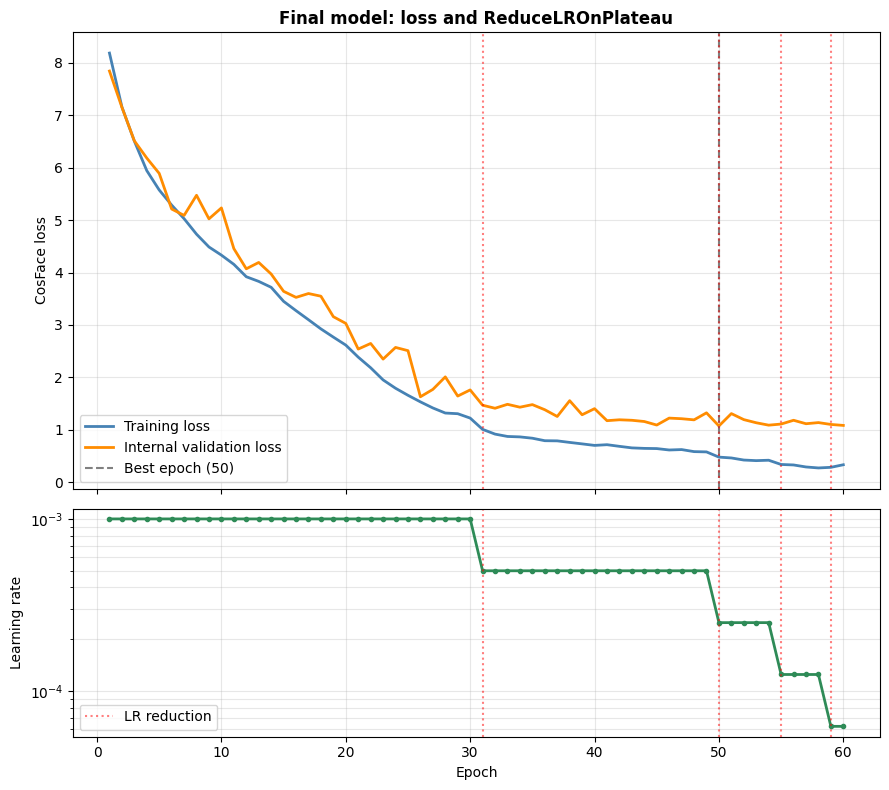

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/final_model_loss_lr_euclidean_uv_epochs840_val15_win1_cosface_outdim64.png
Epochs trained:        60 (max 60) | early stopping triggered: False
Best epoch:            50 | valid_loss = 1.0739 | train_loss = 0.4797
Last epoch:            train = 0.3340 | valid = 1.0843
Learning rate:         1.0e-03 -> 6.3e-05 | reductions: 4 (epochs [31, 50, 55, 59])


In [ ]:
# =============================================================================
# STANDALONE CELL: final-model loss curves + ReduceLROnPlateau history
# Reads only the history saved on Drive (no model, no windows, low RAM).
# =============================================================================
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
FIGURE_DPI = 400

history_path = os.path.join(output_path, f"final_model_history_{run_name}.pkl")
checkpoint_path = os.path.join(output_path, f"final_checkpoint_{run_name}.pt")

# Load history (fallback to the training checkpoint if the .pkl is missing)
if os.path.exists(history_path):
    with open(history_path, "rb") as f:
        history = pickle.load(f)
    print(f"History loaded from {history_path}")
elif os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    history = checkpoint['history']
    print(f"History recovered from checkpoint (last saved epoch: {checkpoint['epoch'] + 1})")
else:
    raise FileNotFoundError("Neither the history .pkl nor the final checkpoint were found.")

print("History keys:", list(history.keys()))

train_loss = np.asarray(history['train_loss'])
valid_loss = np.asarray(history['valid_loss'])
lr_history = np.asarray(history['lr'])
n_epochs = len(train_loss)
epochs = np.arange(1, n_epochs + 1)
best_epoch = int(np.argmin(valid_loss)) + 1
lr_change_epochs = [i + 1 for i in range(1, n_epochs) if lr_history[i] != lr_history[i - 1]]

#  Figure: loss + learning rate
fig, (ax_loss, ax_lr) = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                                     gridspec_kw={'height_ratios': [2, 1]})

ax_loss.plot(epochs, train_loss, color='steelblue', linewidth=2, label='Training loss')
ax_loss.plot(epochs, valid_loss, color='darkorange', linewidth=2, label='Internal validation loss')
ax_loss.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
ax_loss.set_ylabel('CosFace loss')
ax_loss.set_title('Final model: loss and ReduceLROnPlateau', fontweight='bold')
ax_loss.legend()
ax_loss.grid(alpha=0.3)

ax_lr.plot(epochs, lr_history, color='seagreen', linewidth=2, marker='o', markersize=3)
for k, e in enumerate(lr_change_epochs):
    ax_loss.axvline(e, color='red', linestyle=':', alpha=0.5)
    ax_lr.axvline(e, color='red', linestyle=':', alpha=0.5,
                  label='LR reduction' if k == 0 else None)
ax_lr.set_yscale('log')
ax_lr.set_xlabel('Epoch')
ax_lr.set_ylabel('Learning rate')
if lr_change_epochs:
    ax_lr.legend()
ax_lr.grid(alpha=0.3, which='both')

plt.tight_layout()
out_png = os.path.join(output_path, f"final_model_loss_lr_{run_name}.png")
plt.savefig(out_png, dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
print(f"Saved: {out_png}")

print(f"Epochs trained:        {n_epochs} (max 60) | early stopping triggered: {n_epochs < 60}")
print(f"Best epoch:            {best_epoch} | valid_loss = {valid_loss[best_epoch - 1]:.4f} "
      f"| train_loss = {train_loss[best_epoch - 1]:.4f}")
print(f"Last epoch:            train = {train_loss[-1]:.4f} | valid = {valid_loss[-1]:.4f}")
print(f"Learning rate:         {lr_history[0]:.1e} -> {lr_history[-1]:.1e} "
      f"| reductions: {len(lr_change_epochs)} (epochs {lr_change_epochs})")


=== AUDIO-LEVEL SCORE STRATEGIES — EUCLIDEAN ===

[euclidean] Frozen-threshold stability (calibration pool)
   Baseline (raw max distance): 1.0883  [1.0511, 1.1417] (95% CI, n=200)
   Median-filtered max distance: 0.8735  [0.8155, 0.9098] (95% CI, n=200)
   Median-filtered + entropy-weighted max score: 0.3953  [0.3641, 0.4061] (95% CI, n=200)

[euclidean | unseen_devices] authentic=100 | spliced=100
   Baseline (raw max distance) (thr=1.0883)
      EER  1.0000%  [0.0000%, 2.0000%] (95% CI, n=200)
      FAR  100.0000%  [100.0000%, 100.0000%] (95% CI, n=200)
      FRR  0.0000%  [0.0000%, 0.0000%] (95% CI, n=200)
   Median-filtered max distance (thr=0.8735)
      EER  7.5000%  [2.5000%, 10.5000%] (95% CI, n=200)
      FAR  100.0000%  [100.0000%, 100.0000%] (95% CI, n=200)
      FRR  0.0000%  [0.0000%, 0.0000%] (95% CI, n=200)
   Median-filtered + entropy-weighted max score (thr=0.3953)
      EER  5.0000%  [3.0000%, 10.0125%] (95% CI, n=200)
      FAR  100.0000%  [100.0000%, 100.0000%] (9

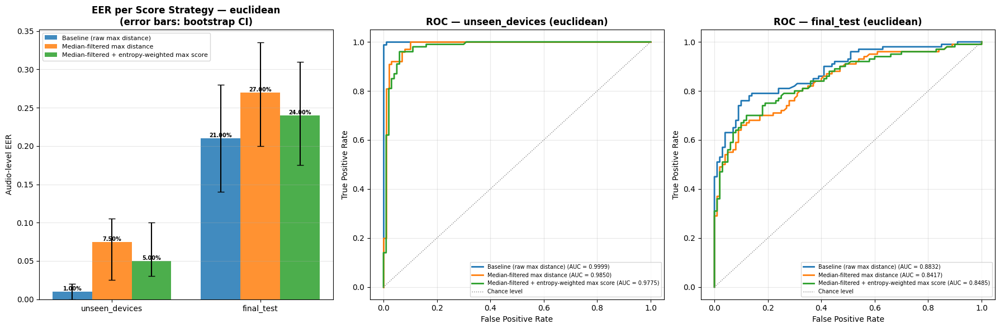

Strategy EER/ROC comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_euclidean_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


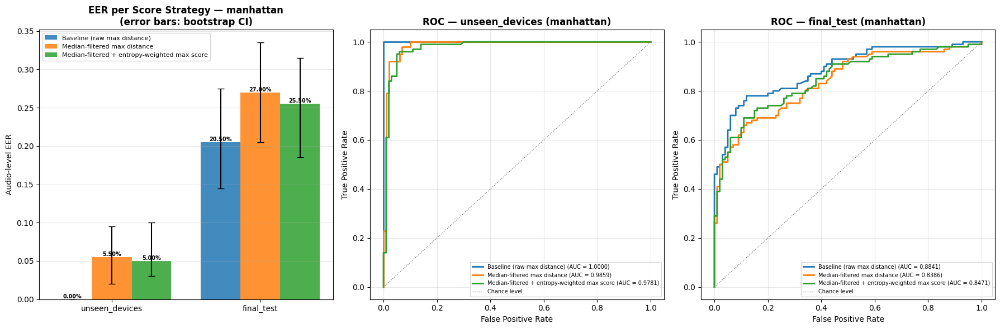

Strategy EER/ROC comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_manhattan_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


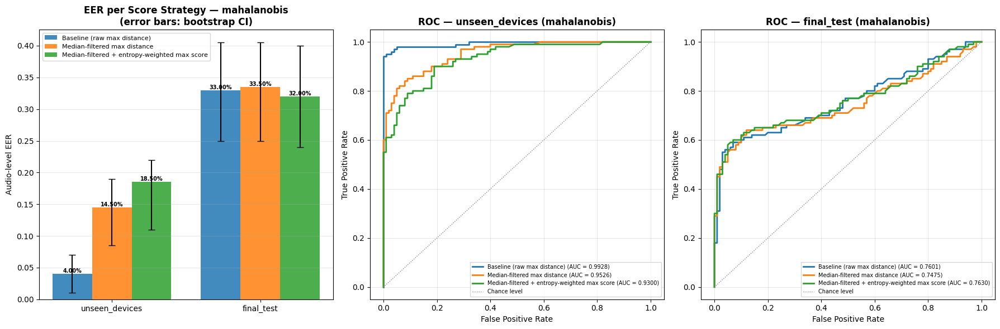

Strategy EER/ROC comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_mahalanobis_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


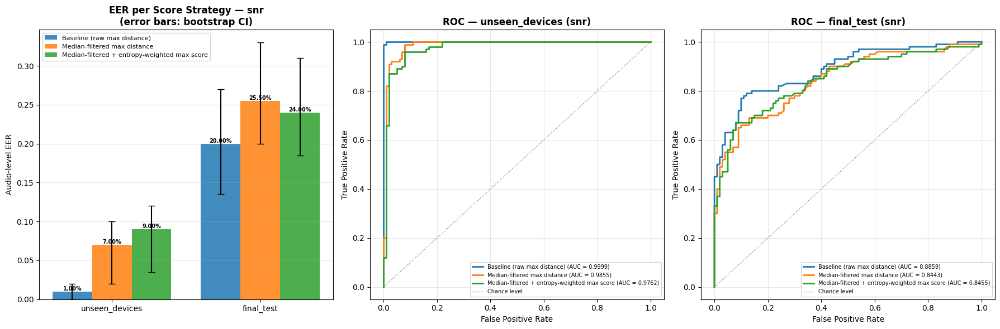

Strategy EER/ROC comparison saved to /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_snr_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


{'euclidean': '/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_euclidean_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png',
 'manhattan': '/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_manhattan_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png',
 'mahalanobis': '/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_mahalanobis_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png',
 'snr': '/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/audio_score_strategy_eer_snr_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png'}

In [ ]:
###########################################
"""Audio-Level Score Strategies — 4 metrics (standalone, reloads everything from disk)"""
###########################################

# 1) Data: only val, test and unseen devices (train audios are discarded to save RAM)
with open(raw_split_path, "rb") as f:
    _split = pickle.load(f)
val_audios  = _split["val_audios"]
test_audios = _split["test_audios"]
del _split; gc.collect()

with open(unseen_devices_dataset_path, "rb") as f:
    unseen_devices_dataset = pickle.load(f)

# 2) Trained model
checkpoint = torch.load(save_path, map_location="cpu")   # siamese_model_{run_name}.pth
model = EmbeddingNet(out_dim=OUT_DIM, dropout_conv=DROPOUT_CONV, dropout_fc=DROPOUT_FC)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

# 3) Mahalanobis inverse covariance (estimated earlier on train embeddings only)
with open(mahalanobis_vi_path, "rb") as f:
    mahalanobis_vi = pickle.load(f)

# 4) Run all four metrics
FOUR_METRICS = ("euclidean", "manhattan", "mahalanobis", "snr")
score_strategy_evaluation_pools = {"unseen_devices": unseen_devices_dataset,
                                   "final_test":     test_audios}
vi_by_metric = {"mahalanobis": mahalanobis_vi}

strategy_eer_results_4m = {}
for metric_name in FOUR_METRICS:
    print(f"\n=== AUDIO-LEVEL SCORE STRATEGIES — {metric_name.upper()} ===")
    strategy_eer_results_4m[metric_name] = evaluate_audio_score_strategies(
        calibration_pool=val_audios,
        evaluation_pools=score_strategy_evaluation_pools,
        model=model, device=device, n_audios=N_AUDIOS_TEST_EER,
        sr=SR, win_sec=WIN_LENGTH_SEC, hop_sec=HOP_LENGTH_SEC_EVAL,
        n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT, top_db=TOP_DB,
        median_filter_kernel_size=WINDOW_LEVEL_MEDIAN_FILTER_KERNEL_SIZE,
        entropy_window=ENTROPY_LOCAL_WINDOW,
        distance_metric=metric_name, VI=vi_by_metric.get(metric_name),
    )

# 5) Save with new names
pkl_4m = os.path.join(output_path, f"audio_score_strategy_eer_4metrics_{eval_run_name}.pkl")
with open(pkl_4m, "wb") as f:
    pickle.dump(strategy_eer_results_4m, f, protocol=pickle.HIGHEST_PROTOCOL)

summary_4m = build_strategy_eer_summary_table(strategy_eer_results_4m)
print(summary_4m.to_string(index=False))
summary_4m.to_csv(os.path.join(output_path, f"audio_score_strategy_eer_summary_4metrics_{eval_run_name}.csv"),
                  index=False)

plot_strategy_eer_comparison(
    strategy_eer_results_4m,
    path_template=os.path.join(output_path,
        "audio_score_strategy_eer_{distance_metric}_4metrics_" + eval_run_name + ".png"),
)

In [ ]:
# Standalone cell: audio-level detection table with 95% bootstrap CIs for
# FAR, FRR, mean error and self-calibrated EER (all evaluation sets, including
# clean-only and noise-only). Reads only the pickles saved on Drive.

import os, sys, pickle
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import calculate_eer, calculate_far_frr_at_threshold

# ── Configuration (must match the original run) ──────────────────────────────
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

N_RESAMPLES = 1000
CONFIDENCE = 0.95
SEED = 42
DECIMALS = 2


# ── Helpers ──────────────────────────────────────────────────────────────────
def load_pickle(file_name):
    path = os.path.join(output_path, file_name)
    if not os.path.exists(path):
        print(f"NOT FOUND: {path}")
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def bootstrap_detection_table_row(scores, labels, frozen_threshold,
                                  n_resamples=N_RESAMPLES, confidence=CONFIDENCE, seed=SEED):
    """
    Stratified percentile bootstrap (resampling audios within each class).
    FAR / FRR / mean error use the FROZEN threshold (never re-estimated);
    EER is re-estimated per replicate (it defines its own threshold).
    Label convention: 1 = authentic, 0 = spliced.
    Returns {metric: (estimate, ci_low, ci_high)} in percent.
    """
    rng = np.random.default_rng(seed)
    strata = [np.flatnonzero(labels == c) for c in np.unique(labels)]

    def _metrics(s, l):
        far, frr = calculate_far_frr_at_threshold(s, l, frozen_threshold)
        return {"far": far, "frr": frr, "mean_err": (far + frr) / 2,
                "eer": calculate_eer(s, l)[0]}

    point = _metrics(scores, labels)
    replicates = {k: np.empty(n_resamples) for k in point}
    for i in range(n_resamples):
        idx = np.concatenate([rng.choice(s, size=len(s), replace=True) for s in strata])
        for k, v in _metrics(scores[idx], labels[idx]).items():
            replicates[k][i] = v

    tail = (1 - confidence) / 2
    out = {}
    for k in point:
        lo, hi = np.nanpercentile(replicates[k], [100 * tail, 100 * (1 - tail)])
        out[k] = (100 * point[k], 100 * lo, 100 * hi)
    return out


def summarize_audio_level(result):
    scores = np.asarray(result["scores"], dtype=np.float64)
    labels = np.asarray(result["labels"])
    finite = np.isfinite(scores)
    scores, labels = scores[finite], labels[finite]
    tau = float(result["optimal_threshold"])
    return {
        "n_auth": int((labels == 1).sum()),
        "n_spliced": int((labels == 0).sum()),
        "tau": tau,
        "ci": bootstrap_detection_table_row(scores, labels, tau),
    }


def fmt(triple, d=DECIMALS):
    est, lo, hi = triple
    return f"{est:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"


# ── Load each evaluation set ─────────────────────────────────────────────────
experiment = load_pickle(f"experiment_{eval_run_name}.pkl")
test_detail = load_pickle(f"eer_detail_{eval_run_name}.pkl")
unseen_detail = load_pickle(f"eer_detail_unseen_devices_{eval_run_name}.pkl")
ia_detail = load_pickle(f"ia_splicing_detail_{eval_run_name}.pkl")

audio_level_sources = {
    "Test (seen devices)": test_detail["audio"] if test_detail else None,
    "Test, clean only": experiment["clean_results"]["audio"] if experiment else None,
    "Test, noise only": experiment["noise_results"]["audio"] if experiment else None,
    "Unseen devices": unseen_detail["audio"] if unseen_detail else None,
    "AI splices": ia_detail["audio_eer"] if ia_detail else None,
}

# ── Build the table ──────────────────────────────────────────────────────────
columns = ["Set", "Auth./Spliced", "τ_audio", "FAR (%) [95% CI]", "FRR (%) [95% CI]",
           "Mean error (%) [95% CI]", "Self-cal. EER (%) [95% CI]"]
rows = []
for set_name, result in audio_level_sources.items():
    if result is None:
        rows.append({c: ("n/a" if c != "Set" else set_name) for c in columns})
        continue
    s = summarize_audio_level(result)
    rows.append({
        "Set": set_name,
        "Auth./Spliced": f"{s['n_auth']}/{s['n_spliced']}",
        "τ_audio": f"{s['tau']:.4f}",
        "FAR (%) [95% CI]": fmt(s["ci"]["far"]),
        "FRR (%) [95% CI]": fmt(s["ci"]["frr"]),
        "Mean error (%) [95% CI]": fmt(s["ci"]["mean_err"]),
        "Self-cal. EER (%) [95% CI]": fmt(s["ci"]["eer"]),
    })

table = pd.DataFrame(rows, columns=columns)

# ── Display and export ───────────────────────────────────────────────────────
print("\nTable. Audio-level detection performance at the frozen threshold "
      f"(Euclidean distance, {int(CONFIDENCE*100)}% stratified bootstrap CIs, "
      f"{N_RESAMPLES} resamples)\n")
print(table.to_string(index=False))

csv_path = os.path.join(output_path, f"audio_level_report_table_bootstrap_{eval_run_name}.csv")
table.to_csv(csv_path, index=False, encoding="utf-8")
print(f"\nCSV saved to {csv_path}")

tex_path = os.path.join(output_path, f"audio_level_report_table_bootstrap_{eval_run_name}.tex")
with open(tex_path, "w", encoding="utf-8") as f:
    f.write(table.to_latex(index=False, escape=True,
                           column_format="l" + "c" * (len(columns) - 1)))
print(f"LaTeX saved to {tex_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Table. Audio-level detection performance at the frozen threshold (Euclidean distance, 95% stratified bootstrap CIs, 1000 resamples)

                Set Auth./Spliced τ_audio        FAR (%) [95% CI]     FRR (%) [95% CI] Mean error (%) [95% CI] Self-cal. EER (%) [95% CI]
Test (seen devices)       100/100  1.1323    41.00 [32.00, 50.00] 18.00 [11.00, 26.00]    29.50 [23.50, 35.01]       26.00 [20.50, 32.50]
   Test, clean only       100/100  1.1323    36.00 [27.00, 46.00] 25.00 [17.00, 33.02]    30.50 [24.00, 36.51]       30.00 [24.00, 37.50]
   Test, noise only       100/100  1.1323    46.00 [36.00, 55.00]  11.00 [5.00, 17.00]    28.50 [22.50, 33.50]       21.00 [16.00, 27.50]
     Unseen devices       100/100  1.1323 100.00 [100.00, 100.00]    0.00 [0.00, 0.00]    50.00 [50.00, 50.00]          1.00 [0.00, 3.50]
         AI splices       200/162  1.1323    25

In [ ]:

# STANDALONE CELL: Table 3.4 — Window-level detection (Euclidean, frozen threshold)
# Reads only the pickles saved on Drive. No model, datasets or notebook state needed.
# Columns: genuine/impostor pairs, tau_window, FAR, FRR, full EER, balanced EER.

import os, pickle
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

N_REPEATS = 1000      # balanced-subsampling repetitions
SEED = 42
DECIMALS = 4


# Helpers
def load_pickle(file_name):
    """Loads a pickle from output_path; returns None (with a message) if missing."""
    path = os.path.join(output_path, file_name)
    if not os.path.exists(path):
        print(f"NOT FOUND: {path}")
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def eer_from_scores(scores, labels):
    """EER with the project's convention: label 1 = genuine, 0 = impostor,
    higher score = more 'spliced' (scores inverted, as in calculate_eer)."""
    fpr, tpr, _ = roc_curve(labels, -scores, pos_label=1)
    fnr = 1.0 - tpr
    idx = np.argmin(np.abs(fpr - fnr))
    return float((fpr[idx] + fnr[idx]) / 2.0)


def far_frr(scores, labels, threshold):
    """FAR: impostors NOT flagged. FRR: genuine wrongly flagged (flag = score > threshold)."""
    flagged = scores > threshold
    return float((~flagged[labels == 0]).mean()), float(flagged[labels == 1].mean())


def window_summary(window_result, n_repeats=N_REPEATS, seed=SEED):
    """Full-set FAR/FRR/EER at the frozen threshold, plus balanced EER
    (all impostors + an equal number of genuine pairs drawn without replacement)."""
    scores = np.asarray(window_result["scores"], dtype=np.float64)
    labels = np.asarray(window_result["labels"])
    threshold = float(window_result["optimal_threshold"])

    finite = np.isfinite(scores)                     # SNR-type scores can be inf
    if not finite.all():
        print(f"   dropping {(~finite).sum()} non-finite scores")
        scores, labels = scores[finite], labels[finite]

    genuine_idx = np.flatnonzero(labels == 1)
    impostor_idx = np.flatnonzero(labels == 0)
    far, frr = far_frr(scores, labels, threshold)

    rng = np.random.default_rng(seed)
    balanced_eers = np.empty(n_repeats)
    for i in range(n_repeats):
        idx = np.concatenate([rng.choice(genuine_idx, size=len(impostor_idx), replace=False),
                              impostor_idx])
        balanced_eers[i] = eer_from_scores(scores[idx], labels[idx])

    return {
        "n_genuine": len(genuine_idx), "n_impostor": len(impostor_idx), "tau": threshold,
        "far": far, "frr": frr, "eer_full": eer_from_scores(scores, labels),
        "eer_bal_mean": balanced_eers.mean(), "eer_bal_std": balanced_eers.std(),
    }


def pct(x, d=DECIMALS):
    return f"{100 * x:.{d}f}"


# Load each evaluation set (Euclidean, window level)
METRICS = ["euclidean", "mahalanobis", "manhattan", "snr"]
METRIC_LABELS = {"euclidean": "Euclidiana", "mahalanobis": "Mahalanobis",
                 "manhattan": "Manhattan", "snr": "SNR"}

def metric_tag(m):
    return "" if m == "euclidean" else f"{m}_"

def window_result_for(set_name, metric):
    """Window-level result dict for (set, metric), following the names used when saving."""
    if set_name == "Test":
        name = (f"eer_detail_{eval_run_name}.pkl" if metric == "euclidean"
                else f"eer_detail_final_test_{metric}_{eval_run_name}.pkl")
    elif set_name == "Unseen devices":
        name = f"eer_detail_unseen_devices_{metric_tag(metric)}{eval_run_name}.pkl"
    elif set_name == "AI splices":
        name = f"ia_splicing_detail_{metric_tag(metric)}{eval_run_name}.pkl"
    else:
        return None
    detail = load_pickle(name)
    return detail["window"] if detail else None

# Euclidean-only subsets (clean / noise) live in the experiment pickle
experiment = load_pickle(f"experiment_{eval_run_name}.pkl")
euclidean_only = {
    "Test, clean only": experiment["clean_results"]["window"] if experiment else None,
    "Test, noise only": experiment["noise_results"]["window"] if experiment else None,
}

# (set, metric, window_result), in the order you want them in the table
jobs = []
for set_name in ["Test", "Unseen devices", "AI splices"]:
    for metric in METRICS:
        jobs.append((set_name, metric, window_result_for(set_name, metric)))
for set_name, result in euclidean_only.items():
    jobs.append((set_name, "euclidean", result))

# Build the table
columns = ["Set", "Metric", "Genuine pairs", "Impostor pairs", "τ_window", "FAR (%)", "FRR (%)",
           "Full EER (%)", "Balanced EER (%) (mean ± s.d.)"]
rows, raw_records = [], []

for set_name, metric, window_result in jobs:
    if window_result is None or "scores" not in window_result:
        print(f"[{set_name} | {metric}] scores/labels unavailable — skipped.")
        continue
    print(f"[{set_name} | {metric}] computing...")
    s = window_summary(window_result)
    raw_records.append({"set": set_name, "metric": metric, **s})
    rows.append({
        "Set": set_name,
        "Metric": METRIC_LABELS[metric],
        "Genuine pairs": f"{s['n_genuine']:,}",
        "Impostor pairs": f"{s['n_impostor']:,}",
        "τ_window": f"{s['tau']:.4f}",
        "FAR (%)": pct(s["far"], 2),
        "FRR (%)": pct(s["frr"], 2),
        "Full EER (%)": pct(s["eer_full"], 2),
        "Balanced EER (%) (mean ± s.d.)": f"{pct(s['eer_bal_mean'], 2)} ± {pct(s['eer_bal_std'], 2)}",
    })

table = pd.DataFrame(rows, columns=columns)

# Display and export
print(f"\nWindow-level detection, frozen thresholds "
      f"(balanced EER: {N_REPEATS} subsamples, genuine pairs matched to impostor count)\n")
print(table.to_string(index=False))

csv_path = os.path.join(output_path, f"table_window_level_{eval_run_name}.csv")
table.to_csv(csv_path, index=False, encoding="utf-8")
pd.DataFrame(raw_records).to_csv(
    os.path.join(output_path, f"table_window_level_raw_{eval_run_name}.csv"), index=False)
print(f"\nCSV saved to {csv_path}")

# Check that supports the "balanced vs full differ by < 0.25 pp" claim in the Annex
raw = pd.DataFrame(raw_records)
raw["diff_pp"] = (raw["eer_bal_mean"] - raw["eer_full"]).abs() * 100
print(f"\nMax |balanced - full| EER difference: {raw['diff_pp'].max():.4f} pp "
      f"(row: {raw.loc[raw['diff_pp'].idxmax(), ['set', 'metric']].tolist()})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Test | euclidean] computing...
[Test | mahalanobis] computing...
[Test | manhattan] computing...
[Test | snr] computing...
[Unseen devices | euclidean] computing...
[Unseen devices | mahalanobis] computing...
[Unseen devices | manhattan] computing...
[Unseen devices | snr] computing...
[AI splices | euclidean] computing...
[AI splices | mahalanobis] computing...
[AI splices | manhattan] computing...
[AI splices | snr] computing...
[Test, clean only | euclidean] computing...
[Test, noise only | euclidean] computing...

Window-level detection, frozen thresholds (balanced EER: 1000 subsamples, genuine pairs matched to impostor count)

             Set      Metric Genuine pairs Impostor pairs τ_window FAR (%) FRR (%) Full EER (%) Balanced EER (%) (mean ± s.d.)
            Test  Euclidiana       169,640          1,420   0.4264   20.49   18.56        19.44        

In [ ]:
# Standalone cell: generates Tables 3.1-3.5 (rendered tables + CSV) reading only what is saved in Drive.
import os, sys, pickle
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import calculate_eer, calculate_far_frr_at_threshold

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"
METRICS = ["euclidean", "manhattan", "mahalanobis", "snr"]
NAMES = {"euclidean": "Euclidean", "manhattan": "Manhattan", "mahalanobis": "Mahalanobis", "snr": "SNR"}


def show(df):
    """Display a DataFrame as a regular rendered table (no index)."""
    display(df.style.hide(axis="index"))


def tag(m):
    return "" if m == "euclidean" else f"{m}_"


def load(name):
    p = os.path.join(output_path, name)
    if not os.path.exists(p):
        print(f"NOT FOUND: {name}")
        return None
    with open(p, "rb") as f:
        return pickle.load(f)


SETS = {
    "Test": (lambda m: f"eer_detail_{eval_run_name}.pkl" if m == "euclidean"
             else f"eer_detail_final_test_{m}_{eval_run_name}.pkl", "audio"),
    "AI splicing": (lambda m: f"ia_splicing_detail_{tag(m)}{eval_run_name}.pkl", "audio_eer"),
    "Unseen devices": (lambda m: f"eer_detail_unseen_devices_{tag(m)}{eval_run_name}.pkl", "audio"),
}
experiment = load(f"experiment_{eval_run_name}.pkl")  # contains clean/noise/calibration (Euclidean only)


def clean(res):
    s, l = np.asarray(res["scores"], float), np.asarray(res["labels"])
    ok = np.isfinite(s)  # SNR can return inf
    return s[ok], l[ok], float(res["optimal_threshold"])


def row(set_name, metric, level, res):
    s, l, thr = clean(res)
    far_f, frr_f = calculate_far_frr_at_threshold(s, l, thr)
    eer_sc, thr_sc = calculate_eer(s, l)
    far_s, frr_s = calculate_far_frr_at_threshold(s, l, thr_sc)
    return {"Set": set_name, "Metric": NAMES[metric], "level": level,
            "n_gen": int((l == 1).sum()), "n_imp": int((l == 0).sum()),
            "τ frozen": thr, "FAR frozen (%)": 100 * far_f, "FRR frozen (%)": 100 * frr_f,
            "HTER frozen (%)": 50 * (far_f + frr_f),
            "τ self-cal.": thr_sc, "FAR self-cal. (%)": 100 * far_s, "FRR self-cal. (%)": 100 * frr_s,
            "EER self-cal. (%)": 100 * eer_sc}


rows = []
for set_name, (fname, audio_key) in SETS.items():
    for m in METRICS:
        d = load(fname(m))
        if d is None:
            continue
        rows.append(row(set_name, m, "audio", d[audio_key]))
        rows.append(row(set_name, m, "window", d["window"]))
if experiment:  # clean / noise (Euclidean, frozen threshold)
    for label, key in [("Test, clean only", "clean_results"), ("Test, noise only", "noise_results")]:
        if experiment.get(key):
            for level in ("audio", "window"):
                rows.append(row(label, "euclidean", level, experiment[key][level]))
det = pd.DataFrame(rows)
det.to_csv(os.path.join(output_path, f"detection_results_tables_{eval_run_name}.csv"), index=False)

#  frozen thresholds and calibration EER
t31 = []
for m in METRICS:
    d = load(SETS["Test"][0](m))
    thr_a = d["audio"]["optimal_threshold"] if d else np.nan
    thr_w = d["window"]["optimal_threshold"] if d else np.nan
    eer_a = eer_w = np.nan
    if m == "euclidean" and experiment:  # the other 3 calibrations were not saved in a pickle
        eer_a = 100 * experiment["calibration_results"]["audio"]["eer"]
        eer_w = 100 * experiment["calibration_results"]["window"]["eer"]
    t31.append({"Metric": NAMES[m], "τ audio": thr_a, "τ window": thr_w,
                "Audio val. EER (%)": eer_a, "Window val. EER (%)": eer_w})
t31 = pd.DataFrame(t31)
print("\nTable ")
show(t31.round(4))

cols = ["Set", "Metric", "n_gen", "n_imp", "FAR frozen (%)", "FRR frozen (%)", "HTER frozen (%)",
        "FAR self-cal. (%)", "FRR self-cal. (%)", "EER self-cal. (%)"]
for level, num in (("audio", "3.2"), ("window", "3.3")):
    print(f"\nTable {num} — {level} level")
    show(det[det.level == level][cols].round(2))

# Table localization error (mean ± s.d., s), Euclidean
loc_src = {"Test": load(f"eer_detail_{eval_run_name}.pkl"),
           "Unseen": load(f"eer_detail_unseen_devices_{eval_run_name}.pkl"),
           "AI": load(f"ia_splicing_detail_{eval_run_name}.pkl")}
STRAT = {"baseline": "Baseline", "median": "Median", "entropy": "Entropy", "median_entropy": "Median+entropy"}
t34 = []
for k, name in STRAT.items():
    r = {"Strategy": name}
    for src, d in loc_src.items():
        if d is None:
            continue
        a = d["audio"]
        for key, lab in (("localization_error_stats", "all"), ("localization_error_stats_detected", "detected")):
            st = (a.get(key) or {}).get(k)
            r[f"{src}: {lab}"] = f"{st['mean_error_s']:.3f} ± {st['std_error_s']:.3f} (n={st['n_samples']})" if st else "—"
    t34.append(r)
print("\n")
show(pd.DataFrame(t34))

# Table discriminability EER for independent pairs
pair_files = {"Seen devices": ("device_discriminability_eer", eval_run_name),
              "Unseen devices": ("device_discriminability_eer", f"unseen_devices_{eval_run_name}"),
              "Real vs. AI": ("ia_discriminability_eer", eval_run_name)}
t35 = []
for pop, (prefix, rn) in pair_files.items():
    r = {"Population": pop}
    for m in METRICS:
        d = load(f"{prefix}_{m}_{rn}.pkl")
        r[NAMES[m]] = f"{100 * d['eer']:.2f}" if d else "—"
    t35.append(r)
print("\nTable (EER, %)")
show(pd.DataFrame(t35))

#  k-NN accuracy with CI (saved in the bootstrap)
boot = load(f"bootstrap_ci_{eval_run_name}.pkl")
if boot and boot.get("knn_accuracy"):
    ci = boot["knn_accuracy"]
    print(f"\nk-NN test: {100*ci['estimate']:.2f} % [{100*ci['ci_lower']:.2f}, {100*ci['ci_upper']:.2f}]")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Table 


Metric,τ audio,τ window,Audio val. EER (%),Window val. EER (%)
Euclidean,1.132300,0.426400,26.000000,19.876700
Manhattan,7.271100,2.746700,nan,nan
Mahalanobis,13.569300,6.768800,nan,nan
SNR,1.270000,0.181300,nan,nan



Table 3.2 — audio level


Set,Metric,n_gen,n_imp,FAR frozen (%),FRR frozen (%),HTER frozen (%),FAR self-cal. (%),FRR self-cal. (%),EER self-cal. (%)
Test,Euclidean,100,100,41.000000,18.000000,29.500000,26.000000,26.000000,26.000000
Test,Manhattan,100,100,36.000000,19.000000,27.500000,22.000000,25.000000,23.500000
Test,Mahalanobis,100,100,31.000000,32.000000,31.500000,32.000000,32.000000,32.000000
Test,SNR,100,100,34.000000,21.000000,27.500000,27.000000,27.000000,27.000000
AI splicing,Euclidean,200,162,25.310000,20.000000,22.650000,20.370000,21.000000,20.690000
AI splicing,Manhattan,200,162,22.840000,20.000000,21.420000,20.990000,21.000000,20.990000
AI splicing,Mahalanobis,200,162,26.540000,34.500000,30.520000,29.010000,29.500000,29.260000
AI splicing,SNR,200,162,21.600000,20.000000,20.800000,21.600000,21.500000,21.550000
Unseen devices,Euclidean,100,100,100.000000,0.000000,50.000000,1.000000,1.000000,1.000000
Unseen devices,Manhattan,100,100,100.000000,0.000000,50.000000,1.000000,1.000000,1.000000



Table 3.3 — window level


Set,Metric,n_gen,n_imp,FAR frozen (%),FRR frozen (%),HTER frozen (%),FAR self-cal. (%),FRR self-cal. (%),EER self-cal. (%)
Test,Euclidean,169640,1420,20.490000,18.560000,19.520000,19.440000,19.440000,19.440000
Test,Manhattan,168517,1435,20.420000,19.030000,19.720000,19.720000,19.700000,19.710000
Test,Mahalanobis,166287,1382,23.230000,18.680000,20.950000,20.770000,20.770000,20.770000
Test,SNR,169429,1469,20.560000,18.430000,19.500000,19.470000,19.470000,19.470000
AI splicing,Euclidean,24658,785,56.820000,40.550000,48.680000,48.280000,48.190000,48.240000
AI splicing,Manhattan,24658,785,56.690000,40.660000,48.680000,48.280000,48.280000,48.280000
AI splicing,Mahalanobis,24658,785,61.270000,35.330000,48.300000,48.030000,48.070000,48.050000
AI splicing,SNR,24658,785,56.050000,40.810000,48.430000,48.280000,48.060000,48.170000
Unseen devices,Euclidean,77694,533,100.000000,0.000000,50.000000,11.070000,11.120000,11.100000
Unseen devices,Manhattan,77694,533,100.000000,0.000000,50.000000,11.070000,11.070000,11.070000


Strategy,Test: all,Test: detected,Unseen: all,Unseen: detected,AI: all,AI: detected
Baseline,4.482 ± 9.892 (n=100),2.972 ± 8.045 (n=59),0.576 ± 0.347 (n=100),—,19.290 ± 11.598 (n=162),19.837 ± 11.809 (n=121)
Median,7.275 ± 13.379 (n=100),5.695 ± 12.278 (n=59),0.633 ± 0.927 (n=100),—,22.038 ± 13.335 (n=162),22.920 ± 13.668 (n=121)
Entropy,5.711 ± 12.182 (n=100),3.539 ± 10.133 (n=59),0.559 ± 0.352 (n=100),—,18.221 ± 11.012 (n=162),18.796 ± 11.291 (n=121)
Median+entropy,6.450 ± 13.091 (n=100),4.504 ± 11.516 (n=59),0.648 ± 1.649 (n=100),—,22.414 ± 13.170 (n=162),23.399 ± 13.393 (n=121)



Table (EER, %)


Population,Euclidean,Manhattan,Mahalanobis,SNR
Seen devices,3.00,3.25,42.00,2.50
Unseen devices,47.50,47.25,46.50,47.00
Real vs. AI,55.25,54.75,38.75,54.00



k-NN test: 96.19 % [95.02, 97.24]


In [ ]:
# Standalone cell: Annex H tables (bootstrap CIs). Reads only files saved on Drive.
import os, pickle
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

def show(df):
    display(df.style.hide(axis="index"))

def save(df, name):
    path = os.path.join(output_path, f"annex_H_{name}_{eval_run_name}.csv")
    df.to_csv(path, index=False, encoding="utf-8")
    print(f"CSV saved: {path}")

def fmt(ci, pct=True, d=2):
    """'estimate [lo, hi]' from a bootstrap dict."""
    k, u = (100.0, "") if pct else (1.0, "")
    return f"{ci['estimate']*k:.{d}f} [{ci['ci_lower']*k:.{d}f}, {ci['ci_upper']*k:.{d}f}]"

with open(os.path.join(output_path, f"bootstrap_ci_{eval_run_name}.pkl"), "rb") as f:
    boot = pickle.load(f)

SET_NAMES = {"final_test": "Test", "unseen": "Unseen devices", "ia_splicing": "AI splices",
             "device": "Seen devices", "unseen_device": "Unseen devices", "ia": "Real vs. AI"}
METRIC_NAMES = {"euclidean": "Euclidean", "manhattan": "Manhattan",
                "mahalanobis": "Mahalanobis", "snr": "SNR"}

def split_source(source):
    """'final_test_euclidean' -> ('Test', 'Euclidean'); 'unseen_device_snr' -> ('Unseen devices', 'SNR')."""
    prefix, metric = source.rsplit("_", 1)
    return SET_NAMES.get(prefix, prefix), METRIC_NAMES.get(metric, metric)

# ── H.1  Audio-level EER / FAR / FRR (frozen threshold) + calibrated thresholds ──
rows = []
for source, cis in boot["detection"].items():
    set_name, metric = split_source(source)
    rows.append({"Set": set_name, "Metric": metric,
                 "n": cis["eer"]["n_samples"],
                 "EER (%) [95% CI]": fmt(cis["eer"]),
                 "FAR (%) [95% CI]": fmt(cis["far"]),
                 "FRR (%) [95% CI]": fmt(cis["frr"])})
h1 = pd.DataFrame(rows)
print("\nTable H.1a. Audio-level detection, frozen threshold (95% stratified bootstrap CI)")
show(h1); save(h1, "H1a_detection")

rows = [{"Metric": METRIC_NAMES[m], "Audio threshold (val.) [95% CI]": fmt(ci, pct=False, d=4),
         "CI width": f"{ci['ci_upper'] - ci['ci_lower']:.4f}",
         "Relative width (%)": f"{100*(ci['ci_upper'] - ci['ci_lower'])/ci['estimate']:.1f}"}
        for m, ci in boot["calibrated_threshold"].items()]
h1b = pd.DataFrame(rows)
print("\nTable H.1b. Stability of the calibrated audio-level threshold (validation set)")
show(h1b); save(h1b, "H1b_threshold_stability")

# ── H.2  k-NN accuracy and pairwise discriminability EER ──
knn = boot["knn_accuracy"]
print(f"\nk-NN test accuracy (cluster bootstrap by audio): {fmt(knn)} %  (n={knn['n_samples']} audios)")

rows = []
for source, ci in boot["pairwise_eer"].items():
    set_name, metric = split_source(source)
    rows.append({"Population": set_name, "Metric": metric, "EER (%) [95% CI]": fmt(ci)})
h2 = pd.DataFrame(rows)
print("\nTable H.2. Pairwise discriminability EER (95% bootstrap CI)")
show(h2); save(h2, "H2_pairwise_eer")

# ── H.3  Localization: paired bootstrap per strategy ──
STRAT = {"baseline": "Baseline", "median": "Median", "entropy": "Entropy", "median_entropy": "Median + entropy"}
rows = []
for source, strategies in boot["localization"].items():
    set_name, _ = split_source(source)
    for key, ci in strategies.items():
        rows.append({
            "Set": set_name, "Strategy": STRAT.get(key, key),
            "Mean error (s) [95% CI]": fmt(ci["mean_error_s"], pct=False, d=3),
            "Hit rate (%) [95% CI]": fmt(ci["hit_rate"]),
            "Δ error vs baseline (s) [95% CI]": fmt(ci["mean_error_diff_vs_baseline_s"], pct=False, d=3)
                if "mean_error_diff_vs_baseline_s" in ci else "—",
            "Δ hit rate vs baseline (pp) [95% CI]": fmt(ci["hit_rate_diff_vs_baseline"])
                if "hit_rate_diff_vs_baseline" in ci else "—",
        })
h3 = pd.DataFrame(rows)
print("\nTable H.3. Localization strategies, paired bootstrap (hit = detected AND error <= 1 s)")
show(h3); save(h3, "H3_localization")

# ── H.4  Audio-level score strategies (baseline / median / median+entropy) ──
csv_candidates = [f"audio_score_strategy_eer_summary_4metrics_{eval_run_name}.csv",
                  f"audio_score_strategy_eer_summary_{eval_run_name}.csv"]
csv_path = next((os.path.join(output_path, c) for c in csv_candidates
                 if os.path.exists(os.path.join(output_path, c))), None)
if csv_path is None:
    print("NOT FOUND: strategy summary CSV")
else:
    print(f"\nUsing: {os.path.basename(csv_path)}")
    s = pd.read_csv(csv_path)
    def cell(prefix):
        return s.apply(lambda r: f"{r[f'{prefix}_pct']:.2f} [{r[f'{prefix}_ci_lower_pct']:.2f}, "
                                 f"{r[f'{prefix}_ci_upper_pct']:.2f}]", axis=1)
    h4 = pd.DataFrame({
        "Metric": s["distance_metric"].map(METRIC_NAMES),
        "Pool": s["pool"].map({"final_test": "Test", "unseen_devices": "Unseen devices"}),
        "Strategy": s["strategy"],
        "Frozen threshold": s["frozen_threshold"].round(4),
        "EER (%) [95% CI]": cell("eer"),
        "FAR (%) [95% CI]": cell("far"),
        "FRR (%) [95% CI]": cell("frr"),
    }).sort_values(["Pool", "Metric"], kind="stable")
    print("\nTable H.4. Audio-level score strategies (threshold calibrated on validation)")
    show(h4); save(h4, "H4_score_strategies")

Mounted at /content/drive

Table H.1a. Audio-level detection, frozen threshold (95% stratified bootstrap CI)


Set,Metric,n,EER (%) [95% CI],FAR (%) [95% CI],FRR (%) [95% CI]
Test,Euclidean,200,"26.00 [20.50, 32.50]","41.00 [32.00, 50.00]","18.00 [11.00, 26.00]"
Test,Mahalanobis,200,"32.00 [24.50, 38.01]","31.00 [22.00, 40.00]","32.00 [23.00, 41.00]"
Test,Manhattan,200,"23.50 [18.50, 32.00]","36.00 [27.00, 46.00]","19.00 [11.98, 28.00]"
Test,SNR,200,"27.00 [19.50, 33.50]","34.00 [25.00, 43.00]","21.00 [13.00, 30.00]"
Unseen devices,Euclidean,200,"1.00 [0.00, 3.50]","100.00 [100.00, 100.00]","0.00 [0.00, 0.00]"
Unseen devices,Mahalanobis,200,"4.00 [1.50, 7.01]","100.00 [100.00, 100.00]","0.00 [0.00, 0.00]"
Unseen devices,Manhattan,200,"1.00 [0.00, 3.50]","100.00 [100.00, 100.00]","0.00 [0.00, 0.00]"
Unseen devices,SNR,200,"0.50 [0.00, 3.50]","100.00 [100.00, 100.00]","0.00 [0.00, 0.00]"
AI splices,Euclidean,362,"20.69 [17.08, 25.46]","25.31 [19.14, 31.48]","20.00 [14.50, 25.50]"
AI splices,Mahalanobis,362,"29.26 [24.60, 34.79]","26.54 [19.14, 33.33]","34.50 [28.00, 41.00]"


CSV saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/annex_H_H1a_detection_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.csv

Table H.1b. Stability of the calibrated audio-level threshold (validation set)


Metric,Audio threshold (val.) [95% CI],CI width,Relative width (%)
Euclidean,"1.1323 [1.0622, 1.1751]",0.1128,10.0
Mahalanobis,"13.5693 [13.1747, 14.2340]",1.0592,7.8
Manhattan,"7.2711 [6.8220, 7.6042]",0.7822,10.8
SNR,"1.2700 [1.1391, 1.3839]",0.2448,19.3


CSV saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/annex_H_H1b_threshold_stability_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.csv

k-NN test accuracy (cluster bootstrap by audio): 96.19 [95.02, 97.24] %  (n=200 audios)

Table H.2. Pairwise discriminability EER (95% bootstrap CI)


Population,Metric,EER (%) [95% CI]
Seen devices,Euclidean,"3.00 [1.25, 4.50]"
Seen devices,Mahalanobis,"42.00 [37.00, 47.00]"
Seen devices,Manhattan,"3.25 [1.00, 4.50]"
Seen devices,SNR,"2.50 [1.25, 4.75]"
Unseen devices,Euclidean,"47.50 [42.25, 52.50]"
Unseen devices,Mahalanobis,"46.50 [42.00, 52.25]"
Unseen devices,Manhattan,"47.25 [42.50, 52.25]"
Unseen devices,SNR,"47.00 [42.00, 52.00]"
Real vs. AI,Euclidean,"55.25 [50.00, 59.76]"
Real vs. AI,Mahalanobis,"38.75 [33.50, 43.00]"


CSV saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/annex_H_H2_pairwise_eer_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.csv

Table H.3. Localization strategies, paired bootstrap (hit = detected AND error <= 1 s)


Set,Strategy,Mean error (s) [95% CI],Hit rate (%) [95% CI],Δ error vs baseline (s) [95% CI],Δ hit rate vs baseline (pp) [95% CI]
Test,Baseline,"4.482 [2.618, 6.553]","51.00 [42.00, 61.00]",—,—
Test,Median,"7.275 [4.740, 10.174]","43.00 [32.00, 53.00]","2.793 [-0.001, 5.538]","-8.00 [-14.00, -2.00]"
Test,Entropy,"5.711 [3.502, 8.335]","51.00 [41.00, 61.00]","1.228 [0.026, 2.788]","0.00 [-3.00, 3.00]"
Test,Median + entropy,"6.450 [4.107, 9.226]","48.00 [38.00, 58.00]","1.968 [-0.731, 4.581]","-3.00 [-8.00, 2.00]"
Unseen devices,Baseline,"0.576 [0.507, 0.645]","0.00 [0.00, 0.00]",—,—
Unseen devices,Median,"0.633 [0.481, 0.862]","0.00 [0.00, 0.00]","0.058 [-0.115, 0.287]","0.00 [0.00, 0.00]"
Unseen devices,Entropy,"0.559 [0.491, 0.627]","0.00 [0.00, 0.00]","-0.016 [-0.049, 0.014]","0.00 [0.00, 0.00]"
Unseen devices,Median + entropy,"0.648 [0.360, 1.008]","0.00 [0.00, 0.00]","0.072 [-0.222, 0.446]","0.00 [0.00, 0.00]"
AI splices,Baseline,"19.290 [17.525, 21.060]","2.47 [0.62, 4.94]",—,—
AI splices,Median,"22.038 [20.004, 24.031]","2.47 [0.62, 4.94]","2.749 [1.014, 4.460]","0.00 [-3.09, 3.09]"


CSV saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/annex_H_H3_localization_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.csv

Using: audio_score_strategy_eer_summary_4metrics_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.csv

Table H.4. Audio-level score strategies (threshold calibrated on validation)


Metric,Pool,Strategy,Frozen threshold,EER (%) [95% CI],FAR (%) [95% CI],FRR (%) [95% CI]
Euclidean,Test,Baseline (raw max distance),1.088300,"21.00 [14.00, 28.00]","30.00 [22.00, 38.02]","18.00 [11.00, 26.00]"
Euclidean,Test,Median-filtered max distance,0.873500,"27.00 [20.00, 33.50]","31.00 [22.00, 41.00]","22.00 [14.00, 31.00]"
Euclidean,Test,Median-filtered + entropy-weighted max score,0.395300,"24.00 [17.50, 31.00]","35.00 [26.00, 45.00]","19.00 [12.00, 27.02]"
Mahalanobis,Test,Baseline (raw max distance),13.764000,"33.00 [25.00, 40.50]","34.00 [25.00, 44.00]","32.00 [23.00, 41.00]"
Mahalanobis,Test,Median-filtered max distance,11.776700,"33.50 [25.00, 40.51]","34.00 [25.00, 43.00]","33.00 [24.00, 42.00]"
Mahalanobis,Test,Median-filtered + entropy-weighted max score,5.142500,"32.00 [24.00, 40.00]","34.00 [25.00, 44.00]","32.00 [23.00, 41.00]"
Manhattan,Test,Baseline (raw max distance),7.174200,"20.50 [14.49, 27.50]","36.00 [27.00, 45.00]","13.00 [7.00, 20.00]"
Manhattan,Test,Median-filtered max distance,5.668800,"27.00 [20.49, 33.50]","33.00 [24.00, 43.00]","22.00 [14.00, 31.00]"
Manhattan,Test,Median-filtered + entropy-weighted max score,2.514400,"25.50 [18.50, 31.50]","32.00 [22.00, 41.00]","21.00 [13.97, 29.00]"
SNR,Test,Baseline (raw max distance),1.187300,"20.00 [13.50, 27.00]","30.00 [21.00, 39.00]","17.00 [10.00, 25.00]"


CSV saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/annex_H_H4_score_strategies_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.csv


In [ ]:
# Standalone cell: Annex F tables (audio-level EER, frozen vs self-calibrated threshold)
# for Test, Unseen devices and AI splices, 4 distance metrics.
# Reads only the pickles saved on Drive.

import os, sys, pickle, csv
import numpy as np
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import calculate_eer, calculate_far_frr_at_threshold

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

METRICS = ["euclidean", "manhattan", "mahalanobis", "snr"]


def tag(metric):
    return "" if metric == "euclidean" else f"{metric}_"


SETS = {
    "Test": (lambda m: f"eer_detail_{eval_run_name}.pkl" if m == "euclidean"
             else f"eer_detail_final_test_{m}_{eval_run_name}.pkl", "audio", "F.1"),
    "Unseen devices": (lambda m: f"eer_detail_unseen_devices_{tag(m)}{eval_run_name}.pkl", "audio", "F.2"),
    "AI splices": (lambda m: f"ia_splicing_detail_{tag(m)}{eval_run_name}.pkl", "audio_eer", "F.3"),
}

records = []
for set_name, (name_fn, key, table_id) in SETS.items():
    print(f"\n=== Table {table_id}. Audio-level EER, {set_name} ===")
    print(f"{'Metric':<13}{'n_auth':>7}{'n_spl':>7}{'EER (%)':>9}{'Thr frozen':>12}{'Thr self':>10}"
          f"{'FAR(F)':>8}{'FRR(F)':>8}{'%auth>thr':>11}{'%spl>thr':>10}{'max auth':>10}{'max spl':>9}")
    for metric in METRICS:
        path = os.path.join(output_path, name_fn(metric))
        if not os.path.exists(path):
            print(f"NOT FOUND: {path}")
            continue
        with open(path, "rb") as f:
            res = pickle.load(f)[key]

        scores = np.asarray(res["scores"], dtype=np.float64)
        labels = np.asarray(res["labels"])            # 1 = authentic, 0 = spliced
        finite = np.isfinite(scores)                  # SNR can return inf
        scores, labels = scores[finite], labels[finite]

        frozen_thr = float(res["optimal_threshold"])
        eer, self_thr = calculate_eer(scores, labels)
        far_f, frr_f = calculate_far_frr_at_threshold(scores, labels, frozen_thr)

        auth, spl = scores[labels == 1], scores[labels == 0]
        frac_auth_above = float((auth > frozen_thr).mean())
        frac_spl_above = float((spl > frozen_thr).mean())

        records.append(dict(set=set_name, table=table_id, metric=metric,
                            n_authentic=len(auth), n_spliced=len(spl),
                            eer_pct=100 * eer, thr_frozen=frozen_thr, thr_self=self_thr,
                            far_frozen_pct=100 * far_f, frr_frozen_pct=100 * frr_f,
                            pct_auth_above_frozen=100 * frac_auth_above,
                            pct_spliced_above_frozen=100 * frac_spl_above,
                            max_auth=float(auth.max()), max_spliced=float(spl.max())))
        print(f"{metric:<13}{len(auth):>7}{len(spl):>7}{100*eer:>9.1f}{frozen_thr:>12.4f}{self_thr:>10.4f}"
              f"{100*far_f:>8.1f}{100*frr_f:>8.1f}{100*frac_auth_above:>11.1f}{100*frac_spl_above:>10.1f}"
              f"{auth.max():>10.4f}{spl.max():>9.4f}")

for set_name, (_, _, table_id) in SETS.items():
    print(f"\nTable {table_id} - {set_name}\n")
    print("| Métrica | EER (%) | Umbral congelado | Umbral autocalibrado |")
    print("|---|---|---|---|")
    for r in records:
        if r["set"] == set_name:
            print(f"| {r['metric']} | {r['eer_pct']:.1f} | {r['thr_frozen']:.4f} | {r['thr_self']:.4f} |")

csv_path = os.path.join(output_path, f"annex_F_audio_level_tables_{eval_run_name}.csv")
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(records[0].keys()))
    writer.writeheader()
    writer.writerows(records)
print(f"\nCSV saved to {csv_path}")

Mounted at /content/drive

=== Table F.1. Audio-level EER, Test ===
Metric        n_auth  n_spl  EER (%)  Thr frozen  Thr self  FAR(F)  FRR(F)  %auth>thr  %spl>thr  max auth  max spl
euclidean        100    100     26.0      1.1323    1.0523    41.0    18.0       18.0      59.0    1.4652   1.6630
manhattan        100    100     23.5      7.2711    6.8697    36.0    19.0       19.0      64.0    9.4937  10.7753
mahalanobis      100    100     32.0     13.5693   13.5855    31.0    32.0       32.0      69.0   17.7579  18.7676
snr              100    100     27.0      1.2700    1.1452    34.0    21.0       21.0      66.0    2.1429   2.4966

=== Table F.2. Audio-level EER, Unseen devices ===
Metric        n_auth  n_spl  EER (%)  Thr frozen  Thr self  FAR(F)  FRR(F)  %auth>thr  %spl>thr  max auth  max spl
euclidean        100    100      1.0      1.1323    0.1516   100.0     0.0        0.0       0.0    0.1595   0.3544
manhattan        100    100      1.0      7.2711    0.9292   100.0     0.0 

In [ ]:
import os
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

df = pd.read_csv(os.path.join(output_path, f"self_calibrated_far_frr_{eval_run_name}.csv"))

# Window-level rows: frozen vs self-calibrated threshold, per set and metric
cols = ["set", "metric", "level", "thr_frozen", "thr_self",
        "far_frozen", "frr_frozen", "eer_frozen", "eer_self"]
window_rows = df[df["level"] == "window"][cols].round(4)
print(window_rows.to_string(index=False))

# Sanity check: audio-level rows should match Tables F.1-F.3
audio_rows = df[df["level"] == "audio"][cols].round(4)
print(audio_rows.to_string(index=False))

Mounted at /content/drive
           set      metric  level  thr_frozen  thr_self  far_frozen  frr_frozen  eer_frozen  eer_self
          Test   euclidean window      0.4264    0.4170      0.2049      0.1856      0.1952    0.1944
          Test mahalanobis window      6.7688    6.4741      0.2323      0.1868      0.2095    0.2077
          Test   manhattan window      2.7467    2.6985      0.2042      0.1903      0.1972    0.1971
          Test         snr window      0.1813    0.1723      0.2056      0.1843      0.1950    0.1947
Unseen devices   euclidean window      0.4264    0.0654      1.0000      0.0000      0.5000    0.1110
Unseen devices mahalanobis window      6.7688    0.9766      1.0000      0.0000      0.5000    0.1295
Unseen devices   manhattan window      2.7467    0.4114      1.0000      0.0000      0.5000    0.1107
Unseen devices         snr window      0.1813    0.0042      1.0000      0.0000      0.5000    0.1126
    AI splices   euclidean window      0.4264    0.3746 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frozen audio threshold (Euclidean): 1.1323
Splice: iphone_12_mini (speech_noise, speaker_10.wav) -> huawei_nova_9 (speech_noise, speaker_18.wav)
Real cut point: sample 1238528 - 28.0845 s

Max distance found: 1.4909
Current threshold:  1.1323
Detected splice?:   True
Model detected: splice at 27.5000s | error: 0.5845s
Entropy-weighted candidate: 27.5000s | error: 0.5845s


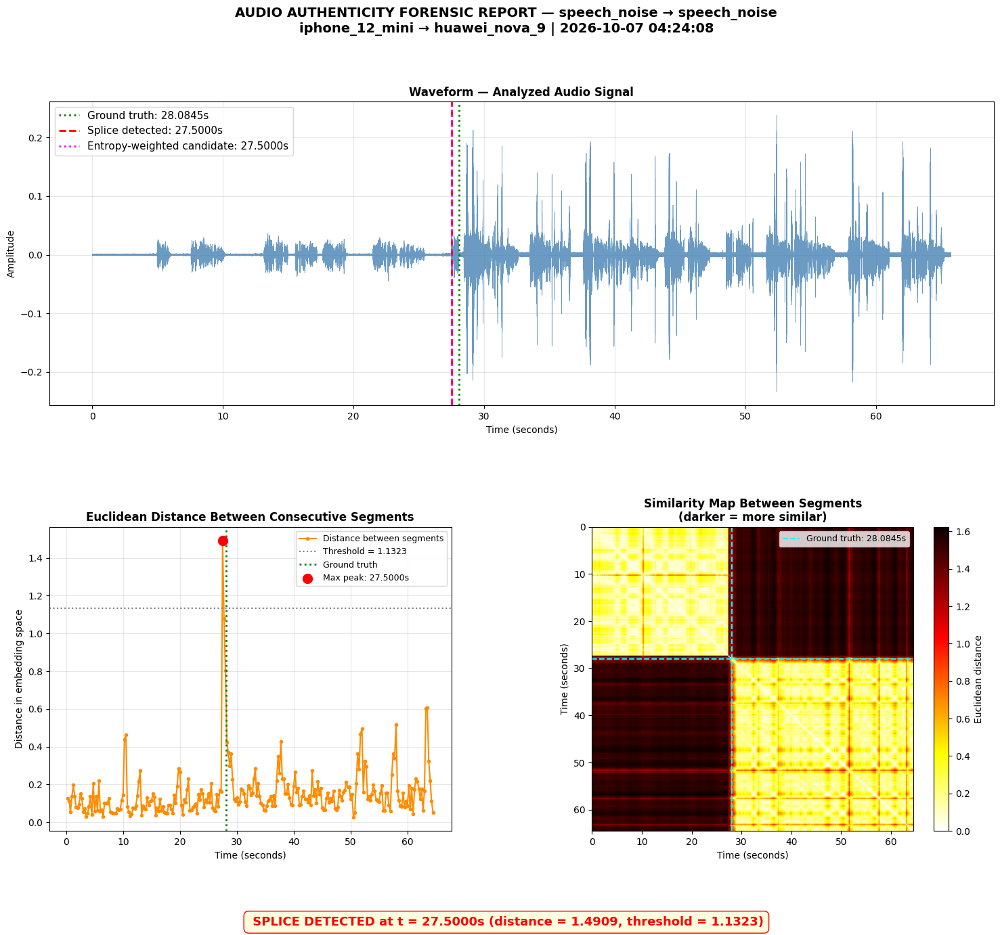

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/forensic_report_speech_noise_to_speech_noise_seed42_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

=== Strategy comparison summary ===
Raw Distance (Baseline)                       error = 0.5845s (detected at 27.5000s)
Median-Filtered Distance (k=3)                error = 0.5845s (detected at 27.5000s)
Entropy-Weighted Score (window=10)            error = 0.5845s (detected at 27.5000s)
Median-Filtered + Entropy-Weighted Score      error = 0.5845s (detected at 27.5000s)


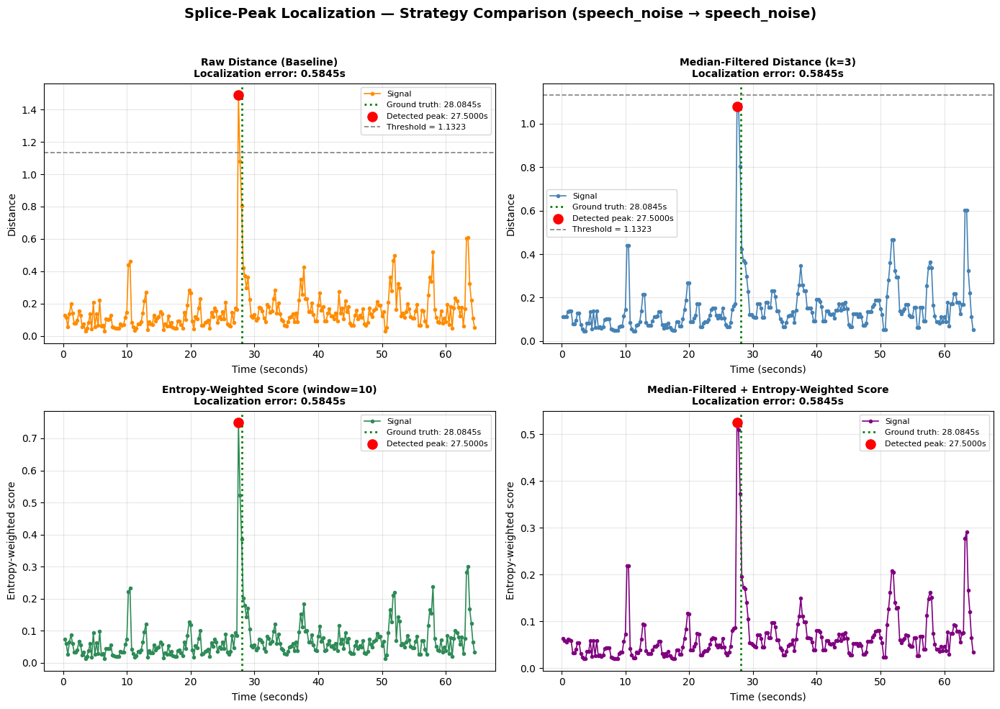

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_speech_noise_to_speech_noise_seed42_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
# Standalone cell: single-example forensic report on a NOISE -> NOISE splice
# (same protocol as the TEST block: generate_simple_splicing, top_db=TOP_DB, no edge margin).
# Needs only the files saved on Drive. Restart-safe.

import os, sys, pickle, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from datetime import datetime
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import (generate_simple_splicing, entropy_weighted_localization,
                            _apply_median_filter, _local_distance_entropy,
                            _audio_embeddings, _consecutive_distances)

# ── Configuration (must match the original run) ──
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

SR, N_FFT, HOP_LENGTH_FFT = 44100, 2048, 2048
WIN_SEC, HOP_SEC = 1.0, 0.25
OUT_DIM, TOP_DB = 64, 30
MEDIAN_KERNEL, ENTROPY_WINDOW = 3, 10
DPI = 400

CONDITION_A = "speech_noise"   # condition of the source audio (before the cut)
CONDITION_B = "speech_noise"   # condition of the destination audio (after the cut)
SEED = 42                      # change it to draw a different device pair / take

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Architecture (identical to the training notebook) ──
class Backbone(nn.Sequential):
    def __init__(self, p=0.1):
        super().__init__(
            nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Dropout2d(p),
        )

class Neck(nn.Sequential):
    def __init__(self, out_dim, p=0.1):
        super().__init__(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 1024), nn.ReLU(), nn.Dropout(p),
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, out_dim),
        )

class EmbeddingNet(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.backbone, self.neck = Backbone(), Neck(out_dim)
    def forward(self, x, valid_input_time_lengths=None):
        return F.normalize(self.neck(self.backbone(x)), p=2, dim=1)

checkpoint = torch.load(os.path.join(output_path, f"siamese_model_{run_name}.pth"), map_location="cpu")
model = EmbeddingNet(OUT_DIM)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device).eval()

# ── Frozen audio-level threshold (Euclidean, calibrated on val_audios) ──
experiment_path = os.path.join(output_path, f"experiment_{eval_run_name}.pkl")
if os.path.exists(experiment_path):
    with open(experiment_path, "rb") as f:
        threshold = float(pickle.load(f)["calibrated_threshold"]["audio"])
else:  # fallback: the final-test detail stores the fixed threshold it used
    with open(os.path.join(output_path, f"eer_detail_{eval_run_name}.pkl"), "rb") as f:
        threshold = float(pickle.load(f)["audio"]["optimal_threshold"])
print(f"Frozen audio threshold (Euclidean): {threshold:.4f}")

# ── Test audios (never seen) ──
with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    test_audios = pickle.load(f)["test_audios"]

# ── Draw a cross-device pair with the requested conditions and splice it ──
dev_names = sorted({a['device'] for a in test_audios})
spliced_audio, cut_sample = None, None
for _ in range(1000):
    device_a, device_b = random.sample(dev_names, 2)
    pool_a = [a for a in test_audios if a['device'] == device_a and a['condition'] == CONDITION_A]
    pool_b = [a for a in test_audios if a['device'] == device_b and a['condition'] == CONDITION_B]
    if not pool_a or not pool_b:
        continue
    audio_a, audio_b = random.choice(pool_a), random.choice(pool_b)
    spliced_audio, cut_sample = generate_simple_splicing(audio_a['audio'], audio_b['audio'], top_db=TOP_DB)
    if spliced_audio is not None:
        break
if spliced_audio is None:
    raise RuntimeError("No valid splice found; try another SEED.")

real_cut_time = cut_sample / SR
print(f"Splice: {device_a} ({audio_a['condition']}, {audio_a['filename']}) -> "
      f"{device_b} ({audio_b['condition']}, {audio_b['filename']})")
print(f"Real cut point: sample {cut_sample} - {real_cut_time:.4f} s")

# ── Embeddings and consecutive distances (same functions as the evaluation) ──
embeddings, timestamps = _audio_embeddings(
    spliced_audio, model, device=device, sr=SR, win_sec=WIN_SEC, hop_sec=HOP_SEC,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT)
distances = _consecutive_distances(embeddings, distance_metric="euclidean")
dist_times = np.asarray(timestamps[1:])

max_idx = int(np.argmax(distances))
splice_time = float(dist_times[max_idx])
has_splice = bool(distances[max_idx] > threshold)

entropy_candidate = entropy_weighted_localization(distances, list(dist_times), entropy_window=ENTROPY_WINDOW)
has_splice_entropy = entropy_candidate['entropy_max_distance'] > threshold

print(f"\nMax distance found: {distances[max_idx]:.4f}")
print(f"Current threshold:  {threshold:.4f}")
print(f"Detected splice?:   {has_splice}")
if has_splice:
    print(f"Model detected: splice at {splice_time:.4f}s | error: {abs(real_cut_time - splice_time):.4f}s")
else:
    print("Model detected: AUTHENTIC AUDIO (did not exceed the threshold)")
if has_splice_entropy:
    t_ent = entropy_candidate['entropy_detected_time_s']
    print(f"Entropy-weighted candidate: {t_ent:.4f}s | error: {abs(real_cut_time - t_ent):.4f}s")
else:
    print("Entropy-weighted candidate: no distance above threshold")

# ── Figure 1: forensic report (waveform, distances, similarity map) ──
n_win = len(embeddings)
similarity = np.linalg.norm(embeddings[:, None, :] - embeddings[None, :, :], axis=-1)

fig = plt.figure(figsize=(18, 14))
fig.suptitle(f"AUDIO AUTHENTICITY FORENSIC REPORT — {CONDITION_A} - {CONDITION_B}\n"
             f"{device_a} - {device_b} | {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
             fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

ax1 = fig.add_subplot(gs[0, :])
ax1.plot(np.arange(len(spliced_audio)) / SR, spliced_audio, color='steelblue', linewidth=0.5, alpha=0.8)
ax1.axvline(real_cut_time, color='green', linewidth=2, linestyle=':', label=f'Ground truth: {real_cut_time:.4f}s')
if has_splice:
    ax1.axvline(splice_time, color='red', linewidth=2, linestyle='--', label=f'Splice detected: {splice_time:.4f}s')
if has_splice_entropy:
    ax1.axvline(entropy_candidate['entropy_detected_time_s'], color='magenta', linewidth=2, linestyle=':',
                label=f"Entropy-weighted candidate: {entropy_candidate['entropy_detected_time_s']:.4f}s")
ax1.set_title('Waveform — Analyzed Audio Signal', fontweight='bold')
ax1.set_xlabel('Time (seconds)'); ax1.set_ylabel('Amplitude')
ax1.legend(fontsize=11); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(dist_times, distances, color='darkorange', linewidth=1.5, marker='o', markersize=3,
         label='Distance between segments')
ax2.axhline(threshold, color='gray', linestyle=':', linewidth=1.5, label=f'Threshold = {threshold:.4f}')
ax2.axvline(real_cut_time, color='green', linestyle=':', linewidth=2, label='Ground truth')
ax2.scatter([splice_time], [distances[max_idx]], color='red', s=100, zorder=5, label=f'Max peak: {splice_time:.4f}s')
ax2.set_title('Euclidean Distance Between Consecutive Segments', fontweight='bold')
ax2.set_xlabel('Time (seconds)'); ax2.set_ylabel('Distance in embedding space')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 1])
im = ax3.imshow(similarity, cmap='hot_r', aspect='auto',
                extent=[timestamps[0], timestamps[-1], timestamps[-1], timestamps[0]])
plt.colorbar(im, ax=ax3, label='Euclidean distance')
ax3.axvline(real_cut_time, color='cyan', linewidth=1.5, linestyle='--', label=f'Ground truth: {real_cut_time:.4f}s')
ax3.axhline(real_cut_time, color='cyan', linewidth=1.5, linestyle='--')
ax3.set_title('Similarity Map Between Segments\n(darker = more similar)', fontweight='bold')
ax3.set_xlabel('Time (seconds)'); ax3.set_ylabel('Time (seconds)'); ax3.legend(fontsize=9)

verdict = (f" SPLICE DETECTED at t = {splice_time:.4f}s (distance = {distances[max_idx]:.4f}, threshold = {threshold:.4f})"
           if has_splice else
           f" AUTHENTIC AUDIO — max distance {distances[max_idx]:.4f} < threshold {threshold:.4f}")
fig.text(0.5, 0.01, verdict, ha='center', fontsize=13, fontweight='bold',
         color='red' if has_splice else 'green',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow',
                   edgecolor='red' if has_splice else 'green'))
tag = f"{CONDITION_A}_to_{CONDITION_B}_seed{SEED}"
report_path = os.path.join(output_path, f"forensic_report_{tag}_{eval_run_name}.png")
plt.savefig(report_path, dpi=DPI, bbox_inches='tight'); plt.show()
print(f"Saved: {report_path}")

# ── Figure 2: localization strategy comparison (raw / median / entropy / median+entropy) ──
filtered = _apply_median_filter(distances, MEDIAN_KERNEL)
score_entropy_raw = distances / (_local_distance_entropy(distances, ENTROPY_WINDOW) + 1e-10)
score_combined = filtered / (_local_distance_entropy(filtered, ENTROPY_WINDOW) + 1e-10)

panels = [
    ("Raw Distance (Baseline)", distances, True, 'darkorange'),
    (f"Median-Filtered Distance (k={MEDIAN_KERNEL})", filtered, True, 'steelblue'),
    (f"Entropy-Weighted Score (window={ENTROPY_WINDOW})", score_entropy_raw, False, 'seagreen'),
    ("Median-Filtered + Entropy-Weighted Score", score_combined, False, 'purple'),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
print("\n=== Strategy comparison summary ===")
for ax, (title, curve, is_distance, color) in zip(axes.ravel(), panels):
    peak = int(np.argmax(curve)); t_peak = float(dist_times[peak]); err = abs(t_peak - real_cut_time)
    ax.plot(dist_times, curve, color=color, linewidth=1.2, marker='o', markersize=3, label='Signal')
    ax.axvline(real_cut_time, color='green', linestyle=':', linewidth=2, label=f'Ground truth: {real_cut_time:.4f}s')
    ax.scatter([t_peak], [curve[peak]], color='red', s=90, zorder=5, label=f'Detected peak: {t_peak:.4f}s')
    if is_distance:
        ax.axhline(threshold, color='gray', linestyle='--', linewidth=1.2, label=f'Threshold = {threshold:.4f}')
    ax.set_title(f"{title}\nLocalization error: {err:.4f}s", fontweight='bold', fontsize=10)
    ax.set_xlabel('Time (seconds)'); ax.set_ylabel('Distance' if is_distance else 'Entropy-weighted score')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    print(f"{title:<45} error = {err:.4f}s (detected at {t_peak:.4f}s)")
fig.suptitle(f'Splice-Peak Localization — Strategy Comparison ({CONDITION_A} → {CONDITION_B})',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
comparison_path = os.path.join(output_path, f"filtering_comparison_{tag}_{eval_run_name}.png")
plt.savefig(comparison_path, dpi=DPI, bbox_inches='tight'); plt.show()
print(f"Saved: {comparison_path}")

In [ ]:
# Standalone cell: exports the 14 evaluation-report PDFs of Annex I as PNG images,
# named after the figure they correspond to. Reads only files saved on Drive.

!pip install pymupdf -q

import os
import fitz  # PyMuPDF
from google.colab import drive

drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

EXPORT_DIR = os.path.join(output_path, "annex_I_figures")
os.makedirs(EXPORT_DIR, exist_ok=True)
RENDER_DPI = 200  # raise to 300 if the final document needs sharper figures

# (figure number, short file label, PDF file name, caption)
FIGURES = [
    (1,  "prueba_euclidiana",
     f"eer_report_final_test_{eval_run_name}.pdf",
     "Reporte de evaluación, conjunto de prueba, distancia euclidiana."),
    (2,  "prueba_manhattan",
     f"eer_report_final_test_manhattan_{eval_run_name}.pdf",
     "Reporte de evaluación, conjunto de prueba, distancia Manhattan."),
    (3,  "prueba_mahalanobis",
     f"eer_report_final_test_mahalanobis_{eval_run_name}.pdf",
     "Reporte de evaluación, conjunto de prueba, distancia de Mahalanobis."),
    (4,  "prueba_snr",
     f"eer_report_final_test_snr_{eval_run_name}.pdf",
     "Reporte de evaluación, conjunto de prueba, distancia SNR."),
    (5,  "prueba_limpia_euclidiana",
     f"eer_report_clean_{eval_run_name}.pdf",
     "Reporte de evaluación, prueba solo con audios limpios, distancia euclidiana."),
    (6,  "prueba_ruido_euclidiana",
     f"eer_report_noise_{eval_run_name}.pdf",
     "Reporte de evaluación, prueba solo con audios con ruido, distancia euclidiana."),
    (7,  "no_vistos_euclidiana",
     f"eer_report_unseen_devices_{eval_run_name}.pdf",
     "Reporte de evaluación, dispositivos no vistos, distancia euclidiana."),
    (8,  "no_vistos_manhattan",
     f"eer_report_unseen_devices_manhattan_{eval_run_name}.pdf",
     "Reporte de evaluación, dispositivos no vistos, distancia Manhattan."),
    (9,  "no_vistos_mahalanobis",
     f"eer_report_unseen_devices_mahalanobis_{eval_run_name}.pdf",
     "Reporte de evaluación, dispositivos no vistos, distancia de Mahalanobis."),
    (10, "no_vistos_snr",
     f"eer_report_unseen_devices_snr_{eval_run_name}.pdf",
     "Reporte de evaluación, dispositivos no vistos, distancia SNR."),
    (11, "ia_euclidiana",
     f"ia_splicing_report_ia_splicing_{eval_run_name}.pdf",
     "Reporte de evaluación, empalmes con IA, distancia euclidiana."),
    (12, "ia_manhattan",
     f"ia_splicing_report_ia_splicing_manhattan_{eval_run_name}.pdf",
     "Reporte de evaluación, empalmes con IA, distancia Manhattan."),
    (13, "ia_mahalanobis",
     f"ia_splicing_report_ia_splicing_mahalanobis_{eval_run_name}.pdf",
     "Reporte de evaluación, empalmes con IA, distancia de Mahalanobis."),
    (14, "ia_snr",
     f"ia_splicing_report_ia_splicing_snr_{eval_run_name}.pdf",
     "Reporte de evaluación, empalmes con IA, distancia SNR."),
]

missing = []
for number, label, pdf_name, caption in FIGURES:
    pdf_path = os.path.join(output_path, pdf_name)
    if not os.path.exists(pdf_path):
        missing.append((number, pdf_name))
        continue
    with fitz.open(pdf_path) as document:
        pixmap = document[0].get_pixmap(dpi=RENDER_DPI)
        png_name = f"Figura_I.{number:02d}_{label}.png"
        png_path = os.path.join(EXPORT_DIR, png_name)
        pixmap.save(png_path)
        print(f"Figura I.{number}: {png_name}  ({pixmap.width}x{pixmap.height}px)")

# Captions file, same numbering as the images
captions_path = os.path.join(EXPORT_DIR, "pies_de_figura_anexo_I.txt")
with open(captions_path, "w", encoding="utf-8") as f:
    for number, label, pdf_name, caption in FIGURES:
        f.write(f"Figura I.{number}. {caption}\n")
print(f"\nCaptions saved to {captions_path}")

print("\n=== Captions ready to paste ===")
for number, label, pdf_name, caption in FIGURES:
    print(f"Figura I.{number}. {caption}")

if missing:
    print("\n=== NOT FOUND (check file names in Drive) ===")
    for number, pdf_name in missing:
        print(f"I.{number}: {pdf_name}")
    print("\nPDFs currently available:")
    for name in sorted(os.listdir(output_path)):
        if name.endswith(".pdf") and ("eer_report" in name or "ia_splicing_report" in name):
            print("  ", name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Figura I.1: Figura_I.01_prueba_euclidiana.png  (4057x4121px)
Figura I.2: Figura_I.02_prueba_manhattan.png  (4039x4121px)
Figura I.3: Figura_I.03_prueba_mahalanobis.png  (4128x4121px)
Figura I.4: Figura_I.04_prueba_snr.png  (4075x4121px)
Figura I.5: Figura_I.05_prueba_limpia_euclidiana.png  (4128x4121px)
Figura I.6: Figura_I.06_prueba_ruido_euclidiana.png  (4075x4121px)
Figura I.7: Figura_I.07_no_vistos_euclidiana.png  (4004x4121px)
Figura I.8: Figura_I.08_no_vistos_manhattan.png  (4004x4121px)
Figura I.9: Figura_I.09_no_vistos_mahalanobis.png  (4004x4121px)
Figura I.10: Figura_I.10_no_vistos_snr.png  (4004x4121px)
Figura I.11: Figura_I.11_ia_euclidiana.png  (4145x2375px)
Figura I.12: Figura_I.12_ia_manhattan.png  (4145x2375px)
Figura I.13: Figura_I.13_ia_mahalanobis.png  (4145x2375px)
Figura I.14: Figura_I.14_ia_snr.png  (4145x2375px)

Captions saved to /cont

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frozen audio threshold (Euclidean): 1.1323
Unseen durations: n=504 | min/median/max = 14.4 / 31.6 / 40.7 s

 test_noise | condition=speech_noise | 4 splices | top_db used = 30 | duration = 47.5s 
  Segment 1: iphone_12_mini (speaker_18.wav)  [0.00s - 4.51s]
  Segment 2: huawei_nova_9 (speaker_9.wav)  [4.51s - 9.06s]
  Segment 3: oneplus_nord (speaker_4.wav)  [9.06s - 18.64s]
  Segment 4: moto_edge_30 (speaker_9.wav)  [18.64s - 32.55s]
  Segment 5: moto_g9_power (speaker_4.wav)  [32.55s - 47.55s]
  True cuts (s): 4.508, 9.064, 18.640, 32.549
  Max distance = 1.4410 | threshold = 1.1323
  [above threshold] Cut 1  4.508s- nearest 4.000s | error 0.508s | HIT
  [above threshold] Cut 2  9.064s- nearest 8.250s | error 0.814s | HIT
  [above threshold] Cut 3  18.640s- nearest 8.250s | error 10.390s | MISS
  [above threshold] Cut 4  32.549s- nearest 31.750s | error 0.7

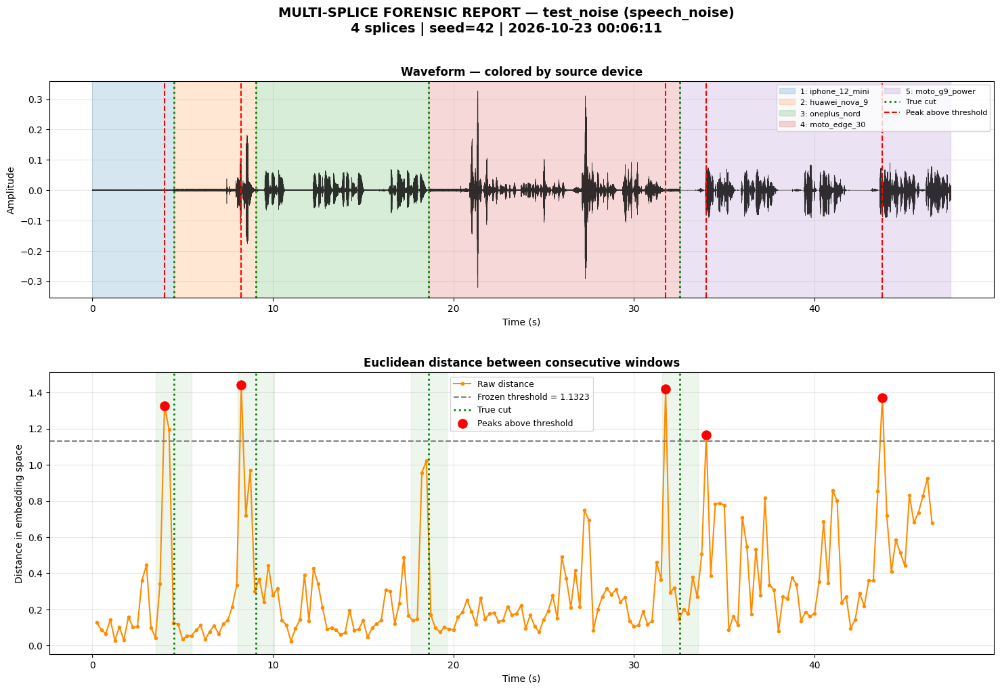

  Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/forensic_multisplice_test_noise_n4_seed42_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png

 unseen | condition=all | 4 splices | top_db used = 25 | duration = 36.3s 
  Segment 1: Sony Ericson c902 (speaker13.wav)  [0.00s - 5.41s]
  Segment 2: Apple iPhone 5 (speaker4.wav)  [5.41s - 19.51s]
  Segment 3: Samsung GT-I8190 mini (speaker15.wav)  [19.51s - 27.76s]
  Segment 4: Sony ericson c510i (speaker23.wav)  [27.76s - 33.21s]
  Segment 5: Sony Ericson c902 (speaker3.wav)  [33.21s - 36.25s]
  True cuts (s): 5.413, 19.509, 27.755, 33.211
  Max distance = 0.2669 | threshold = 1.1323
  [above threshold] Cut 1 @ 5.413s - none | MISS
  [above threshold] Cut 2 @ 19.509s - none | MISS
  [above threshold] Cut 3 @ 27.755s - none | MISS
  [above threshold] Cut 4 @ 33.211s - none | MISS
  [above threshold] located 0/4 | extra peaks (no cut within 1.0s): 0
  [prominence candidates] Cut 1  

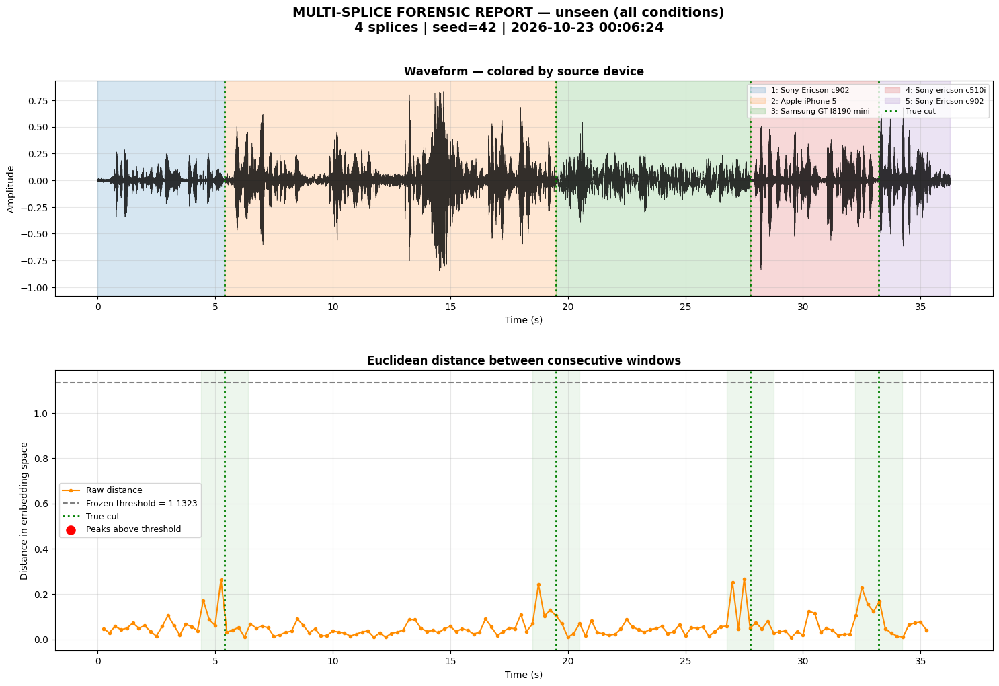

  Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/forensic_multisplice_unseen_n4_seed42_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
# Standalone cell: forensic report on an audio with MULTIPLE splices (NOISE condition for test,
# all audios for unseen devices). Needs only the files saved on Drive. Restart-safe.

import os, sys, pickle, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import librosa
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import find_peaks
from datetime import datetime
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import _audio_embeddings, _consecutive_distances, _apply_median_filter

# ── Configuration (must match the original run) ──
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

SR, N_FFT, HOP_LENGTH_FFT = 44100, 2048, 2048
WIN_SEC, HOP_SEC = 1.0, 0.25
OUT_DIM, TOP_DB = 64, 30
MEDIAN_KERNEL = 3
TOLERANCE_S = 1.0            # same as IA_SPLICING_TOLERANCE_S
DPI = 400

N_SPLICES = 4                # number of cuts (=> N_SPLICES + 1 segments from different devices)
MIN_EDGE_S = 2.0             # minimum distance from the first/last cut to the audio borders
MIN_SEPARATION_S = 4.0       # minimum distance between two consecutive cuts
SILENCE_GUARD_S = 0.05       # a cut must be surrounded by +/- this much silence in BOTH audios
PEAK_MIN_DISTANCE_S = 1.0    # minimum separation between detected peaks
SEED = 42                    # change it to draw a different combination

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Architecture (identical to the training notebook) ──
class Backbone(nn.Sequential):
    def __init__(self, p=0.1):
        super().__init__(
            nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Dropout2d(p),
        )

class Neck(nn.Sequential):
    def __init__(self, out_dim, p=0.1):
        super().__init__(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 1024), nn.ReLU(), nn.Dropout(p),
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, out_dim),
        )

class EmbeddingNet(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.backbone, self.neck = Backbone(), Neck(out_dim)
    def forward(self, x, valid_input_time_lengths=None):
        return F.normalize(self.neck(self.backbone(x)), p=2, dim=1)

checkpoint = torch.load(os.path.join(output_path, f"siamese_model_{run_name}.pth"), map_location="cpu")
model = EmbeddingNet(OUT_DIM)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device).eval()

# ── Frozen audio-level threshold (Euclidean, calibrated on val_audios) ──
experiment_path = os.path.join(output_path, f"experiment_{eval_run_name}.pkl")
if os.path.exists(experiment_path):
    with open(experiment_path, "rb") as f:
        threshold = float(pickle.load(f)["calibrated_threshold"]["audio"])
else:
    with open(os.path.join(output_path, f"eer_detail_{eval_run_name}.pkl"), "rb") as f:
        threshold = float(pickle.load(f)["audio"]["optimal_threshold"])
print(f"Frozen audio threshold (Euclidean): {threshold:.4f}")

# ── Pools ──
with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    test_audios = pickle.load(f)["test_audios"]
with open(os.path.join(output_path, "unseen_devices_dataset.pkl"), "rb") as f:
    unseen_devices_dataset = pickle.load(f)


# ── Multi-splice builder ──
def silence_mask(audio, top_db=TOP_DB):
    mask = np.ones(len(audio), dtype=bool)
    for start, end in librosa.effects.split(audio, top_db=top_db):
        mask[start:end] = False
    return mask

def valid_cut_mask(mask_a, mask_b, guard):
    """True at c if [c-guard, c+guard) is silent in BOTH audios."""
    both = (mask_a & mask_b).astype(np.int64)
    csum = np.concatenate([[0], np.cumsum(both)])
    valid = np.zeros(len(both), dtype=bool)
    idx = np.arange(guard, len(both) - guard)
    valid[idx] = (csum[idx + guard] - csum[idx - guard]) == 2 * guard
    return valid

def build_multi_splice(pool, condition=None, n_splices=N_SPLICES, max_attempts=500):
    guard = int(SILENCE_GUARD_S * SR)
    min_edge, min_sep = int(MIN_EDGE_S * SR), int(MIN_SEPARATION_S * SR)
    eligible = [a for a in pool if condition is None or a['condition'] == condition]
    by_device = {}
    for a in eligible:
        by_device.setdefault(a['device'], []).append(a)
    device_names = sorted(by_device)
    if len(device_names) < 2:
        raise ValueError("Need at least 2 devices in the pool.")

    for _ in range(max_attempts):
        # consecutive segments always come from different devices
        sequence = [random.choice(device_names)]
        while len(sequence) < n_splices + 1:
            sequence.append(random.choice([d for d in device_names if d != sequence[-1]]))
        items = [random.choice(by_device[d]) for d in sequence]
        length = min(len(i['audio']) for i in items)
        if length < 2 * min_edge + (n_splices - 1) * min_sep:
            continue
        signals = [i['audio'][:length] for i in items]
        masks = [silence_mask(s) for s in signals]

        cuts, previous, ok = [], min_edge - min_sep, True
        for k in range(n_splices):
            valid = valid_cut_mask(masks[k], masks[k + 1], guard)
            low = previous + min_sep
            high = length - min_edge - (n_splices - 1 - k) * min_sep
            candidates = np.flatnonzero(valid[low:high]) + low if high > low else np.array([])
            if len(candidates) == 0:
                ok = False
                break
            previous = int(random.choice(candidates))
            cuts.append(previous)
        if not ok:
            continue

        bounds = [0] + cuts + [length]
        spliced = np.concatenate([signals[k][bounds[k]:bounds[k + 1]] for k in range(n_splices + 1)])
        return {"audio": spliced, "cuts_s": [c / SR for c in cuts], "bounds_s": [b / SR for b in bounds],
                "devices": sequence, "filenames": [i['filename'] for i in items],
                "conditions": [i['condition'] for i in items]}
    raise RuntimeError("No valid multi-splice found; lower N_SPLICES / MIN_SEPARATION_S or change SEED.")


# ── Analysis + figure ──
# ── Multi-splice builder (each segment comes from ONE audio, from a silence point to a silence point) ──
POOL_CONFIG = {
    "test_noise": dict(condition="speech_noise", n_splices=4, min_edge_s=2.0, min_sep_s=4.0,
                       max_seg_s=15.0, guard_s=0.05, top_db_schedule=(30,)),
    "unseen":     dict(condition=None,           n_splices=4, min_edge_s=1.0, min_sep_s=2.0,
                       max_seg_s=15.0, guard_s=0.02, top_db_schedule=(30, 25, 20, 15, 10)),
}
PROMINENCE_FACTOR = 0.5      # candidate peaks: prominence >= factor * std(distances), even below the threshold

_silence_cache = {}
def silence_points(item, top_db, guard):
    """Sample indices c such that [c-guard, c+guard) is silent (below top_db) in this audio."""
    key = (id(item), top_db, guard)
    if key not in _silence_cache:
        audio = item['audio']
        mask = np.ones(len(audio), dtype=bool)
        for s, e in librosa.effects.split(audio, top_db=top_db):
            mask[s:e] = False
        csum = np.concatenate([[0], np.cumsum(mask.astype(np.int64))])
        idx = np.arange(guard, len(audio) - guard)
        ok = (csum[idx + guard] - csum[idx - guard]) == 2 * guard
        _silence_cache[key] = idx[ok]
    return _silence_cache[key]

def build_multi_splice(pool, condition, n_splices, min_edge_s, min_sep_s, max_seg_s,
                       guard_s, top_db_schedule, max_attempts=300):
    guard = int(guard_s * SR)
    min_edge, min_sep, max_seg = int(min_edge_s * SR), int(min_sep_s * SR), int(max_seg_s * SR)
    eligible = [a for a in pool if condition is None or a['condition'] == condition]
    by_device = {}
    for a in eligible:
        by_device.setdefault(a['device'], []).append(a)
    device_names = sorted(by_device)
    if len(device_names) < 2:
        raise ValueError("Need at least 2 devices in the pool.")

    for top_db in top_db_schedule:
        for _ in range(max_attempts):
            sequence = [random.choice(device_names)]
            while len(sequence) < n_splices + 1:
                sequence.append(random.choice([d for d in device_names if d != sequence[-1]]))
            items = [random.choice(by_device[d]) for d in sequence]

            pieces, ok = [], True
            for k, item in enumerate(items):
                n = len(item['audio'])
                pts = silence_points(item, top_db, guard)
                first, last = (k == 0), (k == n_splices)
                min_len = min_edge if (first or last) else min_sep
                if first:
                    start = 0
                else:
                    cand = pts[(n - pts) >= min_len] if last else pts[(n - pts) >= min_len + 2 * guard]
                    if len(cand) == 0:
                        ok = False; break
                    start = int(random.choice(cand))
                if last:
                    end = n
                    if end - start > max_seg:
                        end = start + max_seg
                else:
                    cand = pts[(pts - start >= min_len) & (pts - start <= max_seg)]
                    if len(cand) == 0:
                        ok = False; break
                    end = int(random.choice(cand))
                pieces.append((start, end))
            if not ok:
                continue

            spliced = np.concatenate([it['audio'][s:e] for it, (s, e) in zip(items, pieces)])
            lengths = np.array([e - s for s, e in pieces])
            bounds = np.concatenate([[0], np.cumsum(lengths)])
            return {"audio": spliced, "cuts_s": (bounds[1:-1] / SR).tolist(), "bounds_s": (bounds / SR).tolist(),
                    "devices": sequence, "filenames": [i['filename'] for i in items],
                    "conditions": [i['condition'] for i in items], "top_db_used": top_db}
    return None


def build_with_fallback(pool, cfg):
    """Tries the requested number of splices and reduces it if no valid combination exists."""
    for n_splices in range(cfg["n_splices"], 0, -1):
        sample = build_multi_splice(pool, cfg["condition"], n_splices, cfg["min_edge_s"], cfg["min_sep_s"],
                                    cfg["max_seg_s"], cfg["guard_s"], cfg["top_db_schedule"])
        if sample is not None:
            if n_splices < cfg["n_splices"]:
                print(f"  NOTE: reduced from {cfg['n_splices']} to {n_splices} splices (no valid combination).")
            return sample
    raise RuntimeError("No valid splice found even with 1 cut; lower min_sep_s/min_edge_s or relax top_db.")


# Analysis + figure
def run_multi_splice_report(pool_name, pool):
    cfg = POOL_CONFIG[pool_name]
    sample = build_with_fallback(pool, cfg)
    audio, cuts_s = sample["audio"], np.array(sample["cuts_s"])
    print(f"\n {pool_name} | condition={cfg['condition'] or 'all'} | {len(cuts_s)} splices "
          f"| top_db used = {sample['top_db_used']} | duration = {len(audio)/SR:.1f}s ")
    for k, (dev, fn) in enumerate(zip(sample["devices"], sample["filenames"])):
        print(f"  Segment {k + 1}: {dev} ({fn})  [{sample['bounds_s'][k]:.2f}s - {sample['bounds_s'][k + 1]:.2f}s]")
    print("  True cuts (s):", ", ".join(f"{c:.3f}" for c in cuts_s))

    embeddings, timestamps = _audio_embeddings(
        audio, model, device=device, sr=SR, win_sec=WIN_SEC, hop_sec=HOP_SEC,
        n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT)
    distances = np.asarray(_consecutive_distances(embeddings, distance_metric="euclidean"))
    dist_times = np.asarray(timestamps[1:])
    #filtered = _apply_median_filter(distances, MEDIAN_KERNEL)
    min_peak_gap = max(int(PEAK_MIN_DISTANCE_S / HOP_SEC), 1)

    # (a) detections: peaks above the frozen threshold
    peak_idx, _ = find_peaks(distances, height=threshold, distance=min_peak_gap)
    peak_times = dist_times[peak_idx]
    # (b) candidates: prominent local peaks, even below the threshold (diagnostic only)
    cand_idx, _ = find_peaks(distances, prominence=PROMINENCE_FACTOR * distances.std(), distance=min_peak_gap)
    cand_times = dist_times[cand_idx]

    def score(times, label):
        hits = 0
        for k, c in enumerate(cuts_s):
            if len(times):
                nearest = times[np.argmin(np.abs(times - c))]
                err = abs(nearest - c)
                hit = err <= TOLERANCE_S
                hits += int(hit)
                print(f"  [{label}] Cut {k + 1}  {c:.3f}s- nearest {nearest:.3f}s | error {err:.3f}s | "
                      f"{'HIT' if hit else 'MISS'}")
            else:
                print(f"  [{label}] Cut {k + 1} @ {c:.3f}s - none | MISS")
        extra = [t for t in times if np.min(np.abs(cuts_s - t)) > TOLERANCE_S]
        print(f"  [{label}] located {hits}/{len(cuts_s)} | extra peaks (no cut within {TOLERANCE_S}s): {len(extra)}")
        return hits, extra

    print(f"  Max distance = {distances.max():.4f} | threshold = {threshold:.4f}")
    hits, false_peaks = score(peak_times, "above threshold")
    cand_hits, cand_extra = score(cand_times, "prominence candidates")

    # Figure
    colors = plt.get_cmap("tab10")
    fig = plt.figure(figsize=(18, 11))
    fig.suptitle(f"MULTI-SPLICE FORENSIC REPORT — {pool_name} ({cfg['condition'] or 'all conditions'})\n"
                 f"{len(cuts_s)} splices | seed={SEED} | {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
                 fontsize=14, fontweight='bold')
    gs = gridspec.GridSpec(2, 1, figure=fig, hspace=0.3, height_ratios=[1, 1.3])

    ax1 = fig.add_subplot(gs[0])
    ax1.plot(np.arange(len(audio)) / SR, audio, color='black', linewidth=0.4, alpha=0.8)
    for k, dev in enumerate(sample["devices"]):
        ax1.axvspan(sample["bounds_s"][k], sample["bounds_s"][k + 1], color=colors(k % 10), alpha=0.18,
                    label=f"{k + 1}: {dev}")
    for k, c in enumerate(cuts_s):
        ax1.axvline(c, color='green', linestyle=':', linewidth=2, label='True cut' if k == 0 else None)
    for k, t in enumerate(peak_times):
        ax1.axvline(t, color='red', linestyle='--', linewidth=1.5, label='Peak above threshold' if k == 0 else None)
    ax1.set_title('Waveform — colored by source device', fontweight='bold')
    ax1.set_xlabel('Time (s)'); ax1.set_ylabel('Amplitude')
    ax1.legend(fontsize=8, ncol=2, loc='upper right'); ax1.grid(True, alpha=0.3)

    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.plot(dist_times, distances, color='darkorange', linewidth=1.5, marker='o', markersize=3, label='Raw distance')
    #ax2.plot(dist_times, filtered, color='steelblue', linewidth=1.2, alpha=0.8, label=f'Median filtered (k={MEDIAN_KERNEL})')
    ax2.axhline(threshold, color='gray', linestyle='--', linewidth=1.5, label=f'Frozen threshold = {threshold:.4f}')
    for k, c in enumerate(cuts_s):
        ax2.axvline(c, color='green', linestyle=':', linewidth=2, label='True cut' if k == 0 else None)
        ax2.axvspan(c - TOLERANCE_S, c + TOLERANCE_S, color='green', alpha=0.07)
    #ax2.scatter(cand_times, distances[cand_idx], facecolors='none', edgecolors='purple', s=140, linewidths=1.8,
                #zorder=4, label='Prominent local peaks (diagnostic)')
    ax2.scatter(peak_times, distances[peak_idx], color='red', s=90, zorder=5, label='Peaks above threshold')
    ax2.set_title(f'Euclidean distance between consecutive windows'
                  f'',
                  fontweight='bold')
    ax2.set_xlabel('Time (s)'); ax2.set_ylabel('Distance in embedding space')
    ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

    out = os.path.join(output_path, f"forensic_multisplice_{pool_name}_n{len(cuts_s)}_seed{SEED}_{eval_run_name}.png")
    plt.savefig(out, dpi=DPI, bbox_inches='tight'); plt.show()
    print(f"  Saved: {out}")
    return {"sample": sample, "distances": distances, "dist_times": dist_times,
            "peak_times": peak_times, "hits": hits, "candidate_times": cand_times, "candidate_hits": cand_hits}


# Quick look at the unseen durations (to tune POOL_CONFIG["unseen"] if needed)
_d = np.array([len(a['audio']) / SR for a in unseen_devices_dataset])
print(f"Unseen durations: n={len(_d)} | min/median/max = {_d.min():.1f} / {np.median(_d):.1f} / {_d.max():.1f} s")

multisplice_results = {
    "test_noise": run_multi_splice_report("test_noise", test_audios),
    "unseen":     run_multi_splice_report("unseen", unseen_devices_dataset),
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Umbral congelado (audio, euclidiano): 1.1323
Par: LG Optimus L9 -> HTC desire c | top_db=30 | corte real: 12.4343 s


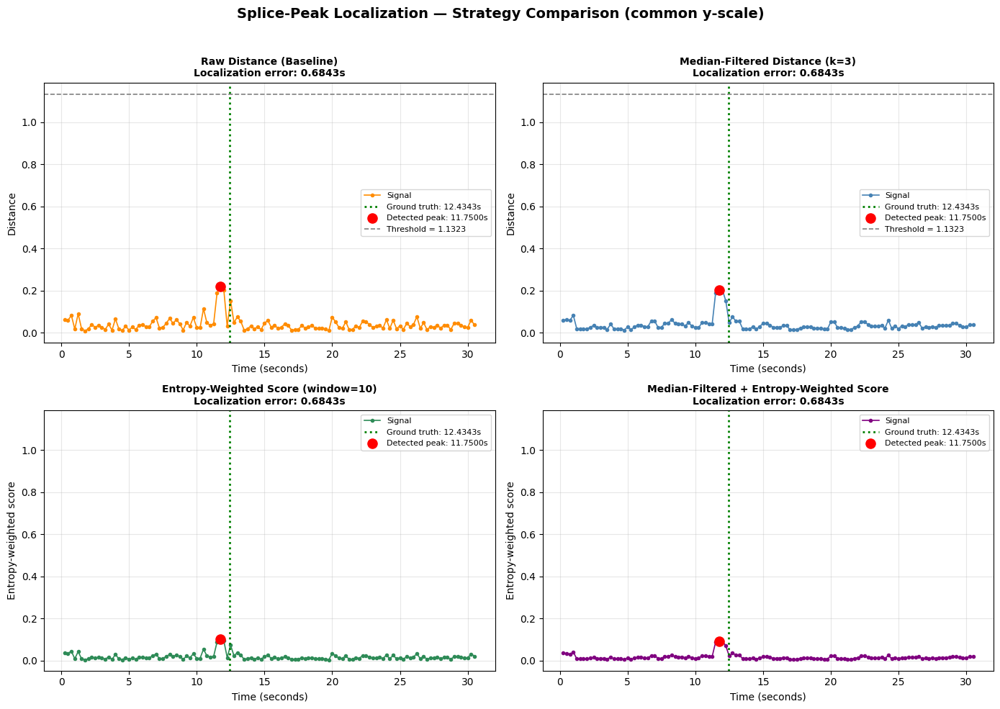

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/filtering_comparison_unseen_euclidean_same_scale.png


In [ ]:
import os, sys, pickle, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import (generate_simple_splicing, _audio_embeddings, _consecutive_distances,
                            _apply_median_filter, _local_distance_entropy)

output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

SR, N_FFT, HOP_LENGTH_FFT = 44100, 2048, 2048
WIN_SEC, HOP_SEC, OUT_DIM = 1.0, 0.25, 64
TOP_DB, TOP_DB_FLOOR, TOP_DB_STEP, N_CANDIDATES = 30, 10, 5, 15
MEDIAN_KERNEL, ENTROPY_WINDOW, DPI = 3, 10, 400
SEED = 41  # cámbialo para obtener otro par de dispositivos / corte

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Arquitectura (idéntica a la del entrenamiento) ──
class Backbone(nn.Sequential):
    def __init__(self, p=0.1):
        super().__init__(
            nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Dropout2d(p))

class Neck(nn.Sequential):
    def __init__(self, out_dim, p=0.1):
        super().__init__(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 1024), nn.ReLU(), nn.Dropout(p),
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, out_dim))

class EmbeddingNet(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.backbone, self.neck = Backbone(), Neck(out_dim)
    def forward(self, x, valid_input_time_lengths=None):
        return F.normalize(self.neck(self.backbone(x)), p=2, dim=1)

ckpt = torch.load(os.path.join(output_path, f"siamese_model_{run_name}.pth"), map_location="cpu")
model = EmbeddingNet(OUT_DIM); model.load_state_dict(ckpt['model_state_dict']); model.to(device).eval()

# ── Umbral congelado (euclidiano, nivel audio) ──
with open(os.path.join(output_path, f"eer_detail_{eval_run_name}.pkl"), "rb") as f:
    threshold = float(pickle.load(f)["audio"]["optimal_threshold"])
print(f"Umbral congelado (audio, euclidiano): {threshold:.4f}")

# ── Dispositivos no vistos ──
with open(os.path.join(output_path, "unseen_devices_dataset.pkl"), "rb") as f:
    pool = pickle.load(f)
dev_names = sorted({a['device'] for a in pool})

# ── Empalme: el par cuyo top_db requerido esté más cerca de TOP_DB ──
best = None
for _ in range(N_CANDIDATES):
    dev_a, dev_b = random.sample(dev_names, 2)
    a = random.choice([x for x in pool if x['device'] == dev_a])
    b = random.choice([x for x in pool if x['device'] == dev_b])
    for tdb in range(TOP_DB, TOP_DB_FLOOR - 1, -TOP_DB_STEP):
        spliced, cut = generate_simple_splicing(a['audio'], b['audio'], top_db=tdb)
        if spliced is not None:
            if best is None or tdb > best[0]:
                best = (tdb, spliced, cut, dev_a, dev_b)
            break
    if best is not None and best[0] == TOP_DB:
        break
if best is None:
    raise RuntimeError("No se encontró un empalme válido; prueba otro SEED.")
top_db_used, spliced, cut, dev_a, dev_b = best
gt_time = cut / SR
print(f"Par: {dev_a} -> {dev_b} | top_db={top_db_used} | corte real: {gt_time:.4f} s")

# ── Distancias consecutivas ──
emb, ts = _audio_embeddings(spliced, model, device=device, sr=SR, win_sec=WIN_SEC,
                            hop_sec=HOP_SEC, n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT)
distances = _consecutive_distances(emb, distance_metric="euclidean")
timestamps = np.asarray(ts[1:], dtype=np.float64)

np.savez(os.path.join(output_path, "unseen_example_euclidean.npz"),
         distances=distances, timestamps=timestamps, threshold=threshold, ground_truth=gt_time)

# ── Estrategias ──
filtered = _apply_median_filter(distances, MEDIAN_KERNEL)
score_entropy  = distances / (_local_distance_entropy(distances, ENTROPY_WINDOW) + 1e-10)
score_combined = filtered  / (_local_distance_entropy(filtered,  ENTROPY_WINDOW) + 1e-10)

panels = [
    ("Raw Distance (Baseline)",                            distances,      True,  'darkorange'),
    (f"Median-Filtered Distance (k={MEDIAN_KERNEL})",      filtered,       True,  'steelblue'),
    (f"Entropy-Weighted Score (window={ENTROPY_WINDOW})",  score_entropy,  False, 'seagreen'),
    ("Median-Filtered + Entropy-Weighted Score",           score_combined, False, 'purple'),
]

# Escala común en los 4 paneles
y_max = max(threshold, distances.max(), filtered.max(),
            score_entropy.max(), score_combined.max()) * 1.05
y_lim = (-0.04 * y_max, y_max)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (title, curve, is_distance, color) in zip(axes.ravel(), panels):
    peak = int(np.argmax(curve)); t_peak = float(timestamps[peak]); err = abs(t_peak - gt_time)
    ax.plot(timestamps, curve, color=color, linewidth=1.2, marker='o', markersize=3, label='Signal')
    ax.axvline(gt_time, color='green', linestyle=':', linewidth=2, label=f'Ground truth: {gt_time:.4f}s')
    ax.scatter([t_peak], [curve[peak]], color='red', s=90, zorder=5, label=f'Detected peak: {t_peak:.4f}s')
    if is_distance:
        ax.axhline(threshold, color='gray', linestyle='--', linewidth=1.2, label=f'Threshold = {threshold:.4f}')
    ax.set_ylim(*y_lim)
    ax.set_title(f"{title}\nLocalization error: {err:.4f}s", fontweight='bold', fontsize=10)
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Distance' if is_distance else 'Entropy-weighted score')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

fig.suptitle('Splice-Peak Localization — Strategy Comparison (common y-scale)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
out = os.path.join(output_path, "filtering_comparison_unseen_euclidean_same_scale.png")
plt.savefig(out, dpi=DPI, bbox_inches='tight'); plt.show()
print(f"Saved: {out}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


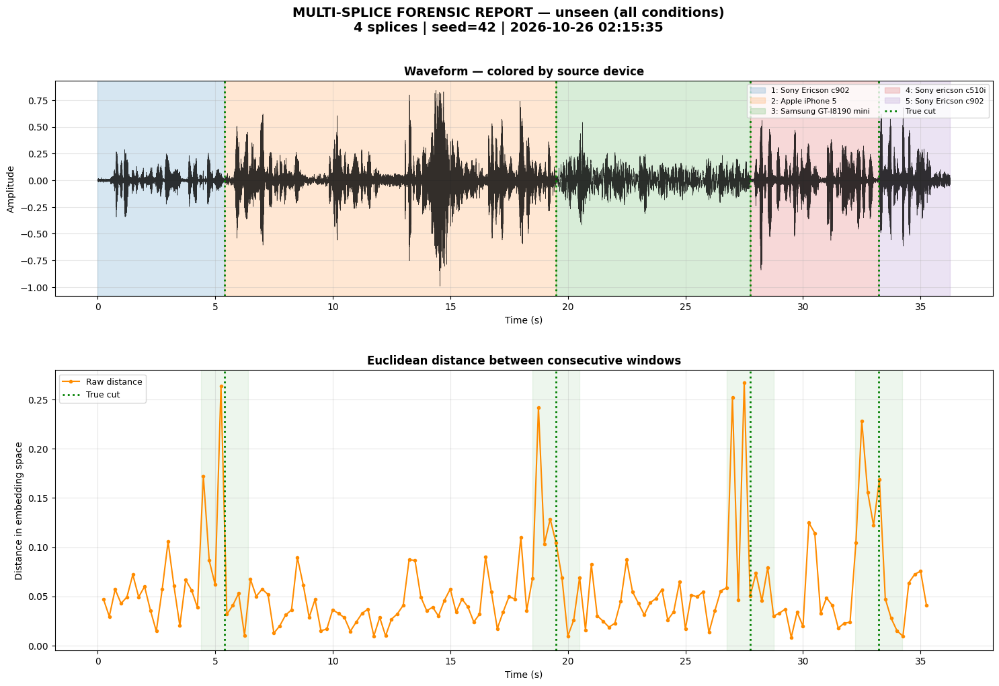

Saved: /content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum/forensic_multisplice_unseen_n4_seed42_clean_euclidean_uv_epochs840_val15_win1_cosface_outdim64_40_nm_medf3_entw10.png


In [ ]:
# Standalone cell: multi-splice figure (unseen devices) WITHOUT threshold / peaks legend entries.
# Reproduces the same sample as the original run (SEED=42, test_noise built first to consume the RNG).

import os, sys, pickle, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import librosa
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from datetime import datetime
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/AudioAuthentication')
from eer_evaluation import _audio_embeddings, _consecutive_distances

# ── Configuration (must match the original run) ──
output_path = "/content/drive/MyDrive/AudioAuthentication_results_nfft2048_NV_3_FullSpectrum"
run_name = "euclidean_uv_epochs840_val15_win1_cosface_outdim64"
eval_run_name = f"{run_name}_40_nm_medf3_entw10"

SR, N_FFT, HOP_LENGTH_FFT = 44100, 2048, 2048
WIN_SEC, HOP_SEC = 1.0, 0.25
OUT_DIM = 64
TOLERANCE_S = 1.0
DPI = 400
SEED = 42

SHOW_THRESHOLD_LINE = False   # True = draw the (unlabeled) frozen-threshold line; False = hide it

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Architecture ──
class Backbone(nn.Sequential):
    def __init__(self, p=0.1):
        super().__init__(
            nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True), nn.Dropout2d(p),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Dropout2d(p),
        )

class Neck(nn.Sequential):
    def __init__(self, out_dim, p=0.1):
        super().__init__(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(256, 1024), nn.ReLU(), nn.Dropout(p),
            nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, out_dim),
        )

class EmbeddingNet(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.backbone, self.neck = Backbone(), Neck(out_dim)
    def forward(self, x, valid_input_time_lengths=None):
        return F.normalize(self.neck(self.backbone(x)), p=2, dim=1)

checkpoint = torch.load(os.path.join(output_path, f"siamese_model_{run_name}.pth"), map_location="cpu")
model = EmbeddingNet(OUT_DIM)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device).eval()

# ── Frozen audio threshold (only used for the optional line) ──
experiment_path = os.path.join(output_path, f"experiment_{eval_run_name}.pkl")
if os.path.exists(experiment_path):
    with open(experiment_path, "rb") as f:
        threshold = float(pickle.load(f)["calibrated_threshold"]["audio"])
else:
    with open(os.path.join(output_path, f"eer_detail_{eval_run_name}.pkl"), "rb") as f:
        threshold = float(pickle.load(f)["audio"]["optimal_threshold"])

# ── Pools ──
with open(os.path.join(output_path, "raw_split.pkl"), "rb") as f:
    test_audios = pickle.load(f)["test_audios"]
with open(os.path.join(output_path, "unseen_devices_dataset.pkl"), "rb") as f:
    unseen_devices_dataset = pickle.load(f)

POOL_CONFIG = {
    "test_noise": dict(condition="speech_noise", n_splices=4, min_edge_s=2.0, min_sep_s=4.0,
                       max_seg_s=15.0, guard_s=0.05, top_db_schedule=(30,)),
    "unseen":     dict(condition=None,           n_splices=4, min_edge_s=1.0, min_sep_s=2.0,
                       max_seg_s=15.0, guard_s=0.02, top_db_schedule=(30, 25, 20, 15, 10)),
}

# ── Multi-splice builder (identical to the original) ──
_silence_cache = {}
def silence_points(item, top_db, guard):
    key = (id(item), top_db, guard)
    if key not in _silence_cache:
        audio = item['audio']
        mask = np.ones(len(audio), dtype=bool)
        for s, e in librosa.effects.split(audio, top_db=top_db):
            mask[s:e] = False
        csum = np.concatenate([[0], np.cumsum(mask.astype(np.int64))])
        idx = np.arange(guard, len(audio) - guard)
        ok = (csum[idx + guard] - csum[idx - guard]) == 2 * guard
        _silence_cache[key] = idx[ok]
    return _silence_cache[key]

def build_multi_splice(pool, condition, n_splices, min_edge_s, min_sep_s, max_seg_s,
                       guard_s, top_db_schedule, max_attempts=300):
    guard = int(guard_s * SR)
    min_edge, min_sep, max_seg = int(min_edge_s * SR), int(min_sep_s * SR), int(max_seg_s * SR)
    eligible = [a for a in pool if condition is None or a['condition'] == condition]
    by_device = {}
    for a in eligible:
        by_device.setdefault(a['device'], []).append(a)
    device_names = sorted(by_device)
    if len(device_names) < 2:
        raise ValueError("Need at least 2 devices in the pool.")

    for top_db in top_db_schedule:
        for _ in range(max_attempts):
            sequence = [random.choice(device_names)]
            while len(sequence) < n_splices + 1:
                sequence.append(random.choice([d for d in device_names if d != sequence[-1]]))
            items = [random.choice(by_device[d]) for d in sequence]

            pieces, ok = [], True
            for k, item in enumerate(items):
                n = len(item['audio'])
                pts = silence_points(item, top_db, guard)
                first, last = (k == 0), (k == n_splices)
                min_len = min_edge if (first or last) else min_sep
                if first:
                    start = 0
                else:
                    cand = pts[(n - pts) >= min_len] if last else pts[(n - pts) >= min_len + 2 * guard]
                    if len(cand) == 0:
                        ok = False; break
                    start = int(random.choice(cand))
                if last:
                    end = n
                    if end - start > max_seg:
                        end = start + max_seg
                else:
                    cand = pts[(pts - start >= min_len) & (pts - start <= max_seg)]
                    if len(cand) == 0:
                        ok = False; break
                    end = int(random.choice(cand))
                pieces.append((start, end))
            if not ok:
                continue

            spliced = np.concatenate([it['audio'][s:e] for it, (s, e) in zip(items, pieces)])
            lengths = np.array([e - s for s, e in pieces])
            bounds = np.concatenate([[0], np.cumsum(lengths)])
            return {"audio": spliced, "cuts_s": (bounds[1:-1] / SR).tolist(), "bounds_s": (bounds / SR).tolist(),
                    "devices": sequence, "filenames": [i['filename'] for i in items],
                    "conditions": [i['condition'] for i in items], "top_db_used": top_db}
    return None

def build_with_fallback(pool, cfg):
    for n_splices in range(cfg["n_splices"], 0, -1):
        sample = build_multi_splice(pool, cfg["condition"], n_splices, cfg["min_edge_s"], cfg["min_sep_s"],
                                    cfg["max_seg_s"], cfg["guard_s"], cfg["top_db_schedule"])
        if sample is not None:
            return sample
    raise RuntimeError("No valid splice found.")

# 1) Consume the RNG exactly as the original run did (test_noise first, not plotted)
_ = build_with_fallback(test_audios, POOL_CONFIG["test_noise"])

# 2) Unseen-device sample (same as the original figure)
cfg = POOL_CONFIG["unseen"]
sample = build_with_fallback(unseen_devices_dataset, cfg)
audio, cuts_s = sample["audio"], np.array(sample["cuts_s"])

embeddings, timestamps = _audio_embeddings(
    audio, model, device=device, sr=SR, win_sec=WIN_SEC, hop_sec=HOP_SEC,
    n_fft=N_FFT, hop_length_fft=HOP_LENGTH_FFT)
distances = np.asarray(_consecutive_distances(embeddings, distance_metric="euclidean"))
dist_times = np.asarray(timestamps[1:])

# ── Figure ──
colors = plt.get_cmap("tab10")
fig = plt.figure(figsize=(18, 11))
fig.suptitle(f"MULTI-SPLICE FORENSIC REPORT — unseen (all conditions)\n"
             f"{len(cuts_s)} splices | seed={SEED} | {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
             fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(2, 1, figure=fig, hspace=0.3, height_ratios=[1, 1.3])

ax1 = fig.add_subplot(gs[0])
ax1.plot(np.arange(len(audio)) / SR, audio, color='black', linewidth=0.4, alpha=0.8)
for k, dev in enumerate(sample["devices"]):
    ax1.axvspan(sample["bounds_s"][k], sample["bounds_s"][k + 1], color=colors(k % 10), alpha=0.18,
                label=f"{k + 1}: {dev}")
for k, c in enumerate(cuts_s):
    ax1.axvline(c, color='green', linestyle=':', linewidth=2, label='True cut' if k == 0 else None)
ax1.set_title('Waveform — colored by source device', fontweight='bold')
ax1.set_xlabel('Time (s)'); ax1.set_ylabel('Amplitude')
ax1.legend(fontsize=8, ncol=2, loc='upper right'); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[1], sharex=ax1)
ax2.plot(dist_times, distances, color='darkorange', linewidth=1.5, marker='o', markersize=3, label='Raw distance')
if SHOW_THRESHOLD_LINE:
    ax2.axhline(threshold, color='gray', linestyle='--', linewidth=1.5)   # no label on purpose
for k, c in enumerate(cuts_s):
    ax2.axvline(c, color='green', linestyle=':', linewidth=2, label='True cut' if k == 0 else None)
    ax2.axvspan(c - TOLERANCE_S, c + TOLERANCE_S, color='green', alpha=0.07)
ax2.set_title('Euclidean distance between consecutive windows', fontweight='bold')
ax2.set_xlabel('Time (s)'); ax2.set_ylabel('Distance in embedding space')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

out = os.path.join(output_path, f"forensic_multisplice_unseen_n{len(cuts_s)}_seed{SEED}_clean_{eval_run_name}.png")
plt.savefig(out, dpi=DPI, bbox_inches='tight'); plt.show()
print(f"Saved: {out}")